# Bài tập lớn môn Học máy (CO3117)
## Dự đoán thu nhập trên tập dữ liệu UCI Adult

**Giảng viên:** Trương Vĩnh Lân  
**Học kỳ:** 261 — Năm học 2026–2027  
**Nhóm:** A01

| Thành viên | MSSV | Email |
|---|---|---|
| Hồng Chấn Phước | 2352963 | phuoc.hongchan@hcmut.edu.vn |
| Trần Bá Minh Quân | 2353015 | quan.tranbaminh12@hcmut.edu.vn |
| Đinh Nguy Nguyệt Hà | 2352286 | ha.dinhnguy2005@hcmut.edu.vn |

Bài toán phân loại thu nhập thành hai mức `<=50K` và `>50K` từ 14 thuộc tính đầu vào. Notebook trình bày khảo sát dữ liệu, xây dựng pipeline, so sánh mô hình và đánh giá kết quả.

Dữ liệu được tải từ [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/2/adult). Chọn **Runtime → Run all** để thực hiện toàn bộ quy trình.


[GitHub](https://github.com/Quan-129/BTL-ML-UCI-Adult) · [Mở bằng Colab](https://colab.research.google.com/github/Quan-129/BTL-ML-UCI-Adult/blob/main/notebooks/Adult_BTL.ipynb)


In [1]:
# 1. Chuẩn bị thư viện trước khi import, theo phiên bản tối thiểu đã hỗ trợ.
import importlib.util
import subprocess
import sys
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

# Giữ IPython/ipykernel và các thư viện kết nối do Colab quản lý.
# Không nâng cấp hoặc cài lại IPython trong notebook đang chạy.
# Chỉ kiểm tra các thư viện phục vụ bài làm.
DEPENDENCIES = {
    "pandas": ((2, 2), (4, 0), "pandas>=2.2,<4"),
    "requests": ((2, 31), (3, 0), "requests>=2.31,<3"),
    "numpy": ((1, 26), (3, 0), "numpy>=1.26,<3"),
    "matplotlib": ((3, 10), (4, 0), "matplotlib>=3.10,<4"),
    "scikit-learn": ((1, 2), (2, 0), "scikit-learn>=1.2,<2"),
    "joblib": ((1, 3), (2, 0), "joblib>=1.3,<2"),
    "threadpoolctl": ((3, 0), (4, 0), "threadpoolctl>=3,<4"),
    "reportlab": ((4, 4), (6, 0), "reportlab>=4.4,<6"),
}
to_install = []
for distribution, (minimum, maximum, requirement) in DEPENDENCIES.items():
    try:
        parts = version(distribution).split(".")[:2]
        installed = tuple(int(p) for p in parts)
    except (PackageNotFoundError, ValueError):
        installed = (0, 0)
    if not minimum <= installed < maximum:
        to_install.append(requirement)
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *to_install])

import pandas as pd
import matplotlib
matplotlib.use("Agg")
from IPython.display import display, Image, Markdown

PROJECT_ROOT = Path.cwd()
for folder in ["data", "modules", "features", "results/step_01"]:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
DATA_DIR = PROJECT_ROOT / "data"
print("Thư mục làm việc:", PROJECT_ROOT)
print("Phiên bản thư viện:", {name: version(name) for name in DEPENDENCIES})


Thư mục làm việc: C:\Users\Acer\Documents\Codex\2026-11-21\new-chat\BTL_ML_Ra_Soat
Phiên bản thư viện: {'pandas': '3.0.5', 'requests': '2.34.2', 'numpy': '2.4.4', 'matplotlib': '3.10.8', 'scikit-learn': '1.9.0', 'joblib': '1.5.3', 'threadpoolctl': '3.6.0', 'reportlab': '5.0.1'}


### Module hỗ trợ
Ô tiếp theo tạo `modules/data_loader.py` từ mã nguồn nhúng trong notebook. Nhờ vậy, tải riêng file `.ipynb` lên Colab vẫn chạy được từ đầu. Module có cùng nội dung với file đi kèm trong gói bài làm.


In [2]:
#@title 2. Tạo module tải và đọc dữ liệu
MODULE_SOURCE = r'''
"""Bước 1: tải và đọc UCI Adult, giữ nguyên hai tập dữ liệu gốc."""
from pathlib import Path
from io import BytesIO
import hashlib
import json
from zipfile import ZipFile, BadZipFile

import pandas as pd
import requests

DATA_URL = "https://archive.ics.uci.edu/static/public/2/adult.zip"
SOURCE_PAGE = "https://archive.ics.uci.edu/dataset/2/adult"
NUMERIC_COLUMNS = [
    "age", "fnlwgt", "education-num", "capital-gain", "capital-loss",
    "hours-per-week",
]
CATEGORICAL_COLUMNS = [
    "workclass", "education", "marital-status", "occupation",
    "relationship", "race", "sex", "native-country",
]
COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country",
    "income",
]
REQUIRED_FILES = ("adult.data", "adult.test", "adult.names")


def _validate_zip(payload):
    """Kiểm tra ZIP trước khi giải nén; chỉ chấp nhận các tệp cần dùng."""
    with ZipFile(BytesIO(payload)) as archive:
        missing = set(REQUIRED_FILES) - set(archive.namelist())
        if missing:
            raise ValueError(f"ZIP thiếu các tệp: {sorted(missing)}")
        corrupt = archive.testzip()
        if corrupt is not None:
            raise ValueError(f"Tệp trong ZIP bị hỏng: {corrupt}")


def download_adult(data_dir="data", force=False):
    """Tự tải dữ liệu công khai; tái sử dụng ZIP hợp lệ khi chạy lại."""
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    archive_path = data_dir / "adult.zip"
    source = "download"
    payload = None
    if archive_path.is_file() and not force:
        try:
            payload = archive_path.read_bytes()
            _validate_zip(payload)
            source = "cache"
        except (BadZipFile, ValueError):
            payload = None
    if payload is None:
        response = requests.get(DATA_URL, timeout=(15, 120))
        response.raise_for_status()
        payload = response.content
        _validate_zip(payload)
        temporary = archive_path.with_suffix(".zip.download")
        temporary.write_bytes(payload)
        temporary.replace(archive_path)
    with ZipFile(BytesIO(payload)) as archive:
        # Tên thành viên cố định: không giải nén các đường dẫn tùy ý trong ZIP.
        for filename in REQUIRED_FILES:
            (data_dir / filename).write_bytes(archive.read(filename))
    return {
        "url": DATA_URL,
        "archive": str(archive_path),
        "sha256": hashlib.sha256(payload).hexdigest(),
        "source": source,
    }


def read_adult_file(path, is_test=False):
    """Đọc cột có kiểu rõ ràng, chuẩn hóa chuỗi; không loại mẫu dữ liệu."""
    types = {column: "Int64" for column in NUMERIC_COLUMNS}
    types.update({column: "string" for column in CATEGORICAL_COLUMNS + ["income"]})
    frame = pd.read_csv(
        path, header=None, names=COLUMNS, sep=",", dtype=types,
        skiprows=1 if is_test else 0, skipinitialspace=True,
        na_values=["?"], keep_default_na=False,
    )
    for column in CATEGORICAL_COLUMNS + ["income"]:
        frame[column] = frame[column].str.strip().replace("?", pd.NA)
    if is_test:
        frame["income"] = frame["income"].str.replace(r"\.$", "", regex=True)
    return frame


def validate_original_splits(train, test):
    """Dừng rõ ràng nếu tệp nguồn, số mẫu hoặc nhãn không đúng dự kiến."""
    for name, frame, expected_rows in (
        ("train", train, 32561), ("test", test, 16281),
    ):
        if frame.shape != (expected_rows, 15):
            raise ValueError(f"{name}: kích thước không đúng: {frame.shape}")
        if list(frame.columns) != COLUMNS:
            raise ValueError(f"{name}: tên hoặc thứ tự cột không đúng")
        if frame["income"].isna().any():
            raise ValueError(f"{name}: có nhãn bị thiếu")
        if set(frame["income"].unique()) != {"<=50K", ">50K"}:
            raise ValueError(f"{name}: có nhãn ngoài hai lớp quy định")


def load_adult(data_dir="data"):
    """Đọc hai tệp gốc đã tải, trả về train và test riêng biệt."""
    data_dir = Path(data_dir)
    train = read_adult_file(data_dir / "adult.data")
    test = read_adult_file(data_dir / "adult.test", is_test=True)
    validate_original_splits(train, test)
    return train, test


def export_step01(train, test, download_info, project_dir="."):
    """Lưu bảng đã đọc và biên bản kiểm tra; chưa xuất đặc trưng mô hình."""
    validate_original_splits(train, test)
    root = Path(project_dir)
    loaded_dir = root / "data" / "loaded"
    result_dir = root / "results" / "step_01"
    loaded_dir.mkdir(parents=True, exist_ok=True)
    result_dir.mkdir(parents=True, exist_ok=True)
    train.to_csv(loaded_dir / "adult_train.csv", index=False, encoding="utf-8")
    test.to_csv(loaded_dir / "adult_test.csv", index=False, encoding="utf-8")
    inventory = {
        "step": 1,
        "source_page": SOURCE_PAGE,
        "download_url": DATA_URL,
        "archive_sha256": download_info["sha256"],
        "train_shape": list(train.shape),
        "test_shape": list(test.shape),
        "feature_count": 14,
        "target": "income",
        "labels": ["<=50K", ">50K"],
        "columns": COLUMNS,
        "numeric_columns": NUMERIC_COLUMNS,
        "categorical_columns": CATEGORICAL_COLUMNS,
        "dtypes": {c: str(t) for c, t in train.dtypes.items()},
        "changes": ["strip_whitespace", "recognize_question_mark_as_missing", "remove_test_comment", "normalize_test_label_suffix"],
        "model_features_exported": False,
    }
    target = result_dir / "data_inventory.json"
    target.write_text(json.dumps(inventory, ensure_ascii=False, indent=2), encoding="utf-8")
    return inventory
'''

(PROJECT_ROOT / "modules" / "data_loader.py").write_text(MODULE_SOURCE, encoding="utf-8")
(PROJECT_ROOT / "modules" / "__init__.py").write_text("", encoding="utf-8")

import importlib
importlib.invalidate_caches()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import modules.data_loader as data_loader
data_loader = importlib.reload(data_loader)
print("Đã chuẩn bị modules/data_loader.py")


Đã chuẩn bị modules/data_loader.py


### Tải dữ liệu từ UCI
Nguồn ZIP: https://archive.ics.uci.edu/static/public/2/adult.zip

Lần đầu notebook tự tải và giải nén ba tệp cần dùng. Nếu đã có ZIP hợp lệ trong `data/`, chạy lại sẽ tái sử dụng tệp đó. Có thể dùng `force=True` trong lời gọi dưới đây nếu muốn tải lại từ nguồn.


In [3]:
# 3. Tải và giải nén; không dùng tài khoản hoặc cloud cá nhân.
download_info = data_loader.download_adult(DATA_DIR)
print("Nguồn dữ liệu:", download_info["url"])
print("Cách lấy ZIP:", download_info["source"])
print("SHA-256:", download_info["sha256"])


Nguồn dữ liệu: https://archive.ics.uci.edu/static/public/2/adult.zip
Cách lấy ZIP: cache
SHA-256: 7537312dd56c2b98035880805ce99e68183a30ee468aa5329d6df0fbb3cc21bb


### Đọc hai tập dữ liệu gốc
- `df_train`: dữ liệu từ `adult.data`.
- `df_test`: dữ liệu từ `adult.test`.

Mỗi bảng có 14 thuộc tính và cột nhãn `income`. Dấu `?` được nhận diện thành giá trị thiếu; khoảng trắng thừa và dấu chấm cuối nhãn test được chuẩn hóa. Chỉ bỏ dòng chú thích đầu test, không loại mẫu dữ liệu.


In [4]:
# 4. Đọc dữ liệu và kiểm tra kích thước, thứ tự cột, nhãn.
df_train, df_test = data_loader.load_adult(DATA_DIR)

split_summary = pd.DataFrame({
    "Tập gốc": ["Train (adult.data)", "Test (adult.test)"],
    "Số dòng": [len(df_train), len(df_test)],
    "Số thuộc tính đầu vào": [14, 14],
    "Tổng số cột gồm nhãn": [df_train.shape[1], df_test.shape[1]],
})
display(split_summary)
print("Đã kiểm tra: giữ nguyên hai tập gốc và nhãn <=50K / >50K.")


Đã kiểm tra: giữ nguyên hai tập gốc và nhãn <=50K / >50K.


,Tập gốc,Số dòng,Số thuộc tính đầu vào,Tổng số cột gồm nhãn
0,Train (adult.data),32561,14,15
1,Test (adult.test),16281,14,15


### Xem dữ liệu đã đọc
Năm dòng đầu chỉ được hiển thị để kiểm tra cấu trúc. Việc phân tích phân phối, dữ liệu thiếu và trùng lặp sẽ thực hiện ở bước 2.


In [5]:
# 5. Hiển thị năm dòng đầu của mỗi tệp, chưa khảo sát thống kê test.
print("TRAIN GỐC — 5 dòng đầu")
display(df_train.head(5))
print("TEST GỐC — 5 dòng đầu")
display(df_test.head(5))


TRAIN GỐC — 5 dòng đầu
TEST GỐC — 5 dòng đầu


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,<NA>,103497,Some-college,10,Never-married,<NA>,Own-child,White,Female,0,0,30,United-States,<=50K


### Lưu đầu ra bước 1
Hai bảng CSV được lưu ở `data/loaded/`. Thông tin nguồn, mã kiểm tra tệp, kích thước và danh sách cột được lưu ở `results/step_01/data_inventory.json`.

Đây là bảng dữ liệu trung gian có cả nhãn, chưa phải ma trận đặc trưng đã tiền xử lý cho mô hình. File `.npy` hoặc `.h5` sẽ được tạo ở bước 4 sau khi chốt và fit pipeline trên train.


In [6]:
# 6. Lưu dữ liệu đã đọc và thông tin kiểm tra.
inventory = data_loader.export_step01(
    df_train, df_test, download_info, project_dir=PROJECT_ROOT
)
print("Đã lưu data/loaded/adult_train.csv")
print("Đã lưu data/loaded/adult_test.csv")
print("Đã lưu results/step_01/data_inventory.json")
print("Hoàn thành bước 1/7. Chưa xuất ma trận đặc trưng mô hình.")


Đã lưu data/loaded/adult_train.csv
Đã lưu data/loaded/adult_test.csv
Đã lưu results/step_01/data_inventory.json
Hoàn thành bước 1/7. Chưa xuất ma trận đặc trưng mô hình.


# Bước 2 — Kiểm tra chất lượng dữ liệu và EDA

Phần này chỉ phân tích `df_train` từ `adult.data`. Đây là dữ liệu phát triển gốc, chưa tách validation ở bước 3. `df_test` không được truyền vào module EDA. Các phân tích là mô tả; không xóa mẫu, fit tiền xử lý hoặc chọn siêu tham số.

Khi đã chia validation, các thống kê dùng để fit tiền xử lý và chọn cấu hình sẽ được tính lại chỉ trên phần train tương ứng. Test dành cho đánh giá cuối.


In [7]:
#@title 7. Chuẩn bị module EDA
EDA_SOURCE = '"""EDA mô tả trên adult.data gốc; không chỉnh sửa dữ liệu đầu vào."""\nfrom pathlib import Path\nimport json\nimport textwrap\nimport shutil\n\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom matplotlib.ticker import PercentFormatter\n\nfrom .data_loader import NUMERIC_COLUMNS, CATEGORICAL_COLUMNS, COLUMNS\n\nLABELS=[\'<=50K\',\'>50K\']\nBLUE=\'#2563EB\'\nORANGE=\'#EA8A23\'\nMISSING=\'(Thiếu)\'\n\n\ndef _save_table(frame, path, index=True):\n    path.parent.mkdir(parents=True,exist_ok=True)\n    frame.to_csv(path,index=index,encoding=\'utf-8-sig\')\n\n\ndef _save_figure(fig, stem):\n    fig.savefig(stem.with_suffix(\'.pdf\'),bbox_inches=\'tight\')\n    fig.savefig(stem.with_suffix(\'.png\'),bbox_inches=\'tight\',dpi=170)\n    plt.close(fig)\n\n\ndef _categories_from_names(names_path):\n    """Đọc các miền phân loại theo adult.names thay vì suy ra từ test."""\n    domains={}\n    for line in Path(names_path).read_text(encoding=\'utf-8\').splitlines():\n        if line.startswith(\'|\') or \':\' not in line:\n            continue\n        name,spec=line.split(\':\',1)\n        if name.strip() in CATEGORICAL_COLUMNS:\n            domains[name.strip()]={x.strip() for x in spec.strip().rstrip(\'.\').split(\',\')}\n    return domains\n\n\ndef analyze_train(df_train, output_dir=\'results/step_02\', names_path=\'data/adult.names\'):\n    """Xuất bảng và biểu đồ EDA chỉ từ DataFrame train được truyền vào."""\n    if list(df_train.columns)!=COLUMNS or df_train.empty:\n        raise ValueError(\'Cần df_train có đúng các cột Adult và ít nhất một dòng.\')\n    if df_train[\'income\'].isna().any() or set(df_train[\'income\'].unique())!=set(LABELS):\n        raise ValueError(\'Nhãn train chưa chuẩn hóa hoặc bị thiếu.\')\n    original=df_train.copy(deep=True)\n    out=Path(output_dir)\n    table_dir=out/\'tables\'; figure_dir=out/\'figures\'\n    table_dir.mkdir(parents=True,exist_ok=True)\n    figure_dir.mkdir(parents=True,exist_ok=True)\n    n=len(df_train)\n    plt.rcParams.update({\n        \'font.family\':\'DejaVu Sans\',\'font.size\':10,\'axes.titlesize\':11,\n        \'axes.labelsize\':10,\'axes.spines.top\':False,\'axes.spines.right\':False,\n        \'pdf.fonttype\':42,\'savefig.facecolor\':\'white\',\n    })\n\n    # 1. Kiểu dữ liệu, số mức giá trị, missing và nhãn.\n    schema=pd.DataFrame({\n        \'dtype\':df_train.dtypes.astype(str),\n        \'group\':[\'numeric\' if c in NUMERIC_COLUMNS else \'target\' if c==\'income\' else \'categorical\' for c in COLUMNS],\n        \'n_unique_non_missing\':df_train.nunique(dropna=True),\n        \'missing_count\':df_train.isna().sum(),\n    })\n    # pandas 2.x có thể dùng chung Index với df_train.columns; tạo Index mới khi đổi tên.\n    schema.index = schema.index.set_names(\'column\', inplace=False)\n    _save_table(schema,table_dir/\'schema.csv\')\n    counts=df_train[\'income\'].value_counts().reindex(LABELS,fill_value=0)\n    label_table=counts.rename(\'count\').to_frame()\n    label_table[\'percent\']=label_table[\'count\']/n*100\n    label_table.index = label_table.index.set_names(\'income\', inplace=False)\n    _save_table(label_table,table_dir/\'label_distribution.csv\')\n\n    missing=df_train.isna().sum().rename(\'missing_count\').to_frame()\n    missing[\'missing_percent\']=missing[\'missing_count\']/n*100\n    missing.index = missing.index.set_names(\'column\', inplace=False)\n    _save_table(missing,table_dir/\'missing_all_columns.csv\')\n    nonzero_missing=missing[missing[\'missing_count\']>0].sort_values(\'missing_count\',ascending=False)\n    _save_table(nonzero_missing,table_dir/\'missing_nonzero.csv\')\n    per_row=df_train.isna().sum(axis=1)\n    missing_pattern=per_row.value_counts().sort_index().rename(\'row_count\').to_frame()\n    missing_pattern.index = missing_pattern.index.set_names(\'n_missing_columns\', inplace=False)\n    _save_table(missing_pattern,table_dir/\'missing_per_row.csv\')\n\n    # 2. Tách rõ số dòng dư, số dòng tham gia và số nhóm trùng.\n    feature_columns=COLUMNS[:-1]\n    exact_extra=int(df_train.duplicated(keep=\'first\').sum())\n    exact_involved=int(df_train.duplicated(keep=False).sum())\n    exact_group_count=int(df_train.loc[df_train.duplicated(keep=False)].drop_duplicates().shape[0])\n    groups=df_train.groupby(feature_columns,dropna=False,sort=False,observed=True)[\'income\'].agg(n_rows=\'size\',n_labels=\'nunique\')\n    duplicate_groups=groups.loc[groups[\'n_rows\']>1].reset_index()\n    conflicts=groups.loc[groups[\'n_labels\']>1].reset_index()\n    feature_extra=int(df_train.duplicated(subset=feature_columns,keep=\'first\').sum())\n    feature_involved=int(df_train.duplicated(subset=feature_columns,keep=False).sum())\n    duplicate_summary=pd.DataFrame([\n        {\'definition\':\'all_15_columns\',\'extra_rows\':exact_extra,\'involved_rows\':exact_involved,\'groups\':exact_group_count},\n        {\'definition\':\'14_features_only\',\'extra_rows\':feature_extra,\'involved_rows\':feature_involved,\'groups\':len(duplicate_groups)},\n    ])\n    _save_table(duplicate_summary,table_dir/\'duplicate_summary.csv\',index=False)\n    _save_table(duplicate_groups,table_dir/\'duplicate_feature_groups.csv\',index=False)\n    _save_table(conflicts,table_dir/\'conflicting_label_groups.csv\',index=False)\n\n    # 3. Các miền số được khai báo rõ; không tự sửa các trường hợp không hợp lệ.\n    numeric_rules={\n        \'age\':(\'> 16\',lambda x:x>16),\n        \'fnlwgt\':(\'> 1\',lambda x:x>1),\n        \'education-num\':(\'1 to 16\',lambda x:x.between(1,16)),\n        \'capital-gain\':(\'>= 0\',lambda x:x>=0),\n        \'capital-loss\':(\'>= 0\',lambda x:x>=0),\n        \'hours-per-week\':(\'> 0 and <= 168\',lambda x:x.between(1,168)),\n    }\n    validity=[]\n    for column,(rule,predicate) in numeric_rules.items():\n        series=df_train[column]\n        invalid=(~predicate(series)).fillna(False)&series.notna()\n        validity.append({\'column\':column,\'rule\':rule,\'invalid_count\':int(invalid.sum()),\'missing_count\':int(series.isna().sum())})\n    domains=_categories_from_names(names_path)\n    if set(domains)!=set(CATEGORICAL_COLUMNS):\n        raise ValueError(\'Không đọc được đầy đủ miền phân loại từ adult.names.\')\n    for column in CATEGORICAL_COLUMNS:\n        invalid=df_train[column].notna()&~df_train[column].isin(domains[column])\n        validity.append({\'column\':column,\'rule\':\'listed in adult.names\',\'invalid_count\':int(invalid.sum()),\'missing_count\':int(df_train[column].isna().sum())})\n    validity=pd.DataFrame(validity)\n    _save_table(validity,table_dir/\'domain_checks.csv\',index=False)\n\n    # 4. Thống kê số và các cờ IQR chỉ phục vụ mô tả.\n    numeric_stats=df_train[NUMERIC_COLUMNS].astype(float).describe().T\n    numeric_stats[\'zero_count\']=(df_train[NUMERIC_COLUMNS]==0).sum()\n    numeric_stats[\'zero_percent\']=numeric_stats[\'zero_count\']/n*100\n    numeric_stats[\'skewness\']=df_train[NUMERIC_COLUMNS].astype(float).skew()\n    numeric_stats.index = numeric_stats.index.set_names(\'column\', inplace=False)\n    _save_table(numeric_stats,table_dir/\'numeric_summary.csv\')\n    iqr_rows=[]\n    for column in NUMERIC_COLUMNS:\n        series=df_train[column].dropna().astype(float)\n        q1=float(series.quantile(.25)); q3=float(series.quantile(.75)); iqr=q3-q1\n        lower=q1-1.5*iqr; upper=q3+1.5*iqr\n        flagged=(series<lower)|(series>upper)\n        iqr_rows.append({\'column\':column,\'q1\':q1,\'q3\':q3,\'iqr\':iqr,\'lower\':lower,\'upper\':upper,\n            \'flagged_count\':int(flagged.sum()),\'flagged_percent\':float(flagged.mean()*100)})\n    iqr_table=pd.DataFrame(iqr_rows).set_index(\'column\')\n    _save_table(iqr_table,table_dir/\'iqr_flags.csv\')\n\n    # 5. Thống kê đủ mọi mức phân loại, gồm một mức riêng khi thiếu.\n    category_tables={}\n    for column in CATEGORICAL_COLUMNS:\n        values=df_train[column].fillna(MISSING)\n        freq=values.value_counts().rename(\'count\').to_frame()\n        freq[\'percent\']=freq[\'count\']/n*100\n        positives=values[df_train[\'income\'].eq(\'>50K\')].value_counts()\n        freq[\'positive_count\']=positives.reindex(freq.index,fill_value=0)\n        freq[\'positive_rate_percent\']=freq[\'positive_count\']/freq[\'count\']*100\n        freq.index = freq.index.set_names(\'category\', inplace=False)\n        category_tables[column]=freq\n        _save_table(freq,table_dir/f\'categorical_{column}.csv\')\n\n    # 6. Biểu đồ nhãn và missing.\n    fig,ax=plt.subplots(figsize=(7,4.2))\n    bars=ax.bar(LABELS,counts.to_numpy(),color=[BLUE,ORANGE],width=.55)\n    for bar,value in zip(bars,counts):\n        ax.annotate(f\'{value:,}\\n{value/n*100:.2f}%\',(bar.get_x()+bar.get_width()/2,value),xytext=(0,5),textcoords=\'offset points\',ha=\'center\',va=\'bottom\')\n    ax.set(title=\'Phân phối nhãn trên train gốc\',xlabel=\'Nhãn income\',ylabel=\'Số mẫu\',ylim=(0,float(counts.max())*1.25))\n    ax.grid(axis=\'y\',alpha=.2); ax.set_axisbelow(True); fig.tight_layout()\n    _save_figure(fig,figure_dir/\'label_distribution\')\n\n    fig,ax=plt.subplots(figsize=(7,4.2))\n    if len(nonzero_missing):\n        bars=ax.bar(nonzero_missing.index,nonzero_missing[\'missing_percent\'],color=BLUE,width=.55)\n        for bar,value in zip(bars,nonzero_missing[\'missing_count\']):\n            ax.annotate(f\'{bar.get_height():.2f}%\\n(n={int(value):,})\',(bar.get_x()+bar.get_width()/2,bar.get_height()),xytext=(0,5),textcoords=\'offset points\',ha=\'center\',va=\'bottom\')\n        ax.set_ylim(0,float(nonzero_missing[\'missing_percent\'].max())*1.3)\n    else: ax.text(.5,.5,\'Không có giá trị thiếu\',ha=\'center\',transform=ax.transAxes)\n    ax.set(title=\'Giá trị thiếu trên train gốc\',xlabel=\'Thuộc tính\',ylabel=\'Tỷ lệ thiếu (%)\')\n    ax.grid(axis=\'y\',alpha=.2); ax.set_axisbelow(True); fig.tight_layout()\n    _save_figure(fig,figure_dir/\'missing_values\')\n\n    fig,axes=plt.subplots(3,2,figsize=(11,9.2))\n    for ax,column in zip(axes.flat,NUMERIC_COLUMNS):\n        values=df_train[column].dropna().astype(float)\n        ax.hist(values,bins=30,color=BLUE,alpha=.85)\n        ax.set_title(column); ax.set_ylabel(\'Số mẫu\'); ax.grid(axis=\'y\',alpha=.15); ax.set_axisbelow(True)\n        ax.ticklabel_format(axis=\'x\',style=\'plain\',useOffset=False)\n    fig.suptitle(\'Phân phối 6 thuộc tính số trên train gốc\',fontsize=13)\n    fig.tight_layout(rect=[0,0,1,.97]); _save_figure(fig,figure_dir/\'numeric_histograms\')\n\n    fig,axes=plt.subplots(3,2,figsize=(11,8.5))\n    for ax,column in zip(axes.flat,NUMERIC_COLUMNS):\n        ax.boxplot(df_train[column].dropna().astype(float).to_numpy(),vert=False,\n            flierprops={\'markersize\':2,\'alpha\':.25},medianprops={\'color\':ORANGE})\n        ax.set_title(column); ax.set_yticks([]); ax.grid(axis=\'x\',alpha=.15)\n        ax.ticklabel_format(axis=\'x\',style=\'plain\',useOffset=False)\n    fig.suptitle(\'Boxplot trên thang đo gốc; chưa loại điểm ngoài IQR\',fontsize=13)\n    fig.tight_layout(rect=[0,0,1,.97]); _save_figure(fig,figure_dir/\'numeric_boxplots\')\n\n    for page,columns in enumerate([CATEGORICAL_COLUMNS[:4],CATEGORICAL_COLUMNS[4:]],1):\n        fig,axes=plt.subplots(2,2,figsize=(12,9))\n        for ax,column in zip(axes.flat,columns):\n            full=category_tables[column][\'count\']\n            plotted=full.head(10).copy()\n            if len(full)>10:plotted.loc[\'Các mức còn lại\']=full.iloc[10:].sum()\n            plotted=plotted.iloc[::-1]\n            ax.barh([textwrap.fill(str(x),23) for x in plotted.index],plotted.to_numpy(),color=BLUE)\n            ax.set_title(column+(\' (10 mức phổ biến + phần còn lại)\' if len(full)>10 else \'\'))\n            ax.set_xlabel(\'Số mẫu\'); ax.tick_params(axis=\'y\',labelsize=8)\n            ax.grid(axis=\'x\',alpha=.15); ax.set_axisbelow(True)\n        fig.suptitle(f\'Phân phối biến phân loại trên train — nhóm {page}\',fontsize=13)\n        fig.tight_layout(rect=[0,0,1,.97]); _save_figure(fig,figure_dir/f\'categorical_counts_{page}\')\n\n    edu=category_tables[\'education\'].copy()\n    edu_map=df_train.groupby(\'education\',observed=True)[\'education-num\'].median()\n    edu[\'order\']=edu_map.reindex(edu.index)\n    edu=edu.sort_values(\'order\')\n    fig,ax=plt.subplots(figsize=(9.5,6.5))\n    bars=ax.barh(edu.index,edu[\'positive_rate_percent\'],color=BLUE)\n    for bar,support in zip(bars,edu[\'count\']):\n        ax.annotate(f\'{bar.get_width():.1f}%  (n={int(support):,})\',(bar.get_width(),bar.get_y()+bar.get_height()/2),xytext=(4,0),textcoords=\'offset points\',va=\'center\',fontsize=8)\n    ax.set(title=\'Tỷ lệ nhãn >50K theo học vấn trên train\',xlabel=\'Tỷ lệ >50K trong từng nhóm (%)\',xlim=(0,100))\n    ax.xaxis.set_major_formatter(PercentFormatter(100)); ax.grid(axis=\'x\',alpha=.15);ax.set_axisbelow(True)\n    fig.tight_layout(); _save_figure(fig,figure_dir/\'education_income_rate\')\n\n    summary={\n        \'stage\':2,\'eda_population\':\'adult.data original training split only\',\n        \'n_rows\':n,\'n_features\':14,\'n_numeric\':6,\'n_categorical\':8,\n        \'label_counts\':{k:int(v) for k,v in counts.items()},\n        \'label_percent\':{k:float(v) for k,v in label_table[\'percent\'].items()},\n        \'majority_to_minority_ratio\':float(counts.max()/counts.min()),\n        \'missing_counts\':{k:int(v) for k,v in nonzero_missing[\'missing_count\'].items()},\n        \'rows_with_missing\':int(per_row.gt(0).sum()),\n        \'rows_with_missing_percent\':float(per_row.gt(0).mean()*100),\n        \'exact_duplicate_extra\':exact_extra,\'exact_duplicate_involved\':exact_involved,\'exact_duplicate_groups\':exact_group_count,\n        \'feature_duplicate_extra\':feature_extra,\'feature_duplicate_involved\':feature_involved,\'feature_duplicate_groups\':len(duplicate_groups),\n        \'conflicting_label_groups\':len(conflicts),\n        \'conflicting_label_rows\':int(conflicts[\'n_rows\'].sum()) if len(conflicts) else 0,\n        \'invalid_domain_total\':int(validity[\'invalid_count\'].sum()),\n        \'iqr_flagged_counts\':{k:int(v) for k,v in iqr_table[\'flagged_count\'].items()},\n        \'zero_percent\':{k:float(v) for k,v in numeric_stats[\'zero_percent\'].items()},\n        \'figures\':[p.stem for p in sorted(figure_dir.glob(\'*.pdf\'))],\n        \'input_mutated\':False,\'test_used_for_eda\':False,\'rows_removed\':0,\n    }\n    pd.testing.assert_frame_equal(df_train,original)\n    (out/\'eda_summary.json\').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    return summary\n\n\ndef _escape(value):\n    value=str(value)\n    for old,new in [(\'\\\\\',r\'\\textbackslash{}\'),(\'&\',r\'\\&\'),(\'%\',r\'\\%\'),(\'_\',r\'\\_\'),(\'#\',r\'\\#\')]:\n        value=value.replace(old,new)\n    return value\n\n\ndef update_latex(eda_dir=\'results/step_02\', report_root=\'reports/latex\'):\n    """Điền các mục EDA và chèn hình từ chính kết quả đã xuất."""\n    eda=Path(eda_dir); report=Path(report_root)\n    s=json.loads((eda/\'eda_summary.json\').read_text(encoding=\'utf-8\'))\n    tables=eda/\'tables\'\n    numeric=pd.read_csv(tables/\'numeric_summary.csv\',index_col=0)\n    iqr=pd.read_csv(tables/\'iqr_flags.csv\',index_col=0)\n    missing=pd.read_csv(tables/\'missing_nonzero.csv\',index_col=0)\n    categories={c:pd.read_csv(tables/f\'categorical_{c}.csv\',index_col=0) for c in CATEGORICAL_COLUMNS}\n\n    def write(filename,text):\n        path=report/\'chapters/chapter_3\'/filename\n        path.parent.mkdir(parents=True,exist_ok=True);path.write_text(text,encoding=\'utf-8\')\n    def num(x):return f\'{int(x):,}\'.replace(\',\',\'.\')\n    def decimal(x,digits=2):return f\'{float(x):.{digits}f}\'.replace(\'.\',\',\')\n    def figure(name,folder,caption,label,width=\'.92\'):\n        target=report/\'Images/chapter_3\'/folder;target.mkdir(parents=True,exist_ok=True)\n        for ext in [\'.pdf\',\'.png\']:shutil.copyfile(eda/\'figures\'/(name+ext),target/(name+ext))\n        return (\'\\n\\\\begin{figure}[htbp]\\n\\\\centering\\n\'\n            f\'\\\\includegraphics[width={width}\\\\textwidth,height=.72\\\\textheight,keepaspectratio]{{Images/chapter_3/{folder}/{name}.pdf}}\\n\'\n            f\'\\\\caption{{{caption}}}\\n\\\\label{{fig:{label}}}\\n\\\\end{{figure}}\\n\')\n    def table(headers,rows,caption,label,align):\n        body=\'\\n\'.join(\' & \'.join(_escape(v) for v in row)+r\' \\\\\' for row in rows)\n        return (\'\\n\\\\begin{table}[htbp]\\n\\\\centering\\n\\\\small\\n\'\n            f\'\\\\caption{{{caption}}}\\\\label{{tab:{label}}}\\n\\\\begin{{tabular}}{{{align}}}\\n\\\\toprule\\n\'\n            +\' & \'.join(headers)+r\' \\\\\'+\'\\n\\\\midrule\\n\'+body+\'\\n\\\\bottomrule\\n\\\\end{tabular}\\n\\\\end{table}\\n\')\n\n    write(\'3_3_kiem_tra_chat_luong_du_lieu.tex\',r\'\'\'\\section{Kiểm tra chất lượng dữ liệu}\n\\label{sec:3_3}\nPhần khảo sát này chỉ sử dụng toàn bộ tệp \\texttt{adult.data} gốc, được xem là tập dữ liệu phát triển trước khi chia train và validation ở bước tiếp theo. Tập \\texttt{adult.test} được giữ riêng và không dùng để tính các bảng hoặc biểu đồ EDA. Các thống kê là mô tả dữ liệu; bước này chưa quyết định siêu tham số, chưa điền thiếu và chưa loại bản ghi.\n\nCác quy tắc kiểm tra bao gồm tuổi lớn hơn 16, trọng số khảo sát lớn hơn 1, mã học vấn từ 1 đến 16, các khoản vốn không âm và số giờ làm việc từ 1 đến 168 mỗi tuần. Hai điều kiện đầu và điều kiện số giờ dương xuất phát từ mô tả trích xuất dữ liệu; cận 168 là kiểm tra tính hợp lý theo số giờ trong tuần. Miền phân loại được đọc từ \\texttt{adult.names}. Dữ liệu thiếu được thống kê riêng, không bị gộp thành giá trị ngoài miền.\n\'\'\'+f"\\nTheo các quy tắc đã khai báo, tổng số ô ngoài miền phát hiện được là {num(s[\'invalid_domain_total\'])}. Kết quả này chỉ phản ánh các kiểm tra trên, không chứng minh dữ liệu hoàn toàn không có lỗi.\\n"+r\'\'\'\n\\input{chapters/chapter_3/3_3_1_gia_tri_thieu_va_gia_tri_khong_hop_le}\n\\input{chapters/chapter_3/3_3_2_ban_ghi_trung_lap}\n\\input{chapters/chapter_3/3_3_3_gia_tri_ngoai_lai}\n\'\'\')\n    text=r\'\'\'\\subsection{Giá trị thiếu và giá trị không hợp lệ}\n\\label{subsec:3_3_1}\n\'\'\'\n    text+=f"Tập phát triển gốc có {num(s[\'rows_with_missing\'])} dòng thiếu ít nhất một thuộc tính, chiếm {decimal(s[\'rows_with_missing_percent\'])}\\\\%. Giá trị thiếu chỉ xuất hiện ở các cột trong Bảng~\\\\ref{{tab:missing-train}}. Một dòng có thể thiếu nhiều thuộc tính, nên tổng số ô thiếu không phải số dòng thiếu.\\n"\n    text+=table([\'Thuộc tính\',\'Số ô thiếu\',\'Tỷ lệ (\\\\%)\'],[(c,num(r[\'missing_count\']),decimal(r[\'missing_percent\'])) for c,r in missing.iterrows()], \'Giá trị thiếu trên adult.data gốc\',\'missing-train\',\'lrr\')\n    text+=figure(\'missing_values\',\'3_3/3_3_1\',\'Tỷ lệ thiếu tính trên toàn bộ adult.data gốc\',\'missing-train\')\n    text+=\'\\nCác ký hiệu thiếu đã được nhận diện khi đọc dữ liệu. Việc lựa chọn cách điền thiếu sẽ được thực hiện trong pipeline và các giá trị điền được học từ train của từng lần chia, thay vì tính trước trên toàn bộ dữ liệu phát triển.\\n\'\n    write(\'3_3_1_gia_tri_thieu_va_gia_tri_khong_hop_le.tex\',text)\n\n    text=r\'\'\'\\subsection{Bản ghi trùng lặp}\n\\label{subsec:3_3_2}\nHai định nghĩa được khảo sát riêng: trùng toàn bộ 15 cột, gồm cả nhãn, và trùng 14 thuộc tính đầu vào. Số dòng dư là số dòng lặp ngoài lần xuất hiện đầu tiên; số dòng tham gia bao gồm tất cả các thành viên của những nhóm trùng. Giá trị thiếu được xem là cùng một trạng thái khi đối chiếu các hồ sơ.\n\'\'\'\n    text+=table([\'Định nghĩa\',\'Dòng dư\',\'Dòng tham gia\',\'Số nhóm\'],[\n        (\'Toàn bộ 15 cột\',num(s[\'exact_duplicate_extra\']),num(s[\'exact_duplicate_involved\']),num(s[\'exact_duplicate_groups\'])),\n        (\'Chỉ 14 đầu vào\',num(s[\'feature_duplicate_extra\']),num(s[\'feature_duplicate_involved\']),num(s[\'feature_duplicate_groups\']))],\n        \'Các dạng trùng lặp trong adult.data gốc\',\'duplicates-train\',\'lrrr\')\n    text+=f"\\nCó {num(s[\'conflicting_label_groups\'])} nhóm đầu vào giống nhau nhưng có nhãn khác nhau, gồm {num(s[\'conflicting_label_rows\'])} dòng. "\n    text+=\'Các trường hợp này được lưu để kiểm tra, chưa bị xóa hoặc gán lại nhãn. Ở bước chia dữ liệu, cần cân nhắc giữ những hồ sơ có cùng đầu vào trong cùng một phía để hạn chế việc các bản sao xuất hiện đồng thời ở train và validation. Phép kiểm tra ở đây chỉ đối chiếu nội bộ dữ liệu phát triển, chưa so sánh với test.\\n\'\n    write(\'3_3_2_ban_ghi_trung_lap.tex\',text)\n\n    text=r\'\'\'\\subsection{Giá trị ngoại lai}\n\\label{subsec:3_3_3}\nCác điểm ngoài khoảng $[Q_1-1{,}5\\,IQR,\\ Q_3+1{,}5\\,IQR]$, với $IQR=Q_3-Q_1$, được đánh dấu để khảo sát. Đây là quy tắc mô tả theo phân vị, không phải kết luận một giá trị nhập sai và không phải quy tắc loại dòng trong pipeline.\n\'\'\'\n    text+=table([\'Thuộc tính\',\'$Q_1$\',\'$Q_3$\',\'Số điểm gắn cờ\',\'Tỷ lệ (\\\\%)\'],[(c,decimal(r[\'q1\'],1),decimal(r[\'q3\'],1),num(r[\'flagged_count\']),decimal(r[\'flagged_percent\'])) for c,r in iqr.iterrows()], \'Các cờ IQR trên sáu thuộc tính số\',\'iqr-train\',\'lrrrr\')\n    text+=\'\\nĐặc biệt, các biến khoản vốn có nhiều giá trị bằng 0. Khi cả hai tứ phân vị bằng 0, IQR cũng bằng 0 và mọi giá trị dương sẽ nằm ngoài hàng rào trên. Vì vậy, không dùng riêng tiêu chuẩn này để loại những hồ sơ có khoản vốn dương.\\n\'\n    text+=figure(\'numeric_boxplots\',\'3_3/3_3_3\',\'Boxplot riêng cho từng thuộc tính số trên thang đo gốc\',\'numeric-boxplots\')\n    write(\'3_3_3_gia_tri_ngoai_lai.tex\',text)\n\n    text=r\'\'\'\\section{Phân phối nhãn và mức độ mất cân bằng}\n\\label{sec:3_4}\n\'\'\'\n    text+=table([\'Nhãn\',\'Số mẫu\',\'Tỷ lệ (\\\\%)\'],[(c,num(s[\'label_counts\'][c]),decimal(s[\'label_percent\'][c])) for c in LABELS], \'Phân phối nhãn trên adult.data gốc\',\'label-train\',\'lrr\')\n    text+=f"\\nLớp \\\\texttt{{<=50K}} có nhiều mẫu hơn lớp \\\\texttt{{>50K}}, với tỷ lệ số lượng hai lớp là khoảng {decimal(s[\'majority_to_minority_ratio\'])}:1. "\n    text+=\'Mức chênh lệch này cho thấy cần theo dõi khả năng nhận diện lớp thu nhập cao khi đánh giá mô hình; accuracy cần được đọc cùng precision, recall và F1 của lớp quan tâm. Các chỉ số mô hình chưa được tính trong bước EDA.\\n\'\n    text+=figure(\'label_distribution\',\'3_4\',\'Số lượng và tỷ lệ hai nhãn trên adult.data gốc\',\'label-distribution\')\n    write(\'3_4_phan_phoi_nhan_va_muc_do_mat_can_bang.tex\',text)\n\n    text=r\'\'\'\\section{Phân tích các biến số}\n\\label{sec:3_5}\nSáu thuộc tính số được khảo sát trên thang đo gốc. Bảng thống kê đầy đủ, gồm độ lệch chuẩn và các phân vị, được lưu trong \\texttt{results/step\\_02/tables/numeric\\_summary.csv}.\n\'\'\'\n    text+=table([\'Thuộc tính\',\'Trung bình\',\'Trung vị\',\'Nhỏ nhất\',\'Lớn nhất\'],[(c,decimal(r[\'mean\']),decimal(r[\'50%\'],1),num(r[\'min\']),num(r[\'max\'])) for c,r in numeric.iterrows()], \'Thống kê mô tả thuộc tính số trên adult.data gốc\',\'numeric-summary\',\'lrrrr\')\n    text+=f"\\nTỷ lệ bằng 0 của \\\\texttt{{capital-gain}} là {decimal(s[\'zero_percent\'][\'capital-gain\'])}\\\\%, còn \\\\texttt{{capital-loss}} là {decimal(s[\'zero_percent\'][\'capital-loss\'])}\\\\%. "\n    text+=\'Do đó, trung vị và trung bình cần được đọc cùng biểu đồ, đặc biệt đối với hai phân phối lệch phải này. Các thuộc tính có đơn vị và miền giá trị khác nhau; việc chuẩn hóa sẽ được thử trong pipeline. Thống kê EDA ở đây không được dùng làm các tham số chuẩn hóa cho dữ liệu validation hoặc test.\\n\'\n    text+=figure(\'numeric_histograms\',\'3_5\',\'Histogram của sáu thuộc tính số; không loại điểm cực trị\',\'numeric-histograms\')\n    write(\'3_5_phan_tich_cac_bien_so.tex\',text)\n\n    text=r\'\'\'\\section{Phân tích các biến phân loại}\n\\label{sec:3_6}\nMỗi thuộc tính được thống kê đủ các mức quan sát trên dữ liệu phát triển, với một mức riêng cho giá trị thiếu. Với biến có trên mười mức, biểu đồ gộp phần còn lại để dễ đọc; các bảng CSV vẫn giữ đầy đủ mọi mức.\n\'\'\'\n    dominant=[]\n    for c in CATEGORICAL_COLUMNS:\n        freq=categories[c]; dominant.append((c,len(freq),str(freq.index[0]),decimal(freq.iloc[0][\'percent\'])))\n    text+=table([\'Thuộc tính\',\'Số mức kể cả thiếu\',\'Mức phổ biến nhất\',\'Tỷ lệ (\\\\%)\'],dominant,\'Tóm tắt các thuộc tính phân loại trên adult.data gốc\',\'categorical-summary\',\'lp{.16\\\\textwidth}p{.28\\\\textwidth}r\')\n    text+=figure(\'categorical_counts_1\',\'3_6\',\'Phân phối workclass, education, marital-status và occupation\',\'categorical-1\')\n    text+=figure(\'categorical_counts_2\',\'3_6\',\'Phân phối relationship, race, sex và native-country\',\'categorical-2\')\n    text+=\'\\nBiểu đồ theo học vấn bổ sung tỷ lệ nhãn \\\\texttt{>50K} trong từng nhóm và số mẫu làm mẫu số. Đây là mối liên hệ mô tả trên dữ liệu quan sát, không được diễn giải thành tác động nhân quả. Khi so sánh tỷ lệ cần chú ý các nhóm có ít mẫu; các tỷ lệ này chưa được dùng để chọn siêu tham số hoặc xếp hạng mô hình.\\n\'\n    text+=figure(\'education_income_rate\',\'3_6\',\'Tỷ lệ lớp thu nhập cao theo học vấn, kèm số mẫu của từng nhóm\',\'education-income-rate\')\n    write(\'3_6_phan_tich_cac_bien_phan_loai.tex\',text)\n\n    text=r\'\'\'\\section{Nhận xét EDA và định hướng xử lý}\n\\label{sec:3_7}\nKết quả khảo sát định hướng các bước thực hiện tiếp theo như sau:\n\\begin{itemize}\n  \\item Giá trị thiếu nằm ở các biến phân loại. Pipeline sẽ cần cách điền thiếu phù hợp và chỉ fit cách điền trên train của từng lần chia.\n  \\item Các nhóm hồ sơ trùng đầu vào cần được xét khi tổ chức train và validation. Bước EDA chưa loại trùng hoặc giải quyết các nhóm khác nhãn.\n  \\item Sự chênh lệch số mẫu giữa hai nhãn cần được phản ánh trong cách chia tập và lựa chọn chỉ số đánh giá; bước này chưa áp dụng tái lấy mẫu hay trọng số lớp.\n  \\item Các biến số có miền giá trị khác nhau và hai khoản vốn có nhiều giá trị bằng 0. Sẽ so sánh các lựa chọn chuẩn hóa; không tự loại điểm chỉ vì bị gắn cờ IQR.\n  \\item Các biến phân loại có số mức khác nhau. Việc mã hóa và xử lý mức chưa thấy sẽ được cấu hình trong pipeline.\n\\end{itemize}\n\nEDA này mô tả \\texttt{adult.data} trước khi chia nội bộ. Sau khi chốt tập validation, các thống kê dùng để fit tiền xử lý và các kiểm tra phục vụ lựa chọn cấu hình phải được tính lại trên phần train tương ứng. Tập test vẫn dành cho đánh giá cuối, sau khi đã chốt các lựa chọn. Toàn bộ dòng dữ liệu gốc được giữ nguyên ở bước 2.\n\'\'\'\n    write(\'3_7_nhan_xet_eda_va_dinh_huong_xu_ly.tex\',text)\n    appendix=report/\'backmatter/appendix_a/A_1_chay_toan_bo_notebook_tren_google_colab.tex\'\n    appendix.parent.mkdir(parents=True,exist_ok=True)\n    appendix.write_text(r\'\'\'\\section{Chạy toàn bộ notebook trên Google Colab}\n\\label{sec:A_1}\nNotebook chính là \\texttt{notebooks/Adult\\_BTL.ipynb}. Người dùng tải notebook lên Google Colab và chọn \\texttt{Runtime > Run all}. Notebook tự chuẩn bị hai module hỗ trợ, tải dữ liệu UCI, chạy EDA trên tập phát triển gốc và xuất bảng, hình cùng nguồn LaTeX cập nhật. Không cần tải module thủ công hoặc mount dịch vụ cloud cá nhân.\n\nCác bảng EDA được lưu ở \\texttt{results/step\\_02/tables/}, biểu đồ được lưu dưới cả định dạng PDF và PNG ở \\texttt{results/step\\_02/figures/}. Các hình dùng trong báo cáo được sao chép vào các thư mục ảnh tương ứng của chương 3. File ZIP LaTeX được tạo trong \\texttt{reports/} để tải lên Overleaf.\n\nCác ô Python đã được chạy cục bộ trên ZIP gốc UCI, sử dụng dữ liệu đã tải hợp lệ. Chưa xác nhận chạy trực tiếp trên dịch vụ Colab hoặc biên dịch toàn bộ tài liệu trong môi trường này. Bước 2 chưa chia lại dữ liệu, chưa fit bộ tiền xử lý, chưa huấn luyện hoặc đánh giá mô hình.\n\'\'\',encoding=\'utf-8\')\n    (report/\'TIEN_DO.md\').write_text(\n        \'# Tiến độ sau bước 2\\n\\nĐã có chương 1; toàn bộ chương 3 gồm dữ liệu, EDA và các biểu đồ từ dữ liệu train thật; mục 4.2.1; phụ lục A.1; tài liệu tham khảo. Các phần lý thuyết, pipeline đầy đủ, thiết kế thí nghiệm và kết quả mô hình tiếp tục được bổ sung ở các bước sau.\\n\\nChưa biên dịch toàn bộ LaTeX tại đây.\\n\',encoding=\'utf-8\')\n    return report\n'
(PROJECT_ROOT / "modules" / "eda.py").write_text(EDA_SOURCE, encoding="utf-8")
importlib.invalidate_caches()
import modules.eda as eda
eda = importlib.reload(eda)
print("Đã chuẩn bị modules/eda.py")


Đã chuẩn bị modules/eda.py


### Chuẩn bị nguồn báo cáo
Notebook chứa khung LaTeX đã hoàn thành chương 1 và các mục dữ liệu của bước 1. Nó tự khôi phục khung này vào `reports/latex/`, sau đó điền kết quả EDA mới và chèn đúng hình. Không cần tải thêm file khung để chạy notebook.

Mỗi lần Run all, báo cáo được dựng lại từ bản khung nhúng. Nếu đã tự sửa thêm nội dung, hãy sao lưu các sửa đổi trước khi chạy lại.


In [8]:
#@title 8. Khôi phục khung LaTeX của bước 1
LATEX_TEMPLATE_BASE64 = '...'
import base64
from io import BytesIO
from zipfile import ZipFile

REPORT_ROOT = PROJECT_ROOT / "reports" / "latex"
REPORT_ROOT.mkdir(parents=True, exist_ok=True)
with ZipFile(BytesIO(base64.b64decode(LATEX_TEMPLATE_BASE64))) as archive:
    archive.extractall(REPORT_ROOT)
print("Đã chuẩn bị khung báo cáo, giữ nguyên nội dung chương 1.")


Đã chuẩn bị khung báo cáo, giữ nguyên nội dung chương 1.


### Chạy khảo sát trên train
Module xuất đầy đủ bảng CSV và biểu đồ PDF/PNG vào `results/step_02/`. Phần kiểm tra giữ một bản sao để bảo đảm cả hai DataFrame đầu vào không bị thay đổi.


In [9]:
# 9. EDA chỉ nhận df_train; không khảo sát test.
train_before_eda = df_train.copy(deep=True)
test_before_eda = df_test.copy(deep=True)
EDA_DIR = PROJECT_ROOT / "results" / "step_02"
eda_summary = eda.analyze_train(
    df_train, output_dir=EDA_DIR, names_path=DATA_DIR / "adult.names"
)
pd.testing.assert_frame_equal(df_train, train_before_eda)
pd.testing.assert_frame_equal(df_test, test_before_eda)
print("EDA hoàn tất. Số dòng train giữ nguyên:", len(df_train))
print("Đã xác nhận train và test không bị thay đổi.")


EDA hoàn tất. Số dòng train giữ nguyên: 32561
Đã xác nhận train và test không bị thay đổi.


### Nhãn và giá trị thiếu
Tỷ lệ của từng nhãn và từng thuộc tính thiếu dùng tổng số dòng train làm mẫu số. Số dòng có ít nhất một ô thiếu được đếm riêng, tránh cộng trùng các dòng thiếu nhiều thuộc tính.


In [10]:
# 10. Bảng nhãn và missing.
print("PHÂN PHỐI NHÃN")
display(pd.read_csv(EDA_DIR / "tables/label_distribution.csv").round(2))
print("CÁC CỘT CÓ GIÁ TRỊ THIẾU")
display(pd.read_csv(EDA_DIR / "tables/missing_nonzero.csv").round(2))
print(f"Dòng có ít nhất một ô thiếu: {eda_summary['rows_with_missing']:,}")
print(f"Tỷ lệ: {eda_summary['rows_with_missing_percent']:.2f}%")


PHÂN PHỐI NHÃN
CÁC CỘT CÓ GIÁ TRỊ THIẾU
Dòng có ít nhất một ô thiếu: 2,399
Tỷ lệ: 7.37%


,income,count,percent
0,<=50K,24720,75.92
1,>50K,7841,24.08


,column,missing_count,missing_percent
0,occupation,1843,5.66
1,workclass,1836,5.64
2,native-country,583,1.79


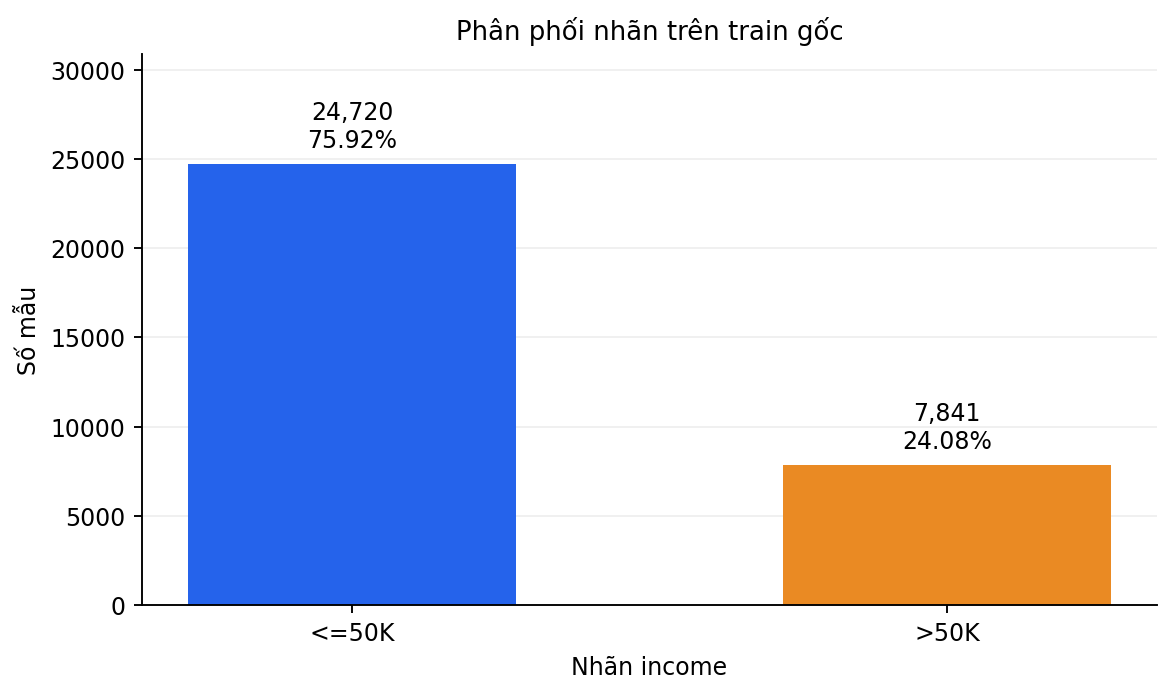

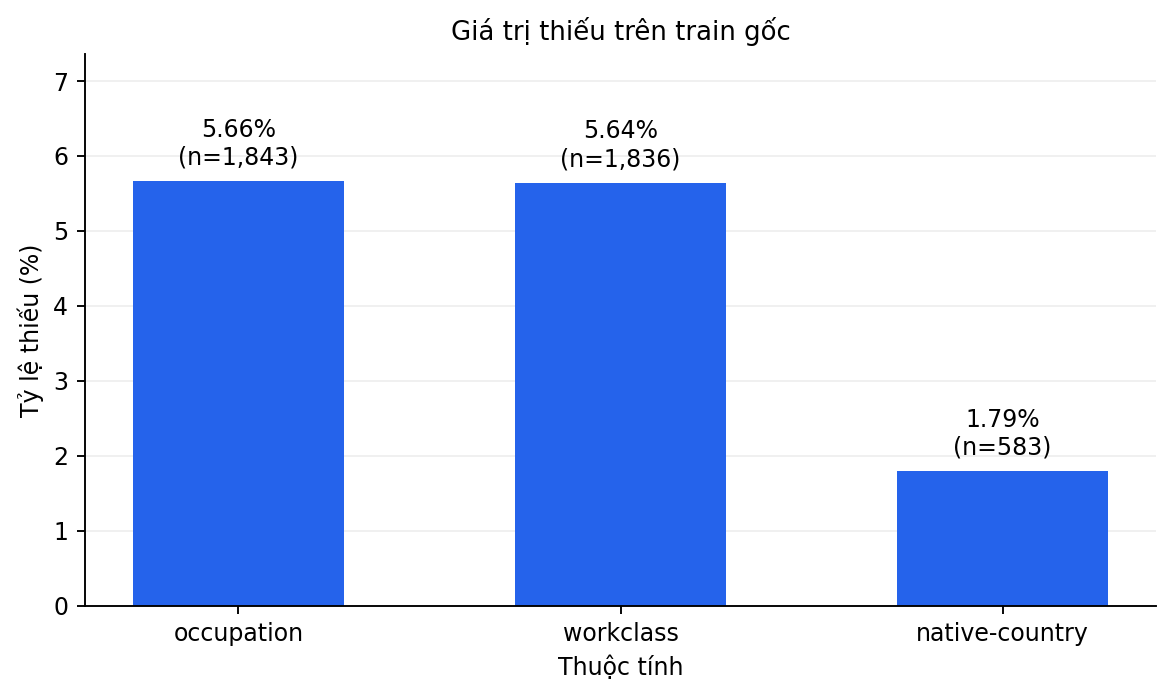

In [11]:
# 11. Biểu đồ nhãn và missing.
for name in ["label_distribution", "missing_values"]:
    display(Image(filename=str(EDA_DIR / "figures" / f"{name}.png")))


### Trùng lặp, khác nhãn và miền giá trị
- **Dòng dư:** số bản ghi lặp ngoài lần xuất hiện đầu tiên.
- **Dòng tham gia:** tất cả bản ghi thuộc những nhóm bị trùng.
- Đối chiếu trùng toàn bộ 15 cột và trùng 14 đầu vào là hai phép kiểm tra khác nhau.
- Nhóm cùng đầu vào nhưng khác nhãn được ghi nhận; chưa tự xóa hay sửa nhãn.

Quy tắc miền số và miền phân loại được ghi rõ trong `domain_checks.csv`. Không có lỗi theo các quy tắc này không có nghĩa dữ liệu chắc chắn hoàn toàn đúng.


In [12]:
# 12. Trùng lặp và kiểm tra miền giá trị.
display(pd.read_csv(EDA_DIR / "tables/duplicate_summary.csv"))
print("Nhóm cùng đầu vào nhưng khác nhãn:", eda_summary["conflicting_label_groups"])
print("Số dòng trong các nhóm này:", eda_summary["conflicting_label_rows"])
print("Chi tiết nhóm được lưu trong conflicting_label_groups.csv")
display(pd.read_csv(EDA_DIR / "tables/domain_checks.csv"))


Nhóm cùng đầu vào nhưng khác nhãn: 1
Số dòng trong các nhóm này: 2
Chi tiết nhóm được lưu trong conflicting_label_groups.csv


,definition,extra_rows,involved_rows,groups
0,all_15_columns,24,47,23
1,14_features_only,25,49,24


,column,rule,invalid_count,missing_count
0,age,> 16,0,0
1,fnlwgt,> 1,0,0
2,education-num,1 to 16,0,0
3,capital-gain,>= 0,0,0
4,capital-loss,>= 0,0,0
5,hours-per-week,> 0 and <= 168,0,0
6,workclass,listed in adult.names,0,1836
7,education,listed in adult.names,0,0
8,marital-status,listed in adult.names,0,0
9,occupation,listed in adult.names,0,1843


### Thuộc tính số và các cờ IQR
Thống kê sáu biến số trên thang đo gốc. Quy tắc IQR đánh dấu điểm ngoài `[Q1 − 1.5×IQR, Q3 + 1.5×IQR]` để mô tả, không dùng để tự loại dòng.

Đặc biệt, nếu Q1 và Q3 đều bằng 0 thì IQR bằng 0; mọi giá trị dương sẽ bị gắn cờ. Với các biến khoản vốn, đây có thể là giá trị hợp lệ.


In [13]:
# 13. Bảng thống kê số và cờ IQR.
display(pd.read_csv(EDA_DIR / "tables/numeric_summary.csv").round(2))
display(pd.read_csv(EDA_DIR / "tables/iqr_flags.csv").round(2))


,column,count,mean,std,min,25%,50%,75%,max,zero_count,zero_percent,skewness
0,age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0,0,0.00,0.56
1,fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0,0,0.00,1.45
2,education-num,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,0,0.00,-0.31
3,capital-gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0,29849,91.67,11.95
4,capital-loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0,31042,95.33,4.59
5,hours-per-week,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0,0,0.00,0.23


,column,q1,q3,iqr,lower,upper,flagged_count,flagged_percent
0,age,28.0,48.0,20.0,-2.0,78.0,143,0.44
1,fnlwgt,117827.0,237051.0,119224.0,-61009.0,415887.0,992,3.05
2,education-num,9.0,12.0,3.0,4.5,16.5,1198,3.68
3,capital-gain,0.0,0.0,0.0,0.0,0.0,2712,8.33
4,capital-loss,0.0,0.0,0.0,0.0,0.0,1519,4.67
5,hours-per-week,40.0,45.0,5.0,32.5,52.5,9008,27.66


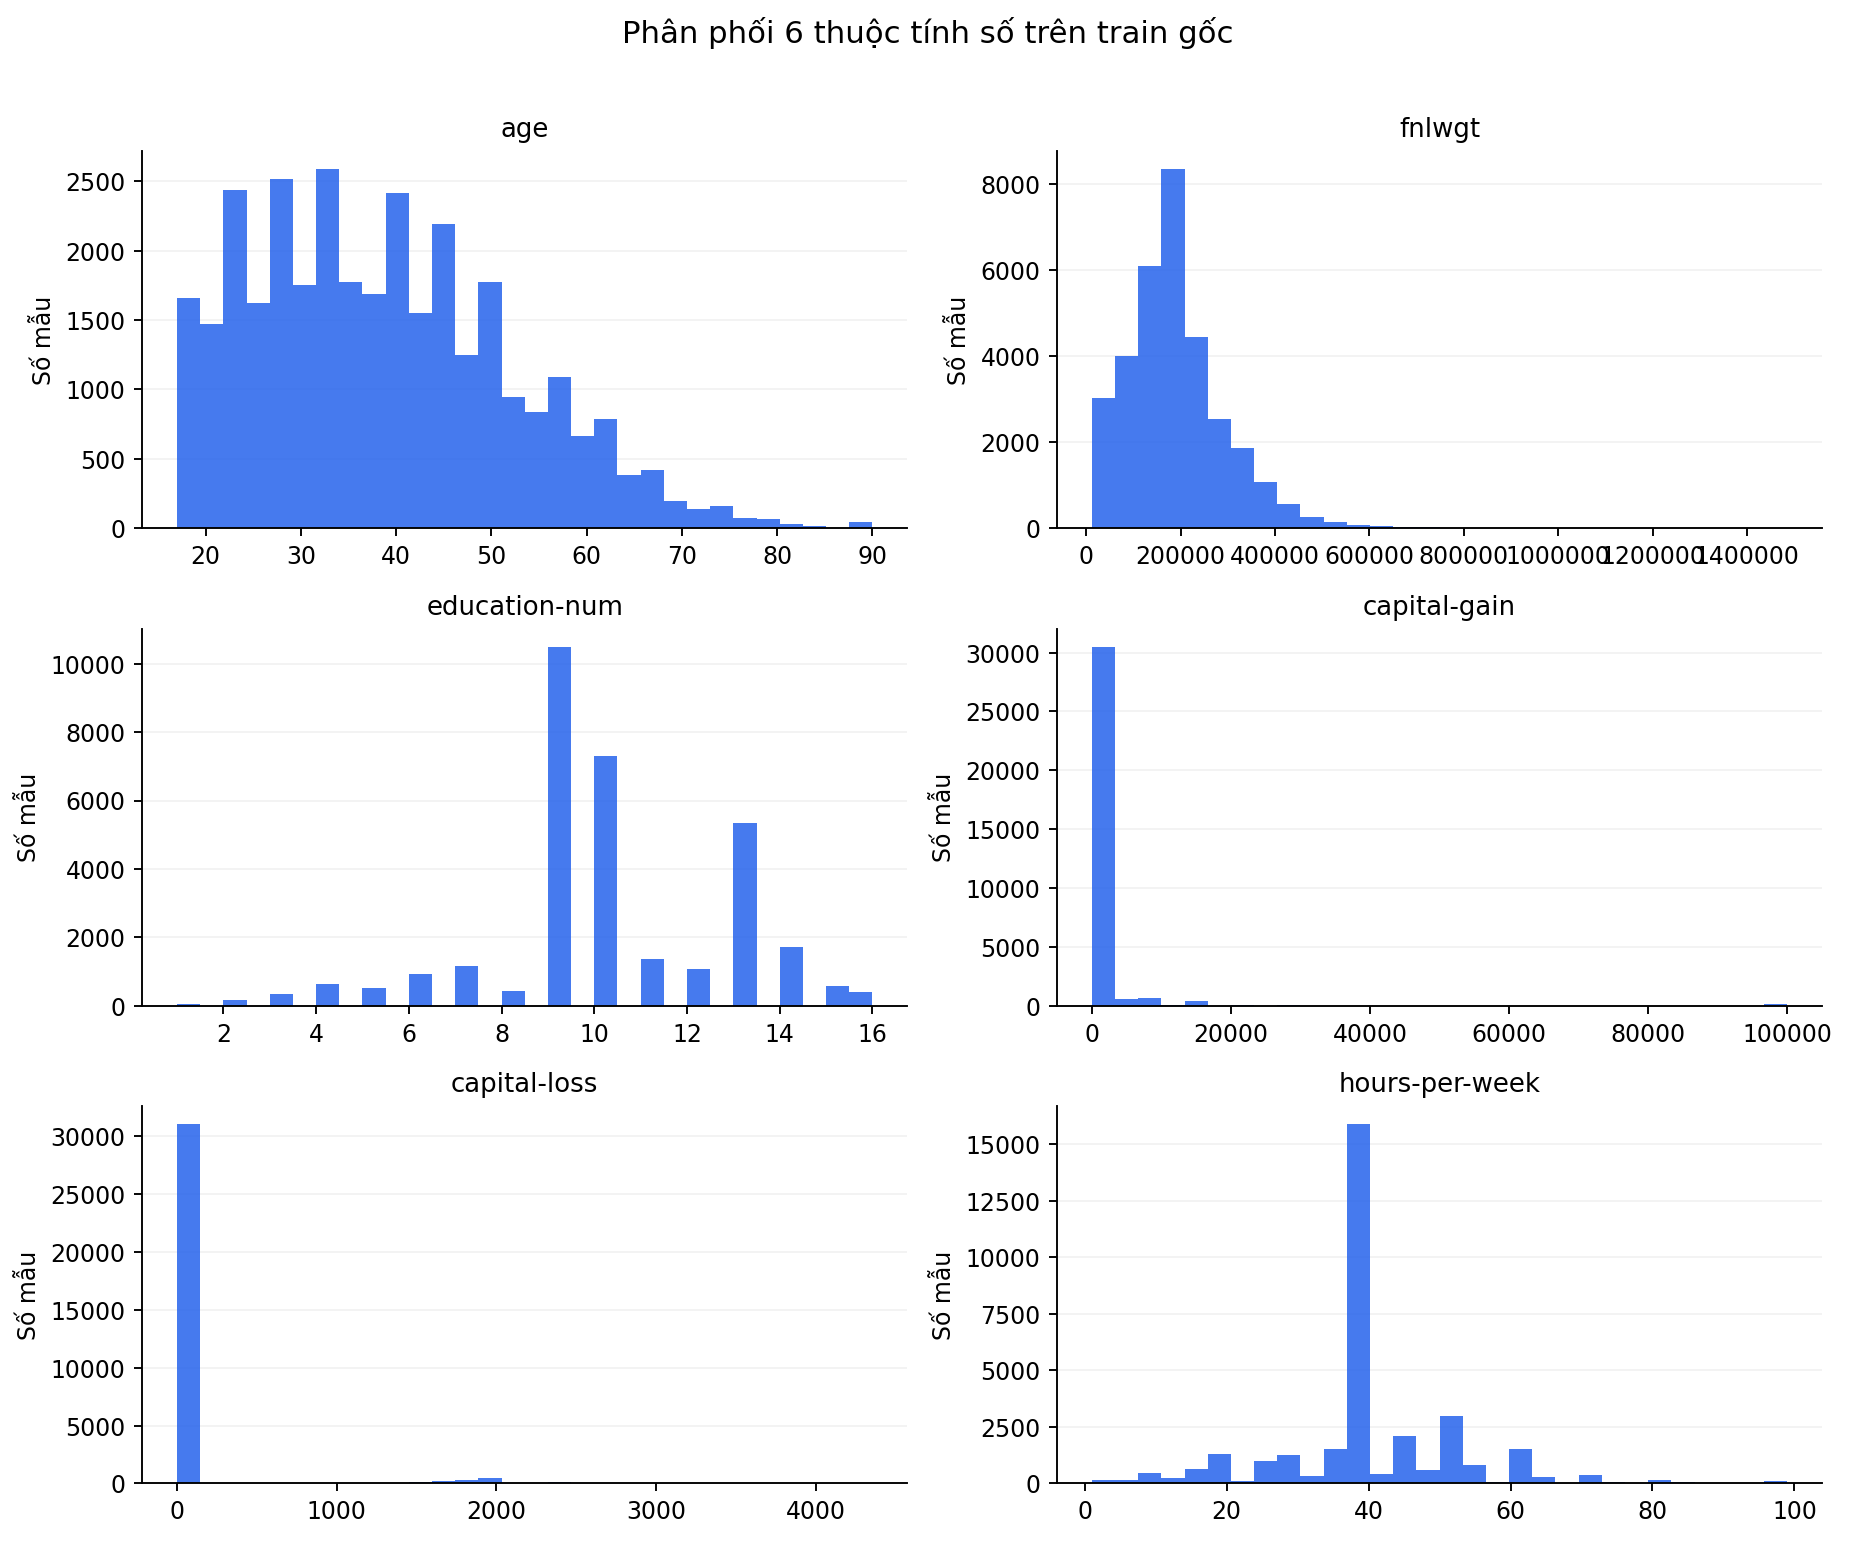

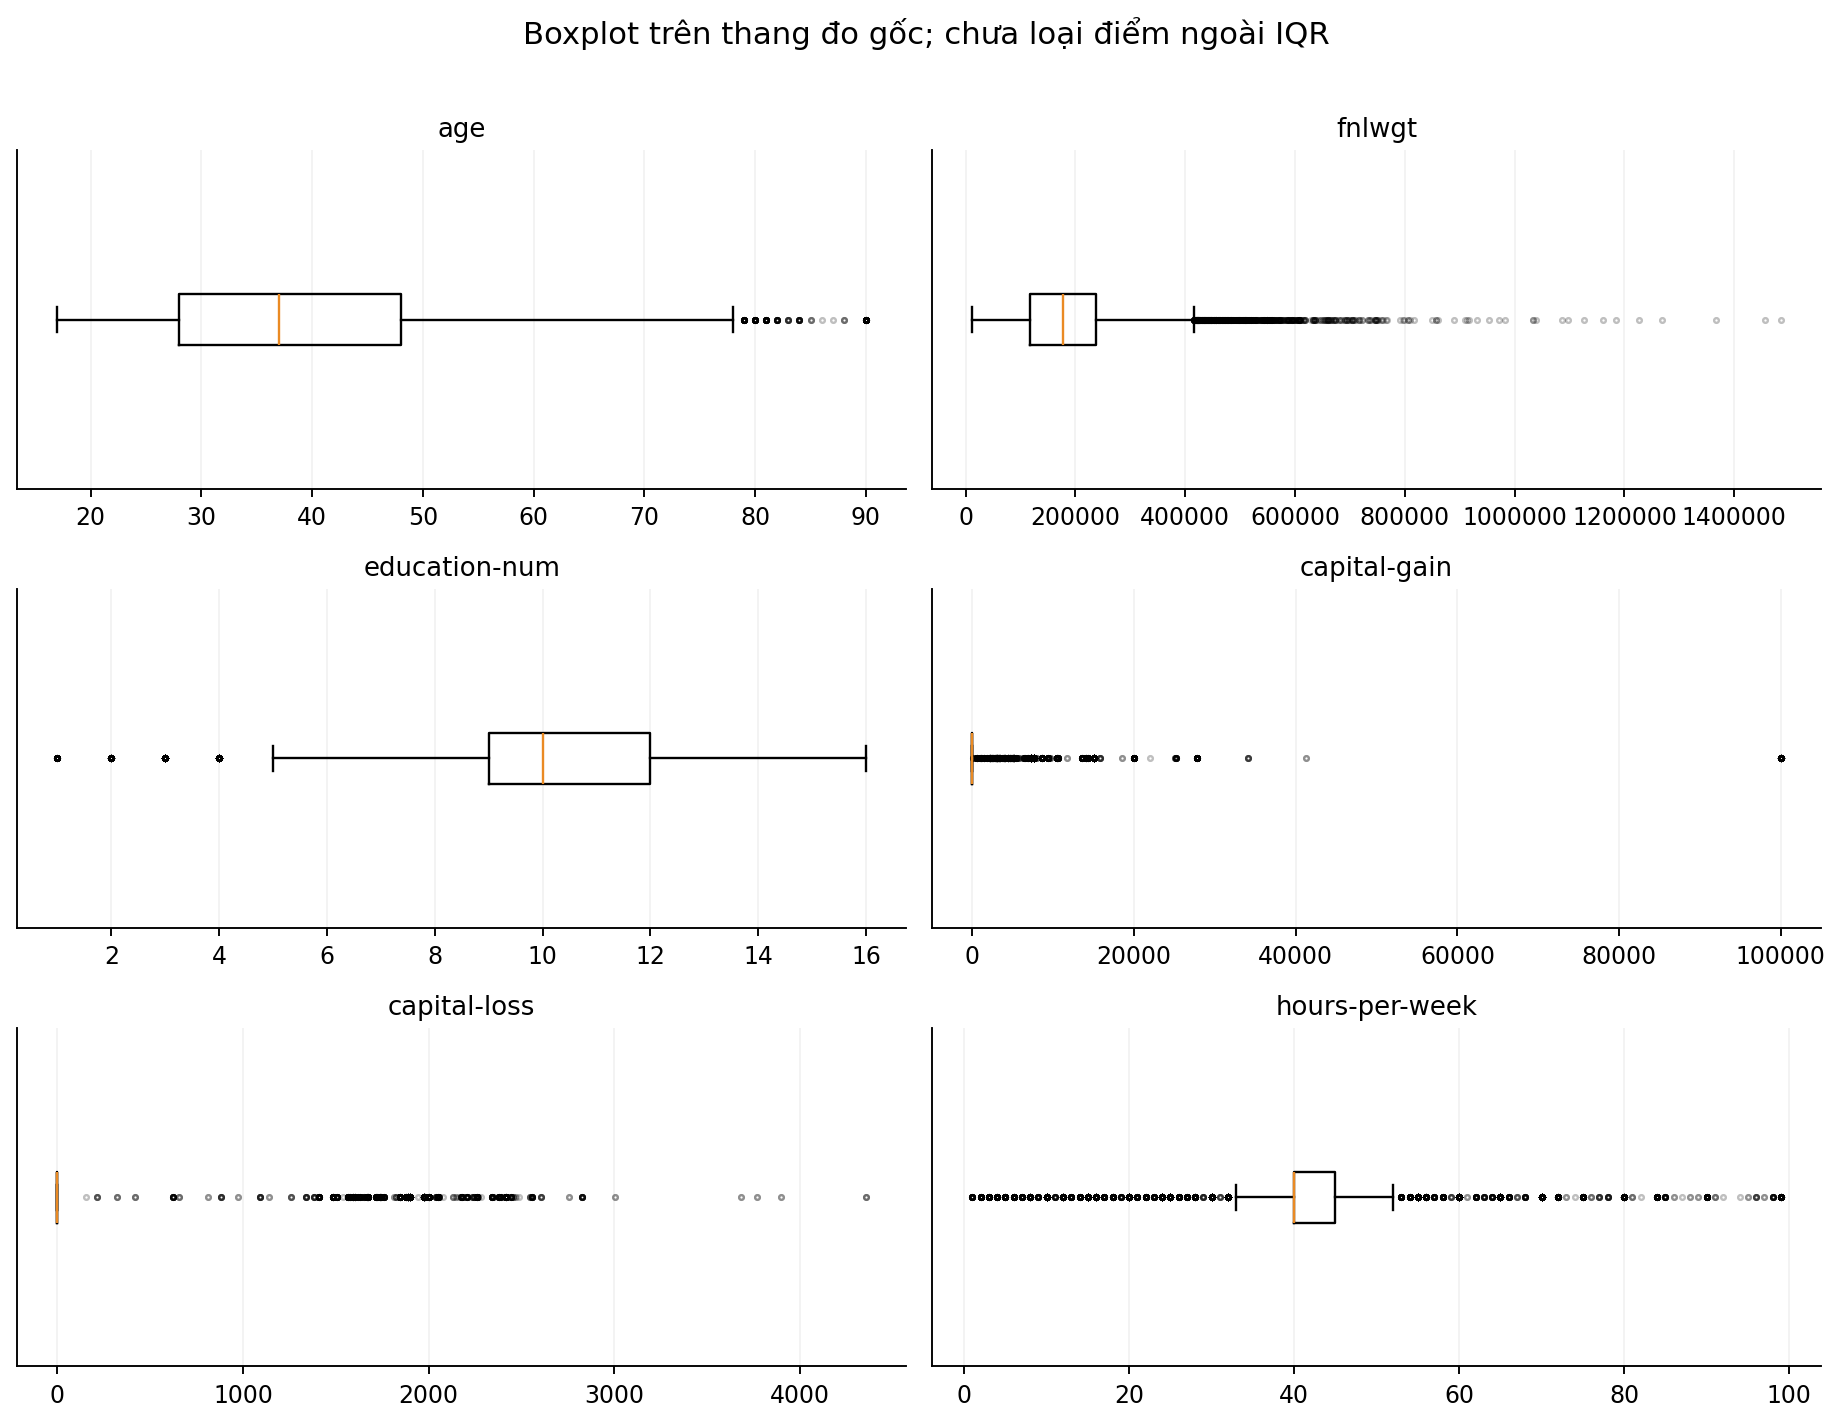

In [14]:
# 14. Histogram và boxplot riêng cho từng biến số.
for name in ["numeric_histograms", "numeric_boxplots"]:
    display(Image(filename=str(EDA_DIR / "figures" / f"{name}.png")))


### Thuộc tính phân loại
Các bảng CSV giữ đủ mọi mức, kể cả mức thiếu. Biểu đồ có thể gộp các mức ít phổ biến để dễ đọc; việc gộp chỉ dùng cho biểu đồ, không thay đổi DataFrame.

Biểu đồ tỷ lệ `>50K` theo học vấn có ghi số mẫu của từng nhóm. Các tỷ lệ là mối liên hệ quan sát, không phải quan hệ nhân quả hay đánh giá mô hình.


In [15]:
# 15. Tóm tắt tám biến phân loại.
category_overview = []
for column in data_loader.CATEGORICAL_COLUMNS:
    table = pd.read_csv(EDA_DIR / "tables" / f"categorical_{column}.csv")
    category_overview.append({
        "Thuộc tính": column,
        "Số mức kể cả thiếu": len(table),
        "Mức phổ biến nhất": table.iloc[0]["category"],
        "Tỷ lệ mức phổ biến (%)": round(float(table.iloc[0]["percent"]), 2),
    })
display(pd.DataFrame(category_overview))


,Thuộc tính,Số mức kể cả thiếu,Mức phổ biến nhất,Tỷ lệ mức phổ biến (%)
0,workclass,9,Private,69.70
1,education,16,HS-grad,32.25
2,marital-status,7,Married-civ-spouse,45.99
3,occupation,15,Prof-specialty,12.71
4,relationship,6,Husband,40.52
5,race,5,White,85.43
6,sex,2,Male,66.92
7,native-country,42,United-States,89.59


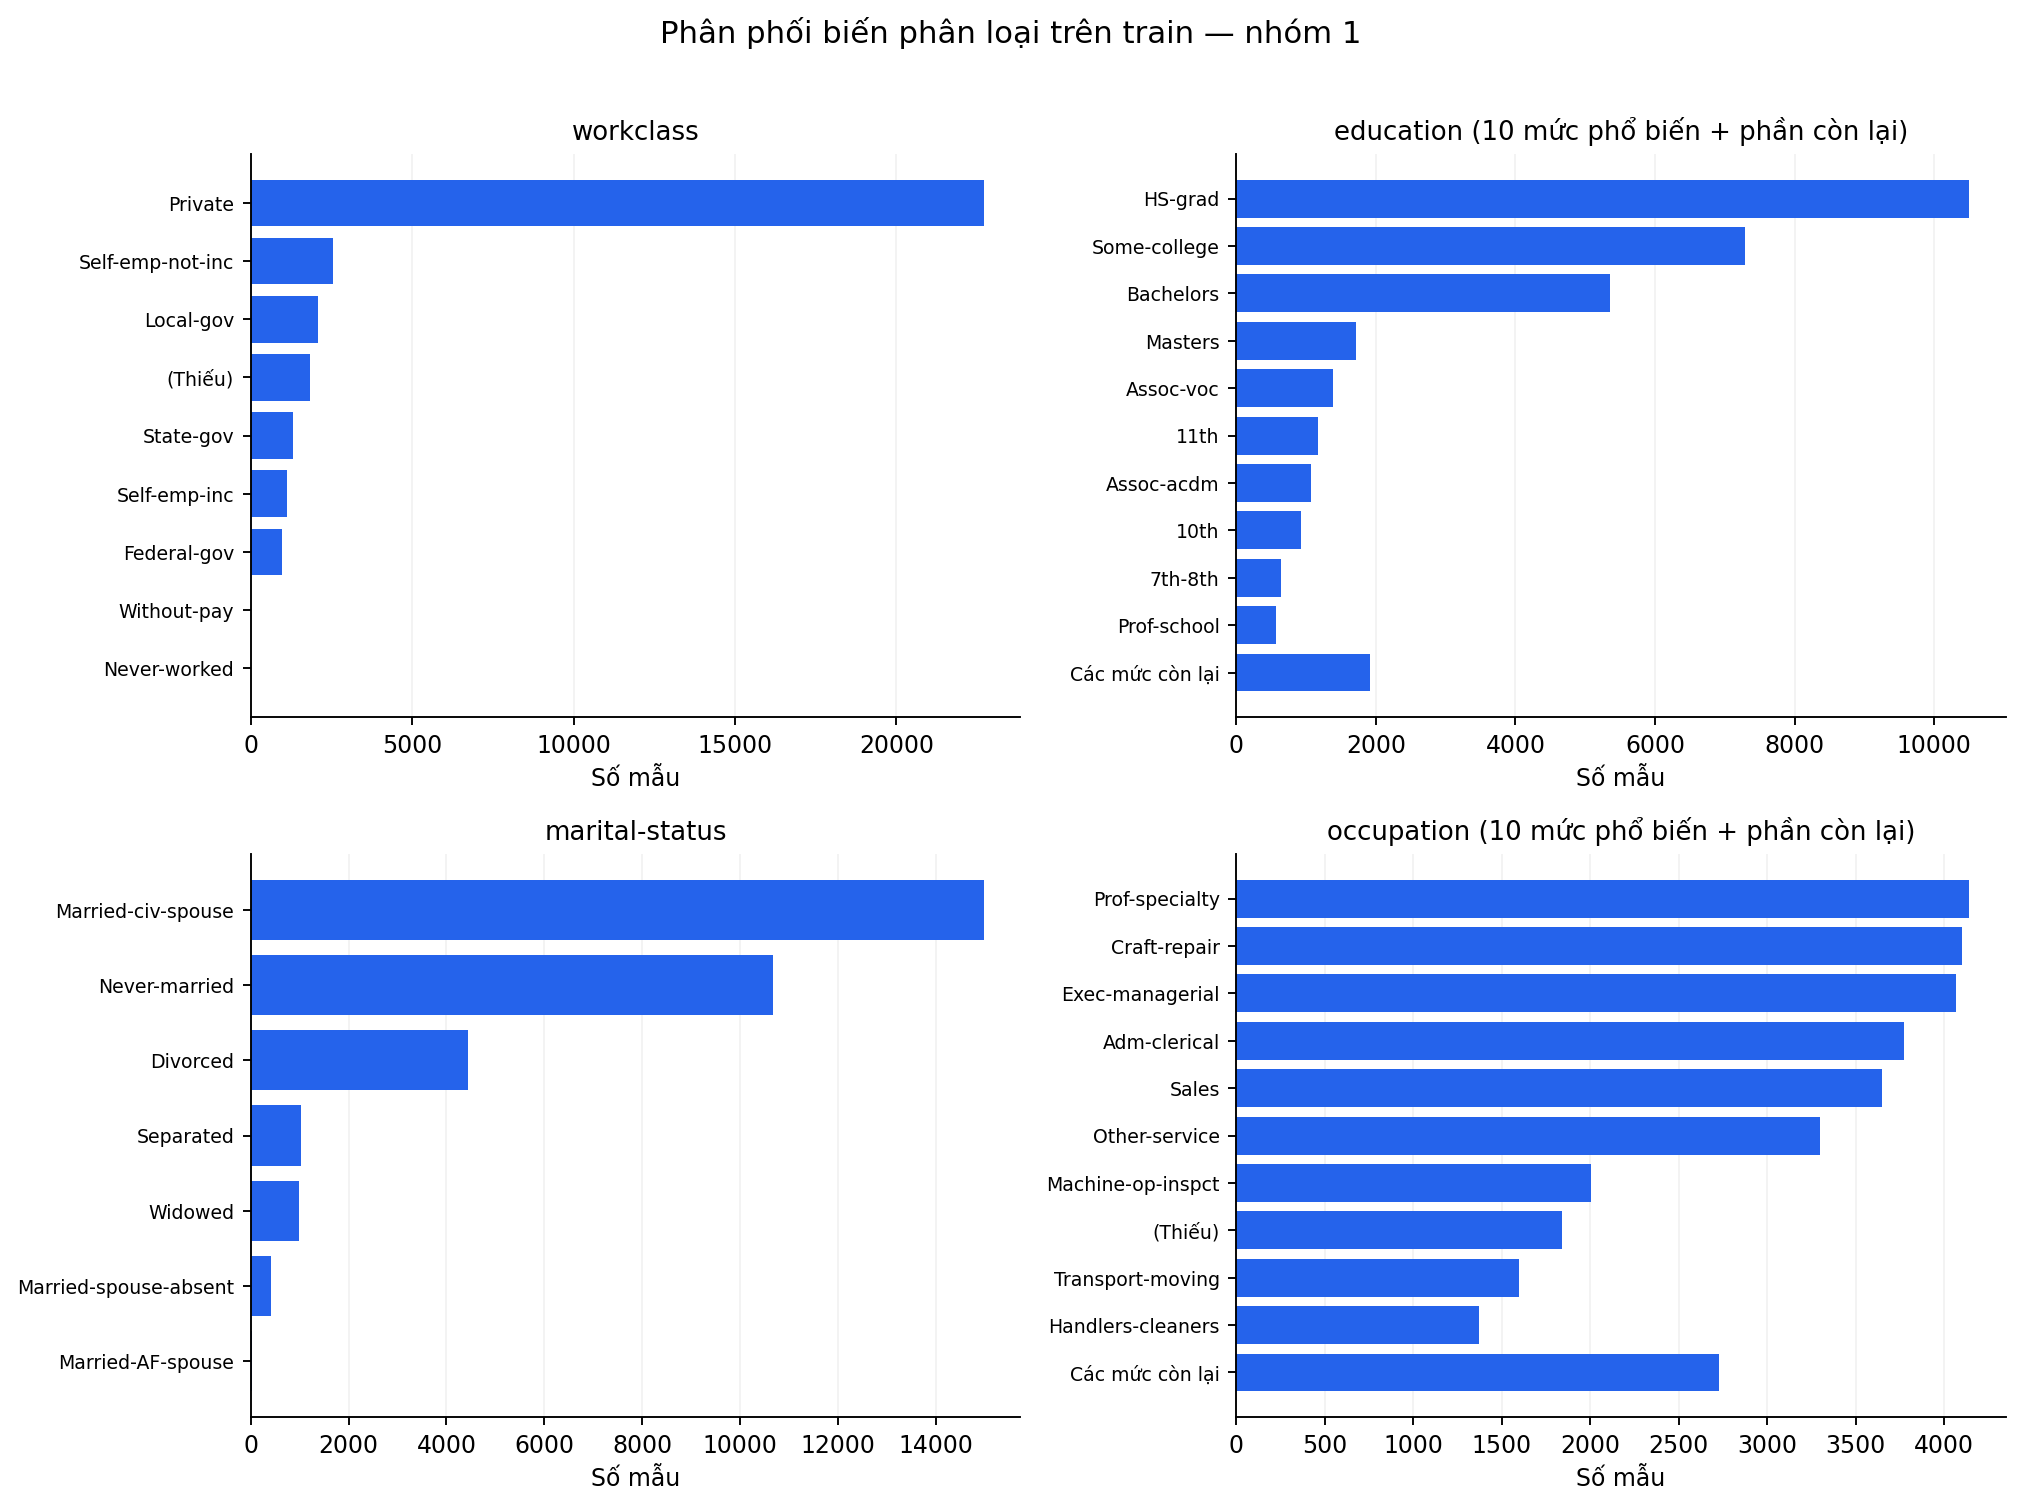

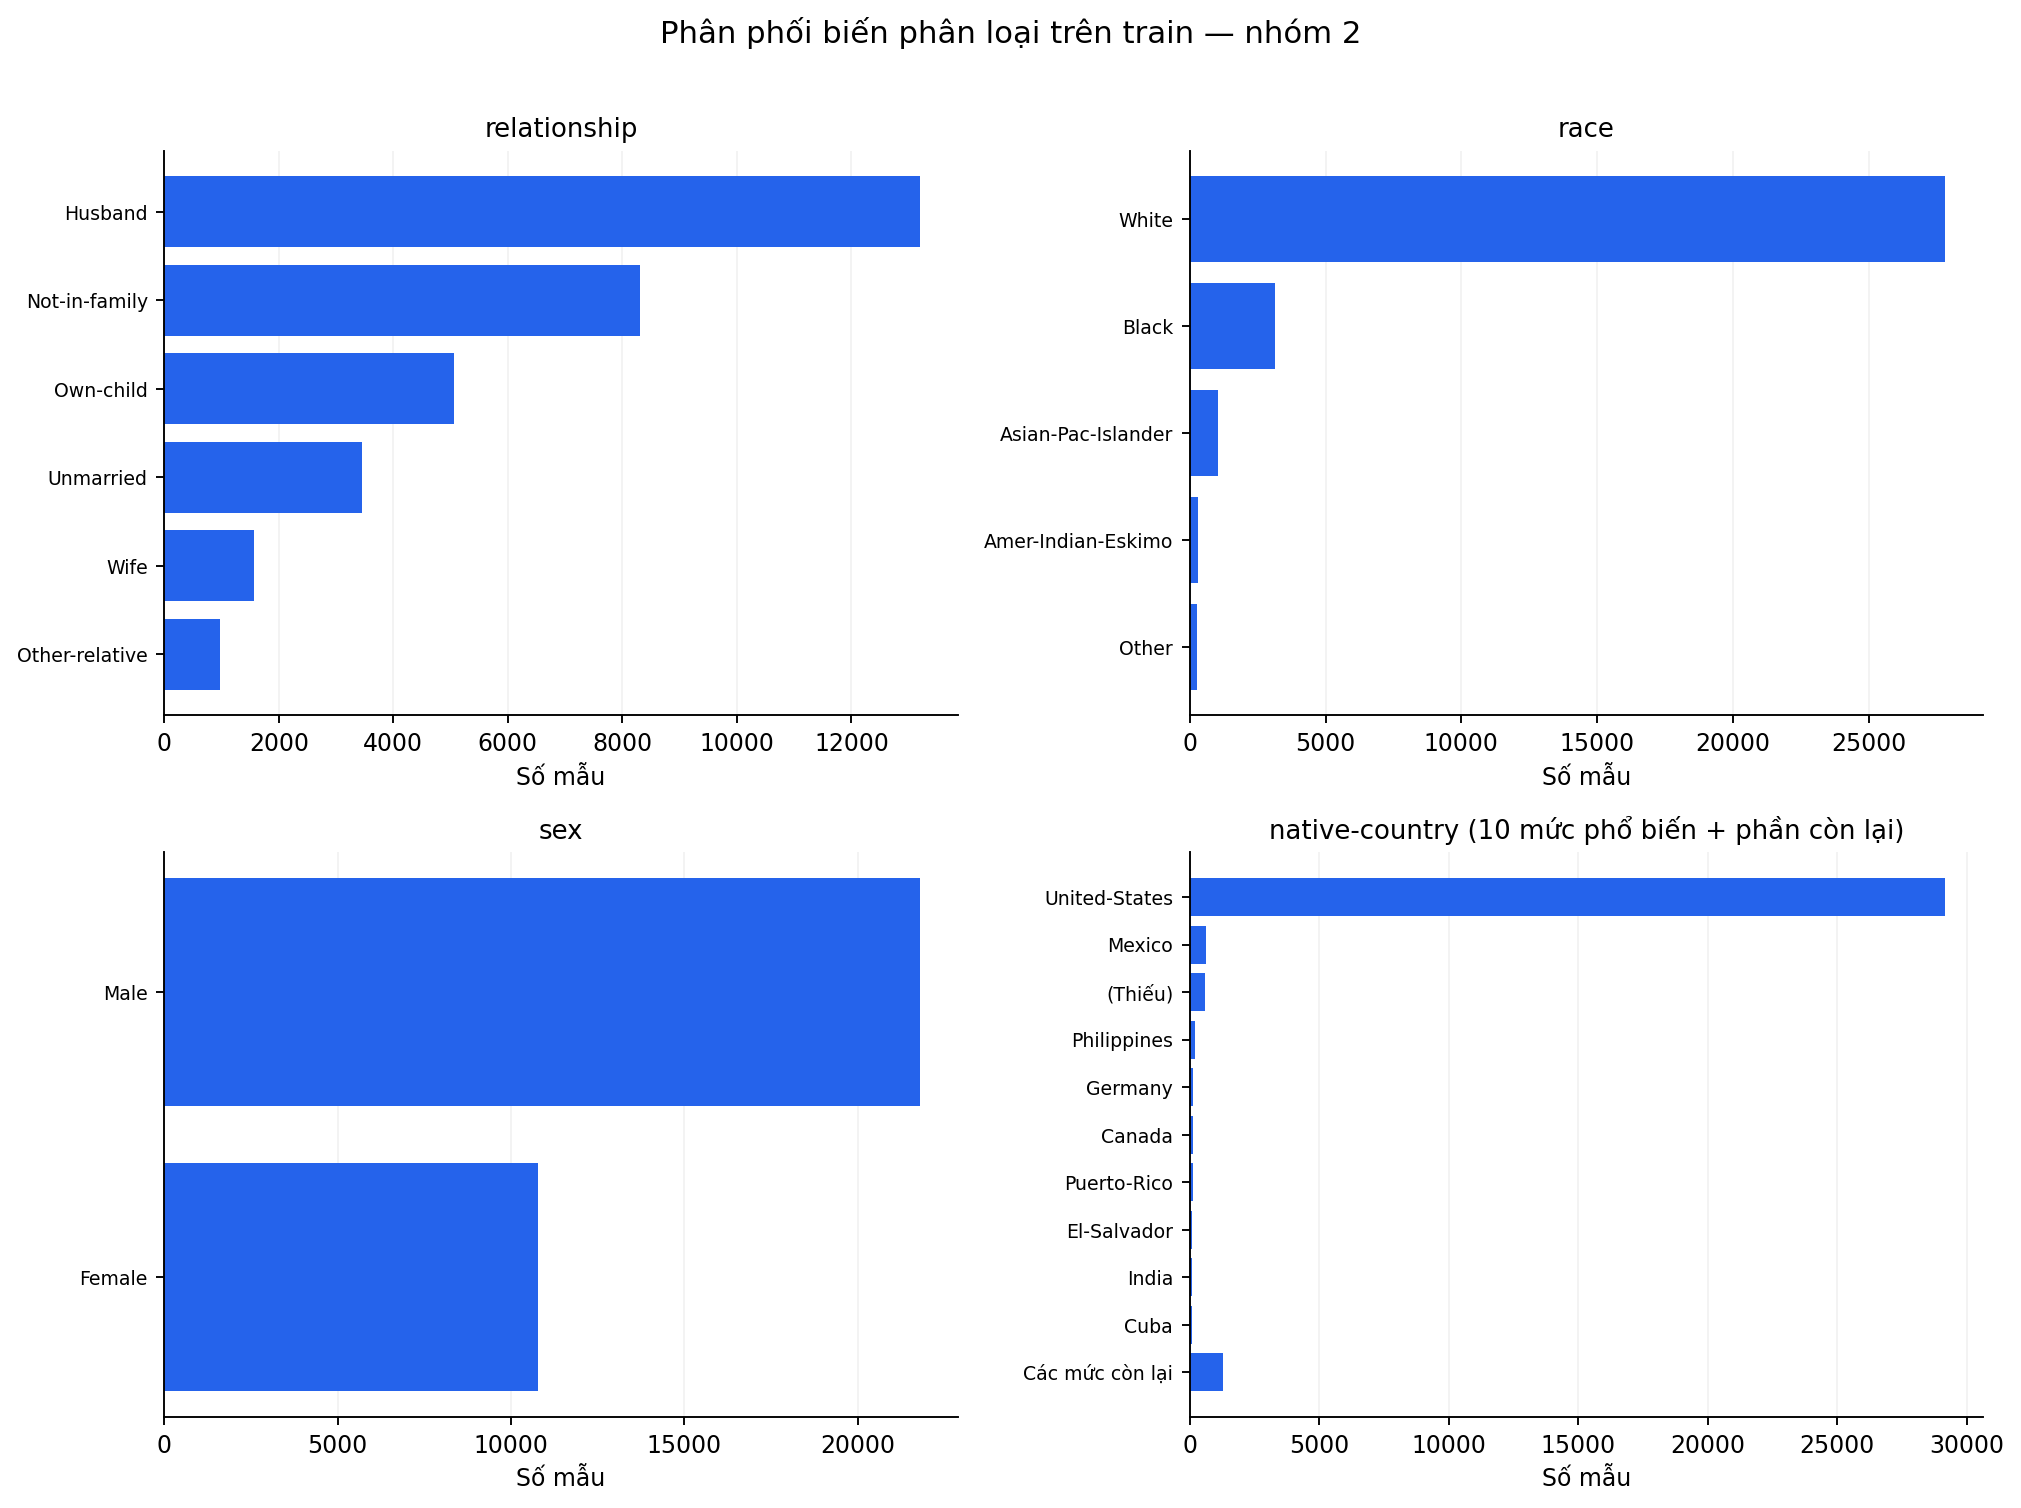

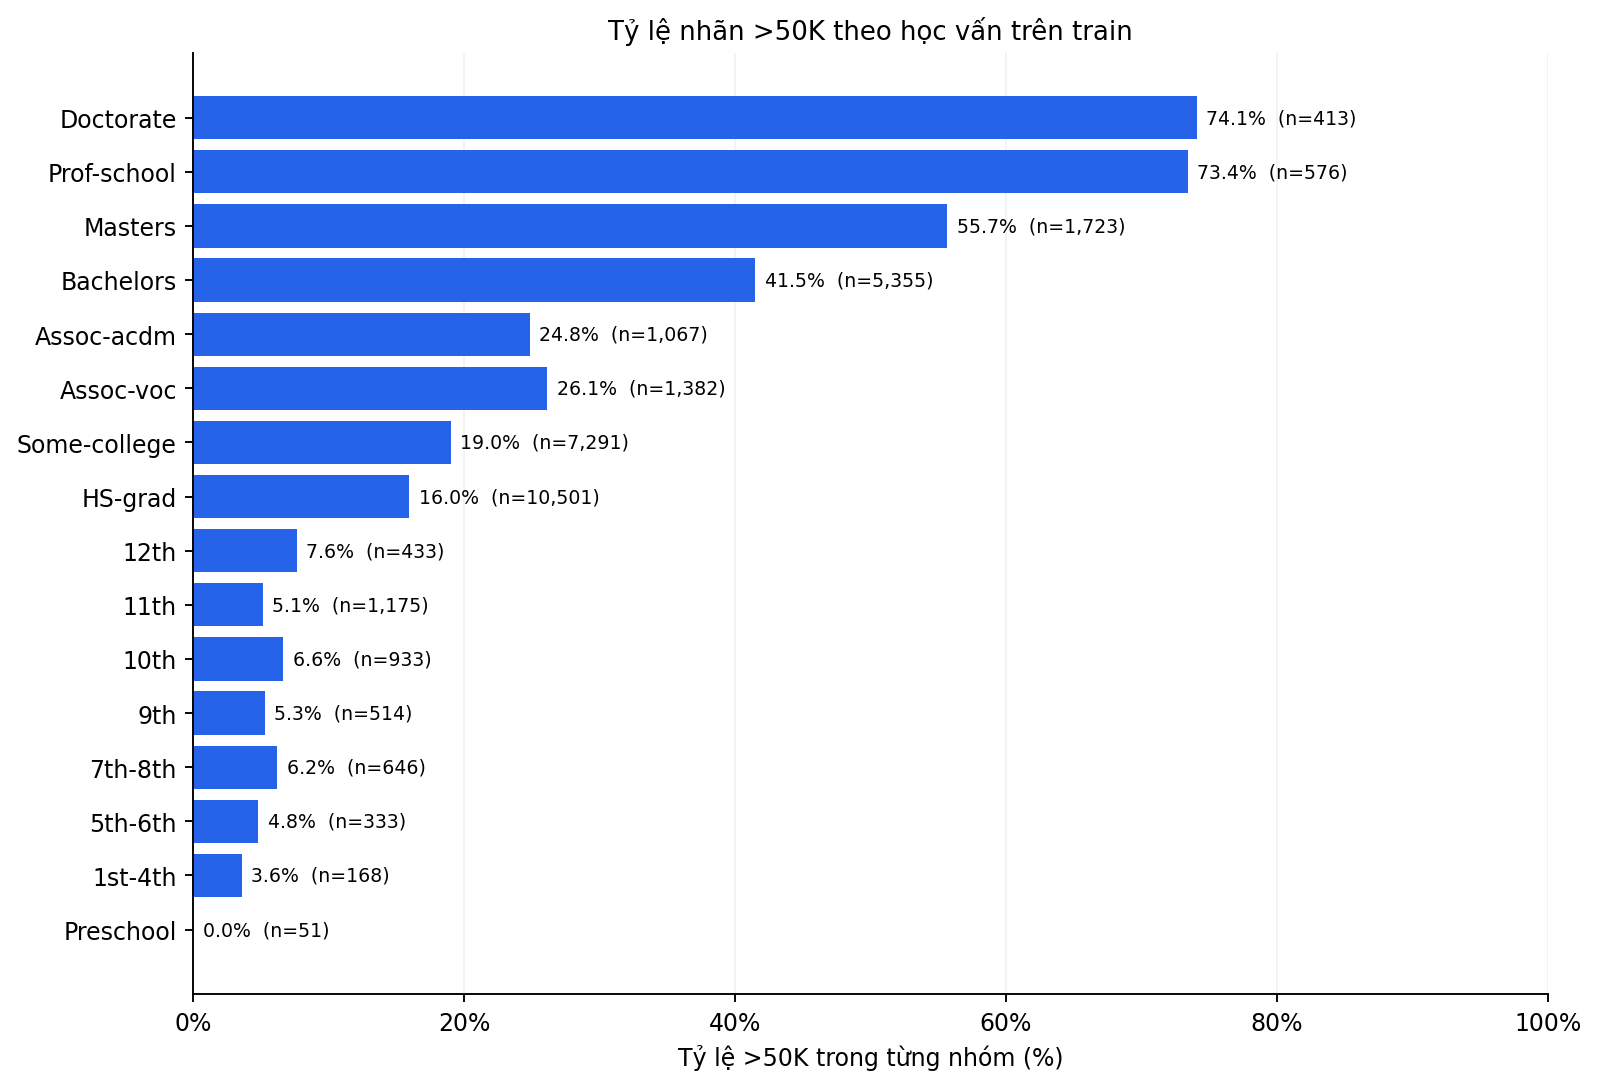

In [16]:
# 16. Phân phối các biến phân loại và liên hệ mô tả với học vấn.
for name in ["categorical_counts_1", "categorical_counts_2", "education_income_rate"]:
    display(Image(filename=str(EDA_DIR / "figures" / f"{name}.png")))


### Tổng hợp từ kết quả vừa chạy
Các con số bên dưới được sinh từ `eda_summary`, không nhập lại từ báo cáo cũ.


In [17]:
# 17. Nhận xét ngắn, tính từ lần chạy hiện tại.
s = eda_summary
observations = [
    f"- Phạm vi EDA: **{s['n_rows']:,} mẫu train gốc**.",
    f"- Lớp >50K: **{s['label_percent']['>50K']:.2f}%**; tỷ lệ số lượng hai lớp khoảng **{s['majority_to_minority_ratio']:.2f}:1**.",
    f"- Có **{s['rows_with_missing']:,} dòng** thiếu ít nhất một ô (**{s['rows_with_missing_percent']:.2f}%**).",
    f"- Có **{s['exact_duplicate_extra']} dòng dư** khi xét trùng cả 15 cột.",
    f"- Có **{s['conflicting_label_groups']} nhóm** cùng đầu vào nhưng khác nhãn.",
    "- Các cờ IQR chỉ dùng để khảo sát; chưa loại ngoại lai.",
    "- Chưa xóa dòng, điền thiếu, chia lại dữ liệu hoặc huấn luyện mô hình.",
]
display(Markdown(chr(10).join(observations)))


- Phạm vi EDA: **32,561 mẫu train gốc**.
- Lớp >50K: **24.08%**; tỷ lệ số lượng hai lớp khoảng **3.15:1**.
- Có **2,399 dòng** thiếu ít nhất một ô (**7.37%**).
- Có **24 dòng dư** khi xét trùng cả 15 cột.
- Có **1 nhóm** cùng đầu vào nhưng khác nhãn.
- Các cờ IQR chỉ dùng để khảo sát; chưa loại ngoại lai.
- Chưa xóa dòng, điền thiếu, chia lại dữ liệu hoặc huấn luyện mô hình.

### Cập nhật và đóng gói LaTeX
Nội dung EDA và hình được sinh vào đúng các file mục 3.3–3.7. Chương 1 và các mục nguồn dữ liệu 3.1–3.2 được giữ từ bước 1. ZIP tạo ở ô sau có thể tải lên Overleaf; chọn `main.tex`, khuyến nghị XeLaTeX.


In [18]:
# 18. Cập nhật báo cáo và tạo ZIP riêng để tải lên Overleaf.
eda.update_latex(EDA_DIR, REPORT_ROOT)
LATEX_ZIP = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_2.zip"
with ZipFile(LATEX_ZIP, "w") as archive:
    for path in sorted(REPORT_ROOT.rglob("*")):
        if path.is_file():
            archive.write(path, path.relative_to(REPORT_ROOT).as_posix())
print("Đã cập nhật toàn bộ chương 3 và giữ nguyên chương 1.")
print("ZIP LaTeX:", LATEX_ZIP)


Đã cập nhật toàn bộ chương 3 và giữ nguyên chương 1.
ZIP LaTeX: C:\Users\Acer\Documents\Codex\2026-11-21\new-chat\BTL_ML_Final\reports\BTL_ML_LaTeX_Buoc_2.zip


# Bước 3 — Khóa cách chia train, validation và test

- `adult.data` là development, được chia xấp xỉ 80/20 theo nhóm.
- Nhóm gồm các dòng giống toàn bộ 14 thuộc tính đầu vào, bao gồm trạng thái thiếu; không dùng nhãn trong khóa nhóm.
- Chọn trước `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`, fold validation số 0. Không chọn seed hoặc fold theo điểm mô hình.
- `adult.test` giữ nguyên. Không tính phân phối nhãn test hoặc dùng test để lọc/chọn tập chia.

Lần tạo ban đầu được thực hiện với scikit-learn 1.9.0. Notebook nhúng các chỉ số đã khóa và đối chiếu dấu vân tay của development trước khi tái dùng, giúp giữ đúng những dòng đã chia ngay cả khi phiên bản thư viện ở Colab khác.


In [19]:
#@title 19. Chuẩn bị module chia dữ liệu
SPLITTING_SOURCE = '"""Chia Adult development theo nhóm; không fit đặc trưng hoặc dùng test để chọn split."""\nfrom pathlib import Path\nfrom collections import defaultdict\nimport hashlib\nimport json\nimport platform\n\nimport numpy as np\nimport pandas as pd\n\nfrom .data_loader import COLUMNS, NUMERIC_COLUMNS\n\nDEFAULT_CONFIG = {\n    \'n_splits\':5,\n    \'validation_fold\':0,\n    \'random_state\':42,\n    \'group_columns\':COLUMNS[:-1],\n}\nLABELS=[\'<=50K\',\'>50K\']\n\n\ndef _canonical_rows(frame, columns):\n    positions=[frame.columns.get_loc(c) for c in columns]\n    numeric=set(NUMERIC_COLUMNS)\n    for row in frame.itertuples(index=False,name=None):\n        values=[]\n        for column,position in zip(columns,positions):\n            value=row[position]\n            if pd.isna(value):\n                values.append(None)\n            elif column in numeric:\n                # Không cắt phần lẻ nếu dữ liệu bị thay đổi sau bước đọc.\n                numeric_value=float(value)\n                values.append(int(value) if numeric_value.is_integer() else numeric_value)\n            else:\n                values.append(str(value))\n        yield json.dumps(values,ensure_ascii=False,separators=(\',\',\':\'),allow_nan=False)\n\n\ndef frame_fingerprint(frame):\n    """Dấu vân tay có xét thứ tự dòng và tất cả cột của bảng development."""\n    digest=hashlib.sha256()\n    digest.update(json.dumps(COLUMNS).encode(\'utf-8\'))\n    for value in _canonical_rows(frame,COLUMNS):\n        digest.update(value.encode(\'utf-8\'));digest.update(b\'\\n\')\n    return digest.hexdigest()\n\n\ndef make_group_ids(frame, group_columns=None):\n    columns=list(COLUMNS[:-1] if group_columns is None else group_columns)\n    if not columns or len(columns)!=len(set(columns)) or not set(columns).issubset(COLUMNS[:-1]):\n        raise ValueError(\'Nhóm phải dùng các thuộc tính đầu vào riêng biệt, không dùng income.\')\n    canonical=list(_canonical_rows(frame,columns))\n    groups=np.array([hashlib.sha256(value.encode(\'utf-8\')).hexdigest() for value in canonical])\n    if len(set(groups))!=len(set(canonical)):\n        raise ValueError(\'Phát hiện va chạm mã nhóm; cần đối chiếu lại khóa canonical.\')\n    return groups\n\n\ndef _normalize_config(config=None):\n    result={**DEFAULT_CONFIG,**(config or {})}\n    result[\'group_columns\']=list(result[\'group_columns\'])\n    for key in [\'n_splits\',\'validation_fold\',\'random_state\']:\n        if isinstance(result[key],bool) or not isinstance(result[key],int):\n            raise ValueError(f\'{key} phải là số nguyên.\')\n    if result[\'n_splits\']<2 or not 0<=result[\'validation_fold\']<result[\'n_splits\']:\n        raise ValueError(\'Số fold hoặc chỉ số fold validation không hợp lệ.\')\n    return result\n\n\ndef validate_indices(frame, train_indices, validation_indices, groups):\n    """Kiểm tra đầy đủ dòng, chỉ số, nhãn và không chung nhóm train/validation."""\n    lists=[list(train_indices),list(validation_indices)]\n    if any(any(isinstance(i,bool) or not isinstance(i,(int,np.integer)) for i in arr) for arr in lists):\n        raise ValueError(\'Chỉ số phải là số nguyên.\')\n    train_indices,validation_indices=[np.array(a,dtype=np.int64) for a in lists]\n    if any(len(a)==0 or len(np.unique(a))!=len(a) for a in [train_indices,validation_indices]):\n        raise ValueError(\'Có tập rỗng hoặc chỉ số lặp trong một tập.\')\n    combined=np.concatenate([train_indices,validation_indices])\n    if not np.array_equal(np.sort(combined),np.arange(len(frame))):\n        raise ValueError(\'Hai tập phải chia đủ mỗi dòng development đúng một lần.\')\n    overlap=set(groups[train_indices])&set(groups[validation_indices])\n    if overlap:\n        raise ValueError(\'Có nhóm đầu vào đồng thời nằm trong train và validation.\')\n    for name,idx in [(\'train\',train_indices),(\'validation\',validation_indices)]:\n        if set(frame.iloc[idx][\'income\'].unique())!=set(LABELS):\n            raise ValueError(f\'{name} không có đủ hai nhãn.\')\n    return np.sort(train_indices),np.sort(validation_indices)\n\n\ndef load_or_create_split(development, manifest_path, config=None):\n    """Tạo một fold cố định, hoặc tái dùng đúng chỉ số đã khóa trong manifest."""\n    if list(development.columns)!=COLUMNS or development[\'income\'].isna().any():\n        raise ValueError(\'Development không có đúng cột hoặc thiếu nhãn.\')\n    if set(development[\'income\'].unique())!=set(LABELS):\n        raise ValueError(\'Development phải có đúng hai nhãn Adult.\')\n    config=_normalize_config(config)\n    groups=make_group_ids(development,config[\'group_columns\'])\n    fingerprint=frame_fingerprint(development)\n    manifest_path=Path(manifest_path)\n    if manifest_path.is_file():\n        manifest=json.loads(manifest_path.read_text(encoding=\'utf-8\'))\n        if manifest.get(\'development_fingerprint\')!=fingerprint:\n            raise ValueError(\'Manifest không khớp dữ liệu hoặc thứ tự dòng development.\')\n        if manifest.get(\'config\')!=config:\n            raise ValueError(\'Manifest không khớp cấu hình. Muốn đổi cấu hình cần tạo manifest mới có chủ đích.\')\n        train_idx,val_idx=validate_indices(development,manifest[\'train_indices\'],manifest[\'validation_indices\'],groups)\n        return train_idx,val_idx,groups,manifest,\'frozen_manifest\'\n\n    from sklearn.model_selection import StratifiedGroupKFold\n    import sklearn\n    splitter=StratifiedGroupKFold(\n        n_splits=config[\'n_splits\'],shuffle=True,random_state=config[\'random_state\']\n    )\n    # Cố định fold trước; không thử nhiều seed hoặc chọn fold theo điểm mô hình.\n    split=None\n    for fold,(tr,va) in enumerate(splitter.split(\n        np.zeros((len(development),1)),development[\'income\'].to_numpy(dtype=str),groups\n    )):\n        if fold==config[\'validation_fold\']:\n            split=(tr,va);break\n    train_idx,val_idx=validate_indices(development,*split,groups)\n    manifest={\n        \'schema_version\':1,\'method\':\'StratifiedGroupKFold\',\n        \'development_fingerprint\':fingerprint,\'development_rows\':len(development),\n        \'config\':config,\'sklearn_version_generation\':sklearn.__version__,\n        \'train_indices\':train_idx.tolist(),\'validation_indices\':val_idx.tolist(),\n        \'index_convention\':\'0-based data rows in adult.data, after parsing, excluding blank lines\',\n    }\n    manifest_path.parent.mkdir(parents=True,exist_ok=True)\n    manifest_path.write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    return train_idx,val_idx,groups,manifest,\'new_split\'\n\n\ndef export_splits(development, original_test, train_idx, validation_idx, groups,\n                  manifest, project_dir=\'.\', split_source=\'frozen_manifest\'):\n    """Xuất bảng chia, nguồn dòng và biên bản; test giữ nguyên không lập thống kê nhãn."""\n    train_idx,validation_idx=validate_indices(development,train_idx,validation_idx,groups)\n    if list(original_test.columns)!=COLUMNS:\n        raise ValueError(\'Test phải giữ nguyên cấu trúc Adult gốc.\')\n    root=Path(project_dir); data_dir=root/\'data/splits\'; result=root/\'results/step_03\'\n    data_dir.mkdir(parents=True,exist_ok=True);result.mkdir(parents=True,exist_ok=True)\n    frames={\n        \'train\':development.iloc[train_idx].copy().reset_index(drop=True),\n        \'validation\':development.iloc[validation_idx].copy().reset_index(drop=True),\n        \'test\':original_test.copy(deep=True).reset_index(drop=True),\n    }\n    metadata={}\n    for name,idx in [(\'train\',train_idx),(\'validation\',validation_idx)]:\n        metadata[name]=pd.DataFrame({\n            \'source_file\':[\'adult.data\']*len(idx),\'source_row\':idx,\n            \'source_id\':[f\'adult.data:{i}\' for i in idx],\n            \'group_id\':groups[idx],\n        })\n    metadata[\'test\']=pd.DataFrame({\n        \'source_file\':[\'adult.test\']*len(original_test),\n        \'source_row\':np.arange(len(original_test),dtype=np.int64),\n        \'source_id\':[f\'adult.test:{i}\' for i in range(len(original_test))],\n        \'group_id\':pd.Series([pd.NA]*len(original_test),dtype=\'string\'),\n    })\n    for name,frame in frames.items():\n        frame.to_csv(data_dir/f\'{name}.csv\',index=False,encoding=\'utf-8\')\n        metadata[name].to_csv(data_dir/f\'{name}_metadata.csv\',index=False,encoding=\'utf-8\')\n    assignments=pd.concat([m.assign(split=name) for name,m in metadata.items()],ignore_index=True)\n    assignments.to_csv(result/\'split_assignments.csv\',index=False,encoding=\'utf-8\')\n\n    class_rows=[];summary_rows=[]\n    for name in [\'train\',\'validation\']:\n        frame=frames[name]\n        counts=frame[\'income\'].value_counts().reindex(LABELS,fill_value=0)\n        for label in LABELS:\n            class_rows.append({\'split\':name,\'income\':label,\'count\':int(counts[label]),\n                \'percent\':float(counts[label]/len(frame)*100)})\n        summary_rows.append({\'split\':name,\'source_file\':\'adult.data\',\'rows\':len(frame),\n            \'share_of_development_percent\':len(frame)/len(development)*100,\n            \'unique_groups\':metadata[name][\'group_id\'].nunique(),\n            \'positive_count\':int(counts[\'>50K\']),\n            \'positive_percent\':float(counts[\'>50K\']/len(frame)*100)})\n    summary_rows.append({\'split\':\'test\',\'source_file\':\'adult.test\',\'rows\':len(original_test),\n        \'share_of_development_percent\':None,\'unique_groups\':None,\'positive_count\':None,\'positive_percent\':None})\n    summary_table=pd.DataFrame(summary_rows)\n    summary_table.to_csv(result/\'split_summary.csv\',index=False,encoding=\'utf-8\')\n    balance=pd.DataFrame(class_rows)\n    balance.to_csv(result/\'train_validation_class_balance.csv\',index=False,encoding=\'utf-8\')\n\n    labels_by_group=defaultdict(set)\n    for key,label in zip(groups,development[\'income\']):labels_by_group[key].add(str(label))\n    conflicting={key for key,labels in labels_by_group.items() if len(labels)>1}\n    membership={key:\'train\' for key in groups[train_idx]}\n    membership.update({key:\'validation\' for key in groups[validation_idx]})\n    conflicts=pd.DataFrame([\n        {\'group_id\':key,\'split\':membership[key],\'rows\':int((groups==key).sum()),\'n_labels\':len(labels_by_group[key])}\n        for key in sorted(conflicting)\n    ],columns=[\'group_id\',\'split\',\'rows\',\'n_labels\'])\n    conflicts.to_csv(result/\'conflicting_groups_assignment.csv\',index=False,encoding=\'utf-8\')\n\n    checks={\n        \'train_validation_source_index_overlap\':len(set(train_idx)&set(validation_idx)),\n        \'train_validation_group_overlap\':len(set(groups[train_idx])&set(groups[validation_idx])),\n        \'all_development_rows_assigned_once\':bool(np.array_equal(np.sort(np.r_[train_idx,validation_idx]),np.arange(len(development)))),\n        \'all_source_ids_unique\':bool(assignments[\'source_id\'].is_unique),\n        \'test_rows_preserved\':len(frames[\'test\'])==len(original_test),\n        \'test_values_and_order_preserved\':bool(frames[\'test\'].equals(original_test.reset_index(drop=True))),\n        \'test_used_to_choose_split\':False,\n        \'test_label_statistics_computed\':False,\n        \'train_test_feature_overlap_audit\':\'not_performed_at_step_03\',\n        \'preprocessing_fitted\':False,\'rows_removed\':0,\n    }\n    if checks[\'train_validation_group_overlap\'] or checks[\'train_validation_source_index_overlap\']:\n        raise ValueError(\'Kiểm tra rò rỉ train/validation không đạt.\')\n    if not all(checks[k] for k in [\'all_development_rows_assigned_once\',\'all_source_ids_unique\',\'test_rows_preserved\',\'test_values_and_order_preserved\']):\n        raise ValueError(\'Kiểm tra bảo toàn dữ liệu không đạt.\')\n    (result/\'leakage_checks.json\').write_text(json.dumps(checks,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    summary={\n        \'step\':3,\'method\':\'StratifiedGroupKFold\',\'split_source\':split_source,\n        \'config\':manifest[\'config\'],\'development_rows\':len(development),\n        \'train_rows\':len(frames[\'train\']),\'validation_rows\':len(frames[\'validation\']),\'test_rows\':len(frames[\'test\']),\n        \'development_unique_groups\':len(set(groups)),\n        \'train_unique_groups\':int(metadata[\'train\'][\'group_id\'].nunique()),\n        \'validation_unique_groups\':int(metadata[\'validation\'][\'group_id\'].nunique()),\n        \'train_positive_percent\':float(summary_rows[0][\'positive_percent\']),\n        \'validation_positive_percent\':float(summary_rows[1][\'positive_percent\']),\n        \'class_rate_difference_percentage_points\':abs(summary_rows[0][\'positive_percent\']-summary_rows[1][\'positive_percent\']),\n        \'conflicting_groups\':len(conflicting),\n        \'conflicting_group_splits\':conflicts[[\'split\',\'rows\',\'n_labels\']].to_dict(orient=\'records\'),\n        \'development_fingerprint\':manifest[\'development_fingerprint\'],\n        \'sklearn_version_generation\':manifest[\'sklearn_version_generation\'],\n        \'rows_removed\':0,\'model_features_exported\':False,\n        \'test_label_statistics_computed\':False,\n    }\n    (result/\'split_protocol.json\').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    return frames,metadata,summary\n\n\ndef plot_split_balance(result_dir=\'results/step_03\'):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    root=Path(result_dir)\n    balance=pd.read_csv(root/\'train_validation_class_balance.csv\')\n    pivot=balance.pivot(index=\'split\',columns=\'income\',values=\'percent\').reindex([\'train\',\'validation\'])\n    fig,ax=plt.subplots(figsize=(7.2,4.5))\n    x=np.arange(2);bottom=np.zeros(2)\n    for label,color in zip(LABELS,[\'#2563EB\',\'#EA8A23\']):\n        values=pivot[label].to_numpy()\n        ax.bar(x,values,bottom=bottom,label=label,color=color,width=.5)\n        for i,value in enumerate(values):\n            ax.text(x[i],bottom[i]+value/2,f\'{value:.2f}%\',ha=\'center\',va=\'center\',color=\'white\',fontsize=11)\n        bottom+=values\n    ax.set_xticks(x,[\'Train\',\'Validation\']);ax.set_ylim(0,105)\n    ax.set_ylabel(\'Tỷ lệ trong từng tập (%)\')\n    ax.set_title(\'Phân phối nhãn sau khi chia theo nhóm\')\n    ax.legend(title=\'income\',bbox_to_anchor=(1.02,1),loc=\'upper left\')\n    ax.spines[[\'top\',\'right\']].set_visible(False)\n    fig.tight_layout()\n    for ext in [\'pdf\',\'png\']:fig.savefig(root/f\'train_validation_balance.{ext}\',bbox_inches=\'tight\',dpi=170)\n    plt.close(fig)\n\n\ndef load_saved_splits(project_dir=\'.\'):\n    """Đọc lại CSV phân chia với đúng kiểu và giá trị thiếu cho bước 4."""\n    root=Path(project_dir)\n    types={c:\'Int64\' for c in NUMERIC_COLUMNS}\n    types.update({c:\'string\' for c in COLUMNS if c not in NUMERIC_COLUMNS})\n    frames={}\n    metadata={}\n    for name in [\'train\',\'validation\',\'test\']:\n        frame=pd.read_csv(root/\'data/splits\'/f\'{name}.csv\',dtype=types,\n            keep_default_na=False,na_values=[\'\'])\n        if list(frame.columns)!=COLUMNS:\n            raise ValueError(f\'{name}: tên hoặc thứ tự cột không đúng.\')\n        info=pd.read_csv(root/\'data/splits\'/f\'{name}_metadata.csv\',\n            dtype={\'source_file\':\'string\',\'source_row\':\'int64\',\'source_id\':\'string\',\'group_id\':\'string\'},\n            keep_default_na=False,na_values=[\'\'])\n        if len(frame)!=len(info) or not info[\'source_id\'].is_unique:\n            raise ValueError(f\'{name}: metadata không khớp số dòng hoặc trùng source_id.\')\n        frames[name]=frame;metadata[name]=info\n    return frames,metadata\n\n\ndef update_latex(result_dir=\'results/step_03\',report_root=\'reports/latex\'):\n    import shutil\n    result=Path(result_dir);report=Path(report_root)\n    s=json.loads((result/\'split_protocol.json\').read_text(encoding=\'utf-8\'))\n    def num(x):return f\'{int(x):,}\'.replace(\',\',\'.\')\n    def dec(x,digits=2):return f\'{float(x):.{digits}f}\'.replace(\'.\',\',\')\n    (report/\'chapters/chapter_4/4_2_tai_du_lieu_va_phan_chia_cac_tap.tex\').write_text(r\'\'\'\\section{Tải dữ liệu và phân chia các tập}\n\\label{sec:4_2}\nQuy trình chuẩn bị bắt đầu từ các tệp UCI gốc, thống nhất cách biểu diễn dữ liệu và khóa vai trò train, validation, test trước khi fit bất kỳ bộ biến đổi hoặc mô hình nào. Các chỉ số dòng cùng mã nhóm được lưu để đối chiếu và tái lập ở các bước tiếp theo.\n\n\\input{chapters/chapter_4/4_2_1_tai_du_lieu_tu_nguon_cong_khai}\n\\input{chapters/chapter_4/4_2_2_chia_tap_huan_luyen_kiem_dinh_va_kiem_tra}\n\\input{chapters/chapter_4/4_2_3_ngan_ngua_ro_ri_du_lieu}\n\'\'\',encoding=\'utf-8\')\n    target=report/\'Images/chapter_4/4_2/4_2_2\';target.mkdir(parents=True,exist_ok=True)\n    for ext in [\'pdf\',\'png\']:shutil.copyfile(result/f\'train_validation_balance.{ext}\',target/f\'train_validation_balance.{ext}\')\n    text=r\'\'\'\\subsection{Chia tập huấn luyện, kiểm định và kiểm tra}\n\\label{subsec:4_2_2}\nHai tệp nguồn được giữ đúng vai trò ban đầu. Tệp \\texttt{adult.data} là dữ liệu phát triển và được chia tiếp thành train và validation; \\texttt{adult.test} được dành cho đánh giá cuối. Bước chia tập không điền thiếu, mã hóa, chuẩn hóa hoặc loại mẫu.\n\nCác dòng có cùng toàn bộ 14 thuộc tính đầu vào được gán cùng một nhóm, trong đó giá trị thiếu được biểu diễn nhất quán. Nhãn \\texttt{income} không nằm trong khóa nhóm. Cách chia dùng \\texttt{StratifiedGroupKFold} với năm fold, bật trộn nhóm, seed 42 và lấy cố định fold số 0 làm validation~\\cite{sklearn-sgkf}. Bốn fold còn lại làm train. Đây là một lần chia đã định trước, không lựa chọn fold hoặc seed theo điểm mô hình. Tỷ lệ số dòng chỉ xấp xỉ 80/20 vì nhóm được giữ nguyên.\n\'\'\'\n    text+=r\'\'\'\n\\begin{table}[htbp]\n\\centering\\small\n\\caption{Phân chia dữ liệu đã khóa ở bước 3}\\label{tab:split-stage3}\n\\begin{tabular}{lrrp{.32\\textwidth}}\n\\toprule\nTập & Số mẫu & Tỷ lệ trong development & Vai trò \\\\\n\\midrule\n\'\'\'\n    text+=f"Train & {num(s[\'train_rows\'])} & {dec(s[\'train_rows\']/s[\'development_rows\']*100)}\\\\% & Fit tiền xử lý và huấn luyện \\\\\\\\\\n"\n    text+=f"Validation & {num(s[\'validation_rows\'])} & {dec(s[\'validation_rows\']/s[\'development_rows\']*100)}\\\\% & Đối chiếu cấu hình đã chọn \\\\\\\\\\n"\n    text+=f"Test UCI & {num(s[\'test_rows\'])} & --- & Đánh giá cuối \\\\\\\\\\n"\n    text+=r\'\'\'\\bottomrule\n\\end{tabular}\n\\end{table}\n\'\'\'\n    text+=f"\\nTỷ lệ lớp \\\\texttt{{>50K}} là {dec(s[\'train_positive_percent\'])}\\\\% trong train và {dec(s[\'validation_positive_percent\'])}\\\\% trong validation, chênh lệch {dec(s[\'class_rate_difference_percentage_points\'],4)} điểm phần trăm. Phần kiểm tra này chỉ mô tả train và validation, không lập phân phối nhãn test.\\n"\n    text+=r\'\'\'\n\\begin{figure}[htbp]\n\\centering\n\\includegraphics[width=.85\\textwidth]{Images/chapter_4/4_2/4_2_2/train_validation_balance.pdf}\n\\caption{Phân phối nhãn của train và validation sau khi chia theo nhóm}\n\\label{fig:split-balance}\n\\end{figure}\n\nHai tập được xuất dưới dạng CSV cùng các tệp metadata chứa tệp nguồn, chỉ số dòng gốc và mã nhóm. Các chỉ số train/validation được khóa trong \\texttt{results/step\\_03/split\\_indices.json}, kèm dấu vân tay của dữ liệu phát triển và phiên bản thư viện tạo split. Notebook nhúng manifest này để tái dùng chính xác tập chia giữa các môi trường; trước khi tái dùng, chương trình kiểm tra lại dữ liệu và cấu hình. Thứ tự dòng trong mỗi tập theo thứ tự nguồn.\n\'\'\'\n    (report/\'chapters/chapter_4/4_2_2_chia_tap_huan_luyen_kiem_dinh_va_kiem_tra.tex\').write_text(text,encoding=\'utf-8\')\n\n    text=r\'\'\'\\subsection{Ngăn ngừa rò rỉ dữ liệu}\n\\label{subsec:4_2_3}\nKiểm tra tự động xác nhận train và validation không chung chỉ số dòng và không chung nhóm đầu vào. Hai tập hợp lại chứa đủ mọi dòng của \\texttt{adult.data}, mỗi dòng đúng một lần; các hồ sơ trùng hoặc khác nhãn trong cùng nhóm được giữ cùng một phía. Không xóa hoặc gán lại nhãn những hồ sơ này.\n\'\'\'\n    text+=f"\\nCó {num(s[\'development_unique_groups\'])} nhóm đầu vào trong dữ liệu phát triển, với {num(s[\'train_unique_groups\'])} nhóm ở train và {num(s[\'validation_unique_groups\'])} nhóm ở validation. Số nhóm giao nhau là 0. Nhóm cùng đầu vào nhưng khác nhãn đã ghi nhận ở EDA cũng được kiểm tra để không bị tách sang hai phía.\\n"\n    text+=r\'\'\'\nTập test giữ nguyên số dòng, giá trị và thứ tự từ tệp UCI sau bước đọc dữ liệu. Test không được dùng để chọn seed, fold, quy tắc loại mẫu hoặc cấu hình tiền xử lý. Kiểm tra nhóm trong bước này tập trung vào ranh giới train/validation; chưa đối chiếu các hồ sơ phát triển với test để lọc dữ liệu.\n\nỞ bước tiếp theo, imputer, encoder, scaler và PCA chỉ được fit trên train; validation và test được biến đổi bằng các đối tượng đã fit. Nếu thực hiện cross-validation bên trong train, các nhóm phải được truyền vào bộ chia và toàn bộ tiền xử lý phải được fit lại bên trong từng fold. Khi đã chốt cấu hình cuối, có thể fit lại trên train cùng validation trước lần đánh giá test, đồng thời lưu rõ phiên bản pipeline và các đặc trưng tương ứng.\n\nEDA ở chương 3 mô tả toàn bộ dữ liệu phát triển trước khi chia nội bộ. Các thống kê dùng để fit tiền xử lý hoặc lựa chọn cấu hình phải được tính lại trên phần train tương ứng; các bảng EDA đó không được dùng làm trực tiếp các tham số biến đổi cho validation hoặc test.\n\'\'\'\n    (report/\'chapters/chapter_4/4_2_3_ngan_ngua_ro_ri_du_lieu.tex\').write_text(text,encoding=\'utf-8\')\n\n    protocol=r\'\'\'\\section{Giao thức đánh giá và chỉ số lựa chọn}\n\\label{sec:5_2}\nGiao thức chia dữ liệu được khóa ở bước 3: train dùng cho fit tiền xử lý và huấn luyện, validation dùng để đối chiếu cấu hình, test UCI dành cho đánh giá cuối. Nếu thử nhiều siêu tham số bằng cross-validation trên train, các fold phải giữ nguyên nhóm hồ sơ và fit riêng pipeline trong từng fold. Cấu hình cụ thể của các thí nghiệm sẽ được bổ sung sau khi xây dựng pipeline.\n\nChỉ số lựa chọn chính dự kiến là F1 của lớp \\texttt{>50K}; precision và recall của cùng lớp được báo cáo để giải thích sự đánh đổi. Accuracy, macro-F1 và ROC-AUC được dùng làm chỉ số bổ sung. Lựa chọn này hướng đến việc theo dõi lớp thu nhập cao có ít mẫu hơn trong dữ liệu phát triển. Tại bước 3 chưa huấn luyện nên chưa có giá trị của các chỉ số mô hình.\n\nCác lựa chọn về mô hình, siêu tham số và ngưỡng dự đoán phải được chốt bằng dữ liệu phát triển trước khi đọc kết quả đánh giá test. Báo cáo cuối sẽ phân biệt rõ giai đoạn chọn cấu hình và giai đoạn đánh giá test.\n\'\'\'\n    (report/\'chapters/chapter_5/5_2_giao_thuc_danh_gia_va_chi_so_lua_chon.tex\').write_text(protocol,encoding=\'utf-8\')\n\n    reference=report/\'backmatter/references.tex\'\n    refs=reference.read_text(encoding=\'utf-8\')\n    if r\'\\bibitem{sklearn-sgkf}\' not in refs:\n        refs=refs.replace(r\'\\end{thebibliography}\',r\'\'\'\\bibitem{sklearn-sgkf}\nScikit-learn developers, \\textit{StratifiedGroupKFold}, tài liệu chính thức.\n\\url{https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html}.\n\\end{thebibliography}\'\'\')\n    reference.write_text(refs,encoding=\'utf-8\')\n    appendix=report/\'backmatter/appendix_a/A_1_chay_toan_bo_notebook_tren_google_colab.tex\'\n    appendix.write_text(r\'\'\'\\section{Chạy toàn bộ notebook trên Google Colab}\n\\label{sec:A_1}\nNotebook chính là \\texttt{notebooks/Adult\\_BTL.ipynb}. Tải notebook lên Google Colab và chọn \\texttt{Runtime > Run all}. Notebook tự chuẩn bị các module, tải dữ liệu công khai, chạy EDA trên dữ liệu phát triển, tái dùng manifest chia tập đã khóa và xuất các sản phẩm cùng ZIP LaTeX. Không cần mount dịch vụ cloud cá nhân hoặc tải module thủ công.\n\nBảng EDA nằm trong \\texttt{results/step\\_02/}; các tập chia và metadata nằm trong \\texttt{data/splits/}; manifest cùng kiểm tra rò rỉ nằm trong \\texttt{results/step\\_03/}. Notebook nhúng cả nguồn LaTeX và manifest. Các sửa đổi tự thực hiện trong nguồn báo cáo cần được sao lưu trước khi chạy lại vì notebook dựng lại từ khung nhúng.\n\nCác ô Python đã chạy cục bộ trên ZIP UCI gốc. Chưa xác nhận chạy trực tiếp trên dịch vụ Colab hoặc biên dịch toàn bộ tài liệu tại đây. Bước 3 chưa fit tiền xử lý, huấn luyện hoặc xuất ma trận đặc trưng mô hình.\n\'\'\',encoding=\'utf-8\')\n    (report/\'TIEN_DO.md\').write_text(\'# Tiến độ sau bước 3\\n\\nGiữ chương 1 và chương 3. Đã thêm 4.2.2, 4.2.3, giao thức 5.2 và cập nhật hướng dẫn A.1. Chưa fit tiền xử lý, huấn luyện hoặc có kết quả mô hình. Chưa biên dịch toàn bộ PDF tại đây.\\n\',encoding=\'utf-8\')\n    return report\n'
if importlib.util.find_spec("sklearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-learn"])
(PROJECT_ROOT / "modules" / "splitting.py").write_text(SPLITTING_SOURCE, encoding="utf-8")
importlib.invalidate_caches()
import modules.splitting as splitting
splitting = importlib.reload(splitting)
print("Đã chuẩn bị modules/splitting.py")


Đã chuẩn bị modules/splitting.py


### Khôi phục phân chia đã khóa
File manifest chứa chỉ số dòng, cấu hình và dấu vân tay của development. Nó chỉ được tái dùng nếu dữ liệu và cấu hình khớp; dữ liệu bị sửa hoặc đổi thứ tự sẽ làm kiểm tra báo lỗi.

`source_row` là chỉ số từ 0 của dòng dữ liệu sau khi đọc, không tính dòng chú thích hoặc dòng trống. Các tệp metadata chứa khóa để đối chiếu mà không chèn thêm cột vào dữ liệu mô hình.


In [20]:
#@title 20. Khôi phục manifest của cách chia cố định
FROZEN_SPLIT_ZLIB_BASE64 = '...'
import zlib
STEP03_DIR = PROJECT_ROOT / "results" / "step_03"
STEP03_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_MANIFEST_PATH = STEP03_DIR / "split_indices.json"
SPLIT_MANIFEST_PATH.write_bytes(zlib.decompress(base64.b64decode(FROZEN_SPLIT_ZLIB_BASE64)))
SPLIT_CONFIG = {
    "n_splits": 5,
    "validation_fold": 0,
    "random_state": 42,
    "group_columns": data_loader.COLUMNS[:-1],
}
print("Đã khôi phục manifest. Seed 42, validation fold 0/5.")


Đã khôi phục manifest. Seed 42, validation fold 0/5.


### Tạo các DataFrame phục vụ bước tiếp theo
Sau ô dưới, `df_development` giữ toàn bộ 32.561 mẫu ban đầu; `df_train` chuyển sang phần train đã tách, `df_validation` là tập validation mới và `df_test` vẫn là test UCI gốc.

Không xóa bản ghi trùng, không sửa nhãn xung đột, chưa điền thiếu hoặc mã hóa dữ liệu. Metadata của train/validation cung cấp mã nhóm để dùng cho cross-validation sau này.


In [21]:
# 21. Áp dụng đúng phân chia đã khóa và xuất các tập CSV.
df_development = df_train.copy(deep=True)
test_before_split = df_test.copy(deep=True)
train_indices, validation_indices, development_groups, split_manifest, split_source = (
    splitting.load_or_create_split(df_development, SPLIT_MANIFEST_PATH, SPLIT_CONFIG)
)
split_frames, split_metadata, split_summary = splitting.export_splits(
    df_development, df_test, train_indices, validation_indices,
    development_groups, split_manifest, project_dir=PROJECT_ROOT, split_source=split_source
)
df_train = split_frames["train"]
df_validation = split_frames["validation"]
df_test = split_frames["test"]
train_metadata = split_metadata["train"]
validation_metadata = split_metadata["validation"]
test_metadata = split_metadata["test"]
pd.testing.assert_frame_equal(df_test, test_before_split.reset_index(drop=True))
print("Train:", df_train.shape)
print("Validation:", df_validation.shape)
print("Test UCI giữ nguyên:", df_test.shape)
print("Nguồn cách chia:", split_source)


Train: (26049, 15)
Validation: (6512, 15)
Test UCI giữ nguyên: (16281, 15)
Nguồn cách chia: frozen_manifest


### Kiểm tra phân chia và phân phối nhãn
Các cột nhãn và số nhóm của test để trống có chủ đích trong bảng tóm tắt. Các phép kiểm tra nhóm chỉ khẳng định train và validation không chung hồ sơ; chưa kiểm tra trùng đặc trưng giữa development và test để lọc dữ liệu.


In [22]:
import json
# 22. Xem quy mô các tập và kiểm tra rò rỉ train/validation.
display(pd.read_csv(STEP03_DIR / "split_summary.csv").round(4))
display(pd.read_csv(STEP03_DIR / "train_validation_class_balance.csv").round(4))
leakage_checks = json.loads((STEP03_DIR / "leakage_checks.json").read_text(encoding="utf-8"))
print("Số nhóm chung train/validation:", leakage_checks["train_validation_group_overlap"])
print("Số chỉ số dòng chung:", leakage_checks["train_validation_source_index_overlap"])
print("Development được chia đủ mỗi dòng đúng một lần:", leakage_checks["all_development_rows_assigned_once"])
print("Giá trị và thứ tự test giữ nguyên:", leakage_checks["test_values_and_order_preserved"])
print("Nhóm cùng đầu vào khác nhãn được giữ trong một tập:")
display(pd.read_csv(STEP03_DIR / "conflicting_groups_assignment.csv"))


Số nhóm chung train/validation: 0
Số chỉ số dòng chung: 0
Development được chia đủ mỗi dòng đúng một lần: True
Giá trị và thứ tự test giữ nguyên: True
Nhóm cùng đầu vào khác nhãn được giữ trong một tập:


,split,source_file,rows,share_of_development_percent,unique_groups,positive_count,positive_percent
0,train,adult.data,26049,80.0006,26029.0,6273.0,24.0815
1,validation,adult.data,6512,19.9994,6507.0,1568.0,24.0786
2,test,adult.test,16281,NaN,NaN,NaN,NaN


,split,income,count,percent
0,train,<=50K,19776,75.9185
1,train,>50K,6273,24.0815
2,validation,<=50K,4944,75.9214
3,validation,>50K,1568,24.0786


,group_id,split,rows,n_labels
0,1d39f5d80cfb00c589be2ff3432191098c0baf06ddae21...,train,2,2


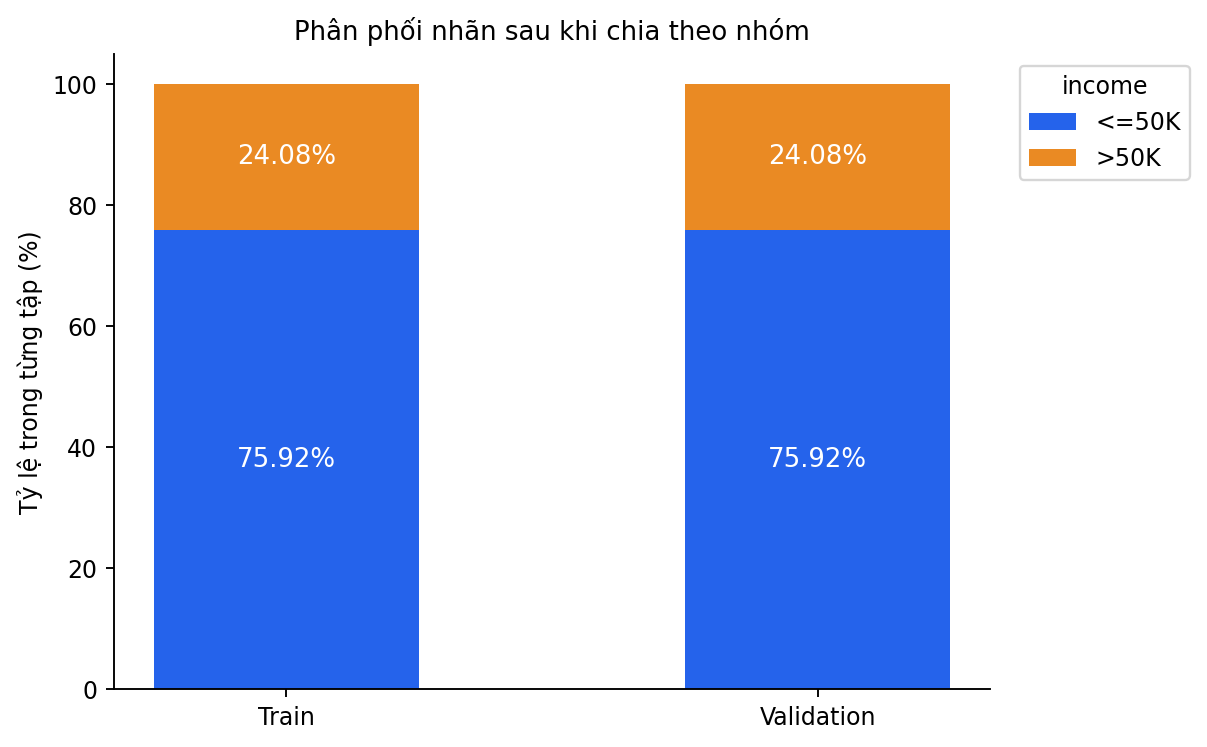

In [23]:
# 23. Vẽ phân phối nhãn train/validation sau khi chia.
splitting.plot_split_balance(STEP03_DIR)
display(Image(filename=str(STEP03_DIR / "train_validation_balance.png")))


### Cập nhật báo cáo và ZIP LaTeX
Nguồn báo cáo giữ nguyên chương 1 và EDA chương 3; bổ sung cách chia ở 4.2.2, nguyên tắc chống rò rỉ ở 4.2.3 và giao thức đánh giá ở 5.2. Các kết quả mô hình vẫn chưa có ở bước này.


In [24]:
# 24. Cập nhật LaTeX và tạo ZIP báo cáo hiện hành.
import json
from zipfile import ZIP_DEFLATED
splitting.update_latex(STEP03_DIR, REPORT_ROOT)
LATEX_ZIP = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_3.zip"
with ZipFile(LATEX_ZIP, "w", compression=ZIP_DEFLATED) as archive:
    for path in sorted(REPORT_ROOT.rglob("*")):
        if path.is_file():
            archive.write(path, path.relative_to(REPORT_ROOT).as_posix())
previous_zip = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_2.zip"
if previous_zip.is_file():
    previous_zip.unlink()
print("ZIP LaTeX hiện hành:", LATEX_ZIP)
print("Các tập và metadata:", PROJECT_ROOT / "data" / "splits")
print("Hoàn thành bước 3/7. Chưa fit bộ tiền xử lý hoặc huấn luyện.")


ZIP LaTeX hiện hành: C:\Users\Acer\Documents\Codex\2026-11-21\new-chat\BTL_ML_Final\reports\BTL_ML_LaTeX_Buoc_3.zip
Các tập và metadata: C:\Users\Acer\Documents\Codex\2026-11-21\new-chat\BTL_ML_Final\data\splits
Hoàn thành bước 3/7. Chưa fit bộ tiền xử lý hoặc huấn luyện.


# Bước 4 — Pipeline tiền xử lý và xuất đặc trưng

Các tập chia của bước 3 được giữ nguyên. Nhãn được tách khỏi 14 đầu vào trước khi fit. Imputer, encoder, scaler và PCA chỉ học từ train, rồi transform validation/test.

Xuất ba cấu hình: baseline (median + mode + one-hot + StandardScaler), PCA 90% và PCA 95%. Chưa huấn luyện mô hình hoặc chọn cấu hình theo điểm dự đoán.


In [25]:
#@title 25. Chuẩn bị module tiền xử lý
PREPROCESSING_SOURCE = '"""Pipeline tiền xử lý cấu hình được; fit chỉ trên train, không chứa bộ phân loại."""\nfrom pathlib import Path\nimport hashlib\nimport json\nimport platform\nimport warnings\n\nimport numpy as np\nimport pandas as pd\nimport joblib\nimport sklearn\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.decomposition import PCA\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, FunctionTransformer\nfrom sklearn.utils.validation import check_is_fitted\nfrom threadpoolctl import threadpool_limits\n\nfrom .data_loader import COLUMNS, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS\n\nFEATURE_COLUMNS=COLUMNS[:-1]\nTARGET_MAPPING={\'<=50K\':0,\'>50K\':1}\nDEFAULT_CONFIG={\n    \'numeric_imputation\':\'median\',\n    \'categorical_imputation\':\'most_frequent\',\n    \'missing_token\':\'__MISSING__\',\n    \'encoding\':\'onehot\',\n    \'scaling\':\'standard\',\n    \'feature_range\':[0.0,1.0],\n    \'pca_variance\':None,\n}\nEXPORT_CONFIGS={\n    \'baseline\':{},\n    \'pca_90\':{\'pca_variance\':0.90},\n    \'pca_95\':{\'pca_variance\':0.95},\n}\n\n\nclass AdultInputAdapter(TransformerMixin,BaseEstimator):\n    """Kiểm tra schema và chuyển pd.NA thành np.nan cho scikit-learn."""\n    def fit(self,X,y=None):\n        self.feature_names_in_=np.array(FEATURE_COLUMNS,dtype=object)\n        self.n_features_in_=len(FEATURE_COLUMNS)\n        self.fit_rows_=len(X)\n        self.transform(X)\n        return self\n\n    def transform(self,X):\n        check_is_fitted(self,\'feature_names_in_\')\n        if not isinstance(X,pd.DataFrame) or X.columns.has_duplicates:\n            raise ValueError(\'Đầu vào phải là DataFrame với tên cột duy nhất.\')\n        if set(X.columns)!=set(FEATURE_COLUMNS):\n            raise ValueError(\'Pipeline chỉ nhận đúng 14 thuộc tính, không nhận income hoặc cột metadata.\')\n        out=X.loc[:,FEATURE_COLUMNS].copy()\n        for column in NUMERIC_COLUMNS:\n            out[column]=pd.to_numeric(out[column],errors=\'raise\').astype(\'float64\')\n        for column in CATEGORICAL_COLUMNS:\n            values=out[column].astype(\'object\')\n            out[column]=values.where(pd.notna(values),np.nan)\n        return out\n\n    def get_feature_names_out(self,input_features=None):\n        check_is_fitted(self,\'feature_names_in_\')\n        return self.feature_names_in_.copy()\n\n\ndef normalize_config(config=None):\n    overrides=config or {}\n    unknown=set(overrides)-set(DEFAULT_CONFIG)\n    if unknown:raise ValueError(f\'Tham số không được hỗ trợ: {sorted(unknown)}\')\n    result={**DEFAULT_CONFIG,**overrides}\n    if result[\'numeric_imputation\'] not in [\'median\',\'mean\']:\n        raise ValueError(\'numeric_imputation phải là median hoặc mean.\')\n    if result[\'categorical_imputation\'] not in [\'most_frequent\',\'constant\']:\n        raise ValueError(\'categorical_imputation phải là most_frequent hoặc constant.\')\n    if result[\'encoding\'] not in [\'onehot\',\'ordinal\']:\n        raise ValueError(\'encoding phải là onehot hoặc ordinal.\')\n    if result[\'scaling\'] not in [\'standard\',\'minmax\',\'none\']:\n        raise ValueError(\'scaling phải là standard, minmax hoặc none.\')\n    bounds=result[\'feature_range\']\n    if len(bounds)!=2 or not all(np.isfinite(float(x)) for x in bounds) or not float(bounds[0])<float(bounds[1]):\n        raise ValueError(\'feature_range phải gồm hai số hữu hạn tăng dần.\')\n    result[\'feature_range\']=[float(x) for x in bounds]\n    if not isinstance(result[\'missing_token\'],str) or not result[\'missing_token\']:\n        raise ValueError(\'missing_token phải là chuỗi không rỗng.\')\n    pca=result[\'pca_variance\']\n    if pca is not None:\n        if isinstance(pca,bool) or not isinstance(pca,(float,np.floating)) or not 0<float(pca)<1:\n            raise ValueError(\'pca_variance phải là None hoặc số thực trong khoảng (0,1).\')\n        result[\'pca_variance\']=float(pca)\n    return result\n\n\ndef build_preprocessor(config=None):\n    """Trả về estimator CHƯA FIT, có thể clone và đặt trong CV pipeline."""\n    c=normalize_config(config)\n    scaler={\n        \'standard\':lambda:StandardScaler(),\n        \'minmax\':lambda:MinMaxScaler(feature_range=tuple(c[\'feature_range\']),clip=False),\n        \'none\':lambda:\'passthrough\',\n    }[c[\'scaling\']]()\n    numeric=Pipeline([\n        (\'imputer\',SimpleImputer(strategy=c[\'numeric_imputation\'],keep_empty_features=True)),\n        (\'scaler\',scaler),\n    ])\n    cat_imputer=SimpleImputer(\n        strategy=c[\'categorical_imputation\'],fill_value=c[\'missing_token\'],\n        keep_empty_features=True,\n    )\n    encoder=(OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False,dtype=np.float32)\n        if c[\'encoding\']==\'onehot\' else\n        OrdinalEncoder(handle_unknown=\'use_encoded_value\',unknown_value=-1,dtype=np.float32))\n    categorical=Pipeline([(\'imputer\',cat_imputer),(\'encoder\',encoder)])\n    columns=ColumnTransformer([\n        (\'numeric\',numeric,NUMERIC_COLUMNS),\n        (\'categorical\',categorical,CATEGORICAL_COLUMNS),\n    ],remainder=\'drop\',sparse_threshold=0,verbose_feature_names_out=True)\n    pca=\'passthrough\' if c[\'pca_variance\'] is None else PCA(n_components=c[\'pca_variance\'],svd_solver=\'full\',whiten=False)\n    return Pipeline([\n        (\'input\',AdultInputAdapter()),(\'columns\',columns),(\'pca\',pca),\n        (\'float32\',FunctionTransformer(np.asarray,kw_args={\'dtype\':np.float32},feature_names_out=\'one-to-one\')),\n    ])\n\n\ndef encode_target(frame):\n    if frame[\'income\'].isna().any() or not frame[\'income\'].isin(TARGET_MAPPING).all():\n        raise ValueError(\'Nhãn ngoài hai giá trị Adult hoặc bị thiếu.\')\n    return frame[\'income\'].map(TARGET_MAPPING).to_numpy(dtype=np.int8)\n\n\ndef _sha_file(path):\n    h=hashlib.sha256()\n    with Path(path).open(\'rb\') as stream:\n        for block in iter(lambda:stream.read(1024*1024),b\'\'):h.update(block)\n    return h.hexdigest()\n\n\ndef _audit_fit(pipeline,X_train,config):\n    """Đối chiếu các thống kê fitted với dữ liệu train, không dựa vào test."""\n    adapted=pipeline.named_steps[\'input\'].transform(X_train)\n    col=pipeline.named_steps[\'columns\']\n    numeric=col.named_transformers_[\'numeric\']\n    imputed=numeric.named_steps[\'imputer\'].transform(adapted[NUMERIC_COLUMNS])\n    expected=(adapted[NUMERIC_COLUMNS].median() if config[\'numeric_imputation\']==\'median\' else adapted[NUMERIC_COLUMNS].mean()).to_numpy()\n    expected=np.where(np.isnan(expected),0,expected)\n    np.testing.assert_allclose(numeric.named_steps[\'imputer\'].statistics_,expected,rtol=1e-12,atol=1e-12)\n    scaler=numeric.named_steps[\'scaler\']\n    if isinstance(scaler,StandardScaler):\n        np.testing.assert_allclose(scaler.mean_,imputed.mean(axis=0),rtol=1e-12,atol=1e-12)\n    elif isinstance(scaler,MinMaxScaler):\n        np.testing.assert_allclose(scaler.data_min_,imputed.min(axis=0))\n        np.testing.assert_allclose(scaler.data_max_,imputed.max(axis=0))\n    cat=col.named_transformers_[\'categorical\']\n    filled=cat.named_steps[\'imputer\'].transform(adapted[CATEGORICAL_COLUMNS])\n    for j,categories in enumerate(cat.named_steps[\'encoder\'].categories_):\n        if set(categories)!=set(filled[:,j]):raise AssertionError(\'Miền encoder khác miền sau điền thiếu trên train.\')\n    pca=pipeline.named_steps[\'pca\']\n    if isinstance(pca,PCA):\n        assert pca.n_samples_==len(X_train)\n        before_pca=col.transform(adapted)\n        np.testing.assert_allclose(pca.mean_,before_pca.mean(axis=0),rtol=1e-12,atol=1e-12)\n    return {\n        \'fit_rows\':len(X_train),\n        \'numeric_imputer_matches_train\':True,\n        \'numeric_scaler_matches_train\':True,\n        \'encoder_categories_match_train\':True,\n        \'pca_samples_match_train\':True if isinstance(pca,PCA) else None,\n    }\n\n\ndef export_features(frames,metadata,project_dir=\'.\',configs=None):\n    """Fit từng cấu hình trên train; xuất X/y/source_row, pipeline và manifest."""\n    if set(frames)!=set([\'train\',\'validation\',\'test\']) or set(metadata)!=set(frames):\n        raise ValueError(\'Cần đủ ba tập và metadata tương ứng.\')\n    root=Path(project_dir); features=root/\'features\';results=root/\'results/step_04\'\n    artifacts=root/\'artifacts/preprocessors\'\n    for directory in [features,results,artifacts]:directory.mkdir(parents=True,exist_ok=True)\n    snapshots={name:frame.copy(deep=True) for name,frame in frames.items()}\n    X={name:frame[FEATURE_COLUMNS].copy() for name,frame in frames.items()}\n    common_files={}\n    for name in [\'train\',\'validation\',\'test\']:\n        if len(frames[name])!=len(metadata[name]):raise ValueError(\'Metadata lệch số mẫu.\')\n        for prefix,array in [(\'y\',encode_target(frames[name])),\n            (\'source_row\',metadata[name][\'source_row\'].to_numpy(dtype=np.int64))]:\n            path=features/f\'{prefix}_{name}.npy\';np.save(path,array,allow_pickle=False)\n            common_files[path.relative_to(root).as_posix()]={\'shape\':list(array.shape),\'dtype\':str(array.dtype),\'sha256\':_sha_file(path)}\n    candidates=configs or EXPORT_CONFIGS\n    all_manifests={};shape_rows=[]\n    for name,overrides in candidates.items():\n        if not name.replace(\'_\',\'\').isalnum():raise ValueError(\'Tên cấu hình chỉ dùng chữ, số và dấu gạch dưới.\')\n        config=normalize_config(overrides)\n        pipeline=build_preprocessor(config)\n        with threadpool_limits(limits=2):\n            pipeline.fit(X[\'train\'])\n            fit_audit=_audit_fit(pipeline,X[\'train\'],config)\n            before_transform=joblib.hash(pipeline)\n            transformed={split:pipeline.transform(values) for split,values in X.items()}\n            after_transform=joblib.hash(pipeline)\n        if before_transform!=after_transform:raise AssertionError(\'Transform làm thay đổi trạng thái fitted.\')\n        names=list(map(str,pipeline.get_feature_names_out()))\n        directory=features/name;directory.mkdir(parents=True,exist_ok=True)\n        files={}\n        for split,array in transformed.items():\n            if array.dtype!=np.float32 or not np.isfinite(array).all():\n                raise AssertionError(\'Đặc trưng phải float32, hữu hạn và không NaN.\')\n            if array.shape!=(len(frames[split]),len(names)):\n                raise AssertionError(\'Đặc trưng bị lệch dòng hoặc số cột.\')\n            path=directory/f\'X_{split}.npy\';np.save(path,array,allow_pickle=False)\n            files[path.relative_to(root).as_posix()]={\'shape\':list(array.shape),\'dtype\':str(array.dtype),\'sha256\':_sha_file(path)}\n        (directory/\'feature_names.json\').write_text(json.dumps(names,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n        fitted_path=artifacts/f\'{name}.joblib\';joblib.dump(pipeline,fitted_path,compress=3)\n        pca=pipeline.named_steps[\'pca\']\n        retained=float(pca.explained_variance_ratio_.sum()) if isinstance(pca,PCA) else None\n        entry={\n            \'config\':config,\'feature_count\':len(names),\'fit_split\':\'train\',\n            \'fit_audit\':fit_audit,\'transform_did_not_change_fitted_state\':True,\n            \'pca_retained_variance\':retained,\'arrays\':files,\n            \'pipeline_path\':fitted_path.relative_to(root).as_posix(),\n            \'feature_names_path\':(directory/\'feature_names.json\').relative_to(root).as_posix(),\n        }\n        (directory/\'manifest.json\').write_text(json.dumps(entry,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n        all_manifests[name]=entry\n        for split,array in transformed.items():\n            shape_rows.append({\'configuration\':name,\'split\':split,\'rows\':array.shape[0],\'features\':array.shape[1],\n                \'dtype\':str(array.dtype),\'pca_retained_variance\':retained,\'all_values_finite\':True})\n        if isinstance(pca,PCA):\n            pd.DataFrame({\'component\':np.arange(1,len(pca.explained_variance_ratio_)+1),\n                \'explained_variance_ratio\':pca.explained_variance_ratio_,\n                \'cumulative_variance_ratio\':np.cumsum(pca.explained_variance_ratio_)}).to_csv(results/f\'{name}_variance.csv\',index=False,encoding=\'utf-8\')\n        del transformed\n    for name in frames:pd.testing.assert_frame_equal(frames[name],snapshots[name])\n    shape_table=pd.DataFrame(shape_rows);shape_table.to_csv(results/\'feature_shapes.csv\',index=False,encoding=\'utf-8\')\n    versions={\'python\':platform.python_version(),\'numpy\':np.__version__,\'pandas\':pd.__version__,\'sklearn\':sklearn.__version__,\'joblib\':joblib.__version__}\n    train_ids=metadata[\'train\'][\'source_id\'].astype(str).tolist()\n    manifest={\n        \'step\':4,\'fit_split\':\'train\',\'fit_rows\':len(frames[\'train\']),\n        \'input_feature_columns\':FEATURE_COLUMNS,\'numeric_columns\':NUMERIC_COLUMNS,\n        \'categorical_columns\':CATEGORICAL_COLUMNS,\'target_mapping\':TARGET_MAPPING,\n        \'source_ids_file\':\'data/splits/{split}_metadata.csv\',\n        \'training_source_ids_sha256\':hashlib.sha256(\'\\n\'.join(train_ids).encode(\'utf-8\')).hexdigest(),\n        \'common_arrays\':common_files,\'configurations\':all_manifests,\'versions\':versions,\n        \'source_data_mutated\':False,\'classifier_trained\':False,\n        \'cv_rule\':\'Use raw train data and fit a fresh complete pipeline inside each group CV fold; do not CV on these globally transformed X arrays.\',\n        \'test_model_metrics_computed\':False,\n    }\n    (features/\'manifest.json\').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    (results/\'preprocessing_summary.json\').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    (results/\'available_options.json\').write_text(json.dumps({\n        \'numeric_imputation\':[\'median\',\'mean\'],\'categorical_imputation\':[\'most_frequent\',\'constant\'],\n        \'encoding\':[\'onehot\',\'ordinal\'],\'scaling\':[\'standard\',\'minmax\',\'none\'],\n        \'feature_range\':\'[lower, upper], used for minmax\',\'pca_variance\':[None,0.90,0.95],\n    },ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    return manifest\n\n\ndef plot_preprocessing(result_dir=\'results/step_04\'):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    from matplotlib.patches import FancyBboxPatch,FancyArrowPatch\n    root=Path(result_dir)\n    fig,ax=plt.subplots(figsize=(10,9));ax.set_xlim(0,10);ax.set_ylim(0,10);ax.axis(\'off\')\n    def box(x,y,w,h,text,color=\'#E8F0FE\'):\n        ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle=\'round,pad=0.1\',facecolor=color,edgecolor=\'#2563EB\'))\n        ax.text(x+w/2,y+h/2,text,ha=\'center\',va=\'center\',fontsize=11)\n    def arrow(a,b):ax.add_patch(FancyArrowPatch(a,b,arrowstyle=\'-|>\',mutation_scale=14,color=\'#333333\'))\n    box(2.0,8.7,6,0.8,\'14 thuộc tính đầu vào, tách riêng nhãn income\')\n    box(.5,6.3,4,1.5,\'6 biến số\\nĐiền median / mean\\nStandard / MinMax / không scaling\')\n    box(5.5,6.3,4,1.5,\'8 biến phân loại\\nĐiền mode / nhóm thiếu\\nOne-hot / ordinal\')\n    box(2.5,4.7,5,.8,\'Ghép hai nhánh đặc trưng\')\n    box(2.5,3.1,5,.8,\'PCA tùy chọn: bỏ qua / 90% / 95%\')\n    box(2.5,1.5,5,.8,\'X float32, không NaN, lưu .npy\')\n    arrow((3.2,8.7),(2.5,7.8));arrow((6.8,8.7),(7.5,7.8))\n    arrow((2.5,6.3),(4,5.5));arrow((7.5,6.3),(6,5.5))\n    arrow((5,4.7),(5,3.9));arrow((5,3.1),(5,2.3))\n    ax.text(5,.5,\'FIT: chỉ train    |    TRANSFORM: train, validation, test\',ha=\'center\',fontsize=11,fontweight=\'bold\')\n    fig.tight_layout()\n    for ext in [\'pdf\',\'png\']:fig.savefig(root/f\'preprocessing_pipeline.{ext}\',bbox_inches=\'tight\',dpi=170)\n    plt.close(fig)\n    pca=pd.read_csv(root/\'pca_95_variance.csv\')\n    fig,ax=plt.subplots(figsize=(8,4.5))\n    ax.plot(pca[\'component\'],pca[\'cumulative_variance_ratio\']*100,color=\'#2563EB\',marker=\'o\',markersize=3)\n    for level,color in [(90,\'#EA8A23\'),(95,\'#64748B\')]:ax.axhline(level,color=color,linestyle=\'--\',label=f\'{level}%\')\n    ax.set(title=\'Phương sai tích lũy của các thành phần giữ trong PCA 95%\',xlabel=\'Số thành phần\',ylabel=\'Phương sai tích lũy (%)\',ylim=(0,100))\n    ax.grid(alpha=.2);ax.legend();fig.tight_layout()\n    for ext in [\'pdf\',\'png\']:fig.savefig(root/f\'pca_cumulative_variance.{ext}\',bbox_inches=\'tight\',dpi=170)\n    plt.close(fig)\n\n\ndef update_latex(result_dir=\'results/step_04\',report_root=\'reports/latex\'):\n    import shutil\n    result=Path(result_dir);report=Path(report_root)\n    summary=json.loads((result/\'preprocessing_summary.json\').read_text(encoding=\'utf-8\'))\n    entries=summary[\'configurations\']\n    baseline=entries[\'baseline\'];p90=entries[\'pca_90\'];p95=entries[\'pca_95\']\n    def write(rel,text):\n        path=report/rel;path.parent.mkdir(parents=True,exist_ok=True);path.write_text(text,encoding=\'utf-8\')\n    def number(x):return f\'{int(x):,}\'.replace(\',\',\'.\')\n    def percent(x):return f\'{float(x)*100:.2f}\'.replace(\'.\',\',\')\n    for stem,folder in [(\'preprocessing_pipeline\',\'4_1\'),(\'pca_cumulative_variance\',\'4_4\')]:\n        target=report/\'Images/chapter_4\'/folder;target.mkdir(parents=True,exist_ok=True)\n        for ext in [\'pdf\',\'png\']:shutil.copyfile(result/f\'{stem}.{ext}\',target/f\'{stem}.{ext}\')\n\n    write(\'chapters/chapter_2/2_1_bai_toan_phan_loai_nhi_phan.tex\',r\'\'\'\\section{Bài toán phân loại nhị phân}\n\\label{sec:2_1}\nTrong học có giám sát, mỗi mẫu gồm vector thuộc tính $\\mathbf{x}$ và nhãn $y$. Với bài toán phân loại nhị phân, $y\\in\\{0,1\\}$. Mô hình học từ các mẫu train để dự đoán nhãn hoặc điểm cho một mẫu mới.\n\nTrong đề tài này, nhãn \\texttt{<=50K} được ánh xạ thành 0 và \\texttt{>50K} thành 1. Nhãn được tách riêng trước khi fit mọi bộ biến đổi đầu vào. Mã hóa nhãn chỉ là quy ước biểu diễn; nó không bổ sung thông tin vào các đặc trưng. Việc chọn ngưỡng dự đoán và đánh giá chất lượng mô hình thuộc các bước thực nghiệm sau.\n\'\'\')\n    write(\'chapters/chapter_2/2_2_cac_ky_thuat_tien_xu_ly_du_lieu_bang.tex\',r\'\'\'\\section{Các kỹ thuật tiền xử lý dữ liệu bảng}\n\\label{sec:2_2}\nDữ liệu dạng bảng có thể gồm các biến số, biến phân loại và giá trị thiếu. Các bước biến đổi được tổ chức thành pipeline để cùng một quy tắc đã học trên train được áp dụng cho dữ liệu mới. Khi đánh giá bằng cross-validation, pipeline phải được fit lại bên trong từng fold~\\cite{sklearn-pitfalls}.\n\n\\input{chapters/chapter_2/2_2_1_dien_gia_tri_thieu}\n\\input{chapters/chapter_2/2_2_2_ma_hoa_bien_phan_loai}\n\\input{chapters/chapter_2/2_2_3_chuan_hoa_bien_so}\n\'\'\')\n    write(\'chapters/chapter_2/2_2_1_dien_gia_tri_thieu.tex\',r\'\'\'\\subsection{Điền giá trị thiếu}\n\\label{subsec:2_2_1}\nImputation thay thế giá trị thiếu bằng giá trị được xác định theo một quy tắc. Với biến số, hai lựa chọn thông dụng là trung bình và trung vị của các giá trị quan sát trên train. Trung vị ít bị ảnh hưởng bởi các giá trị cực trị hơn trung bình. Với biến phân loại, có thể điền mức xuất hiện nhiều nhất hoặc tạo một mức riêng biểu diễn trạng thái thiếu~\\cite{sklearn-imputer}.\n\nCác giá trị điền được học khi gọi \\texttt{fit}. Khi gọi \\texttt{transform} trên validation hoặc test, phải tái sử dụng các giá trị đó; không tính lại thống kê điền từ từng tập đánh giá. Trong hiện thực, cột hoàn toàn thiếu ở một lần fit vẫn được giữ để tránh mất vị trí cột giữa các lần biến đổi.\n\'\'\')\n    write(\'chapters/chapter_2/2_2_2_ma_hoa_bien_phan_loai.tex\',r\'\'\'\\subsection{Mã hóa biến phân loại}\n\\label{subsec:2_2_2}\nOne-hot encoding biểu diễn mỗi mức phân loại bằng một cột chỉ báo. Cách này cho phép mô hình sử dụng các mức của một biến mà không áp đặt thứ tự số học giữa chúng. Tập mức và thứ tự các cột được xác định từ train. Với mức chưa thấy khi fit, cấu hình \\texttt{handle\\_unknown=ignore} tạo các giá trị 0 cho nhánh one-hot của biến đó~\\cite{sklearn-onehot}.\n\nOrdinal encoding gán một mã số cho mỗi mức. Khi mức phân loại không có thứ tự tự nhiên, khoảng cách giữa các mã không mang sẵn ý nghĩa về dữ liệu; vì vậy cần xem nó là một lựa chọn để thực nghiệm, không mặc định tốt hơn one-hot. Trong pipeline của đề tài, mã $-1$ được dành cho mức chưa thấy khi dùng ordinal. Cả hai encoder đều được học sau bước điền thiếu và chỉ từ train.\n\'\'\')\n    write(\'chapters/chapter_2/2_2_3_chuan_hoa_bien_so.tex\',r\'\'\'\\subsection{Chuẩn hóa biến số}\n\\label{subsec:2_2_3}\nStandard scaling biến đổi một biến theo công thức\n\\begin{equation}\nz=\\frac{x-\\mu_{\\mathrm{train}}}{\\sigma_{\\mathrm{train}}},\n\\end{equation}\ntrong đó trung bình và độ lệch chuẩn được ước lượng trên train sau khi điền thiếu. Trong scikit-learn, độ lệch chuẩn dùng phương sai với mẫu số $n$. Với cột hằng, thư viện xử lý hệ số tỷ lệ để tránh chia cho 0.\n\nMin-max scaling ánh xạ dựa trên hai cực trị train vào khoảng cấu hình $[a,b]$:\n\\begin{equation}\nz=a+\\frac{x-x_{\\min,\\mathrm{train}}}{x_{\\max,\\mathrm{train}}-x_{\\min,\\mathrm{train}}}(b-a).\n\\end{equation}\nKhi không bật clipping, một giá trị validation hoặc test nằm ngoài miền train có thể cho kết quả ngoài $[a,b]$~\\cite{sklearn-preprocessing}. Đây không phải lỗi tính toán. Trong đề tài, scaling chỉ áp dụng cho nhánh sáu biến số; các cột one-hot giữ giá trị chỉ báo 0/1.\n\'\'\')\n    write(\'chapters/chapter_2/2_3_giam_chieu_bang_pca.tex\',r\'\'\'\\section{Giảm chiều bằng PCA}\n\\label{sec:2_3}\nPCA là phương pháp giảm chiều không sử dụng nhãn, tìm các hướng trực giao giữ nhiều phương sai của dữ liệu. Với ma trận đặc trưng đã xử lý $X\\in\\mathbb{R}^{n\\times d}$, đặt $X_c=X-\\boldsymbol{\\mu}$ và ma trận hiệp phương sai\n\\begin{equation}\nS=\\frac{1}{n-1}X_c^\\top X_c.\n\\end{equation}\nCác vector riêng của $S$ tương ứng với trị riêng giảm dần tạo nên những hướng thành phần chính. Chiếu lên $k$ hướng đầu cho biểu diễn $Z=X_cW_k$. Tỷ lệ phương sai được giữ lại là tổng các trị riêng được chọn chia cho tổng trị riêng.\n\nPipeline cho phép chọn mức phương sai 90\\% hoặc 95\\%. Với \\texttt{svd\\_solver=full}, scikit-learn chọn số thành phần sao cho tổng tỷ lệ phương sai vượt mức yêu cầu~\\cite{sklearn-pca}. PCA phải được fit trên train và tái sử dụng tâm cùng các hướng chiếu cho validation/test. Giữ nhiều phương sai hơn không tự bảo đảm chất lượng phân loại tốt hơn; điều đó phải được kiểm tra ở các thí nghiệm mô hình.\n\'\'\')\n    write(\'chapters/chapter_4/4_1_so_do_tong_the_cua_pipeline.tex\',r\'\'\'\\section{Sơ đồ tổng thể của pipeline}\n\\label{sec:4_1}\nSau khi khóa cách chia tập, dữ liệu đầu vào được tách thành sáu biến số và tám biến phân loại. Hai nhánh xử lý được ghép lại, có thể đi qua PCA, rồi chuyển thành ma trận \\texttt{float32}. Nhãn \\texttt{income} và các cột metadata không tham gia fit đặc trưng.\n\n\\begin{figure}[htbp]\n\\centering\n\\includegraphics[width=.88\\textwidth,height=.76\\textheight,keepaspectratio]{Images/chapter_4/4_1/preprocessing_pipeline.pdf}\n\\caption{Cấu trúc pipeline tiền xử lý; tất cả bước học tham số chỉ fit trên train}\n\\label{fig:preprocessing-pipeline}\n\\end{figure}\n\nBước 4 chỉ chuẩn bị đặc trưng và chưa huấn luyện bộ phân loại. Ở bước thực nghiệm tiếp theo, bộ tiền xử lý chưa fit sẽ được ghép với từng mô hình trong một pipeline hoàn chỉnh, để fit đúng phạm vi dữ liệu của mỗi fold.\n\'\'\')\n    write(\'chapters/chapter_4/4_3_tien_xu_ly_du_lieu.tex\',r\'\'\'\\section{Tiền xử lý dữ liệu}\n\\label{sec:4_3}\nHiện thực sử dụng \\texttt{Pipeline} và \\texttt{ColumnTransformer}. Một lớp thích nghi kiểm tra đúng tên 14 thuộc tính, giữ thứ tự cột và chuyển các giá trị thiếu sang dạng tương thích với scikit-learn. Nếu có nhãn hoặc cột metadata trong đầu vào, pipeline báo lỗi thay vì đưa chúng vào đặc trưng.\n\nTất cả 14 thuộc tính được giữ trong bước này, bao gồm \\texttt{fnlwgt} như một thuộc tính đầu vào; nó không được dùng làm trọng số mẫu. Hai trường \\texttt{education} và \\texttt{education-num} cùng mô tả học vấn nhưng được giữ theo schema ban đầu. Chưa thực hiện loại thuộc tính hoặc chọn đặc trưng theo nhãn.\n\n\\input{chapters/chapter_4/4_3_1_xu_ly_gia_tri_thieu}\n\\input{chapters/chapter_4/4_3_2_ma_hoa_bien_phan_loai}\n\\input{chapters/chapter_4/4_3_3_chuan_hoa_bien_so}\n\'\'\')\n    write(\'chapters/chapter_4/4_3_1_xu_ly_gia_tri_thieu.tex\',r\'\'\'\\subsection{Xử lý giá trị thiếu}\n\\label{subsec:4_3_1}\nCấu hình cơ sở dùng trung vị cho nhánh số và mức xuất hiện nhiều nhất cho nhánh phân loại. Các lựa chọn khác là trung bình cho biến số hoặc giá trị hằng \\texttt{\\_\\_MISSING\\_\\_} cho biến phân loại. Dữ liệu thiếu được điền mà không xóa dòng.\n\nChỉ gọi fit trên tập train đã tách ở bước 3. Các thống kê fitted được đối chiếu lại với train và lưu cùng thông tin phiên bản pipeline. Cột hoàn toàn thiếu được giữ; theo cách xử lý của \\texttt{SimpleImputer}, giá trị thay thế cho cột rỗng là 0 khi dùng chiến lược thống kê, hoặc hằng cấu hình khi dùng constant~\\cite{sklearn-imputer}.\n\'\'\')\n    write(\'chapters/chapter_4/4_3_2_ma_hoa_bien_phan_loai.tex\',r\'\'\'\\subsection{Mã hóa biến phân loại}\n\\label{subsec:4_3_2}\nCấu hình cơ sở dùng one-hot cho cả tám biến phân loại, không bỏ một mức tham chiếu và cho phép mức chưa thấy khi transform. Số cột đầu ra được xác định duy nhất từ những mức có trong train sau khi điền thiếu. Validation và test không bổ sung mức mới vào encoder.\n\nPipeline cũng hỗ trợ ordinal với mã $-1$ cho mức chưa thấy. Lựa chọn encoding được truyền qua cấu hình để các thí nghiệm sau có thể thay đúng một yếu tố mà giữ các bước còn lại.\n\'\'\')\n    write(\'chapters/chapter_4/4_3_3_chuan_hoa_bien_so.tex\',r\'\'\'\\subsection{Chuẩn hóa biến số}\n\\label{subsec:4_3_3}\nNhánh số dùng StandardScaler trong cấu hình cơ sở. Có thể chuyển sang MinMaxScaler với \\texttt{feature\\_range} cấu hình được hoặc bỏ scaling. Việc chuẩn hóa diễn ra sau điền thiếu và chỉ áp dụng cho sáu biến số.\n\nMinMaxScaler không bật clipping; do đó các giá trị đánh giá nằm ngoài miền train vẫn được giữ đúng theo phép biến đổi đã fit. Chưa loại các điểm bị gắn cờ IQR ở EDA. Các quyết định về hiệu quả của từng cách chuẩn hóa được dành cho bước thí nghiệm mô hình.\n\'\'\')\n    text=r\'\'\'\\section{Giảm chiều đặc trưng bằng PCA}\n\\label{sec:4_4}\nPCA được đặt sau khi ghép hai nhánh. Bước này tự center đầu vào đã xử lý và không whitening; không có bước scale bổ sung cho từng cột one-hot. Các hướng chiếu và số thành phần được học từ train, dùng bộ giải SVD đầy đủ.\n\'\'\'\n    text+=f"\\nCấu hình cơ sở có {number(baseline[\'feature_count\'])} đặc trưng. PCA 90\\\\% giữ {number(p90[\'feature_count\'])} thành phần và {percent(p90[\'pca_retained_variance\'])}\\\\% phương sai train; PCA 95\\\\% giữ {number(p95[\'feature_count\'])} thành phần và {percent(p95[\'pca_retained_variance\'])}\\\\% phương sai. Đây là kết quả kiểm tra đặc trưng, chưa phải so sánh chất lượng phân loại.\\n"\n    text+=r\'\'\'\n\\begin{figure}[htbp]\n\\centering\n\\includegraphics[width=.9\\textwidth]{Images/chapter_4/4_4/pca_cumulative_variance.pdf}\n\\caption{Phương sai tích lũy của những thành phần được giữ trong cấu hình PCA 95\\%}\n\\label{fig:pca-retained-variance}\n\\end{figure}\n\'\'\'\n    write(\'chapters/chapter_4/4_4_giam_chieu_dac_trung_bang_pca.tex\',text)\n    write(\'chapters/chapter_4/4_7_cau_hinh_cac_buoc_cua_pipeline.tex\',r\'\'\'\\section{Cấu hình các bước của pipeline}\n\\label{sec:4_7}\nHàm \\texttt{build\\_preprocessor(config)} trả về một pipeline chưa fit. Các tham số được kiểm tra trước khi tạo đối tượng. Cấu hình được lưu trong \\texttt{configs/preprocessing.json} và các manifest đầu ra.\n\n\\begin{table}[htbp]\n\\centering\\small\n\\caption{Các lựa chọn tiền xử lý được hỗ trợ}\\label{tab:preprocessing-options}\n\\begin{tabular}{p{.31\\textwidth}p{.57\\textwidth}}\n\\toprule\nThành phần & Lựa chọn \\\\\n\\midrule\nĐiền thiếu biến số & median hoặc mean \\\\\nĐiền thiếu phân loại & most\\_frequent hoặc constant với hằng cấu hình \\\\\nMã hóa & onehot hoặc ordinal \\\\\nScaling nhánh số & standard, minmax hoặc none \\\\\nKhoảng MinMax & Hai cận tăng dần, mặc định $[0,1]$ \\\\\nPCA & Bỏ qua, giữ 90\\% hoặc 95\\% phương sai \\\\\n\\bottomrule\n\\end{tabular}\n\\end{table}\n\nBa bộ đặc trưng được xuất ở bước 4 là baseline, pca\\_90 và pca\\_95. Các lựa chọn khác được hỗ trợ để dùng trong thí nghiệm, chưa có kết luận về hiệu quả dự đoán. Khi cross-validation, phải tạo pipeline mới trong từng fold và dùng dữ liệu train thô cùng mã nhóm; không dùng trực tiếp các ma trận đã fit từ toàn bộ train để tính điểm CV~\\cite{sklearn-pitfalls}.\n\'\'\')\n    text=r\'\'\'\\section{Lưu đặc trưng và thông tin đi kèm}\n\\label{sec:4_8}\nMỗi cấu hình có một thư mục \\texttt{features/<cau-hinh>/} chứa \\texttt{X\\_train.npy}, \\texttt{X\\_validation.npy}, \\texttt{X\\_test.npy}, tên cột và manifest. Các ma trận có kiểu \\texttt{float32}, cùng số cột trong một cấu hình, không NaN và không có giá trị vô hạn.\n\n\\begin{table}[htbp]\n\\centering\\small\n\\caption{Kích thước đặc trưng đã xuất ở bước 4}\\label{tab:feature-shapes}\n\\begin{tabular}{lrrr}\n\\toprule\nCấu hình & Train & Validation & Test \\\\\n\\midrule\n\'\'\'\n    for name,e in entries.items():\n        arrays=e[\'arrays\'];dims={split:arrays[f\'features/{name}/X_{split}.npy\'][\'shape\'] for split in [\'train\',\'validation\',\'test\']}\n        title=name.replace(\'_\',r\'\\_\')\n        text+=title+\' & \'+\' & \'.join(f"${number(dims[split][0])}\\\\times {dims[split][1]}$" for split in [\'train\',\'validation\',\'test\'])+r\' \\\\\'+\'\\n\'\n    text+=r\'\'\'\\bottomrule\n\\end{tabular}\n\\end{table}\n\nCác nhãn \\texttt{y\\_<tap>.npy} dùng kiểu \\texttt{int8}, với \\texttt{<=50K}=0 và \\texttt{>50K}=1. Các tệp \\texttt{source\\_row\\_<tap>.npy} dùng kiểu \\texttt{int64} và khớp thứ tự dòng với metadata đã khóa. Manifest ghi cấu hình, tên đặc trưng, ánh xạ nhãn, phiên bản thư viện, mã SHA-256 và nguồn train đã dùng để fit. Các pipeline fitted được lưu trong \\texttt{artifacts/preprocessors/} để tái sử dụng trong cùng môi trường tương thích.\n\nKiểm tra đã đối chiếu các thống kê imputer, scaler, miền encoder và tâm PCA với train. Trạng thái fitted không đổi sau transform validation/test. Dữ liệu gốc và phân chia bước 3 được giữ nguyên. Các nhãn test được mã hóa để lưu tệp, không dùng để fit đặc trưng, chọn cấu hình hoặc tính chỉ số mô hình.\n\'\'\'\n    write(\'chapters/chapter_4/4_8_luu_dac_trung_va_thong_tin_di_kem.tex\',text)\n    write(\'backmatter/appendix_a/A_3_danh_sach_tep_dac_trung_va_cach_su_dung.tex\',r\'\'\'\\section{Danh sách tệp đặc trưng và cách sử dụng}\n\\label{sec:A_3}\nBa thư mục đặc trưng là \\texttt{features/baseline/}, \\texttt{features/pca\\_90/} và \\texttt{features/pca\\_95/}. Mỗi thư mục chứa ba ma trận X cùng tên cột và manifest. Nhãn và chỉ số dòng dùng chung được đặt ngay trong \\texttt{features/}.\n\nĐọc tệp bằng \\texttt{numpy.load(..., allow\\_pickle=False)}. Ghép X với y và source\\_row của đúng tập, giữ nguyên thứ tự. Tra cứu mã nhóm và source\\_id trong metadata CSV ở \\texttt{data/splits/}. Không ghép cột giữa các cấu hình PCA và không đưa nhãn hoặc metadata vào X.\n\nCác ma trận này đã được fit tiền xử lý trên toàn bộ train, phù hợp với quy trình holdout đã khóa. Để cross-validation và tìm siêu tham số, dùng dữ liệu train thô và ghép \\texttt{build\\_preprocessor} vào pipeline mô hình để fit lại trong mỗi fold. Sau khi đổi cấu hình hoặc fit lại trên train cùng validation ở giai đoạn cuối, cần xuất lại đặc trưng và cập nhật manifest.\n\'\'\')\n    write(\'backmatter/appendix_a/A_1_chay_toan_bo_notebook_tren_google_colab.tex\',r\'\'\'\\section{Chạy toàn bộ notebook trên Google Colab}\n\\label{sec:A_1}\nTải \\texttt{notebooks/Adult\\_BTL.ipynb} lên Colab và chọn \\texttt{Runtime > Run all}. Notebook tự chuẩn bị module, tải dữ liệu công khai, EDA, khôi phục cách chia đã khóa, fit tiền xử lý trên train và xuất các bộ đặc trưng. Nguồn LaTeX và ZIP báo cáo được cập nhật từ chính kết quả vừa chạy.\n\nCác tệp đặc trưng và manifest nằm trong \\texttt{features/}; pipeline fitted nằm trong \\texttt{artifacts/preprocessors/}; kiểm tra bước 4 nằm trong \\texttt{results/step\\_04/}. Notebook dựng lại nguồn báo cáo từ khung nhúng, nên các sửa đổi tự thực hiện cần được sao lưu trước khi chạy lại.\n\nCác ô Python đã được kiểm tra cục bộ trên dữ liệu UCI gốc. Chưa xác nhận chạy trực tiếp trên dịch vụ Colab hoặc biên dịch toàn bộ LaTeX tại đây. Bước 4 chưa huấn luyện bộ phân loại hoặc báo cáo điểm mô hình.\n\'\'\')\n    reference=report/\'backmatter/references.tex\';text=reference.read_text(encoding=\'utf-8\')\n    refs={\n        \'sklearn-imputer\':(\'SimpleImputer\',\'https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html\'),\n        \'sklearn-onehot\':(\'OneHotEncoder\',\'https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html\'),\n        \'sklearn-preprocessing\':(\'Preprocessing data\',\'https://scikit-learn.org/stable/modules/preprocessing.html\'),\n        \'sklearn-pca\':(\'PCA\',\'https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html\'),\n        \'sklearn-pitfalls\':(\'Common pitfalls and recommended practices\',\'https://scikit-learn.org/stable/common_pitfalls.html\'),\n    }\n    for key,(title,url) in refs.items():\n        if f\'\\\\bibitem{{{key}}}\' not in text:\n            text=text.replace(r\'\\end{thebibliography}\',f\'\\\\bibitem{{{key}}}\\nScikit-learn developers, \\\\textit{{{title}}}, tài liệu chính thức.\\n\\\\url{{{url}}}.\\n\'+r\'\\end{thebibliography}\')\n    reference.write_text(text,encoding=\'utf-8\')\n    write(\'TIEN_DO.md\',\'# Tiến độ sau bước 4\\n\\nGiữ chương 1 và 3, phần chia tập của bước 3. Đã có lý thuyết phân loại, tiền xử lý, PCA; phần hiện thực tiền xử lý và lưu đặc trưng ở chương 4. Các mục mô hình và kết quả phân loại sẽ bổ sung ở bước 5–6. Chưa biên dịch toàn bộ LaTeX tại đây.\\n\')\n    return report\n'
(PROJECT_ROOT / "modules" / "preprocessing.py").write_text(PREPROCESSING_SOURCE, encoding="utf-8")
importlib.invalidate_caches()
import modules.preprocessing as preprocessing
preprocessing = importlib.reload(preprocessing)
print("Đã chuẩn bị modules/preprocessing.py")


Đã chuẩn bị modules/preprocessing.py


### Cấu hình tiền xử lý
Hàm `build_preprocessor(config)` hỗ trợ median/mean, mode/constant, onehot/ordinal, standard/minmax/none, khoảng MinMax và PCA tùy chọn. Các lựa chọn chưa được đánh giá bằng mô hình ở bước này.

Cấu hình xuất bên dưới dùng 14 thuộc tính, chỉ scale 6 biến số và giữ one-hot dưới dạng chỉ báo. Không xóa dòng trùng hoặc điểm ngoài IQR. Các tệp ghi rõ cấu hình thực tế trong manifest.


In [26]:
# 26. Cấu hình xuất đặc trưng của bước 4.
BASE_CONFIG = {
    "numeric_imputation": "median",
    "categorical_imputation": "most_frequent",
    "missing_token": "__MISSING__",
    "encoding": "onehot",
    "scaling": "standard",
    "feature_range": [0.0, 1.0],
    "pca_variance": None,
}
PREPROCESSING_CONFIGS = {
    "baseline": dict(BASE_CONFIG),
    "pca_90": {**BASE_CONFIG, "pca_variance": 0.90},
    "pca_95": {**BASE_CONFIG, "pca_variance": 0.95},
}
(PROJECT_ROOT / "configs").mkdir(exist_ok=True)
(PROJECT_ROOT / "configs" / "preprocessing.json").write_text(
    json.dumps(PREPROCESSING_CONFIGS, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Đã lưu configs/preprocessing.json")


Đã lưu configs/preprocessing.json


### Fit trên train và xuất ba bộ X
Mỗi cấu hình được fit độc lập trên cùng train đã khóa. Các giá trị fitted được đối chiếu với train; transform validation/test không được thay đổi trạng thái pipeline.

Đầu ra X dùng `float32`; y dùng `int8`, với `<=50K=0` và `>50K=1`; chỉ số dòng nguồn dùng `int64`. Các tệp NumPy không chứa object và được đọc bằng `allow_pickle=False`.


In [27]:
# 27. Fit trên train, transform các tập và xuất đặc trưng.
STEP04_DIR = PROJECT_ROOT / "results" / "step_04"
feature_manifest = preprocessing.export_features(
    split_frames, split_metadata, project_dir=PROJECT_ROOT,
    configs=PREPROCESSING_CONFIGS,
)
print("Đã xuất ba bộ đặc trưng vào features/.")
print("Pipeline fitted được lưu ở artifacts/preprocessors/.")
print("Không huấn luyện bộ phân loại ở bước này.")


Đã xuất ba bộ đặc trưng vào features/.
Pipeline fitted được lưu ở artifacts/preprocessors/.
Không huấn luyện bộ phân loại ở bước này.


In [28]:
# 28. Xem kích thước và phương sai PCA của các bộ đặc trưng.
feature_shapes = pd.read_csv(STEP04_DIR / "feature_shapes.csv")
display(feature_shapes)
for name, entry in feature_manifest["configurations"].items():
    retained = entry["pca_retained_variance"]
    print(name, "→", entry["feature_count"], "đặc trưng",
          "" if retained is None else f"; phương sai giữ lại {retained * 100:.2f}%")


baseline → 105 đặc trưng 
pca_90 → 22 đặc trưng ; phương sai giữ lại 90.70%
pca_95 → 31 đặc trưng ; phương sai giữ lại 95.12%


,configuration,split,rows,features,dtype,pca_retained_variance,all_values_finite
0,baseline,train,26049,105,float32,NaN,True
1,baseline,validation,6512,105,float32,NaN,True
2,baseline,test,16281,105,float32,NaN,True
3,pca_90,train,26049,22,float32,0.907009,True
4,pca_90,validation,6512,22,float32,0.907009,True
5,pca_90,test,16281,22,float32,0.907009,True
6,pca_95,train,26049,31,float32,0.951172,True
7,pca_95,validation,6512,31,float32,0.951172,True
8,pca_95,test,16281,31,float32,0.951172,True


### Đọc lại .npy và kiểm tra căn chỉnh dòng
Các tệp `y_<tap>.npy` và `source_row_<tap>.npy` được dùng chung cho ba cấu hình. Manifest chứa SHA-256, tên đặc trưng và phiên bản thư viện. Source ID và group ID vẫn nằm trong metadata CSV của bước 3.

Các ma trận này đã fit tiền xử lý trên toàn bộ train. Chúng phù hợp với quy trình holdout đã khóa; **không dùng trực tiếp để cross-validation mô hình**. Bước 5 sẽ dùng dữ liệu thô và fit lại pipeline trong từng fold theo nhóm.


In [29]:
# 29. Đọc và kiểm tra các file NumPy không dùng pickle.
import numpy as np
for name in PREPROCESSING_CONFIGS:
    for split in ["train", "validation", "test"]:
        X = np.load(PROJECT_ROOT / "features" / name / f"X_{split}.npy", allow_pickle=False, mmap_mode="r")
        y = np.load(PROJECT_ROOT / "features" / f"y_{split}.npy", allow_pickle=False)
        source_row = np.load(PROJECT_ROOT / "features" / f"source_row_{split}.npy", allow_pickle=False)
        assert X.shape[0] == len(y) == len(source_row) == len(split_frames[split])
        assert X.dtype == np.float32 and np.isfinite(X).all()
        np.testing.assert_array_equal(source_row, split_metadata[split]["source_row"].to_numpy())
print("Các file .npy đều đúng kiểu, hữu hạn và khớp thứ tự dòng.")
names = json.loads((PROJECT_ROOT / "features" / "baseline" / "feature_names.json").read_text(encoding="utf-8"))
X_preview = np.load(PROJECT_ROOT / "features" / "baseline" / "X_train.npy", allow_pickle=False, mmap_mode="r")
display(pd.DataFrame(X_preview[:3, :10], columns=names[:10]))


Các file .npy đều đúng kiểu, hữu hạn và khớp thứ tự dòng.


,numeric__age,numeric__fnlwgt,numeric__education-num,numeric__capital-gain,numeric__capital-loss,numeric__hours-per-week,categorical__workclass_Federal-gov,categorical__workclass_Local-gov,categorical__workclass_Never-worked,categorical__workclass_Private
0,0.034256,-1.066081,1.137333,0.147558,-0.217842,-0.041475,0.0,0.0,0.0,0.0
1,-0.039558,0.238592,-0.418838,-0.145329,-0.217842,-0.041475,0.0,0.0,0.0,1.0
2,1.067659,0.418760,-1.196923,-0.145329,-0.217842,-0.041475,0.0,0.0,0.0,1.0


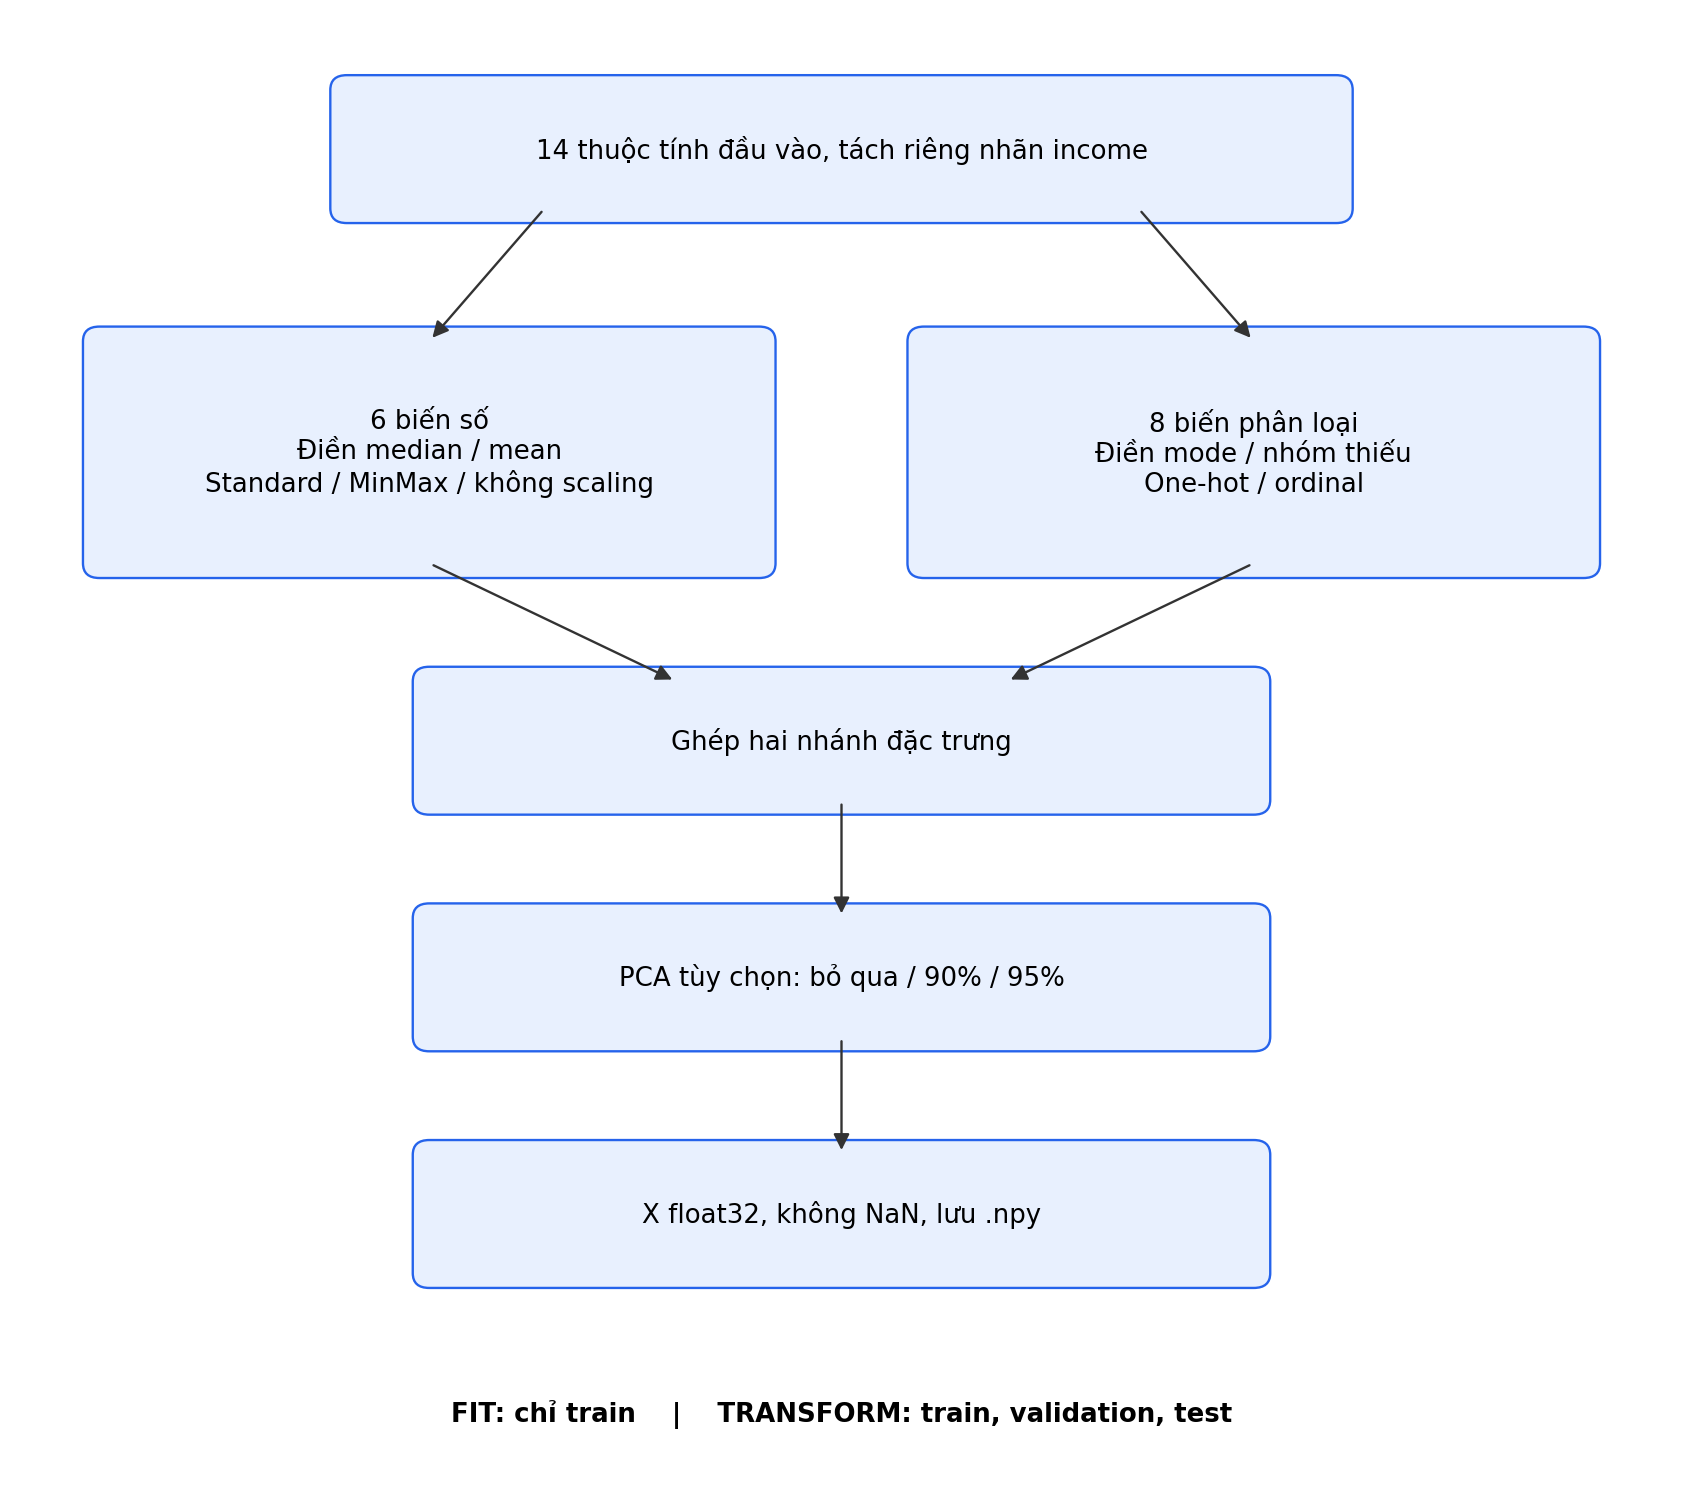

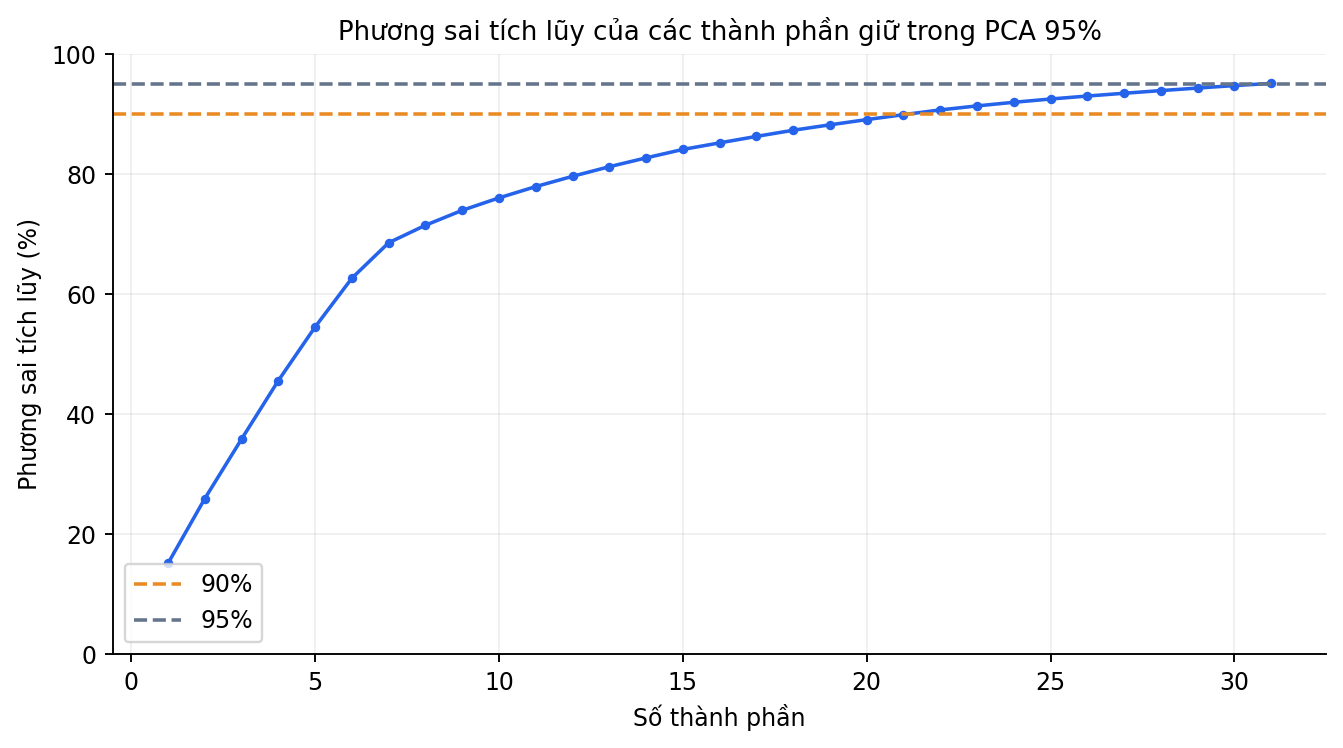

In [30]:
# 30. Sơ đồ tiền xử lý và phương sai PCA, chỉ tính từ train.
preprocessing.plot_preprocessing(STEP04_DIR)
for name in ["preprocessing_pipeline", "pca_cumulative_variance"]:
    display(Image(filename=str(STEP04_DIR / f"{name}.png")))


### Tái sử dụng đối tượng fitted
Các file `.joblib` lưu bộ biến đổi đã fit. Khi dùng lại cần có module tương ứng và môi trường thư viện tương thích; chạy notebook từ đầu sẽ tạo đối tượng phù hợp với môi trường hiện tại.


In [31]:
# 31. Kiểm tra đọc lại pipeline do notebook vừa tạo.
import joblib
restored_preprocessor = joblib.load(PROJECT_ROOT / "artifacts" / "preprocessors" / "baseline.joblib")
restored_output = restored_preprocessor.transform(df_train[data_loader.COLUMNS[:-1]].head(10))
np.testing.assert_allclose(restored_output, X_preview[:10], rtol=1e-6, atol=1e-6)
print("Pipeline đọc lại cho đúng kết quả đã lưu.")


Pipeline đọc lại cho đúng kết quả đã lưu.


### Cập nhật báo cáo
Giữ các phần đã hoàn thành. Bổ sung lý thuyết tiền xử lý/PCA, sơ đồ hiện thực, cấu hình và bảng kích thước đặc trưng. Các mục mô hình và kết quả phân loại sẽ được bổ sung sau.


In [32]:
# 32. Cập nhật nguồn và ZIP LaTeX của bước 4.
preprocessing.update_latex(STEP04_DIR, REPORT_ROOT)
LATEX_ZIP = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_4.zip"
with ZipFile(LATEX_ZIP, "w", compression=ZIP_DEFLATED) as archive:
    for path in sorted(REPORT_ROOT.rglob("*")):
        if path.is_file():
            archive.write(path, path.relative_to(REPORT_ROOT).as_posix())
previous_zip = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_3.zip"
if previous_zip.is_file():
    previous_zip.unlink()
print("ZIP LaTeX:", LATEX_ZIP)
print("Hoàn thành bước 4/7. Sẵn sàng bước 5: thí nghiệm mô hình theo nhóm.")


ZIP LaTeX: C:\Users\Acer\Documents\Codex\2026-11-21\new-chat\BTL_ML_Final\reports\BTL_ML_LaTeX_Buoc_4.zip
Hoàn thành bước 4/7. Sẵn sàng bước 5: thí nghiệm mô hình theo nhóm.


# Bước 5 — Thí nghiệm và khóa mô hình

So sánh Logistic Regression, SVM tuyến tính (LinearSVC), Random Forest, MLP và mốc dự đoán đa số. Vòng so sánh cuối gồm **20 cấu hình × 3 fold = 60 lượt fit CV**. Tiền xử lý chỉ fit từ phần train của từng fold; không CV trực tiếp trên các ma trận `.npy` bước 4.

F1 của lớp `>50K` là tiêu chí lựa chọn. Lựa chọn được khóa bằng CV trước khi đối chiếu validation; **chưa dùng test để đánh giá mô hình**. Đây là tìm kiếm giới hạn, chưa phải điểm hiệu quả cuối cùng trên test.

Hai MLP ban đầu đạt 300 epoch mà chưa hội tụ trong pilot. Bổ sung hai cấu hình có regularization mạnh hơn và tiêu chí dừng theo training loss khác; giữ kết quả/cảnh báo của cả bốn cấu hình. Việc mở rộng dựa trên train/CV, trước khi xem validation hoặc test. Các file pilot được đính kèm như lịch sử lần chuẩn bị, không được trình bày như một lượt huấn luyện mới trong phiên Colab.


In [33]:
#@title 33. Chuẩn bị module và lịch sử pilot của bước 5
STEP05_SOURCES = {'training.py': '"""Thí nghiệm bước 5: CV theo nhóm trên raw train, không nhận dữ liệu test."""\nfrom pathlib import Path\nimport hashlib, json, platform, time, warnings\nimport numpy as np\nimport pandas as pd\nimport joblib, sklearn\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.model_selection import StratifiedGroupKFold\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.svm import LinearSVC\nfrom sklearn.ensemble import RandomForestClassifier\nfrom sklearn.neural_network import MLPClassifier\nfrom sklearn.dummy import DummyClassifier\nfrom sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score\nfrom sklearn.exceptions import ConvergenceWarning\nfrom threadpoolctl import threadpool_limits\nfrom .preprocessing import build_preprocessor, normalize_config, encode_target, FEATURE_COLUMNS, _audit_fit\nfrom .splitting import frame_fingerprint, make_group_ids\n\nSEED=42\nMETRICS=[\'f1\',\'precision\',\'recall\',\'accuracy\',\'macro_f1\',\'roc_auc\']\nCV_CONFIG={\'n_splits\':3,\'shuffle\':True,\'random_state\':SEED}\n\ndef candidate_configs():\n    rows=[{\'id\':\'dummy_majority\',\'family\':\'Dummy\',\'scope\':\'reference\',\'preprocessing\':{},\'model\':{}}]\n    for family,prefix in [(\'LogisticRegression\',\'lr\'),(\'LinearSVC\',\'svm\')]:\n        for c,tag in [(0.1,\'01\'),(1.0,\'1\'),(10.0,\'10\')]:\n            rows.append({\'id\':f\'{prefix}_c{tag}\',\'family\':family,\'scope\':\'model\',\'preprocessing\':{},\'model\':{\'C\':c}})\n    for tag,depth,leaf in [(\'full_leaf1\',None,1),(\'full_leaf3\',None,3),(\'depth20_leaf3\',20,3)]:\n        rows.append({\'id\':\'rf_\'+tag,\'family\':\'RandomForest\',\'scope\':\'model\',\'preprocessing\':{},\n                     \'model\':{\'n_estimators\':150,\'max_depth\':depth,\'min_samples_leaf\':leaf}})\n    for tag,layers,alpha in [(\'64\',[64],0.0001),(\'64_32\',[64,32],0.001)]:\n        rows.append({\'id\':\'mlp_\'+tag,\'family\':\'MLP\',\'scope\':\'model\',\'preprocessing\':{},\n                     \'model\':{\'hidden_layer_sizes\':layers,\'alpha\':alpha}})\n    for tag,scope,config in [\n        (\'missing_constant\',\'preprocessing\',{\'categorical_imputation\':\'constant\'}),\n        (\'ordinal\',\'preprocessing\',{\'encoding\':\'ordinal\'}),\n        (\'minmax01\',\'preprocessing\',{\'scaling\':\'minmax\',\'feature_range\':[0,1]}),\n        (\'minmax11\',\'preprocessing\',{\'scaling\':\'minmax\',\'feature_range\':[-1,1]}),\n        (\'pca90\',\'pca\',{\'pca_variance\':0.90}),\n        (\'pca95\',\'pca\',{\'pca_variance\':0.95}),\n    ]:\n        rows.append({\'id\':\'lr_\'+tag,\'family\':\'LogisticRegression\',\'scope\':scope,\'preprocessing\':config,\'model\':{\'C\':1.0}})\n    # Bổ sung sau pilot 18 cấu hình: chỉ dựa vào cảnh báo tối ưu trong train/CV,\n    # chưa xem validation hay test; giữ nguyên và báo cáo cả hai MLP ban đầu.\n    for tag,layers,alpha in [(\'32_reg\',[32],0.01),(\'64_reg\',[64],0.1)]:\n        rows.append({\'id\':\'mlp_\'+tag,\'family\':\'MLP\',\'scope\':\'model\',\'preprocessing\':{},\n            \'model\':{\'hidden_layer_sizes\':layers,\'alpha\':alpha,\'tol\':0.001,\'n_iter_no_change\':10}})\n    return rows\n\ndef build_model(candidate):\n    c=candidate[\'model\']; family=candidate[\'family\']\n    if family==\'Dummy\':return DummyClassifier(strategy=\'most_frequent\')\n    if family==\'LogisticRegression\':\n        return LogisticRegression(C=c[\'C\'],solver=\'lbfgs\',max_iter=2000,tol=1e-5,random_state=SEED)\n    if family==\'LinearSVC\':\n        return LinearSVC(C=c[\'C\'],dual=False,max_iter=10000,tol=1e-5,random_state=SEED)\n    if family==\'RandomForest\':\n        return RandomForestClassifier(**c,max_features=\'sqrt\',bootstrap=True,n_jobs=1,random_state=SEED)\n    if family==\'MLP\':\n        return MLPClassifier(hidden_layer_sizes=tuple(c[\'hidden_layer_sizes\']),alpha=c[\'alpha\'],\n            activation=\'relu\',solver=\'adam\',learning_rate_init=0.001,batch_size=256,\n            max_iter=300,tol=c.get(\'tol\',1e-4),n_iter_no_change=c.get(\'n_iter_no_change\',20),early_stopping=False,random_state=SEED)\n    raise ValueError(\'Mô hình không được hỗ trợ: \'+str(family))\n\ndef build_training_pipeline(candidate):\n    return Pipeline([(\'preprocessing\',build_preprocessor(candidate[\'preprocessing\'])),(\'model\',build_model(candidate))])\n\ndef score_vector(pipeline,X):\n    if hasattr(pipeline,\'decision_function\'):\n        return np.asarray(pipeline.decision_function(X),dtype=float)\n    classes=pipeline.named_steps[\'model\'].classes_\n    column=int(np.flatnonzero(classes==1)[0])\n    return np.asarray(pipeline.predict_proba(X)[:,column],dtype=float)\n\ndef compute_metrics(y,pred,score):\n    return {\'f1\':float(f1_score(y,pred,pos_label=1,zero_division=0)),\n        \'precision\':float(precision_score(y,pred,pos_label=1,zero_division=0)),\n        \'recall\':float(recall_score(y,pred,pos_label=1,zero_division=0)),\n        \'accuracy\':float(accuracy_score(y,pred)),\n        \'macro_f1\':float(f1_score(y,pred,average=\'macro\',zero_division=0)),\n        \'roc_auc\':float(roc_auc_score(y,score))}\n\ndef _json_write(path,value):\n    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)\n    path.write_text(json.dumps(value,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n\ndef _digest(value):\n    return hashlib.sha256(json.dumps(value,sort_keys=True,separators=(\',\',\':\'),ensure_ascii=False).encode(\'utf-8\')).hexdigest()\n\ndef frozen_cv(train,metadata,path,config=None):\n    config=dict(CV_CONFIG if config is None else config)\n    if train.columns.tolist()!=FEATURE_COLUMNS+[\'income\']:\n        raise ValueError(\'Train phải giữ đúng schema 14 thuộc tính và income.\')\n    groups=metadata[\'group_id\'].astype(str).to_numpy()\n    if len(groups)!=len(train) or metadata[\'source_id\'].duplicated().any():\n        raise ValueError(\'Metadata train không hợp lệ.\')\n    np.testing.assert_array_equal(groups,np.asarray(make_group_ids(train)))\n    expected={\'data_sha256\':frame_fingerprint(train),\'source_ids_sha256\':_digest(metadata[\'source_id\'].astype(str).tolist()),\n        \'groups_sha256\':_digest(groups.tolist()),\'config\':config}\n    path=Path(path)\n    if path.exists():\n        manifest=json.loads(path.read_text(encoding=\'utf-8\'))\n        if manifest[\'identity\']!=expected:raise ValueError(\'CV manifest khác dữ liệu/metadata/cấu hình; không tự chia lại.\')\n    else:\n        splitter=StratifiedGroupKFold(**config)\n        manifest={\'identity\':expected,\'generator_sklearn\':sklearn.__version__,\n            \'validation_indices\':[va.tolist() for _,va in splitter.split(train,encode_target(train),groups)]}\n        _json_write(path,manifest)\n    folds=[];seen=np.zeros(len(train),dtype=int)\n    if len(manifest[\'validation_indices\'])!=config[\'n_splits\']:raise ValueError(\'Sai số fold.\')\n    all_indices=np.arange(len(train))\n    for indices in manifest[\'validation_indices\']:\n        va=np.asarray(indices,dtype=np.int64)\n        if len(va)==0 or len(set(va))!=len(va) or (va<0).any() or (va>=len(train)).any():\n            raise ValueError(\'Chỉ số fold không hợp lệ.\')\n        tr=np.setdiff1d(all_indices,va)\n        if set(groups[tr])&set(groups[va]):raise ValueError(\'Nhóm trùng xuất hiện hai phía fold.\')\n        if len(np.unique(encode_target(train.iloc[va])))!=2:raise ValueError(\'Fold cần đủ hai lớp.\')\n        seen[va]+=1;folds.append((tr,va))\n    if not np.all(seen==1):raise ValueError(\'Các fold không phủ mỗi dòng đúng một lần.\')\n    return folds,manifest\n\ndef _fit(pipeline,X,y,candidate):\n    start=time.perf_counter()\n    with warnings.catch_warnings(record=True) as caught:\n        warnings.simplefilter(\'always\')\n        pipeline.fit(X,y)\n    elapsed=time.perf_counter()-start\n    convergence=[str(w.message) for w in caught if issubclass(w.category,ConvergenceWarning)]\n    notices=[{\'type\':w.category.__name__,\'message\':str(w.message)} for w in caught]\n    prep=pipeline.named_steps[\'preprocessing\']\n    audit=_audit_fit(prep,X,normalize_config(candidate[\'preprocessing\']))\n    if prep.named_steps[\'input\'].fit_rows_!=len(X):raise AssertionError(\'Fit sai số dòng train.\')\n    return elapsed,convergence,notices,audit\n\ndef run_cv(train,metadata,project_dir=\'.\',candidates=None,cv_config=None,reuse_completed=True):\n    root=Path(project_dir);out=root/\'results/step_05\';out.mkdir(parents=True,exist_ok=True)\n    candidates=candidate_configs() if candidates is None else candidates\n    if len({c[\'id\'] for c in candidates})!=len(candidates):raise ValueError(\'Candidate ID bị lặp.\')\n    folds,cv_manifest=frozen_cv(train,metadata,out/\'cv_indices.json\',cv_config)\n    _json_write(root/\'configs/experiments.json\',{\'seed\':SEED,\'cv\':cv_manifest[\'identity\'][\'config\'],\n        \'selection\':\'maximum mean CV F1 of >50K; tie: smaller std then candidate ID\',\n        \'threshold\':\'native predict: probability 0.5, LinearSVC decision 0\',\n        \'class_weight\':None,\'sampling\':\'none\',\'candidates\':candidates})\n    cache_identity={\'train\':frame_fingerprint(train),\'cv\':_digest(cv_manifest),\'candidates\':_digest(candidates),\n        \'sklearn\':sklearn.__version__,\'numpy\':np.__version__,\'pandas\':pd.__version__,\'python\':platform.python_version(),\n        \'source_hashes\':{name:hashlib.sha256((Path(__file__).parent/name).read_bytes()).hexdigest()\n                         for name in [\'training.py\',\'preprocessing.py\',\'splitting.py\',\'data_loader.py\']}}\n    cache_path=out/\'cv_complete.json\'\n    if reuse_completed and cache_path.exists():\n        saved=json.loads(cache_path.read_text(encoding=\'utf-8\'))\n        if saved[\'identity\']!=cache_identity:raise ValueError(\'Cache CV khác dữ liệu/code/phiên bản; tắt reuse_completed để chạy lại.\')\n        for rel,sha in saved[\'files\'].items():\n            if hashlib.sha256((root/rel).read_bytes()).hexdigest()!=sha:raise ValueError(\'Cache CV đã thay đổi: \'+rel)\n        print(\'Tái sử dụng CV đã hoàn tất, khớp dữ liệu, fold, cấu hình, mã nguồn, phiên bản và SHA-256.\',flush=True)\n        return pd.read_csv(out/\'cv_summary.csv\'),json.loads((out/\'selection_cv.json\').read_text(encoding=\'utf-8\'))\n    fold_summary=[]\n    for i,(tr,va) in enumerate(folds):\n        fold_summary.append({\'fold\':i,\'fit_rows\':len(tr),\'assessment_rows\':len(va),\n            \'fit_positive_percent\':float(encode_target(train.iloc[tr]).mean()*100),\n            \'assessment_positive_percent\':float(encode_target(train.iloc[va]).mean()*100),\n            \'group_overlap\':0})\n    pd.DataFrame(fold_summary).to_csv(out/\'cv_fold_summary.csv\',index=False)\n    X=train[FEATURE_COLUMNS].copy();y=encode_target(train);snapshot=train.copy(deep=True)\n    scores=[];audits=[]\n    with threadpool_limits(limits=2):\n        for ci,c in enumerate(candidates,1):\n            print(f"[{ci}/{len(candidates)}] {c[\'id\']}",flush=True)\n            for fold,(tr,va) in enumerate(folds):\n                pipeline=build_training_pipeline(c)\n                elapsed,conv,notices,audit=_fit(pipeline,X.iloc[tr],y[tr],c)\n                before=joblib.hash(pipeline)\n                start=time.perf_counter();pred=pipeline.predict(X.iloc[va]);score=score_vector(pipeline,X.iloc[va])\n                predict_seconds=time.perf_counter()-start\n                if joblib.hash(pipeline)!=before:raise AssertionError(\'Predict thay đổi trạng thái fitted.\')\n                if not np.isfinite(score).all():raise AssertionError(\'Điểm dự đoán không hữu hạn.\')\n                row={\'candidate_id\':c[\'id\'],\'family\':c[\'family\'],\'scope\':c[\'scope\'],\'fold\':fold,\n                    **compute_metrics(y[va],pred,score),\'fit_seconds\':elapsed,\'predict_seconds\':predict_seconds,\n                    \'feature_count\':len(pipeline.named_steps[\'preprocessing\'].get_feature_names_out()),\n                    \'fit_rows\':len(tr),\'assessment_rows\':len(va),\'convergence_warning_count\':len(conv)}\n                scores.append(row)\n                audits.append({\'candidate_id\':c[\'id\'],\'fold\':fold,\'fit_audit\':audit,\'warnings\':notices,\n                    \'model_n_iter\':np.asarray(getattr(pipeline.named_steps[\'model\'],\'n_iter_\',[])).tolist(),\n                    \'prediction_state_unchanged\':True})\n                pd.DataFrame(scores).to_csv(out/\'cv_folds.csv\',index=False)\n                _json_write(out/\'fit_audits.json\',audits)\n                print(f"  fold {fold+1}: F1={row[\'f1\']:.4f}, fit={elapsed:.1f}s, convergence warnings={len(conv)}",flush=True)\n    pd.testing.assert_frame_equal(train,snapshot)\n    summary=[];df=pd.DataFrame(scores)\n    for c in candidates:\n        group=df[df[\'candidate_id\']==c[\'id\']]\n        row={\'candidate_id\':c[\'id\'],\'family\':c[\'family\'],\'scope\':c[\'scope\'],\'folds\':len(group)}\n        for metric in METRICS:\n            row[metric+\'_mean\']=float(group[metric].mean());row[metric+\'_std\']=float(group[metric].std(ddof=1))\n        row.update({\'fit_seconds_mean\':float(group[\'fit_seconds\'].mean()),\n            \'convergence_warning_count\':int(group[\'convergence_warning_count\'].sum()),\n            \'preprocessing_json\':json.dumps(normalize_config(c[\'preprocessing\']),sort_keys=True),\n            \'model_json\':json.dumps(c[\'model\'],sort_keys=True)})\n        summary.append(row)\n    summary=pd.DataFrame(summary).sort_values([\'f1_mean\',\'f1_std\',\'candidate_id\'],ascending=[False,True,True]).reset_index(drop=True)\n    summary.to_csv(out/\'cv_summary.csv\',index=False)\n    # Convergence is reported, not hidden; do not lock an unconverged candidate.\n    eligible=summary[(summary.family!=\'Dummy\')&(summary.convergence_warning_count==0)]\n    if eligible.empty:raise RuntimeError(\'Không có cấu hình hội tụ để chọn; cần khảo sát lại và ghi rõ thay đổi.\')\n    selection={\'cv_manifest_sha256\':_digest(cv_manifest),\'candidates_sha256\':_digest(candidates),\n        \'training_data_sha256\':frame_fingerprint(train),\'selection_metric\':\'f1_mean\',\n        \'tie_breakers\':[\'f1_std ascending\',\'candidate_id ascending\'],\n        \'winner_id\':str(eligible.iloc[0].candidate_id),\n        \'family_winners\':{f:str(g.iloc[0].candidate_id) for f,g in eligible.groupby(\'family\',sort=True)},\n        \'convergence_policy\':\'Candidates with any convergence warning are reported but excluded from locking.\',\n        \'validation_used_for_selection\':False,\'test_accessed_by_experiment\':False,\n        \'versions\':{\'python\':platform.python_version(),\'sklearn\':sklearn.__version__,\'numpy\':np.__version__,\n                    \'pandas\':pd.__version__,\'joblib\':joblib.__version__},\n        \'candidate_count\':len(candidates),\'fold_count\':len(folds),\'cv_fit_count\':len(scores),\n        \'note\':\'CV mean selected from this search is not an unbiased final performance estimate.\'}\n    _json_write(out/\'selection_cv.json\',selection)\n    paths=[out/name for name in [\'cv_folds.csv\',\'cv_summary.csv\',\'cv_fold_summary.csv\',\'fit_audits.json\',\'selection_cv.json\']]\n    _json_write(cache_path,{\'identity\':cache_identity,\'files\':{p.relative_to(root).as_posix():hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}})\n    return summary,selection\n\ndef refit_and_validate(train,train_meta,validation,validation_meta,project_dir=\'.\'):\n    """Khóa lựa chọn bằng CV trước; validation chỉ đối chiếu, không chọn lại."""\n    root=Path(project_dir);out=root/\'results/step_05\';art=root/\'artifacts/models\';art.mkdir(parents=True,exist_ok=True)\n    selection=json.loads((out/\'selection_cv.json\').read_text(encoding=\'utf-8\'))\n    configs=json.loads((root/\'configs/experiments.json\').read_text(encoding=\'utf-8\'))\n    candidates={c[\'id\']:c for c in configs[\'candidates\']}\n    if selection[\'training_data_sha256\']!=frame_fingerprint(train) or selection[\'candidates_sha256\']!=_digest(configs[\'candidates\']):\n        raise ValueError(\'Dữ liệu/cấu hình khác giai đoạn CV đã khóa.\')\n    if set(train_meta[\'group_id\'])&set(validation_meta[\'group_id\']):raise ValueError(\'Train/validation trùng nhóm.\')\n    if set(train_meta[\'source_id\'])&set(validation_meta[\'source_id\']):raise ValueError(\'Train/validation trùng ID.\')\n    snapshots=[train.copy(deep=True),validation.copy(deep=True)]\n    X=train[FEATURE_COLUMNS]; y=encode_target(train);Xv=validation[FEATURE_COLUMNS];yv=encode_target(validation)\n    ids=list(selection[\'family_winners\'].values())+[\'dummy_majority\']\n    rows=[];fitted={};predictions={};logs=[]\n    with threadpool_limits(limits=2):\n        for ident in ids:\n            c=candidates[ident];p=build_training_pipeline(c)\n            print(\'Refit + validation:\',ident,flush=True)\n            seconds,conv,notices,audit=_fit(p,X,y,c)\n            if conv:raise RuntimeError(\'Refit chưa hội tụ: \'+ident+\'; không tự đổi siêu tham số.\')\n            state=joblib.hash(p);pred=p.predict(Xv);score=score_vector(p,Xv)\n            if joblib.hash(p)!=state:raise AssertionError(\'Validation thay đổi pipeline.\')\n            path=art/f\'{ident}.joblib\';joblib.dump(p,path,compress=3)\n            fitted[ident]=path.relative_to(root).as_posix()\n            rows.append({\'candidate_id\':ident,\'family\':c[\'family\'],**compute_metrics(yv,pred,score),\n                         \'fit_seconds\':seconds,\'fit_rows\':len(train),\'validation_rows\':len(validation),\n                         \'selected_by_cv\':ident==selection[\'winner_id\']})\n            predictions[ident]=pd.DataFrame({\'source_id\':validation_meta[\'source_id\'].to_numpy(),\n                \'y_true\':yv,\'y_pred\':pred,\'score\':score})\n            predictions[ident].to_csv(out/f\'validation_predictions_{ident}.csv\',index=False)\n            logs.append({\'candidate_id\':ident,\'fit_audit\':audit,\'warnings\':notices,\n                         \'model_n_iter\':np.asarray(getattr(p.named_steps[\'model\'],\'n_iter_\',[])).tolist()})\n            if c[\'family\']==\'MLP\':\n                pd.DataFrame({\'epoch\':np.arange(1,len(p.named_steps[\'model\'].loss_curve_)+1),\n                    \'training_loss\':p.named_steps[\'model\'].loss_curve_}).to_csv(out/\'mlp_training_loss.csv\',index=False)\n    for frame,snapshot in zip([train,validation],snapshots):pd.testing.assert_frame_equal(frame,snapshot)\n    table=pd.DataFrame(rows);table.to_csv(out/\'validation_summary.csv\',index=False)\n    _json_write(out/\'refit_audits.json\',logs)\n    selection.update({\'fitted_models\':fitted,\'selected_model_path\':fitted[selection[\'winner_id\']],\n        \'validation_data_sha256\':frame_fingerprint(validation),\'refit_rows\':len(train),\n        \'validation_rows\':len(validation),\'refit_fit_count\':len(ids),\n        \'threshold_tuned\':False,\'refit_on_train_plus_validation\':False,\n        \'test_model_metrics_computed\':False})\n    _json_write(out/\'selected_model.json\',selection)\n    return table,selection\n\ndef plot_experiments(result_dir=\'results/step_05\'):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    root=Path(result_dir);summary=pd.read_csv(root/\'cv_summary.csv\')\n    def plot(table,labels,stem,title):\n        fig,ax=plt.subplots(figsize=(8,4.7))\n        bars=ax.bar(np.arange(len(table)),table.f1_mean,yerr=table.f1_std,capsize=4,color=\'#2563EB\',alpha=.85)\n        ax.set_xticks(np.arange(len(table)),labels,rotation=15,ha=\'right\')\n        ax.set(title=title,ylabel=\'F1 lớp >50K — mean ± SD (3 fold)\',ylim=(0,1))\n        for bar,value in zip(bars,table.f1_mean):ax.text(bar.get_x()+bar.get_width()/2,value+.025,f\'{value:.3f}\',ha=\'center\',fontsize=9)\n        ax.grid(axis=\'y\',alpha=.2);fig.tight_layout()\n        for ext in [\'png\',\'pdf\']:fig.savefig(root/f\'{stem}.{ext}\',dpi=160,bbox_inches=\'tight\')\n        plt.close(fig)\n    base=summary[summary.scope.isin([\'model\',\'reference\'])].sort_values([\'f1_mean\',\'f1_std\',\'candidate_id\'],ascending=[False,True,True])\n    base=base.groupby(\'family\',sort=True).head(1).sort_values(\'family\')\n    plot(base,base.family.tolist(),\'cv_models\',\'So sánh mô hình trên cùng tiền xử lý cơ sở\')\n    ids=[\'lr_c1\',\'lr_missing_constant\',\'lr_ordinal\',\'lr_minmax01\',\'lr_minmax11\']\n    t=summary.set_index(\'candidate_id\').loc[ids].reset_index()\n    plot(t,[\'Cơ sở\',\'Nhóm thiếu\',\'Ordinal\',\'MinMax [0,1]\',\'MinMax [-1,1]\'],\'cv_preprocessing\',\'Thay từng lựa chọn tiền xử lý — Logistic Regression C=1\')\n    t=summary.set_index(\'candidate_id\').loc[[\'lr_c1\',\'lr_pca90\',\'lr_pca95\']].reset_index()\n    plot(t,[\'Không PCA\',\'PCA 90%\',\'PCA 95%\'],\'cv_pca\',\'Ảnh hưởng của PCA — Logistic Regression C=1\')\n    return [\'cv_models\',\'cv_preprocessing\',\'cv_pca\']\n', 'experiment_report.py': '"""Cập nhật các mục LaTeX từ bảng thực nghiệm bước 5 đã chạy."""\nfrom pathlib import Path\nimport json,shutil\nimport pandas as pd\n\ndef update_experiment_report(result_dir=\'results/step_05\',report_root=\'reports/latex\'):\n    result=Path(result_dir);report=Path(report_root)\n    summary=pd.read_csv(result/\'cv_summary.csv\')\n    validation=pd.read_csv(result/\'validation_summary.csv\')\n    chosen=json.loads((result/\'selected_model.json\').read_text(encoding=\'utf-8\'))\n    def write(folder,prefix,text):\n        matches=list((report/folder).glob(prefix+\'*.tex\'))\n        if len(matches)!=1:raise ValueError((folder,prefix,matches))\n        matches[0].write_text(text,encoding=\'utf-8\')\n    def esc(value):return str(value).replace(\'_\',r\'\\_\').replace(\'%\',r\'\\%\')\n    def num(x):return f\'{x:.4f}\'.replace(\'.\',\',\')\n    def table(data,caption,label):\n        lines=[r\'\\begin{table}[htbp]\',r\'\\centering\\scriptsize\',r\'\\caption{\'+caption+r\'}\\label{\'+label+\'}\',\n               r\'\\begin{tabular}{lrrrr}\',r\'\\toprule\',r\'Cấu hình & F1 CV & SD & Precision & Recall \\\\\',r\'\\midrule\']\n        for _,r in data.iterrows():\n            lines.append(esc(r.candidate_id)+\' & \'+\' & \'.join(num(r[c]) for c in [\'f1_mean\',\'f1_std\',\'precision_mean\',\'recall_mean\'])+r\' \\\\\')\n        return \'\\n\'.join(lines+[r\'\\bottomrule\',r\'\\end{tabular}\',r\'\\end{table}\'])\n    def figure(stem,section,caption):\n        dest=report/\'Images/chapter_6\'/section;dest.mkdir(parents=True,exist_ok=True)\n        for ext in [\'png\',\'pdf\']:shutil.copyfile(result/f\'{stem}.{ext}\',dest/f\'{stem}.{ext}\')\n        return \'\\n\'.join([r\'\\begin{figure}[htbp]\',r\'\\centering\',r\'\\includegraphics[width=.95\\textwidth]{Images/chapter_6/\'+section+\'/\'+stem+\'.pdf}\',\n            r\'\\caption{\'+caption+\'}\',r\'\\label{fig:\'+stem.replace(\'_\',\'-\')+\'}\',r\'\\end{figure}\'])\n    c2=\'chapters/chapter_2\';c4=\'chapters/chapter_4\';c5=\'chapters/chapter_5\';c6=\'chapters/chapter_6\'\n    write(c2,\'2_4_cac_\',r\'\'\'\\section{Các mô hình học máy truyền thống}\n\\label{sec:2_4}\nBa họ mô hình được sử dụng gồm Logistic Regression, SVM tuyến tính và Random Forest. Chúng đại diện cho mô hình xác suất tuyến tính, mô hình phân tách biên và tổ hợp cây quyết định. Cùng một quy trình điền thiếu, mã hóa và chuẩn hóa được đặt trước mỗi bộ phân loại để so sánh trên các fold giống nhau.\n\\input{chapters/chapter_2/2_4_1_logistic_regression}\n\\input{chapters/chapter_2/2_4_2_support_vector_machine}\n\\input{chapters/chapter_2/2_4_3_random_forest}\n\'\'\')\n    write(c2,\'2_4_1_\',r\'\'\'\\subsection{Logistic Regression}\n\\label{subsec:2_4_1}\nVới vector đặc trưng $\\mathbf{x}$, mô hình ước lượng xác suất lớp dương bằng\n\\[\np(y=1\\mid\\mathbf{x})=\\sigma(\\mathbf{w}^{T}\\mathbf{x}+b),\\qquad\n\\sigma(z)=\\frac{1}{1+e^{-z}}.\n\\]\nTham số được học bằng cách giảm hàm mất mát logarit có phạt L2. Tham số $C$ điều khiển nghịch đảo mức regularization: giá trị nhỏ tương ứng với phạt mạnh hơn trong cùng cách triển khai. Thí nghiệm sử dụng bộ giải lbfgs và thử $C\\in\\{0{,}1;1;10\\}$~\\cite{sklearn-logistic}. Nhãn dự đoán dùng ngưỡng xác suất 0,5; không tối ưu ngưỡng trên validation hoặc test.\n\nMô hình có thời gian huấn luyện tương đối thấp và tạo mốc so sánh dễ giải thích. Tuy nhiên, một biên tuyến tính trên đặc trưng đã mã hóa có thể chưa biểu diễn đầy đủ các quan hệ phi tuyến giữa các thuộc tính của Adult.\n\'\'\')\n    write(c2,\'2_4_2_\',r\'\'\'\\subsection{Support Vector Machine}\n\\label{subsec:2_4_2}\nSVM tuyến tính tìm một siêu phẳng phân tách các lớp. Với nhãn quy đổi $t_i\\in\\{-1,+1\\}$ và $f(\\mathbf{x})=\\mathbf{w}^{T}\\mathbf{x}+b$, mất mát squared hinge có dạng $\\max(0,1-t_i f(\\mathbf{x}_i))^2$. Thành phần phạt L2 kiểm soát độ lớn tham số, còn $C$ điều chỉnh sự đánh đổi giữa phạt và sai số trên dữ liệu huấn luyện.\n\nBài làm sử dụng \\texttt{LinearSVC}, không thử kernel RBF. Vì số mẫu lớn hơn số đặc trưng, bộ giải được cấu hình \\texttt{dual=False}. Khảo sát $C\\in\\{0{,}1;1;10\\}$ trên cùng các fold. Dự đoán nhãn dùng dấu của decision score, còn ROC-AUC dùng trực tiếp decision score; các điểm này không được gọi là xác suất~\\cite{sklearn-linearsvc}.\n\'\'\')\n    write(c2,\'2_4_3_\',r\'\'\'\\subsection{Random Forest}\n\\label{subsec:2_4_3}\nRandom Forest kết hợp nhiều cây quyết định được học trên các mẫu bootstrap và các tập thuộc tính ứng viên ngẫu nhiên. Trong triển khai này, xác suất lớp dương là trung bình xác suất từ các cây: $\\hat p(1\\mid\\mathbf{x})=B^{-1}\\sum_{b=1}^{B}p_b(1\\mid\\mathbf{x})$. Mô hình có thể biểu diễn tương tác phi tuyến mà không giả định một biên phân tách tuyến tính~\\cite{sklearn-rf}.\n\nThí nghiệm dùng 150 cây, \\texttt{max\\_features=sqrt} và ba cấu hình: độ sâu không giới hạn với lá tối thiểu 1 mẫu; độ sâu không giới hạn với lá tối thiểu 3 mẫu; độ sâu tối đa 20 với lá tối thiểu 3 mẫu. Các thiết lập khác được giữ cố định. Lá nhỏ và cây sâu có thể tăng khả năng khớp train nhưng cũng tăng chi phí bộ nhớ và nguy cơ quá khớp; kết quả CV được dùng để lựa chọn trong phạm vi đã khảo sát.\n\'\'\')\n    write(c2,\'2_5_\',r\'\'\'\\section{Mạng nơ-ron nhiều lớp MLP}\n\\label{sec:2_5}\nMLP truyền đầu vào qua các lớp kết nối đầy đủ. Với $\\mathbf{h}^{(0)}=\\mathbf{x}$, một lớp ẩn thực hiện $\\mathbf{h}^{(l)}=\\operatorname{ReLU}(W^{(l)}\\mathbf{h}^{(l-1)}+\\mathbf{b}^{(l)})$. Đầu ra nhị phân sử dụng hàm logistic để ước lượng xác suất lớp dương. Các tham số được cập nhật bằng Adam dựa trên mất mát logarit có regularization L2~\\cite{sklearn-mlp}.\n\nHai cấu hình được so sánh là một lớp ẩn 64 nút với $\\alpha=10^{-4}$ và hai lớp ẩn 64--32 nút với $\\alpha=10^{-3}$. Đây là hai cấu hình kết hợp; vì kiến trúc và mức phạt cùng thay đổi, không quy mọi khác biệt kết quả chỉ cho số lớp. Batch size bằng 256, learning rate ban đầu 0,001 và tối đa 300 epoch. Không bật early stopping với một tập nội bộ ngẫu nhiên để tránh phát sinh cách chia không theo nhóm; tiêu chí dừng theo training loss được áp dụng trong phạm vi phần train của mỗi fold.\n\nSau khi hai cấu hình trên phát sinh cảnh báo đạt giới hạn epoch trong pilot, bổ sung cấu hình 32 nút với $\\alpha=0{,}01$ và 64 nút với $\\alpha=0{,}1$. Hai cấu hình bổ sung dùng tol $10^{-3}$, chờ 10 epoch, thay cho tol $10^{-4}$ và chờ 20 epoch ban đầu. Cả bốn cấu hình cùng được báo cáo; không dùng validation hoặc test để quyết định mở rộng này.\n\nMLP là phần mở rộng để đối chiếu với pipeline truyền thống. Mạng vẫn dùng các đặc trưng đã điền thiếu, one-hot và chuẩn hóa; không được mô tả như một mô hình tự xử lý dữ liệu phân loại thô đầu cuối.\n\'\'\')\n    write(c2,\'2_6_\',r\'\'\'\\section{Các chỉ số đánh giá mô hình}\n\\label{sec:2_6}\nChọn \\texttt{>50K} làm lớp dương. TP là số mẫu dương dự đoán đúng, FP là số mẫu âm dự đoán nhầm thành dương, FN là số mẫu dương dự đoán nhầm thành âm, TN là số mẫu âm dự đoán đúng. Các chỉ số được tính như sau:\n\\[\n\\mathrm{Accuracy}=\\frac{TP+TN}{TP+TN+FP+FN},\\quad\n\\mathrm{Precision}=\\frac{TP}{TP+FP},\\quad\n\\mathrm{Recall}=\\frac{TP}{TP+FN},\n\\]\n\\[\nF_1=\\frac{2TP}{2TP+FP+FN},\\qquad\n\\mathrm{Macro\\text{-}}F_1=\\frac{F_{1,0}+F_{1,1}}{2}.\n\\]\nKhi không có dự đoán dương, precision và F1 được quy ước bằng 0. ROC-AUC đánh giá thứ hạng điểm dự đoán qua các ngưỡng thay vì chỉ dùng nhãn tại một ngưỡng. Accuracy dễ tạo ấn tượng cao khi lớp âm chiếm đa số; vì vậy F1 lớp dương được chọn làm tiêu chí chính, đi kèm precision, recall, macro-F1 và ROC-AUC~\\cite{sklearn-f1}.\n\nMỗi cấu hình được báo cáo trung bình và độ lệch chuẩn mẫu (ddof=1) qua ba fold. Độ lệch chuẩn mô tả biến động giữa các fold, không phải khoảng tin cậy hoặc kiểm định ý nghĩa thống kê. Điểm CV cao nhất sau khi thử nhiều cấu hình còn chịu ảnh hưởng của quá trình lựa chọn và không thay thế đánh giá test độc lập.\n\'\'\')\n    write(c4,\'4_5_\',r\'\'\'\\section{Huấn luyện các mô hình truyền thống}\n\\label{sec:4_5}\nModule \\texttt{modules/training.py} tạo một pipeline gồm bộ tiền xử lý chưa fit và bộ phân loại. Logistic Regression, LinearSVC và Random Forest được huấn luyện trên raw train trong ba fold theo nhóm. Các file X đã xuất ở bước 4 không được dùng trực tiếp để tính CV.\n\nTrong mỗi fold, imputer, encoder, scaler và PCA chỉ fit trên phần train của fold, sau đó mới transform phần đánh giá. Các thống kê fitted được đối chiếu với phần train tương ứng. Số mẫu fit, số đặc trưng, thời gian, số vòng lặp và cảnh báo hội tụ được lưu lại. Mọi cấu hình dùng cùng các chỉ số fold đã khóa trong \\texttt{results/step\\_05/cv\\_indices.json}.\n\nSau khi hoàn tất CV, cấu hình tốt nhất trong từng họ được fit lại trên 26.049 dòng train và lưu cùng bộ tiền xử lý dưới dạng pipeline \\texttt{.joblib}. Tập validation chỉ được dùng để đối chiếu các mô hình đã khóa; không huấn luyện lại bằng train cộng validation ở bước này.\n\'\'\')\n    write(c4,\'4_6_\',r\'\'\'\\section{Xây dựng mô hình MLP để so sánh}\n\\label{sec:4_6}\nMLP được đặt sau đúng quy trình tiền xử lý cơ sở và sử dụng cùng nhãn, fold và tiêu chí đánh giá với các mô hình truyền thống. Hai cấu hình ban đầu là 64 và 64--32 nút; hai cấu hình 32 và 64 nút với regularization mạnh hơn được bổ sung sau pilot để xử lý cảnh báo tối ưu. Seed bằng 42; số luồng BLAS được giới hạn ở 2 để kiểm soát tài nguyên khi chạy tuần tự.\n\nKhông dùng validation bên ngoài để dừng học hoặc chọn số epoch. Early stopping nội bộ của \\texttt{MLPClassifier} được tắt; thuật toán có thể dừng khi training loss không cải thiện đủ theo tol và số epoch chờ đã cấu hình. Cảnh báo không hội tụ được ghi vào audit, không bị bỏ qua. Đường training loss của bản MLP fit lại được lưu ở \\texttt{mlp\\_training\\_loss.csv}; đây là training loss, không phải đường đánh giá test.\n\'\'\')\n    versions=chosen[\'versions\']\n    write(c5,\'5_1_\',r\'\'\'\\section{Môi trường thực nghiệm và khả năng tái lập}\n\\label{sec:5_1}\nNotebook tự tải ZIP UCI, tạo các module và chuẩn bị thư viện, không mount cloud cá nhân. Các fold được lưu theo chỉ số dòng với fingerprint dữ liệu và mã nhóm; khi chạy lại, dữ liệu hoặc cấu hình không khớp sẽ bị từ chối thay vì tự chia lại.\n\nCác kết quả trong báo cáo được tạo bằng \'\'\'+\n        \'Python \'+esc(versions[\'python\'])+\', scikit-learn \'+esc(versions[\'sklearn\'])+\', NumPy \'+esc(versions[\'numpy\'])+\' và pandas \'+esc(versions[\'pandas\'])+r\'\'\'. Seed bằng 42. Các cấu hình được chạy tuần tự, Random Forest dùng một worker, BLAS giới hạn 2 luồng. Thời gian huấn luyện phụ thuộc phần cứng và được dùng để tham khảo, không xem là kết quả benchmark giữa các máy.\n\nCache CV chỉ được tái sử dụng khi dữ liệu, metadata, fold, cấu hình, phiên bản, mã nguồn và SHA-256 của các tệp kết quả đều khớp. Notebook độc lập trên môi trường Colab mới không có cache sẽ thực hiện đầy đủ thí nghiệm. Quy trình notebook đã được thực thi từ đầu đến cuối trên Google Colab. Các số liệu trong báo cáo tương ứng với môi trường thực nghiệm được ghi ở trên.\n\'\'\')\n    write(c5,\'5_2_\',r\'\'\'\\section{Giao thức đánh giá và chỉ số lựa chọn}\n\\label{sec:5_2}\nGiữ nguyên phân chia bước 3: train 26.049 mẫu, validation 6.512 mẫu và test UCI 16.281 mẫu. Bên trong train, áp dụng StratifiedGroupKFold với 3 fold, shuffle bật và random state bằng 42. Các bản ghi có cùng 14 thuộc tính đầu vào được giữ chung nhóm, kể cả trường hợp nhãn khác nhau~\\cite{sklearn-sgkf}.\n\nF1 của lớp \\texttt{>50K} là tiêu chí lựa chọn. Các chỉ số bổ sung gồm precision, recall, accuracy, macro-F1 và ROC-AUC. Chọn cấu hình có trung bình F1 CV cao nhất; khi bằng nhau ưu tiên độ lệch chuẩn nhỏ hơn, sau đó ID theo thứ tự chữ. Cấu hình có cảnh báo không hội tụ trong bất kỳ fold nào vẫn được báo cáo nhưng không được khóa làm mô hình cuối của họ.\n\nTất cả bộ biến đổi được fit lại bên trong fold bằng raw train. Không dùng X đã fit tiền xử lý trên toàn bộ train để tính CV~\\cite{sklearn-pitfalls}. Không resampling, không class weighting, không tối ưu ngưỡng. Dùng ngưỡng dự đoán mặc định: xác suất 0,5 hoặc decision score 0 cho LinearSVC.\n\nLựa chọn chung và lựa chọn trong từng họ được khóa bằng CV trước khi tính validation. Validation là đối chiếu mô tả; không chọn lại theo F1 validation. Điểm CV của cấu hình thắng là điểm phục vụ lựa chọn trong một tìm kiếm giới hạn, không phải ước lượng không thiên lệch cho hiệu quả cuối cùng.\n\'\'\')\n    write(c5,\'5_3_\',r\'\'\'\\section{Mô hình cơ sở và các siêu tham số khảo sát}\n\\label{sec:5_3}\nVòng thí nghiệm cuối gồm 20 cấu hình, mỗi cấu hình được đánh giá trên 3 fold, tương ứng 60 lượt fit CV:\n\\begin{itemize}\n\\item DummyClassifier luôn dự đoán lớp đa số: 1 cấu hình tham chiếu, không tham gia chọn mô hình thắng.\n\\item Logistic Regression: $C=0{,}1;1;10$, lbfgs, tối đa 2.000 vòng lặp, tol $10^{-5}$: 3 cấu hình.\n\\item LinearSVC: $C=0{,}1;1;10$, squared hinge, L2, dual=False, tối đa 10.000 vòng lặp, tol $10^{-5}$: 3 cấu hình.\n\\item Random Forest: 150 cây, max\\_features=sqrt, bootstrap; ba lựa chọn depth/leaf đã mô tả: 3 cấu hình.\n\\item MLP: hai cấu hình ban đầu 64 và 64--32, Adam, 300 epoch tối đa, batch 256, tol $10^{-4}$, chờ 20 epoch; hai cấu hình bổ sung 32 và 64 nút, regularization mạnh hơn, tol $10^{-3}$, chờ 10 epoch: tổng 4 cấu hình.\n\\item Logistic Regression $C=1$ với bốn biến thể điền thiếu/mã hóa/scaling và hai biến thể PCA: 6 cấu hình.\n\\end{itemize}\nToàn bộ cấu hình đầy đủ được lưu trong \\texttt{configs/experiments.json}; tham số mô hình mặc định còn lại được lưu trong các pipeline và được diễn giải theo phiên bản thư viện. Không gọi đây là tìm kiếm tối ưu toàn cục: số lựa chọn của các họ không bằng nhau và phạm vi khảo sát có giới hạn.\n\nPilot 18 cấu hình đầu tiên tạo 54 lượt fit, trong đó hai cấu hình MLP đều đạt giới hạn epoch ở cả ba fold. Sau khi kiểm tra cảnh báo tối ưu, bổ sung hai cấu hình MLP và chạy lại vòng 20 cấu hình. Đây là mở rộng dựa trên thông tin train/CV, không phải toàn bộ tìm kiếm được ấn định trước từ đầu. Kết quả pilot được giữ trong \\texttt{results/step\\_05/pilot\\_18/}; lý do thay đổi nằm trong \\texttt{experiment\\_revision.json}. Chưa xem validation hoặc test trước khi thay đổi.\n\'\'\')\n    write(c5,\'5_4_\',r\'\'\'\\section{Thí nghiệm so sánh các mô hình truyền thống}\n\\label{sec:5_4}\nSo sánh ba họ Logistic Regression, LinearSVC và Random Forest trên cùng tiền xử lý cơ sở: median, mode, one-hot, StandardScaler cho sáu biến số và không PCA. Trong mỗi họ, chọn siêu tham số tốt nhất theo F1 CV trong các cấu hình scope=model. Dummy đa số cho biết khả năng của một mô hình không học được cách nhận diện lớp dương.\n\nCác kết quả được ghi theo từng fold và tổng hợp mean/SD. So sánh này đánh giá hiệu quả trong các cấu hình đã chạy; không suy rộng rằng một họ luôn tốt hơn họ khác trên mọi tập dữ liệu hoặc mọi lưới siêu tham số.\n\'\'\')\n    write(c5,\'5_5_\',r\'\'\'\\section{Thí nghiệm so sánh các cách tiền xử lý}\n\\label{sec:5_5}\nGiữ Logistic Regression $C=1$ và cùng các fold, thay đúng một lựa chọn so với cấu hình cơ sở: điền biến phân loại bằng nhóm \\texttt{\\_\\_MISSING\\_\\_}; dùng ordinal thay one-hot; dùng MinMax [0,1] thay StandardScaler; hoặc dùng MinMax [-1,1]. Các thành phần còn lại giữ nguyên. Hai khoảng MinMax được ghi rõ để thể hiện khả năng cấu hình feature\\_range.\n\nKhông so sánh mean với median bằng điểm mô hình trong bước này vì các cột số gốc không thiếu. Chức năng chọn mean vẫn được hỗ trợ nhưng không gán cho nó một hiệu quả xử lý thiếu chưa quan sát. Các lựa chọn như không scaling, class weighting và resampling chưa được thực nghiệm.\n\'\'\')\n    write(c5,\'5_6_\',r\'\'\'\\section{Thí nghiệm ảnh hưởng của PCA}\n\\label{sec:5_6}\nGiữ Logistic Regression $C=1$ và tiền xử lý cơ sở, so sánh không PCA, PCA 90\\% và PCA 95\\%. PCA được fit riêng trong mỗi fold, sau khi ghép nhánh số và nhánh one-hot. Không sử dụng các hướng chiếu đã học từ toàn bộ train để đánh giá fold.\n\nSố thành phần của một fold phụ thuộc chính dữ liệu fit của fold đó và có thể khác con số 22/31 trong các file đặc trưng fit từ toàn bộ train ở bước 4. Tỷ lệ phương sai được giữ lại không trực tiếp đảm bảo chất lượng phân loại; tác động được nhận xét bằng F1 CV trong cùng thiết kế kiểm soát.\n\'\'\')\n    write(c5,\'5_7_\',r\'\'\'\\section{Thí nghiệm so sánh pipeline truyền thống và MLP}\n\\label{sec:5_7}\nMLP dùng cùng tiền xử lý cơ sở với ba họ truyền thống và được chọn giữa các cấu hình đủ điều kiện hội tụ bằng F1 CV. Bốn cấu hình đã chạy, bao gồm hai cấu hình bổ sung sau pilot, đều có kết quả và cảnh báo được lưu. So sánh bổ sung precision, recall, ROC-AUC và thời gian fit. Chi phí và độ nhạy cấu hình của MLP được xem cùng mức tăng hoặc giảm chất lượng, không chỉ nhìn một chỉ số duy nhất.\n\nCác cấu hình được chạy với một seed. Chưa có thí nghiệm nhiều seed hoặc kiểm định ý nghĩa thống kê; chênh lệch nhỏ không được diễn giải thành ưu thế chắc chắn. Đường training loss chỉ dùng kiểm tra quá trình tối ưu, không dùng thay cho điểm trên fold chưa thấy.\n\'\'\')\n    winner=summary.set_index(\'candidate_id\').loc[chosen[\'winner_id\']]\n    write(c5,\'5_8_\',r\'\'\'\\section{Nguyên tắc chọn mô hình và đánh giá cuối cùng}\n\\label{sec:5_8}\nLựa chọn được thực hiện theo thứ tự: hoàn tất toàn bộ CV, lọc cấu hình không hội tụ theo quy tắc đã nêu, khóa mô hình thắng chung và từng họ, fit lại trên train, sau đó mới đối chiếu validation. Không sửa lựa chọn dựa trên validation. Cấu hình đã khóa là \\texttt{\'\'\'+esc(chosen[\'winner_id\'])+r\'\'\'} với F1 CV trung bình \'\'\'+num(winner.f1_mean)+r\'\'\' và SD \'\'\'+num(winner.f1_std)+r\'\'\'.\n\nPipeline đã fit được lưu tại \\texttt{\'\'\'+esc(chosen[\'selected_model_path\'])+r\'\'\'}. Tệp \\texttt{selected\\_model.json} ghi cấu hình lựa chọn, fingerprint dữ liệu, phiên bản và đường dẫn mô hình. Bước 6 sẽ dùng đúng mô hình và ngưỡng đã khóa để đánh giá một lần trên test. Bước 5 không tính chỉ số hoặc dự đoán test và không fit lại bằng train cộng validation.\n\'\'\')\n    base=summary[summary.scope.isin([\'model\',\'reference\'])].sort_values([\'f1_mean\',\'f1_std\',\'candidate_id\'],ascending=[False,True,True]).groupby(\'family\',sort=True).head(1).sort_values(\'family\')\n    traditional=base[base.family.isin([\'Dummy\',\'LogisticRegression\',\'LinearSVC\',\'RandomForest\'])]\n    write(c6,\'6_1_\',r\'\'\'\\section{Kết quả so sánh các mô hình truyền thống}\n\\label{sec:6_1}\nCác bảng trong mục 6.1--6.4 là kết quả CV trên train, chưa phải kết quả test. Chọn cấu hình tốt nhất của mỗi họ trong phạm vi scope=model với tiền xử lý cơ sở. F1, precision và recall đều tính cho lớp \\texttt{>50K}.\n\'\'\'+table(traditional,\'Kết quả CV của các mô hình truyền thống và mốc đa số\',\'tab:cv-traditional\')+\'\\n\'+\n        figure(\'cv_models\',\'6_1\',\'F1 CV của cấu hình tốt nhất mỗi họ trên tiền xử lý cơ sở; thanh sai số là SD qua ba fold\')+r\'\'\'\nMốc đa số có F1 lớp dương bằng 0 dù accuracy có thể cao, cho thấy chỉ dùng accuracy là chưa đủ. Các họ mô hình học từ thuộc tính cần được đánh giá cùng precision và recall để thấy mức đánh đổi khi phát hiện nhóm thu nhập cao.\n\'\'\')\n    indexed=summary.set_index(\'candidate_id\')\n    prep=indexed.loc[[\'lr_c1\',\'lr_missing_constant\',\'lr_ordinal\',\'lr_minmax01\',\'lr_minmax11\']].reset_index()\n    best=prep.sort_values(\'f1_mean\',ascending=False).iloc[0]\n    write(c6,\'6_2_\',r\'\'\'\\section{Ảnh hưởng của các cách tiền xử lý}\n\\label{sec:6_2}\nGiữ nguyên Logistic Regression $C=1$ và thay từng thành phần riêng lẻ. Kết quả mean/SD được tính trên cùng ba fold:\n\'\'\'+table(prep,\'Đối chiếu các lựa chọn tiền xử lý với Logistic Regression C=1\',\'tab:cv-preprocessing\')+\'\\n\'+\n        figure(\'cv_preprocessing\',\'6_2\',\'Ảnh hưởng của các lựa chọn tiền xử lý trong thí nghiệm kiểm soát\')+\n        \'\\nTrong nhóm này, cấu hình có F1 trung bình cao nhất là \\\\texttt{\'+esc(best.candidate_id)+\'}, đạt \'+num(best.f1_mean)+r\'\'\'. Kết quả chỉ phản ánh các lựa chọn đã khảo sát. Ordinal tạo thứ tự số cho thuộc tính vốn có thể không có thứ tự tự nhiên; thay đổi này ảnh hưởng trực tiếp đến biên tuyến tính. Tác động của scaling còn phụ thuộc regularization đang giữ cố định, nên không kết luận một scaler luôn tốt hơn trên mọi mô hình.\n\'\'\')\n    pca=indexed.loc[[\'lr_c1\',\'lr_pca90\',\'lr_pca95\']].reset_index()\n    write(c6,\'6_3_\',r\'\'\'\\section{Ảnh hưởng của giảm chiều bằng PCA}\n\\label{sec:6_3}\nSo sánh ba cấu hình trên cùng các fold, với PCA chỉ fit từ phần train của từng fold:\n\'\'\'+table(pca,\'So sánh không PCA và hai ngưỡng giữ phương sai\',\'tab:cv-pca\')+\'\\n\'+\n        figure(\'cv_pca\',\'6_3\',\'F1 CV của Logistic Regression C=1 khi thay lựa chọn PCA\')+r\'\'\'\nPCA giảm số chiều nhưng tối ưu phương sai của đầu vào, không sử dụng nhãn để chọn hướng. Vì vậy, giảm chiều có thể làm mất thông tin hữu ích cho phân loại. Các kết quả này được dùng để nhận xét riêng thí nghiệm PCA trên Logistic Regression; không suy rộng tác động sang Random Forest hoặc MLP chưa chạy với PCA.\n\'\'\')\n    fam_ids=list(chosen[\'family_winners\'].values())\n    compare=indexed.loc[fam_ids].reset_index()\n    val_lines=[r\'\\begin{table}[htbp]\',r\'\\centering\\small\',r\'\\caption{Đối chiếu validation sau khi khóa bằng CV}\\label{tab:validation-locked}\',\n        r\'\\begin{tabular}{lrrr}\',r\'\\toprule\',r\'Cấu hình & F1 & Precision & Recall \\\\\',r\'\\midrule\']\n    for _,r in validation.iterrows():val_lines.append(esc(r.candidate_id)+\' & \'+\' & \'.join(num(r[k]) for k in [\'f1\',\'precision\',\'recall\'])+r\' \\\\\')\n    val_lines += [r\'\\bottomrule\',r\'\\end{tabular}\',r\'\\end{table}\']\n    write(c6,\'6_4_\',r\'\'\'\\section{So sánh pipeline truyền thống và MLP}\n\\label{sec:6_4}\nBảng sau tổng hợp cấu hình tốt nhất của từng họ trên toàn bộ các cấu hình đã khảo sát của họ đó. Với Logistic Regression, tập ứng viên này bao gồm cả các biến thể tiền xử lý/PCA; vì vậy bảng có thể khác mốc chỉ dùng tiền xử lý cơ sở ở mục 6.1.\n\'\'\'+table(compare,\'Cấu hình đã khóa trong từng họ theo F1 CV\',\'tab:cv-family-winners\')+\'\\n\'+\n        \'\\n\'.join(val_lines)+r\'\'\'\nValidation được tính sau khi khóa lựa chọn và không dùng để đổi cấu hình thắng. Hai nguồn điểm CV/validation phải được phân biệt; không chọn số lớn hơn giữa chúng để trình bày như điểm test. MLP được khảo sát trong phạm vi bốn cấu hình và một seed nên chưa thể khẳng định ưu thế tổng quát của mạng nơ-ron so với học máy truyền thống.\n\'\'\')\n    warnings_total=int(summary.convergence_warning_count.sum())\n    write(c6,\'6_7_\',r\'\'\'\\section{Nhận xét tổng hợp về các kết quả}\n\\label{sec:6_7}\nTrong 20 cấu hình đã thử, quy tắc lựa chọn khóa \\texttt{\'\'\'+esc(chosen[\'winner_id\'])+r\'\'\'} bằng F1 CV, trước khi xem validation. Thí nghiệm đã đối chiếu mô hình truyền thống, MLP, bốn lựa chọn tiền xử lý và hai mức PCA, với cùng cách chia theo nhóm. Tổng số cảnh báo hội tụ trong các lượt CV là \'\'\'+str(warnings_total)+r\'\'\'; các cảnh báo và số vòng lặp được lưu để kiểm tra.\n\nGiới hạn hiện tại gồm lưới siêu tham số nhỏ, số cấu hình không đều giữa các họ, ba fold và một seed, chưa có kiểm định thống kê và chưa có kết quả test. Các khác biệt phản ánh thiết kế đã chạy, không chứng minh một thuật toán tốt nhất nói chung. Kết luận hiệu quả cuối cùng sẽ được bổ sung sau đánh giá test ở bước 6, còn chương kết luận và các phần hoàn thiện báo cáo thuộc bước 7.\n\'\'\')\n    write(\'backmatter/appendix_a\',\'A_1_\',r\'\'\'\\section{Chạy toàn bộ notebook trên Google Colab}\n\\label{sec:A_1}\nTải \\texttt{notebooks/Adult\\_BTL.ipynb} lên Colab rồi chọn Runtime $\\rightarrow$ Run all. Notebook tự tải ZIP UCI và chuẩn bị module, không mount Drive. Bản bước 5 chạy các bước dữ liệu, EDA, chia tập, đặc trưng, CV theo nhóm, fit lại và đối chiếu validation. Việc huấn luyện cần nhiều thời gian hơn các bước thống kê.\n\nKết quả nằm trong \\texttt{results/step\\_05/}, pipeline trong \\texttt{artifacts/models/}, đặc trưng trong \\texttt{features/}, nguồn LaTeX trong \\texttt{reports/latex/}. Notebook tạo ZIP LaTeX mới ở cuối. Cache chỉ được dùng khi vượt qua kiểm tra fingerprint và SHA-256; trên Colab mới, notebook tự huấn luyện. Các chỉnh sửa thủ công trong nguồn báo cáo cần được sao lưu vì Run all dựng lại nguồn.\n\'\'\')\n    write(\'backmatter/appendix_b\',\'B_2_\',r\'\'\'\\section{Tiến độ thực hiện của nhóm}\n\\label{sec:B_2}\nĐến bước 5, đã chuẩn bị dữ liệu, EDA, chia tập theo nhóm, xuất đặc trưng, thực hiện CV và khóa mô hình để đánh giá cuối. Các tệp kết quả và audit được lưu cùng notebook. Đánh giá test và hoàn thiện báo cáo còn thuộc bước 6--7. Bảng phân công, tỷ lệ đóng góp và minh chứng hoạt động phải được nhóm điền theo công việc thực tế; không suy ra các thông tin này từ việc chạy mã.\n\'\'\')\n    refs=report/\'backmatter/references.tex\';text=refs.read_text(encoding=\'utf-8\')\n    new=[]\n    for key,title,url in [\n        (\'sklearn-logistic\',\'LogisticRegression\',\'https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html\'),\n        (\'sklearn-linearsvc\',\'LinearSVC\',\'https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html\'),\n        (\'sklearn-rf\',\'RandomForestClassifier\',\'https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html\'),\n        (\'sklearn-mlp\',\'MLPClassifier\',\'https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html\'),\n        (\'sklearn-f1\',\'F1 score\',\'https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html\')]:\n        if \'\\\\bibitem{\'+key+\'}\' not in text:new.append(\'\\\\bibitem{\'+key+\'} scikit-learn developers. \'+title+\'. \\\\url{\'+url+\'}.\')\n    text=text.replace(r\'\\end{thebibliography}\',\'\\n\'.join(new)+\'\\n\'+r\'\\end{thebibliography}\')\n    refs.write_text(text,encoding=\'utf-8\')\n'}
PILOT_FILES = {'results/step_05/pilot_18/cv_complete.json': '{\n  "identity": {\n    "train": "468656037c77bcc3b0b1b269d4d1fda747a0893620c3c9ba631a31623257518d",\n    "cv": "e5e75d9a0a2e14514c18f2e441f799e22a0064942d581ed14428f4c6deda051e",\n    "candidates": "cb0fbd7b47eba265b40b90a9589ea8f962cf89a1153a1faeea36f9128590caf3",\n    "sklearn": "1.9.0",\n    "numpy": "2.4.4",\n    "pandas": "3.0.5",\n    "python": "3.14.2",\n    "source_hashes": {\n      "training.py": "5ca4f6c3eb98a7be1d768033e966a52d308bb18eaf87e511dec5fbc9d2fa5158",\n      "preprocessing.py": "56857d8de93dd666ef5f055f6b2b445bf7644ef09e0dc051572c8cfd13fb732e",\n      "splitting.py": "ce2783729615056a22f7102f28b954656448c5f6b9a539d893de3d418477d108",\n      "data_loader.py": "e2fe5cfcaef352ccd998045e1010a4d8d014908d82773510877b861f29e62cc3"\n    }\n  },\n  "files": {\n    "results/step_05/cv_folds.csv": "e878276065054c1eea0772d83daffe2b72c0b588e18f12e5cbfaf821950cc517",\n    "results/step_05/cv_summary.csv": "dfb30c00ebd6c4f48776b7ca6600b4db1c2843a8d223e3d5d8521a8d75489fb7",\n    "results/step_05/cv_fold_summary.csv": "831ea4bb0d1cabd7ceaf864500d3975828c4c4caf092c07f7128ff94c928beaa",\n    "results/step_05/fit_audits.json": "ad069ba62c186a0cc85ab666f2edf4fabe6715743bef99cd8357bacae75e913e",\n    "results/step_05/selection_cv.json": "e0b97950ea7c6f6e23e2a45c82b70f22c2c060d15bec8bc4092274abb6e00399"\n  }\n}', 'results/step_05/pilot_18/cv_fold_summary.csv': 'fold,fit_rows,assessment_rows,fit_positive_percent,assessment_positive_percent,group_overlap\n0,17366,8683,24.081538638719337,24.081538638719337,0\n1,17365,8684,24.082925424704865,24.078765545831416,0\n2,17367,8682,24.08015201243738,24.08431237042156,0\n', 'results/step_05/pilot_18/cv_folds.csv': 'candidate_id,family,scope,fold,f1,precision,recall,accuracy,macro_f1,roc_auc,fit_seconds,predict_seconds,feature_count,fit_rows,assessment_rows,convergence_warning_count\ndummy_majority,Dummy,reference,0,0.0,0.0,0.0,0.7591846136128066,0.43155482815057283,0.5,0.17172139999456704,0.08081799998763017,104,17366,8683,0\ndummy_majority,Dummy,reference,1,0.0,0.0,0.0,0.7592123445416858,0.43156378870197026,0.5,0.0642867999849841,0.04492570000002161,105,17365,8684,0\ndummy_majority,Dummy,reference,2,0.0,0.0,0.0,0.7591568762957844,0.4315458652524062,0.5,0.05752169998595491,0.05543730000499636,105,17367,8682,0\nlr_c01,LogisticRegression,model,0,0.6592297476759628,0.7413381123058542,0.5934959349593496,0.8522400092134055,0.782449224253392,0.9047769015846927,0.1945523000031244,0.05075210001086816,104,17366,8683,0\nlr_c01,LogisticRegression,model,1,0.6456989247311828,0.7372621240024555,0.5743663318986131,0.8482266236757254,0.7745639992940792,0.905468373881462,0.25397659998270683,0.04352099998504855,105,17365,8684,0\nlr_c01,LogisticRegression,model,2,0.6543438077634011,0.7305424528301887,0.5925394548063128,0.8492282884128081,0.7789653781396367,0.905377686671991,0.23034489998826757,0.06225819999235682,105,17367,8682,0\nlr_c1,LogisticRegression,model,0,0.6606765327695561,0.7383343177790904,0.5978000956480153,0.8521248416445929,0.7830698228565789,0.9041906367093369,0.4414808000146877,0.05034190000151284,104,17366,8683,0\nlr_c1,LogisticRegression,model,1,0.6467767714437933,0.7300060132291041,0.5805834528933524,0.8473053892215568,0.7746885179387323,0.9056593652543534,0.3164039999828674,0.06601879998925142,105,17365,8684,0\nlr_c1,LogisticRegression,model,2,0.6597077244258872,0.7260195290063182,0.6044954567192731,0.8498041925823543,0.7816717753078297,0.905250743717376,0.50322210000013,0.04467969998950139,105,17367,8682,0\nlr_c10,LogisticRegression,model,0,0.6596194503171248,0.7371529828706438,0.5968436154949784,0.8516641713693424,0.7823940279122069,0.9037121789871524,0.3929165000154171,0.04811860001063906,104,17366,8683,0\nlr_c10,LogisticRegression,model,1,0.6452127659574468,0.7267825044937088,0.580105212816834,0.8463841547673883,0.7735910978523272,0.9049879214096251,0.46834530000342056,0.06368710001697764,105,17365,8684,0\nlr_c10,LogisticRegression,model,2,0.6593692989314569,0.7245131729667812,0.6049736967957915,0.8494586500806266,0.7813738636299925,0.9050331375894016,0.31965520000085235,0.056636699999216944,105,17367,8682,0\nsvm_c01,LinearSVC,model,0,0.6536297883739619,0.7429963459196103,0.583452893352463,0.8510883335252792,0.7793931968349674,0.9039116149656642,0.12328280002111569,0.05112160000135191,104,17366,8683,0\nsvm_c01,LinearSVC,model,1,0.6486923699110272,0.7435105067985167,0.5753228120516499,0.8499539382772916,0.7766486961203134,0.905544900998211,0.14079589999164455,0.05133739998564124,105,17365,8684,0\nsvm_c01,LinearSVC,model,2,0.6509408958388551,0.7300832342449465,0.5872788139646102,0.8483068417415343,0.7770192669908719,0.9047493208606349,0.12845540000125766,0.04897480001091026,105,17367,8682,0\nsvm_c1,LinearSVC,model,0,0.6543606206527555,0.742562234365513,0.5848876135820181,0.8512035010940919,0.7797779035168679,0.9034761785367711,0.18297580000944436,0.05190190000575967,104,17366,8683,0\nsvm_c1,LinearSVC,model,1,0.648721399730821,0.7419950738916257,0.5762792922046868,0.8497236296637494,0.776569005732253,0.9050776140919572,0.17691339997691102,0.051450899976771325,105,17365,8684,0\nsvm_c1,LinearSVC,model,2,0.6509783183500794,0.7279716144293318,0.5887135341941655,0.8479612992398065,0.7768954321834332,0.9045865697619196,0.18685709999408573,0.05835919998935424,105,17367,8682,0\nsvm_c10,LinearSVC,model,0,0.6538255751738897,0.7419550698239222,0.5844093735054997,0.8509731659564667,0.7794370024387206,0.903378455632786,0.17257520000566728,0.06153589999303222,104,17366,8683,0\nsvm_c10,LinearSVC,model,1,0.6485468245425189,0.7415384615384616,0.5762792922046868,0.8496084753569784,0.7764415927576351,0.9047743345894661,0.22831350000342354,0.05152149999048561,105,17365,8684,0\nsvm_c10,LinearSVC,model,2,0.6508062384351044,0.7275413711583925,0.5887135341941655,0.8478461184058973,0.7767689980188187,0.9045419456309748,0.1403316000069026,0.06148800000664778,105,17367,8682,0\nrf_full_leaf1,RandomForest,model,0,0.6746673623793373,0.7422502870264064,0.6183644189383071,0.8563860416906599,0.791261117826039,0.9034249229824537,2.1524284000042826,0.4036807999946177,104,17366,8683,0\nrf_full_leaf1,RandomForest,model,1,0.670817120622568,0.7329931972789115,0.6183644189383071,0.853869184707508,0.7884537760294813,0.902314477414454,2.0724232000065967,0.381577299995115,105,17365,8684,0\nrf_full_leaf1,RandomForest,model,2,0.6745867768595041,0.7332959011791128,0.6245815399330464,0.8548721492743607,0.790599051044635,0.9012002149794718,2.1127061000152025,0.3592315999849234,105,17367,8682,0\nrf_full_leaf3,RandomForest,model,0,0.6771058315334774,0.7774333539987601,0.599713055954089,0.8622595877001037,0.7947818719956949,0.916514387249098,1.6239570000034291,0.27470270000048913,104,17366,8683,0\nrf_full_leaf3,RandomForest,model,1,0.678011885467315,0.7790192427063936,0.6001912960306074,0.8627360663288807,0.7953940592271449,0.9161099953626743,1.5690270000195596,0.2554631999810226,105,17365,8684,0\nrf_full_leaf3,RandomForest,model,2,0.6794974605720395,0.7703030303030303,0.6078431372549019,0.8618981801428243,0.7957422706222159,0.9158217287011018,1.5943932999798562,0.2636361000186298,105,17367,8682,0\nrf_depth20_leaf3,RandomForest,model,0,0.6690294438386042,0.7780596068484464,0.5868005738880918,0.8601865714614765,0.7902016835195357,0.9160630264123173,1.5125983000034466,0.2435643000062555,104,17366,8683,0\nrf_depth20_leaf3,RandomForest,model,1,0.6754098360655738,0.7877629063097514,0.5911047345767575,0.863196683555965,0.794372557367482,0.9163641669428534,1.4890589000133332,0.29859699998633005,105,17365,8684,0\nrf_depth20_leaf3,RandomForest,model,2,0.6708209157409916,0.77375,0.5920612147297943,0.8600552868002764,0.7909798281623117,0.9148707630748159,1.513639000011608,0.27663160001975484,105,17367,8682,0\nmlp_64,MLP,model,0,0.6470286885245902,0.6966354109211252,0.6040172166427547,0.8412990901762064,0.7723332419000903,0.8884088230070621,22.184695300005842,0.07173700002022088,104,17366,8683,1\nmlp_64,MLP,model,1,0.6541187973600586,0.669,0.6398852223816356,0.8370566559189314,0.7737717583998456,0.8893149140179761,23.91905220001354,0.051764900010311976,105,17365,8684,1\nmlp_64,MLP,model,2,0.6346103038309114,0.7089728453364817,0.5743663318986131,0.8407049067035245,0.766380930691507,0.8908504641018457,17.937760000000708,0.04915420000907034,105,17367,8682,1\nmlp_64_32,MLP,model,0,0.6357615894039735,0.6525679758308157,0.6197991391678622,0.8289761603132558,0.7620075160504705,0.8696238618582646,23.549889899994014,0.06204520000028424,104,17366,8683,1\nmlp_64_32,MLP,model,1,0.6064643473969898,0.626401630988787,0.5877570540411287,0.8163288807001382,0.7433373182722839,0.8652325920213191,17.32586640000227,0.09487810000427999,105,17365,8684,1\nmlp_64_32,MLP,model,2,0.6424647719130643,0.6416984732824428,0.6432329029172644,0.8275742916378714,0.764428864669441,0.8713682941268621,16.39581869999529,0.06301749998237938,105,17367,8682,1\nlr_missing_constant,LogisticRegression,preprocessing,0,0.6638433033350979,0.7433313574392413,0.599713055954089,0.8537371876079696,0.78518924071671,0.9046802669090369,0.26019169998471625,0.04482280000229366,107,17366,8683,0\nlr_missing_constant,LogisticRegression,preprocessing,1,0.6517809675704412,0.7336923997606224,0.5863223338115734,0.849147858129894,0.7777499575467963,0.9071708302133119,0.25799369998276234,0.05914080000366084,108,17365,8684,0\nlr_missing_constant,LogisticRegression,preprocessing,2,0.6602195504443282,0.7279538904899135,0.6040172166427547,0.8502649159179912,0.7820967747789671,0.905947642035525,0.2615988000179641,0.05434550001518801,108,17367,8682,0\nlr_ordinal,LogisticRegression,preprocessing,0,0.5599530929346233,0.7234848484848485,0.4567192730750837,0.8271334792122538,0.7261965393014213,0.8529039590617208,0.14195849999669008,0.03462109999964014,14,17366,8683,0\nlr_ordinal,LogisticRegression,preprocessing,1,0.5492502205233755,0.7129770992366412,0.446676231468197,0.8234684477199448,0.7197457517738235,0.8553200454694387,0.15036659999168478,0.03226340000401251,14,17365,8684,0\nlr_ordinal,LogisticRegression,preprocessing,2,0.5617266187050359,0.7052023121387283,0.4667623146819703,0.8245795899562313,0.7260357479730091,0.8599758623359345,0.18159369999193586,0.031054699997184798,14,17367,8682,0\nlr_minmax01,LogisticRegression,preprocessing,0,0.653549587875565,0.7359281437125749,0.5877570540411287,0.8499366578371531,0.7788879876165771,0.9011800893101735,0.5076372000039555,0.08429930001148023,104,17366,8683,0\nlr_minmax01,LogisticRegression,preprocessing,1,0.6417512012813668,0.7262839879154078,0.5748445719751315,0.8454629203132197,0.7716170482988833,0.9026996155437237,0.2062292000046,0.04894800001056865,105,17365,8684,0\nlr_minmax01,LogisticRegression,preprocessing,2,0.647167325428195,0.7206572769953051,0.5872788139646102,0.845772863395531,0.7742432544305099,0.9009530045499925,0.21076250000623986,0.0802057999826502,105,17367,8682,0\nlr_minmax11,LogisticRegression,preprocessing,0,0.6576361221779549,0.7395459976105138,0.5920612147297943,0.8515490038005298,0.7814318394876245,0.9035991846122773,0.2539669999969192,0.04621830000542104,104,17366,8683,0\nlr_minmax11,LogisticRegression,preprocessing,1,0.6460554371002132,0.7296809151113787,0.5796269727403156,0.8470750806080147,0.774261561088297,0.9049932529196545,0.24238399998284876,0.0454940999916289,105,17365,8684,0\nlr_minmax11,LogisticRegression,preprocessing,2,0.6570680628272252,0.7258530942741469,0.6001912960306074,0.8491131075788989,0.7801731335990822,0.9041878912456961,0.21366209999541752,0.06358159999945201,105,17367,8682,0\nlr_pca90,LogisticRegression,pca,0,0.6361185983827493,0.7288449660284126,0.5643232902917265,0.8445237821029598,0.7686304766957683,0.8963527809892604,0.1886172000085935,0.0672848999965936,21,17366,8683,0\nlr_pca90,LogisticRegression,pca,1,0.645771413131586,0.7422360248447205,0.5714968914395027,0.849032703823123,0.774923461742496,0.8984935256245792,0.18131179999909364,0.04614890000084415,22,17365,8684,0\nlr_pca90,LogisticRegression,pca,2,0.6461538461538462,0.7254318046456224,0.5824964131994261,0.8463487675650772,0.7740111587691403,0.8988349909202591,0.18251359998248518,0.045305400009965524,22,17367,8682,0\nlr_pca95,LogisticRegression,pca,0,0.6512370311252993,0.7338129496402878,0.5853658536585366,0.849015317286652,0.777444781455205,0.9022170983595901,0.20073149999370798,0.07295820000581443,31,17366,8683,0\nlr_pca95,LogisticRegression,pca,1,0.6448497854077253,0.7342700061087355,0.5748445719751315,0.8475356978350991,0.7738911683636867,0.9026666834953787,0.202391600003466,0.06772190000629053,31,17365,8684,0\nlr_pca95,LogisticRegression,pca,2,0.6465927099841522,0.7221238938053097,0.5853658536585366,0.8458880442294402,0.7740254756283995,0.9029559387135814,0.19362569999066181,0.05671840001014061,31,17367,8682,0\n', 'results/step_05/pilot_18/cv_summary.csv': 'candidate_id,family,scope,folds,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,roc_auc_mean,roc_auc_std,fit_seconds_mean,convergence_warning_count,preprocessing_json,model_json\nrf_full_leaf3,RandomForest,model,3,0.678205059190944,0.0012074599082988054,0.775585209002728,0.004642716834990584,0.6025824964131994,0.004562119566795491,0.8622979447239363,0.00042025796976857236,0.7953060672816852,0.0004862081008222445,0.916148703770958,0.000347947872075588,1.5957924333342817,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""max_depth"": null, ""min_samples_leaf"": 3, ""n_estimators"": 150}"\nrf_full_leaf1,RandomForest,model,3,0.6733570866204698,0.002200044081234413,0.7361797951614769,0.005259378387645296,0.6204367926032202,0.0035894564798972474,0.8550424585575095,0.001267042306852877,0.7901046483000518,0.0014675208843704978,0.9023132051254598,0.0011123545471981519,2.1125192333420273,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""max_depth"": null, ""min_samples_leaf"": 1, ""n_estimators"": 150}"\nrf_depth20_leaf3,RandomForest,model,3,0.6717533985483898,0.003290819712786412,0.779857504386066,0.0071773750409395015,0.5899888410648811,0.0028022311224688164,0.861146180605906,0.0017770004717830622,0.7918513563497765,0.002217818342432466,0.9157659854766621,0.0007897713380203906,1.5050987333427959,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""max_depth"": 20, ""min_samples_leaf"": 3, ""n_estimators"": 150}"\nlr_missing_constant,LogisticRegression,preprocessing,3,0.6586146071166225,0.006189254263535245,0.7349925492299257,0.007770740886576648,0.596684202136139,0.009228092229176671,0.8510499872186182,0.002393269515722054,0.7816786576808245,0.00373722489975647,0.9059329130526246,0.0012453469799028928,0.2599280666618142,0,"{""categorical_imputation"": ""constant"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""C"": 1.0}"\nlr_c1,LogisticRegression,model,3,0.6557203428797456,0.007760492891832061,0.7314532866715043,0.006283665804473291,0.5942930017535469,0.01233575139305156,0.849744807816168,0.0024102749484899576,0.779810038701047,0.004490113074996684,0.9050335818936888,0.0007580635382255212,0.420368966665895,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""C"": 1.0}"\nlr_c10,LogisticRegression,model,3,0.6547338384020095,0.00824643918912254,0.7294828867770446,0.006738712559425651,0.5939741750358679,0.012680127770026651,0.8491689920724523,0.0026518993477321682,0.7791196631315088,0.004814972411686965,0.9045777459953931,0.0007499438712626502,0.3936390000065633,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""C"": 10.0}"\nlr_minmax11,LogisticRegression,preprocessing,3,0.6535865407017977,0.006528308659203992,0.7316933356653464,0.007064791420084222,0.5906264945002392,0.010356962136636907,0.8492457306624811,0.002239908222417865,0.7786221780583347,0.00382848800416006,0.9042601095925425,0.0006998344294362207,0.2366710333250618,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [-1.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""minmax""}","{""C"": 1.0}"\nlr_c01,LogisticRegression,model,3,0.6530908267235156,0.006851880289780324,0.7363808963794994,0.005451512402189618,0.5868005738880918,0.01077898390204176,0.8498983071006463,0.002088901541493572,0.7786595338957026,0.003951499549652435,0.9052076540460486,0.00037578824451212295,0.22629126665803292,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""C"": 0.1}"\nsvm_c1,LinearSVC,model,3,0.6513534462445519,0.0028382642326789183,0.7375096408954901,0.00826503958869154,0.5832934799936235,0.006368558697732561,0.8496294766658826,0.001623150272229445,0.7777474471441846,0.0017659850984747974,0.9043801207968826,0.0008204357627061323,0.18224876666014703,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""C"": 1.0}"\nsvm_c01,LinearSVC,model,3,0.6510876847079481,0.002471980076497251,0.7388633623210246,0.0076081585897376965,0.5820181731229077,0.006105760561838222,0.849783037848035,0.0013985990681036043,0.7776870533153842,0.0014891356468060377,0.9047352789415033,0.0008167335536439298,0.13084470000467263,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""C"": 0.1}"\nsvm_c10,LinearSVC,model,3,0.6510595460505043,0.0026484760935421357,0.7370116341735921,0.008204133214342157,0.5831340666347841,0.006314459531432603,0.8494759199064474,0.0015677323771867294,0.7775491977383915,0.0016430622298626467,0.9042315786177423,0.0007479072653763692,0.18040676667199781,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""C"": 10.0}"\nlr_pca95,LogisticRegression,pca,3,0.6475598421723923,0.0033016261851267063,0.7300689498514443,0.006884414414894158,0.5818587597640682,0.006074464812133784,0.8474796864503972,0.0015643887464447369,0.7751204751490971,0.0020140281685712734,0.9026132401895167,0.00037230821556553196,0.19891626666261195,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": 0.95, ""scaling"": ""standard""}","{""C"": 1.0}"\nlr_minmax01,LogisticRegression,preprocessing,3,0.6474893715283757,0.005905782490451259,0.7276231362077626,0.007723006615680301,0.5832934799936235,0.0073208751813837415,0.8470574805153013,0.0024982519321652867,0.7749160967819901,0.0036818714348623343,0.90161090313463,0.0009496646273094205,0.3082096333382651,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""minmax""}","{""C"": 1.0}"\nmlp_64,MLP,model,3,0.6452525965718534,0.009874776296839671,0.6915360854192024,0.020468498516122105,0.6060895903076678,0.03280857055689631,0.8396868842662207,0.002297137211610457,0.7708286436638142,0.003918411086529829,0.8895247337089613,0.0012342694341098053,21.347169166673364,3,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""alpha"": 0.0001, ""hidden_layer_sizes"": [64]}"\nlr_pca90,LogisticRegression,pca,3,0.6426812858893939,0.005686669872300479,0.7321709318395851,0.008882116333271068,0.5727721983102184,0.009153436773445307,0.8466350844970533,0.0022680557331759255,0.7725216990691349,0.0034006297722686232,0.8978937658446995,0.001345409001217866,0.18414753333005743,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": 0.9, ""scaling"": ""standard""}","{""C"": 1.0}"\nmlp_64_32,MLP,model,3,0.6282302362380092,0.019145459036472693,0.6402226933673485,0.013145449606853989,0.6169296987087517,0.027849016473535444,0.8242931108837551,0.006932750591142197,0.7565912329973985,0.011541898628003299,0.8687415826688153,0.0031615696272726344,19.09052499999719,3,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""alpha"": 0.001, ""hidden_layer_sizes"": [64, 32]}"\nlr_ordinal,LogisticRegression,preprocessing,3,0.5569766440543448,0.006749782503867655,0.7138880866200727,0.009175249714388163,0.4567192730750837,0.010043041606886655,0.8250605056294766,0.0018792482202955436,0.7239926796827513,0.0036788260302092826,0.8560666222890313,0.003594577400839124,0.15797293332677023,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""ordinal"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}","{""C"": 1.0}"\ndummy_majority,Dummy,reference,3,0.0,0.0,0.0,0.0,0.0,0.0,0.7591846114834256,2.773412301201556e-05,0.43155482736831646,8.961724807647489e-06,0.5,0.0,0.09784329998850201,0,"{""categorical_imputation"": ""most_frequent"", ""encoding"": ""onehot"", ""feature_range"": [0.0, 1.0], ""missing_token"": ""__MISSING__"", ""numeric_imputation"": ""median"", ""pca_variance"": null, ""scaling"": ""standard""}",{}\n', 'results/step_05/pilot_18/experiments.json': '{\n  "seed": 42,\n  "cv": {\n    "n_splits": 3,\n    "shuffle": true,\n    "random_state": 42\n  },\n  "selection": "maximum mean CV F1 of >50K; tie: smaller std then candidate ID",\n  "threshold": "native predict: probability 0.5, LinearSVC decision 0",\n  "class_weight": null,\n  "sampling": "none",\n  "candidates": [\n    {\n      "id": "dummy_majority",\n      "family": "Dummy",\n      "scope": "reference",\n      "preprocessing": {},\n      "model": {}\n    },\n    {\n      "id": "lr_c01",\n      "family": "LogisticRegression",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "C": 0.1\n      }\n    },\n    {\n      "id": "lr_c1",\n      "family": "LogisticRegression",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "C": 1.0\n      }\n    },\n    {\n      "id": "lr_c10",\n      "family": "LogisticRegression",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "C": 10.0\n      }\n    },\n    {\n      "id": "svm_c01",\n      "family": "LinearSVC",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "C": 0.1\n      }\n    },\n    {\n      "id": "svm_c1",\n      "family": "LinearSVC",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "C": 1.0\n      }\n    },\n    {\n      "id": "svm_c10",\n      "family": "LinearSVC",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "C": 10.0\n      }\n    },\n    {\n      "id": "rf_full_leaf1",\n      "family": "RandomForest",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "n_estimators": 150,\n        "max_depth": null,\n        "min_samples_leaf": 1\n      }\n    },\n    {\n      "id": "rf_full_leaf3",\n      "family": "RandomForest",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "n_estimators": 150,\n        "max_depth": null,\n        "min_samples_leaf": 3\n      }\n    },\n    {\n      "id": "rf_depth20_leaf3",\n      "family": "RandomForest",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "n_estimators": 150,\n        "max_depth": 20,\n        "min_samples_leaf": 3\n      }\n    },\n    {\n      "id": "mlp_64",\n      "family": "MLP",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "hidden_layer_sizes": [\n          64\n        ],\n        "alpha": 0.0001\n      }\n    },\n    {\n      "id": "mlp_64_32",\n      "family": "MLP",\n      "scope": "model",\n      "preprocessing": {},\n      "model": {\n        "hidden_layer_sizes": [\n          64,\n          32\n        ],\n        "alpha": 0.001\n      }\n    },\n    {\n      "id": "lr_missing_constant",\n      "family": "LogisticRegression",\n      "scope": "preprocessing",\n      "preprocessing": {\n        "categorical_imputation": "constant"\n      },\n      "model": {\n        "C": 1.0\n      }\n    },\n    {\n      "id": "lr_ordinal",\n      "family": "LogisticRegression",\n      "scope": "preprocessing",\n      "preprocessing": {\n        "encoding": "ordinal"\n      },\n      "model": {\n        "C": 1.0\n      }\n    },\n    {\n      "id": "lr_minmax01",\n      "family": "LogisticRegression",\n      "scope": "preprocessing",\n      "preprocessing": {\n        "scaling": "minmax",\n        "feature_range": [\n          0,\n          1\n        ]\n      },\n      "model": {\n        "C": 1.0\n      }\n    },\n    {\n      "id": "lr_minmax11",\n      "family": "LogisticRegression",\n      "scope": "preprocessing",\n      "preprocessing": {\n        "scaling": "minmax",\n        "feature_range": [\n          -1,\n          1\n        ]\n      },\n      "model": {\n        "C": 1.0\n      }\n    },\n    {\n      "id": "lr_pca90",\n      "family": "LogisticRegression",\n      "scope": "pca",\n      "preprocessing": {\n        "pca_variance": 0.9\n      },\n      "model": {\n        "C": 1.0\n      }\n    },\n    {\n      "id": "lr_pca95",\n      "family": "LogisticRegression",\n      "scope": "pca",\n      "preprocessing": {\n        "pca_variance": 0.95\n      },\n      "model": {\n        "C": 1.0\n      }\n    }\n  ]\n}', 'results/step_05/pilot_18/fit_audits.json': '[\n  {\n    "candidate_id": "dummy_majority",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "dummy_majority",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "dummy_majority",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_c01",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      83\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_c01",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      79\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_c01",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      77\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_c1",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      198\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_c1",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      191\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_c1",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      181\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_c10",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      324\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_c10",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      269\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_c10",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      235\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "svm_c01",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": 8,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "svm_c01",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": 8,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "svm_c01",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": 8,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "svm_c1",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": 11,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "svm_c1",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": 10,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "svm_c1",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": 9,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "svm_c10",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": 12,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "svm_c10",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": 12,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "svm_c10",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": 9,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "rf_full_leaf1",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "rf_full_leaf1",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "rf_full_leaf1",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "rf_full_leaf3",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "rf_full_leaf3",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "rf_full_leaf3",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "rf_depth20_leaf3",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "rf_depth20_leaf3",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "rf_depth20_leaf3",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "mlp_64",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [\n      {\n        "type": "ConvergenceWarning",\n        "message": "Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn\'t converged yet."\n      }\n    ],\n    "model_n_iter": 300,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "mlp_64",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [\n      {\n        "type": "ConvergenceWarning",\n        "message": "Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn\'t converged yet."\n      }\n    ],\n    "model_n_iter": 300,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "mlp_64",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [\n      {\n        "type": "ConvergenceWarning",\n        "message": "Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn\'t converged yet."\n      }\n    ],\n    "model_n_iter": 300,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "mlp_64_32",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [\n      {\n        "type": "ConvergenceWarning",\n        "message": "Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn\'t converged yet."\n      }\n    ],\n    "model_n_iter": 300,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "mlp_64_32",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [\n      {\n        "type": "ConvergenceWarning",\n        "message": "Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn\'t converged yet."\n      }\n    ],\n    "model_n_iter": 300,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "mlp_64_32",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [\n      {\n        "type": "ConvergenceWarning",\n        "message": "Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn\'t converged yet."\n      }\n    ],\n    "model_n_iter": 300,\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_missing_constant",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      205\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_missing_constant",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      192\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_missing_constant",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      185\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_ordinal",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      132\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_ordinal",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      132\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_ordinal",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      140\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_minmax01",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      168\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_minmax01",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      137\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_minmax01",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      161\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_minmax11",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      185\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_minmax11",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      194\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_minmax11",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": null\n    },\n    "warnings": [],\n    "model_n_iter": [\n      153\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_pca90",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": true\n    },\n    "warnings": [],\n    "model_n_iter": [\n      27\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_pca90",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": true\n    },\n    "warnings": [],\n    "model_n_iter": [\n      25\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_pca90",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": true\n    },\n    "warnings": [],\n    "model_n_iter": [\n      23\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_pca95",\n    "fold": 0,\n    "fit_audit": {\n      "fit_rows": 17366,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": true\n    },\n    "warnings": [],\n    "model_n_iter": [\n      28\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_pca95",\n    "fold": 1,\n    "fit_audit": {\n      "fit_rows": 17365,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": true\n    },\n    "warnings": [],\n    "model_n_iter": [\n      33\n    ],\n    "prediction_state_unchanged": true\n  },\n  {\n    "candidate_id": "lr_pca95",\n    "fold": 2,\n    "fit_audit": {\n      "fit_rows": 17367,\n      "numeric_imputer_matches_train": true,\n      "numeric_scaler_matches_train": true,\n      "encoder_categories_match_train": true,\n      "pca_samples_match_train": true\n    },\n    "warnings": [],\n    "model_n_iter": [\n      35\n    ],\n    "prediction_state_unchanged": true\n  }\n]', 'results/step_05/pilot_18/selection_cv.json': '{\n  "cv_manifest_sha256": "e5e75d9a0a2e14514c18f2e441f799e22a0064942d581ed14428f4c6deda051e",\n  "candidates_sha256": "cb0fbd7b47eba265b40b90a9589ea8f962cf89a1153a1faeea36f9128590caf3",\n  "training_data_sha256": "468656037c77bcc3b0b1b269d4d1fda747a0893620c3c9ba631a31623257518d",\n  "selection_metric": "f1_mean",\n  "tie_breakers": [\n    "f1_std ascending",\n    "candidate_id ascending"\n  ],\n  "winner_id": "rf_full_leaf3",\n  "family_winners": {\n    "LinearSVC": "svm_c1",\n    "LogisticRegression": "lr_missing_constant",\n    "RandomForest": "rf_full_leaf3"\n  },\n  "convergence_policy": "Candidates with any convergence warning are reported but excluded from locking.",\n  "validation_used_for_selection": false,\n  "test_accessed_by_experiment": false,\n  "versions": {\n    "python": "3.14.2",\n    "sklearn": "1.9.0",\n    "numpy": "2.4.4",\n    "pandas": "3.0.5",\n    "joblib": "1.5.3"\n  },\n  "candidate_count": 18,\n  "fold_count": 3,\n  "cv_fit_count": 54,\n  "note": "CV mean selected from this search is not an unbiased final performance estimate."\n}', 'results/step_05/experiment_revision.json': '{\n  "initial_candidates": 18,\n  "initial_cv_fits": 54,\n  "initial_mlp_convergence_warnings": 6,\n  "added_candidates": [\n    "mlp_32_reg",\n    "mlp_64_reg"\n  ],\n  "reason": "Both initial MLP recipes reached 300 epochs; add stronger regularization and looser training-loss stopping tolerance.",\n  "validation_seen_before_revision": false,\n  "test_seen_before_revision": false,\n  "initial_results_retained": "results/step_05/pilot_18/",\n  "note": "Initial recipes remain in the final comparison; this is a CV-informed expansion, not a fully prespecified search."\n}'}
for filename, source in STEP05_SOURCES.items():
    (PROJECT_ROOT / "modules" / filename).write_text(source, encoding="utf-8", newline="")
for relative, text in PILOT_FILES.items():
    path = PROJECT_ROOT / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding="utf-8")
importlib.invalidate_caches()
import modules.training as training
import modules.experiment_report as experiment_report
training = importlib.reload(training)
experiment_report = importlib.reload(experiment_report)
STEP05_DIR = PROJECT_ROOT / "results" / "step_05"
print("Đã chuẩn bị module huấn luyện và lịch sử pilot.")


Đã chuẩn bị module huấn luyện và lịch sử pilot.


### Khai báo phạm vi thí nghiệm
Các cấu hình nằm trong `candidate_configs()` và có thể được xem trước khi chạy. Các lựa chọn có cảnh báo không hội tụ vẫn được báo cáo nhưng không được khóa làm mô hình thắng. Không resampling, class weighting hoặc tối ưu ngưỡng trong bước này.

MLP tắt early stopping nội bộ để không tạo một tập validation ngẫu nhiên không theo nhóm. Mạng dừng theo training loss trong giới hạn epoch đã cấu hình.


In [34]:
# 34. Xem toàn bộ cấu hình trước khi chạy CV.
EXPERIMENT_CANDIDATES = training.candidate_configs()
effective_parameters = {c["id"]: training.build_model(c).get_params(deep=True) for c in EXPERIMENT_CANDIDATES}
(PROJECT_ROOT / "configs" / "model_parameters.json").write_text(
    json.dumps(effective_parameters, ensure_ascii=False, indent=2), encoding="utf-8"
)
display(pd.DataFrame([{
    "candidate_id": c["id"], "family": c["family"], "scope": c["scope"],
    "preprocessing_override": json.dumps(c["preprocessing"], ensure_ascii=False),
    "model_override": json.dumps(c["model"], ensure_ascii=False),
} for c in EXPERIMENT_CANDIDATES]))
print(len(EXPERIMENT_CANDIDATES), "cấu hình, mỗi cấu hình có 3 fold.")


20 cấu hình, mỗi cấu hình có 3 fold.


,candidate_id,family,scope,preprocessing_override,model_override
0,dummy_majority,Dummy,reference,{},{}
1,lr_c01,LogisticRegression,model,{},"{""C"": 0.1}"
2,lr_c1,LogisticRegression,model,{},"{""C"": 1.0}"
3,lr_c10,LogisticRegression,model,{},"{""C"": 10.0}"
4,svm_c01,LinearSVC,model,{},"{""C"": 0.1}"
5,svm_c1,LinearSVC,model,{},"{""C"": 1.0}"
6,svm_c10,LinearSVC,model,{},"{""C"": 10.0}"
7,rf_full_leaf1,RandomForest,model,{},"{""n_estimators"": 150, ""max_depth"": null, ""min_..."
8,rf_full_leaf3,RandomForest,model,{},"{""n_estimators"": 150, ""max_depth"": null, ""min_..."
9,rf_depth20_leaf3,RandomForest,model,{},"{""n_estimators"": 150, ""max_depth"": 20, ""min_sa..."


### Giữ cùng fold cho mọi cấu hình
Fold chỉ được tạo bên trong train. Các nhóm dựa trên 14 thuộc tính đầu vào không xuất hiện ở cả phần fit và phần đánh giá của một fold. Manifest được nhúng để replay ổn định giữa phiên bản thư viện và phải khớp dữ liệu/metadata.


In [35]:
# 35. Chuẩn bị và kiểm tra manifest ba fold theo nhóm.
CV_MANIFEST_ZLIB = '...'
import zlib
cv_path = STEP05_DIR / "cv_indices.json"
if not cv_path.exists():
    cv_path.write_bytes(zlib.decompress(base64.b64decode(CV_MANIFEST_ZLIB)))
cv_folds, cv_manifest = training.frozen_cv(df_train, split_metadata["train"], cv_path)
for fold, (fit_idx, check_idx) in enumerate(cv_folds, 1):
    print(f"Fold {fold}: fit={len(fit_idx)}, đánh giá={len(check_idx)}")
print("Đã kiểm tra phủ đủ dòng và không có nhóm trùng giữa hai phía mỗi fold.")


Fold 1: fit=17366, đánh giá=8683
Fold 2: fit=17365, đánh giá=8684
Fold 3: fit=17367, đánh giá=8682
Đã kiểm tra phủ đủ dòng và không có nhóm trùng giữa hai phía mỗi fold.


### Chạy cross-validation
Mỗi lượt fit tạo pipeline mới từ raw train. Các cảnh báo, thời gian, số vòng lặp và thống kê kiểm tra fit được lưu kèm. Trên Colab mới, ô này thực hiện đầy đủ 60 lượt fit và có thể mất vài phút tùy máy.

Nếu chạy lại trong cùng thư mục, chỉ tái sử dụng kết quả hoàn tất khi dữ liệu, mã nguồn, cấu hình, fold, phiên bản và checksum đều khớp. Đặt `reuse_completed=False` để chạy lại toàn bộ CV; không dùng để bỏ qua lỗi dữ liệu hoặc cấu hình.


In [36]:
# 36. CV trên raw train; không truyền validation hoặc test vào hàm này.
cv_results, cv_selection = training.run_cv(
    df_train, split_metadata["train"], project_dir=PROJECT_ROOT,
    candidates=EXPERIMENT_CANDIDATES, reuse_completed=True,
)
print("CV hoàn tất. Cấu hình khóa bằng CV:", cv_selection["winner_id"])


Tái sử dụng CV đã hoàn tất, khớp dữ liệu, fold, cấu hình, mã nguồn, phiên bản và SHA-256.
CV hoàn tất. Cấu hình khóa bằng CV: mlp_32_reg


In [37]:
# 37. Xem kết quả CV và các cảnh báo hội tụ.
display(cv_results[["candidate_id", "family", "f1_mean", "f1_std", "precision_mean",
                    "recall_mean", "accuracy_mean", "roc_auc_mean", "convergence_warning_count"]])
display(pd.read_csv(STEP05_DIR / "cv_fold_summary.csv"))
print("Mô hình tốt nhất từng họ:", cv_selection["family_winners"])
print("F1 mean là điểm phục vụ chọn cấu hình, không phải điểm test độc lập.")


Mô hình tốt nhất từng họ: {'LinearSVC': 'svm_c1', 'LogisticRegression': 'lr_missing_constant', 'MLP': 'mlp_32_reg', 'RandomForest': 'rf_full_leaf3'}
F1 mean là điểm phục vụ chọn cấu hình, không phải điểm test độc lập.


,candidate_id,family,f1_mean,f1_std,precision_mean,recall_mean,accuracy_mean,roc_auc_mean,convergence_warning_count
0,mlp_32_reg,MLP,0.681350,0.010272,0.731739,0.637813,0.856424,0.911658,0
1,mlp_64_reg,MLP,0.681124,0.003873,0.739187,0.631755,0.857576,0.913074,0
2,rf_full_leaf3,RandomForest,0.678205,0.001207,0.775585,0.602582,0.862298,0.916149,0
3,rf_full_leaf1,RandomForest,0.673357,0.002200,0.736180,0.620437,0.855042,0.902313,0
4,rf_depth20_leaf3,RandomForest,0.671753,0.003291,0.779858,0.589989,0.861146,0.915766,0
5,lr_missing_constant,LogisticRegression,0.658615,0.006189,0.734993,0.596684,0.851050,0.905933,0
6,lr_c1,LogisticRegression,0.655720,0.007760,0.731453,0.594293,0.849745,0.905034,0
7,lr_c10,LogisticRegression,0.654734,0.008246,0.729483,0.593974,0.849169,0.904578,0
8,lr_minmax11,LogisticRegression,0.653587,0.006528,0.731693,0.590626,0.849246,0.904260,0
9,lr_c01,LogisticRegression,0.653091,0.006852,0.736381,0.586801,0.849898,0.905208,0


,fold,fit_rows,assessment_rows,fit_positive_percent,assessment_positive_percent,group_overlap
0,0,17366,8683,24.081539,24.081539,0
1,1,17365,8684,24.082925,24.078766,0
2,2,17367,8682,24.080152,24.084312,0


### Fit lại trên train và đối chiếu validation
Chỉ fit lại cấu hình đủ điều kiện đã chọn trong từng họ, cùng mốc đa số. Validation được xem sau khi khóa lựa chọn; kết quả validation không đổi mô hình thắng. Pipeline lưu cả tiền xử lý và bộ phân loại. Chưa fit lại trên train cộng validation, chưa dự đoán test.


In [38]:
# 38. Fit lại trên train, đối chiếu validation và lưu các pipeline.
validation_results, selected_model = training.refit_and_validate(
    df_train, split_metadata["train"], df_validation, split_metadata["validation"],
    project_dir=PROJECT_ROOT,
)
display(validation_results)
print("Pipeline đã khóa:", selected_model["selected_model_path"])
print("Thông tin lựa chọn: results/step_05/selected_model.json")


Refit + validation: svm_c1
Refit + validation: lr_missing_constant
Refit + validation: mlp_32_reg
Refit + validation: rf_full_leaf3
Refit + validation: dummy_majority
Pipeline đã khóa: artifacts/models/mlp_32_reg.joblib
Thông tin lựa chọn: results/step_05/selected_model.json


,candidate_id,family,f1,precision,recall,accuracy,macro_f1,roc_auc,fit_seconds,fit_rows,validation_rows,selected_by_cv
0,svm_c1,LinearSVC,0.652391,0.740681,0.582908,0.850430,0.778553,0.906629,0.240770,26049,6512,False
1,lr_missing_constant,LogisticRegression,0.661544,0.731274,0.603954,0.851198,0.783090,0.907885,0.366339,26049,6512,False
2,mlp_32_reg,MLP,0.674847,0.724744,0.631378,0.853501,0.790149,0.914538,1.009469,26049,6512,True
3,rf_full_leaf3,RandomForest,0.674947,0.760800,0.606505,0.859337,0.792598,0.916685,2.366853,26049,6512,False
4,dummy_majority,Dummy,0.000000,0.000000,0.000000,0.759214,0.431564,0.500000,0.087851,26049,6512,False


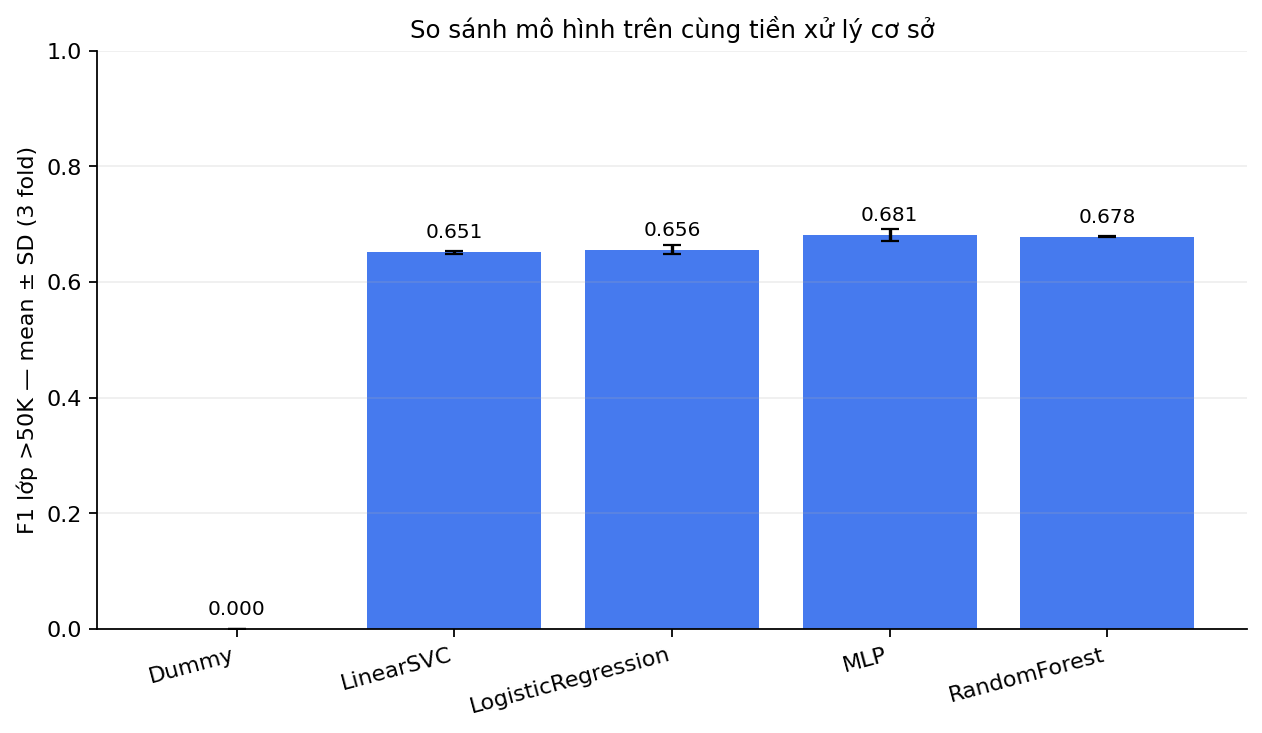

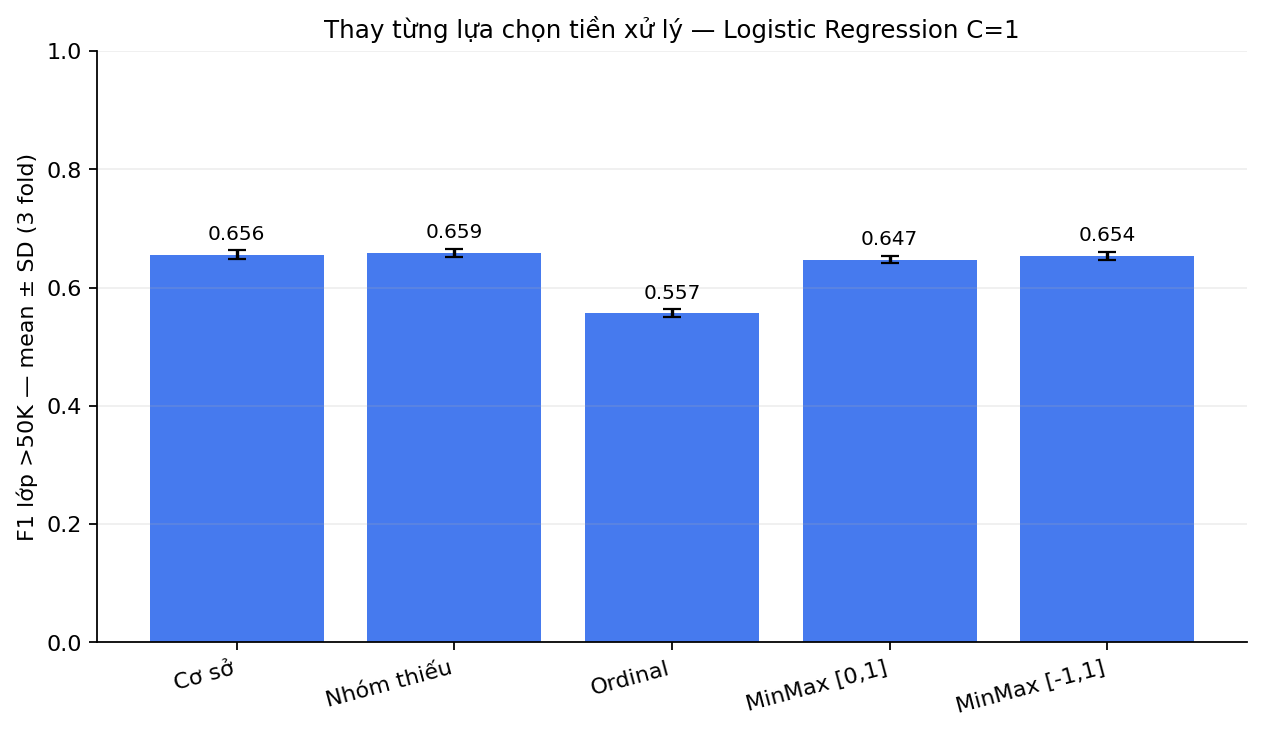

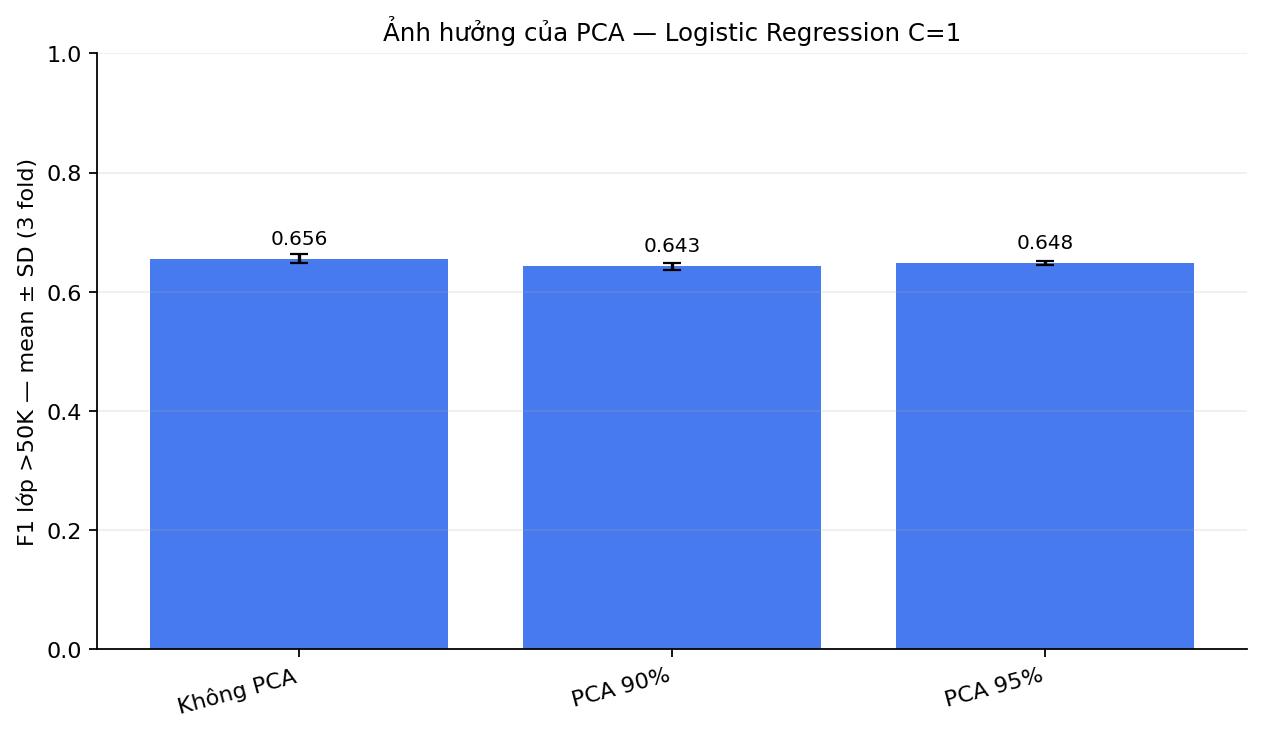

In [39]:
# 39. Biểu đồ mô hình, lựa chọn tiền xử lý và PCA — kết quả CV.
for stem in training.plot_experiments(STEP05_DIR):
    display(Image(filename=str(STEP05_DIR / f"{stem}.png")))


### Cập nhật nguồn báo cáo
Bổ sung lý thuyết mô hình/chỉ số, phần huấn luyện, thiết kế thí nghiệm và kết quả CV/validation. Các mục đánh giá test ở chương 6 và kết luận chương 7 tiếp tục ở bước 6–7.


In [40]:
# 40. Cập nhật LaTeX bằng số liệu đã chạy và tạo ZIP báo cáo.
experiment_report.update_experiment_report(STEP05_DIR, REPORT_ROOT)
LATEX_ZIP = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_5.zip"
with ZipFile(LATEX_ZIP, "w", compression=ZIP_DEFLATED) as archive:
    for path in sorted(REPORT_ROOT.rglob("*")):
        if path.is_file():
            archive.write(path, path.relative_to(REPORT_ROOT).as_posix())
previous_zip = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_4.zip"
if previous_zip.is_file():
    previous_zip.unlink()
print("LaTeX đã cập nhật:", LATEX_ZIP)
print("Hoàn thành bước 5/7; mô hình và ngưỡng đã khóa cho đánh giá test ở bước 6.")


LaTeX đã cập nhật: C:\Users\Acer\Documents\Codex\2026-11-21\new-chat\BTL_ML_Final\reports\BTL_ML_LaTeX_Buoc_5.zip
Hoàn thành bước 5/7; mô hình và ngưỡng đã khóa cho đánh giá test ở bước 6.


# Bước 6 — Đánh giá mô hình trên tập test

Sử dụng pipeline được chọn bằng CV và ngưỡng đã khóa để đánh giá toàn bộ 16.281 mẫu test UCI. Kết quả gồm các chỉ số phân loại, ma trận nhầm lẫn, đường ROC/PR và phân tích lỗi.

Pipeline được lưu ở `artifacts/final/`. Phần đánh giá kiểm tra trạng thái mô hình và dấu vân tay dữ liệu trước khi thực thi.


In [41]:
#@title 41. Chuẩn bị module đánh giá test và cập nhật báo cáo
STEP06_SOURCES = {'evaluation.py': '"""Đánh giá một snapshot đã khóa; module này không gọi fit hoặc chọn ngưỡng."""\nfrom pathlib import Path\nimport hashlib,json,platform,shutil\nimport numpy as np\nimport pandas as pd\nimport joblib,sklearn\nfrom sklearn.metrics import (confusion_matrix,classification_report,accuracy_score,\n    precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,\n    balanced_accuracy_score,roc_curve,precision_recall_curve)\nfrom threadpoolctl import threadpool_limits\nfrom .preprocessing import FEATURE_COLUMNS,encode_target,normalize_config\nfrom .splitting import frame_fingerprint,make_group_ids\n\nLABELS=[\'<=50K\',\'>50K\']\n\ndef _sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()\ndef _json(path,obj):\n    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)\n    path.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding=\'utf-8\')\ndef _digest(obj):return hashlib.sha256(json.dumps(obj,sort_keys=True,separators=(\',\',\':\'),ensure_ascii=False).encode(\'utf-8\')).hexdigest()\ndef _source_hashes(root):\n    return {name:hashlib.sha256((root/\'modules\'/name).read_text(encoding=\'utf-8\').encode(\'utf-8\')).hexdigest()\n        for name in [\'data_loader.py\',\'splitting.py\',\'preprocessing.py\',\'training.py\']}\n\ndef freeze_selection(project_dir=\'.\'):\n    """Giữ snapshot trước khi đọc kết quả test; không thay snapshot khi chạy lại."""\n    root=Path(project_dir)\n    selected=json.loads((root/\'results/step_05/selected_model.json\').read_text(encoding=\'utf-8\'))\n    if selected[\'validation_used_for_selection\'] or selected[\'threshold_tuned\'] or selected[\'refit_on_train_plus_validation\']:\n        raise ValueError(\'Lựa chọn bước 5 không khớp giao thức đã khóa.\')\n    cfgs=json.loads((root/\'configs/experiments.json\').read_text(encoding=\'utf-8\'))\n    candidate=next(c for c in cfgs[\'candidates\'] if c[\'id\']==selected[\'winner_id\'])\n    identity={\'winner_id\':selected[\'winner_id\'],\'training_data_sha256\':selected[\'training_data_sha256\'],\n        \'validation_data_sha256\':selected[\'validation_data_sha256\'],\n        \'cv_manifest_sha256\':selected[\'cv_manifest_sha256\'],\'candidates_sha256\':selected[\'candidates_sha256\'],\n        \'candidate\':candidate,\'refit_rows\':selected[\'refit_rows\'],\n        \'source_hashes\':_source_hashes(root)}\n    out=root/\'artifacts/final\';lock_path=out/\'selection_snapshot.json\'\n    if lock_path.exists():\n        locked=json.loads(lock_path.read_text(encoding=\'utf-8\'))\n        if locked[\'identity\']!=identity:raise ValueError(\'Snapshot đã khóa khác lựa chọn/dữ liệu/mã nguồn hiện tại; không tự đổi mô hình sau test.\')\n        if _sha(root/locked[\'pipeline_path\'])!=locked[\'pipeline_sha256\']:raise ValueError(\'Pipeline snapshot đã bị thay đổi.\')\n        return locked\n    out.mkdir(parents=True,exist_ok=True)\n    original=root/selected[\'selected_model_path\']\n    pipeline=joblib.load(original)\n    if list(pipeline.named_steps[\'model\'].classes_)!=[0,1]:raise ValueError(\'Sai thứ tự hai lớp.\')\n    if pipeline.named_steps[\'preprocessing\'].named_steps[\'input\'].fit_rows_!=selected[\'refit_rows\']:\n        raise ValueError(\'Pipeline không được fit trên số dòng train đã khóa.\')\n    probability=hasattr(pipeline,\'predict_proba\')\n    target=out/\'selected_pipeline.joblib\';shutil.copyfile(original,target)\n    locked={\'schema_version\':1,\'identity\':identity,\'pipeline_path\':target.relative_to(root).as_posix(),\n        \'pipeline_sha256\':_sha(target),\'pipeline_state_hash\':joblib.hash(pipeline),\n        \'source_model_path\':selected[\'selected_model_path\'],\'source_model_sha256\':_sha(original),\n        \'threshold\':0.5 if probability else 0.0,\n        \'score_kind\':\'probability\' if probability else \'decision_score\',\n        \'prediction_rule\':\'native estimator predict; no threshold tuning\',\n        \'preprocessing\':normalize_config(candidate[\'preprocessing\']),\n        \'stage_05_selection\':selected,\'versions\':selected[\'versions\'],\n        \'created_before_test_evaluation\':True}\n    _json(lock_path,locked)\n    return locked\n\ndef summarize_predictions(y,pred,score):\n    y=np.asarray(y);pred=np.asarray(pred);score=np.asarray(score,dtype=float)\n    if y.ndim!=1 or pred.shape!=y.shape or score.shape!=y.shape or len(y)==0:\n        raise ValueError(\'Nhãn, dự đoán và score phải cùng chiều và không rỗng.\')\n    if set(np.unique(y))!={0,1} or not set(np.unique(pred)).issubset({0,1}) or not np.isfinite(score).all():\n        raise ValueError(\'Cần hai lớp thật 0/1, dự đoán nhị phân và score hữu hạn.\')\n    cm=confusion_matrix(y,pred,labels=[0,1]);tn,fp,fn,tp=map(int,cm.ravel())\n    specificity=tn/(tn+fp);fpr=fp/(tn+fp);fnr=fn/(tp+fn)\n    metrics={\'accuracy\':float(accuracy_score(y,pred)),\n        \'precision\':float(precision_score(y,pred,pos_label=1,zero_division=0)),\n        \'recall\':float(recall_score(y,pred,pos_label=1,zero_division=0)),\n        \'f1\':float(f1_score(y,pred,pos_label=1,zero_division=0)),\n        \'macro_f1\':float(f1_score(y,pred,average=\'macro\',zero_division=0)),\n        \'roc_auc\':float(roc_auc_score(y,score)),\n        \'average_precision\':float(average_precision_score(y,score)),\n        \'specificity\':float(specificity),\'false_positive_rate\':float(fpr),\'false_negative_rate\':float(fnr),\n        \'balanced_accuracy\':float(balanced_accuracy_score(y,pred)),\n        \'positive_prevalence\':float(y.mean()),\'error_rate\':float(np.mean(y!=pred))}\n    counts={\'tn\':tn,\'fp\':fp,\'fn\':fn,\'tp\':tp,\'rows\':len(y),\'positive_rows\':int(y.sum()),\'negative_rows\':int((y==0).sum()),\'error_rows\':fp+fn}\n    return metrics,counts,cm\n\ndef evaluate_frozen(test,test_metadata,project_dir=\'.\'):\n    """Chỉ dự đoán test với pipeline cố định; replay kết quả nếu cùng snapshot/data."""\n    root=Path(project_dir);out=root/\'results/step_06\';out.mkdir(parents=True,exist_ok=True)\n    locked=freeze_selection(root)\n    if len(test)!=16281 or len(test_metadata)!=len(test):raise ValueError(\'Phải giữ đủ 16.281 dòng test UCI gốc.\')\n    if test.columns.tolist()!=FEATURE_COLUMNS+[\'income\']:raise ValueError(\'Sai schema test.\')\n    if not (test_metadata[\'source_file\']==\'adult.test\').all() or not test_metadata[\'source_id\'].is_unique:\n        raise ValueError(\'Metadata không phải tập adult.test gốc hoặc trùng ID.\')\n    np.testing.assert_array_equal(test_metadata[\'source_row\'].to_numpy(),np.arange(len(test)))\n    if sklearn.__version__!=locked[\'versions\'][\'sklearn\']:\n        raise ValueError(\'Phiên bản scikit-learn khác snapshot; không đánh giá trực tiếp một pickle khác phiên bản.\')\n    source_sha=hashlib.sha256(Path(__file__).read_text(encoding=\'utf-8\').encode(\'utf-8\')).hexdigest()\n    identity={\'test_data_sha256\':frame_fingerprint(test),\'test_source_ids_sha256\':_digest(test_metadata.source_id.astype(str).tolist()),\n        \'selection_snapshot_sha256\':_digest(locked),\'pipeline_sha256\':locked[\'pipeline_sha256\'],\n        \'evaluation_source_sha256\':source_sha,\'sklearn\':sklearn.__version__,\'numpy\':np.__version__}\n    complete=out/\'evaluation_complete.json\'\n    if complete.exists():\n        prior=json.loads(complete.read_text(encoding=\'utf-8\'))\n        if prior[\'identity\']!=identity:raise ValueError(\'Đã có đánh giá test với dữ liệu/model/code khác; không tự ghi đè hoặc đánh giá lại để chọn cấu hình.\')\n        for rel,sha in prior[\'files\'].items():\n            if _sha(root/rel)!=sha:raise ValueError(\'Kết quả đánh giá đã bị thay đổi: \'+rel)\n        print(\'Đọc kết quả test đã xác minh cho cùng snapshot và dữ liệu; không dự đoán lại.\')\n        return json.loads((out/\'test_metrics.json\').read_text(encoding=\'utf-8\'))\n    pipeline=joblib.load(root/locked[\'pipeline_path\'])\n    before=joblib.hash(pipeline)\n    if before!=locked[\'pipeline_state_hash\']:raise ValueError(\'Trạng thái pipeline khác lúc khóa.\')\n    X=test[FEATURE_COLUMNS];y=encode_target(test);snapshot=test.copy(deep=True)\n    with threadpool_limits(limits=2):\n        pred=pipeline.predict(X)\n        if locked[\'score_kind\']==\'probability\':score=np.asarray(pipeline.predict_proba(X)[:,1],dtype=float)\n        else:score=np.asarray(pipeline.decision_function(X),dtype=float)\n    if joblib.hash(pipeline)!=before or _sha(root/locked[\'pipeline_path\'])!=locked[\'pipeline_sha256\']:\n        raise AssertionError(\'Đánh giá làm thay đổi snapshot fitted.\')\n    pd.testing.assert_frame_equal(test,snapshot)\n    metrics,counts,cm=summarize_predictions(y,pred,score)\n    np.testing.assert_array_equal(pred,(score>locked[\'threshold\']).astype(np.int8))\n    frame=pd.DataFrame({\'source_id\':test_metadata.source_id.to_numpy(),\n        \'source_row\':test_metadata.source_row.to_numpy(),\'y_true\':y,\'y_pred\':pred,\'score\':score})\n    frame[\'outcome\']=np.select([(y==0)&(pred==0),(y==0)&(pred==1),(y==1)&(pred==0)],[\'TN\',\'FP\',\'FN\'],default=\'TP\')\n    frame.to_csv(out/\'test_predictions.csv\',index=False)\n    pd.DataFrame(cm,index=LABELS,columns=LABELS).rename_axis(\'actual\').to_csv(out/\'confusion_matrix.csv\')\n    pd.DataFrame([metrics]).to_csv(out/\'test_metrics.csv\',index=False)\n    report=classification_report(y,pred,labels=[0,1],target_names=LABELS,output_dict=True,zero_division=0)\n    _json(out/\'classification_report.json\',report)\n    class_table=pd.DataFrame([{**report[label],\'class\':label} for label in LABELS])[[\'class\',\'precision\',\'recall\',\'f1-score\',\'support\']]\n    class_table.to_csv(out/\'classification_report.csv\',index=False)\n    fpr,tpr,roc_thresholds=roc_curve(y,score,pos_label=1)\n    pd.DataFrame({\'false_positive_rate\':fpr,\'true_positive_rate\':tpr,\'threshold\':roc_thresholds}).to_csv(out/\'roc_curve.csv\',index=False)\n    precision,recall,pr_thresholds=precision_recall_curve(y,score,pos_label=1)\n    pd.DataFrame({\'precision\':precision,\'recall\':recall,\'threshold\':np.r_[pr_thresholds,np.nan]}).to_csv(out/\'precision_recall_curve.csv\',index=False)\n    result={\'winner_id\':locked[\'identity\'][\'winner_id\'],\'threshold\':locked[\'threshold\'],\'score_kind\':locked[\'score_kind\'],\n        \'metrics\':metrics,\'counts\':counts,\'identity\':identity,\'pipeline_fitted_state_unchanged\':True,\n        \'test_frame_unchanged\':True,\'test_evaluation_used_for_tuning\':False,\'classifier_refit_in_evaluation\':False,\n        \'versions\':{\'python\':platform.python_version(),\'sklearn\':sklearn.__version__,\'numpy\':np.__version__,\'pandas\':pd.__version__}}\n    _json(out/\'test_metrics.json\',result)\n    paths=[out/name for name in [\'test_predictions.csv\',\'confusion_matrix.csv\',\'test_metrics.csv\',\'test_metrics.json\',\n        \'classification_report.csv\',\'classification_report.json\',\'roc_curve.csv\',\'precision_recall_curve.csv\']]\n    _json(complete,{\'identity\':identity,\'evaluation_runs\':1,\n        \'files\':{p.relative_to(root).as_posix():_sha(p) for p in paths}})\n    return result\n\ndef analyze_errors(test,test_metadata,project_dir=\'.\'):\n    root=Path(project_dir);out=root/\'results/step_06\'\n    result=json.loads((out/\'test_metrics.json\').read_text(encoding=\'utf-8\'))\n    if frame_fingerprint(test)!=result[\'identity\'][\'test_data_sha256\']:raise ValueError(\'Dữ liệu phân tích khác tập test đã đánh giá.\')\n    pred=pd.read_csv(out/\'test_predictions.csv\')\n    if pred.source_id.tolist()!=test_metadata.source_id.tolist():raise ValueError(\'Dự đoán không khớp metadata.\')\n    detailed=pd.concat([pred.reset_index(drop=True),test[FEATURE_COLUMNS].reset_index(drop=True)],axis=1)\n    errors=detailed[detailed.y_true!=detailed.y_pred].copy()\n    errors.to_csv(out/\'test_errors.csv\',index=False)\n    examples=pd.concat([\n        errors[errors.outcome==\'FP\'].sort_values([\'score\',\'source_row\'],ascending=[False,True]).head(5),\n        errors[errors.outcome==\'FN\'].sort_values([\'score\',\'source_row\'],ascending=[True,True]).head(5),\n    ],ignore_index=True)\n    examples.to_csv(out/\'error_examples.csv\',index=False)\n    numeric=[\'age\',\'education-num\',\'hours-per-week\',\'capital-gain\',\'capital-loss\']\n    profile=detailed.groupby(\'outcome\',sort=True)[numeric].median().add_suffix(\'_median\')\n    profile.insert(0,\'rows\',detailed.groupby(\'outcome\').size())\n    profile.to_csv(out/\'outcome_numeric_profiles.csv\')\n    return examples,profile\n\ndef audit_test_profile_overlap(train,validation,test,project_dir=\'.\'):\n    """Chỉ chẩn đoán sau khi đã khóa/đánh giá; không bỏ dòng hay đổi mô hình."""\n    root=Path(project_dir);out=root/\'results/step_06\'\n    if not (out/\'evaluation_complete.json\').exists():raise ValueError(\'Chỉ chạy chẩn đoán sau đánh giá đã khóa.\')\n    groups=make_group_ids(test);tr=set(make_group_ids(train));va=set(make_group_ids(validation))\n    in_train=np.array([g in tr for g in groups]);in_val=np.array([g in va for g in groups])\n    result={\'input_columns\':FEATURE_COLUMNS,\'label_in_group_key\':False,\n        \'test_rows\':len(test),\'unique_test_profiles\':len(set(groups)),\n        \'test_rows_matching_train_profile\':int(in_train.sum()),\n        \'test_profiles_matching_train\':len(set(groups[in_train])),\n        \'test_rows_matching_validation_profile\':int(in_val.sum()),\n        \'test_profiles_matching_validation\':len(set(groups[in_val])),\n        \'rows_removed\':0,\'used_for_model_or_threshold_selection\':False,\n        \'interpretation\':\'Identical 14-feature records, not proof of same real person; original UCI test remains unchanged.\'}\n    _json(out/\'test_profile_overlap.json\',result)\n    return result\n\ndef plot_evaluation(result_dir=\'results/step_06\'):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    root=Path(result_dir);result=json.loads((root/\'test_metrics.json\').read_text(encoding=\'utf-8\'))\n    metrics=result[\'metrics\'];cm=pd.read_csv(root/\'confusion_matrix.csv\',index_col=0).to_numpy()\n    def save(fig,stem):\n        fig.tight_layout()\n        for ext in [\'png\',\'pdf\']:fig.savefig(root/f\'{stem}.{ext}\',dpi=165,bbox_inches=\'tight\')\n        plt.close(fig)\n    fig,axes=plt.subplots(1,2,figsize=(10,4.3))\n    for ax,values,title,percent in [(axes[0],cm,\'Số mẫu\',False),\n            (axes[1],cm/cm.sum(axis=1,keepdims=True)*100,\'Tỷ lệ theo nhãn thật (%)\',True)]:\n        ax.imshow(values,cmap=\'Blues\',vmin=0,vmax=100 if percent else cm.max())\n        for i in range(2):\n            for j in range(2):\n                value=values[i,j];text=f\'{value:.1f}%\' if percent else f\'{value:.0f}\'\n                ax.text(j,i,text,ha=\'center\',va=\'center\',fontsize=14,color=\'white\' if value>values.max()/2 else \'black\')\n        ax.set_xticks([0,1],LABELS);ax.set_yticks([0,1],LABELS)\n        ax.set(xlabel=\'Nhãn dự đoán\',ylabel=\'Nhãn thật\',title=title)\n    fig.suptitle(\'Ma trận nhầm lẫn trên test UCI — mô hình và ngưỡng đã khóa\')\n    save(fig,\'test_confusion_matrix\')\n    roc=pd.read_csv(root/\'roc_curve.csv\');fig,ax=plt.subplots(figsize=(6,5))\n    ax.plot(roc.false_positive_rate,roc.true_positive_rate,color=\'#2563EB\',label=f"ROC-AUC = {metrics[\'roc_auc\']:.4f}")\n    ax.plot([0,1],[0,1],\'--\',color=\'#64748B\',label=\'Đường tham chiếu ngẫu nhiên\')\n    ax.scatter([metrics[\'false_positive_rate\']],[metrics[\'recall\']],color=\'#EA580C\',zorder=4,label=\'Ngưỡng đã khóa\')\n    ax.set(xlim=(0,1),ylim=(0,1.02),xlabel=\'False positive rate\',ylabel=\'True positive rate (recall)\',title=\'ROC trên test — lớp dương >50K\')\n    ax.grid(alpha=.2);ax.legend(loc=\'lower right\');save(fig,\'test_roc\')\n    pr=pd.read_csv(root/\'precision_recall_curve.csv\');fig,ax=plt.subplots(figsize=(6,5))\n    ax.step(pr.recall,pr.precision,where=\'post\',color=\'#2563EB\',label=f"Average precision = {metrics[\'average_precision\']:.4f}")\n    ax.axhline(metrics[\'positive_prevalence\'],linestyle=\'--\',color=\'#64748B\',label=f"Tỷ lệ lớp dương = {metrics[\'positive_prevalence\']:.3f}")\n    ax.scatter([metrics[\'recall\']],[metrics[\'precision\']],color=\'#EA580C\',zorder=4,label=\'Ngưỡng đã khóa\')\n    ax.set(xlim=(0,1),ylim=(0,1.02),xlabel=\'Recall\',ylabel=\'Precision\',title=\'Precision–Recall trên test — lớp dương >50K\')\n    ax.grid(alpha=.2);ax.legend(loc=\'lower left\');save(fig,\'test_precision_recall\')\n    return [\'test_confusion_matrix\',\'test_roc\',\'test_precision_recall\']\n', 'test_report.py': '"""Bổ sung báo cáo từ kết quả test cố định, không tính hoặc chọn lại mô hình."""\nfrom pathlib import Path\nimport json,shutil\nimport pandas as pd\n\ndef update_test_report(result_dir=\'results/step_06\',report_root=\'reports/latex\'):\n    result=Path(result_dir);report=Path(report_root)\n    data=json.loads((result/\'test_metrics.json\').read_text(encoding=\'utf-8\'))\n    overlap=json.loads((result/\'test_profile_overlap.json\').read_text(encoding=\'utf-8\'))\n    metric=data[\'metrics\'];count=data[\'counts\']\n    def n(value):return f\'{int(value):,}\'.replace(\',\',\'.\')\n    def dec(value):return f\'{float(value):.4f}\'.replace(\'.\',\',\')\n    def pct(value):return f\'{float(value)*100:.2f}\'.replace(\'.\',\',\')\n    def esc(value):return str(value).replace(\'_\',r\'\\_\').replace(\'%\',r\'\\%\')\n    def write(folder,prefix,text):\n        matches=list((report/folder).glob(prefix+\'*.tex\'))\n        if len(matches)!=1:raise ValueError((folder,prefix,matches))\n        matches[0].write_text(text,encoding=\'utf-8\')\n    c6=\'chapters/chapter_6\'\n    dest=report/\'Images/chapter_6/6_5/6_5_2\';dest.mkdir(parents=True,exist_ok=True)\n    for stem in [\'test_confusion_matrix\',\'test_roc\',\'test_precision_recall\']:\n        for ext in [\'png\',\'pdf\']:shutil.copyfile(result/f\'{stem}.{ext}\',dest/f\'{stem}.{ext}\')\n    write(c6,\'6_5_danh_\',r\'\'\'\\section{Đánh giá mô hình đã chọn trên tập kiểm tra}\n\\label{sec:6_5}\nMô hình được đánh giá là \\texttt{\'\'\'+esc(data[\'winner_id\'])+r\'\'\'}, MLP một lớp ẩn 32 nút với $\\alpha=0{,}01$, đã được chọn bằng F1 CV ở bước 5. Đầu vào dùng median, mode, one-hot và StandardScaler trên sáu biến số, không PCA. Mô hình đã fit trên 26.049 mẫu train; không fit thêm bằng validation hoặc test. Ngưỡng xác suất lớp \\texttt{>50K} giữ nguyên ở 0,5.\n\nTrước khi đánh giá, pipeline và thông tin lựa chọn được sao lưu cố định ở \\texttt{artifacts/final/}. SHA-256 và trạng thái fitted được kiểm tra trước/sau dự đoán. Module đánh giá không gọi fit, không tìm ngưỡng tối ưu và không so sánh thêm các mô hình trên test để đổi lựa chọn. Lần chạy lại với cùng snapshot và dữ liệu đọc kết quả đã xác minh thay vì mở một thí nghiệm lựa chọn mới.\n\nTập test là toàn bộ 16.281 dòng \\texttt{adult.test} gốc sau khi chuẩn hóa định dạng như bước 1, gồm \'\'\'+n(count[\'negative_rows\'])+r\'\'\' mẫu \\texttt{<=50K} và \'\'\'+n(count[\'positive_rows\'])+r\'\'\' mẫu \\texttt{>50K}. Mã hóa nhãn không thay số dòng hay thứ tự. Các mục dưới đây trình bày kết quả test; không gộp chúng với điểm CV/validation.\n\n\\input{chapters/chapter_6/6_5_1_cac_chi_so_danh_gia}\n\\input{chapters/chapter_6/6_5_2_ma_tran_nham_lan_va_duong_cong_danh_gia}\n\'\'\')\n    table=[r\'\\begin{table}[htbp]\',r\'\\centering\\small\',r\'\\caption{Các chỉ số trên toàn bộ tập test với ngưỡng đã khóa}\\label{tab:test-metrics}\',\n           r\'\\begin{tabular}{lr}\',r\'\\toprule\',r\'Chỉ số & Giá trị \\\\\',r\'\\midrule\']\n    for title,key in [(\'Accuracy\',\'accuracy\'),(\'Precision lớp >50K\',\'precision\'),(\'Recall lớp >50K\',\'recall\'),(\'F1 lớp >50K\',\'f1\'),\n                      (\'Macro-F1\',\'macro_f1\'),(\'ROC-AUC\',\'roc_auc\'),(\'Average precision (AP)\',\'average_precision\'),\n                      (\'Specificity\',\'specificity\'),(\'False positive rate (FPR)\',\'false_positive_rate\'),\n                      (\'False negative rate (FNR)\',\'false_negative_rate\'),(\'Balanced accuracy\',\'balanced_accuracy\')]:\n        table.append(title+\' & \'+dec(metric[key])+r\' \\\\\')\n    table += [r\'\\bottomrule\',r\'\\end{tabular}\',r\'\\end{table}\']\n    perclass=pd.read_csv(result/\'classification_report.csv\')\n    class_lines=[r\'\\begin{table}[htbp]\',r\'\\centering\\small\',r\'\\caption{Kết quả test theo từng lớp}\\label{tab:test-per-class}\',\n                 r\'\\begin{tabular}{lrrrr}\',r\'\\toprule\',r\'Lớp & Precision & Recall & F1 & Số mẫu \\\\\',r\'\\midrule\']\n    for _,r in perclass.iterrows():\n        class_lines.append(r\'\\texttt{\'+r[\'class\']+\'} & \'+\' & \'.join(dec(r[k]) for k in [\'precision\',\'recall\',\'f1-score\'])+\' & \'+n(r.support)+r\' \\\\\')\n    class_lines += [r\'\\bottomrule\',r\'\\end{tabular}\',r\'\\end{table}\']\n    write(c6,\'6_5_1_\',r\'\'\'\\subsection{Các chỉ số đánh giá}\n\\label{subsec:6_5_1}\nCác chỉ số được tính từ nhãn test và dự đoán cố định; lớp dương là \\texttt{>50K}. Accuracy đạt \'\'\'+pct(metric[\'accuracy\'])+r\'\'\'\\%, nhưng recall lớp dương chỉ đạt \'\'\'+pct(metric[\'recall\'])+r\'\'\'\\%. Vì vậy, tỷ lệ dự đoán đúng tổng thể không đủ để mô tả khả năng nhận diện nhóm thu nhập cao.\n\n\'\'\'+ \'\\n\'.join(table)+\'\\n\'+ \'\\n\'.join(class_lines)+r\'\'\'\nPrecision \'\'\'+dec(metric[\'precision\'])+r\'\'\' và recall \'\'\'+dec(metric[\'recall\'])+r\'\'\' cho thấy tại ngưỡng 0,5 mô hình vẫn bỏ sót một phần mẫu dương. Specificity bằng \'\'\'+dec(metric[\'specificity\'])+r\'\'\' mô tả tỷ lệ nhận diện đúng lớp âm; FPR bằng \'\'\'+dec(metric[\'false_positive_rate\'])+r\'\'\' là tỷ lệ mẫu âm bị dự đoán thành dương. Macro-F1 và balanced accuracy cho mỗi lớp vai trò cân bằng hơn so với accuracy tổng thể.\n\nROC-AUC và AP sử dụng score lớp dương để đánh giá thứ hạng qua nhiều ngưỡng. AP là tổng có trọng số theo bước tăng recall, không được đồng nhất với diện tích PR tính bằng quy tắc hình thang~\\cite{sklearn-ap}. Không dùng các đường cong test để chọn lại ngưỡng.\n\'\'\')\n    write(c6,\'6_5_2_\',r\'\'\'\\subsection{Ma trận nhầm lẫn và đường cong đánh giá}\n\\label{subsec:6_5_2}\nHàng của ma trận là nhãn thật, cột là nhãn dự đoán; thứ tự lớp là \\texttt{<=50K}, \\texttt{>50K}. Với quy ước này, ma trận có dạng $\\left[\\begin{smallmatrix}TN&FP\\\\FN&TP\\end{smallmatrix}\\right]$~\\cite{sklearn-cm}. Kết quả gồm TN=\'\'\'+n(count[\'tn\'])+\', FP=\'+n(count[\'fp\'])+\', FN=\'+n(count[\'fn\'])+\' và TP=\'+n(count[\'tp\'])+r\'\'\'.\n\n\\begin{figure}[htbp]\n\\centering\n\\includegraphics[width=.98\\textwidth]{Images/chapter_6/6_5/6_5_2/test_confusion_matrix.pdf}\n\\caption{Ma trận nhầm lẫn: số mẫu và tỷ lệ chuẩn hóa theo hàng}\\label{fig:test-cm}\n\\end{figure}\n\n\\begin{figure}[htbp]\n\\centering\n\\begin{minipage}{.49\\textwidth}\\centering\n\\includegraphics[width=\\linewidth]{Images/chapter_6/6_5/6_5_2/test_roc.pdf}\n\\end{minipage}\\hfill\n\\begin{minipage}{.49\\textwidth}\\centering\n\\includegraphics[width=\\linewidth]{Images/chapter_6/6_5/6_5_2/test_precision_recall.pdf}\n\\end{minipage}\n\\caption{Đường ROC và Precision--Recall trên test; chấm đánh dấu là ngưỡng 0,5 đã khóa}\\label{fig:test-curves}\n\\end{figure}\n\nMẫu bỏ sót FN chiếm \'\'\'+pct(metric[\'false_negative_rate\'])+r\'\'\'\\% số mẫu dương, trong khi FP chiếm \'\'\'+pct(metric[\'false_positive_rate\'])+r\'\'\'\\% số mẫu âm. Tỷ lệ lớp dương trên test là \'\'\'+pct(metric[\'positive_prevalence\'])+r\'\'\'\\%, được vẽ làm đường tham chiếu trên biểu đồ PR. Các đường cong mô tả sự đánh đổi nếu thay ngưỡng; bài làm giữ nguyên điểm vận hành đã chọn trước khi xem test.\n\'\'\')\n    examples=pd.read_csv(result/\'error_examples.csv\')\n    lines=[r\'\\begin{table}[htbp]\',r\'\\centering\\scriptsize\',r\'\\caption{Một số bản ghi dự đoán sai được chọn theo score}\\label{tab:test-error-examples}\',\n           r\'\\begin{tabular}{lrrrrr}\',r\'\\toprule\',r\'Dòng test & Loại & Tuổi & education-num & Giờ/tuần & Score >50K \\\\\',r\'\\midrule\']\n    for _,r in examples.iterrows():\n        lines.append(str(int(r.source_row)+1)+\' & \'+r.outcome+\' & \'+str(int(r.age))+\' & \'+str(int(r[\'education-num\']))+\' & \'+str(int(r[\'hours-per-week\']))+\' & \'+dec(r.score)+r\' \\\\\')\n    lines += [r\'\\bottomrule\',r\'\\end{tabular}\',r\'\\end{table}\']\n    profile=pd.read_csv(result/\'outcome_numeric_profiles.csv\').set_index(\'outcome\')\n    profiles=[r\'\\begin{table}[htbp]\',r\'\\centering\\small\',r\'\\caption{Trung vị một số thuộc tính theo nhóm kết quả test}\\label{tab:test-error-profiles}\',\n              r\'\\begin{tabular}{lrrrr}\',r\'\\toprule\',r\'Nhóm & Số mẫu & Tuổi & education-num & Giờ/tuần \\\\\',r\'\\midrule\']\n    for name in [\'TN\',\'FP\',\'FN\',\'TP\']:\n        r=profile.loc[name]\n        profiles.append(name+\' & \'+n(r[\'rows\'])+\' & \'+\' & \'.join(f\'{r[k]:g}\'.replace(\'.\',\',\') for k in [\'age_median\',\'education-num_median\',\'hours-per-week_median\'])+r\' \\\\\')\n    profiles += [r\'\\bottomrule\',r\'\\end{tabular}\',r\'\\end{table}\']\n    write(c6,\'6_6_\',r\'\'\'\\section{Phân tích các trường hợp dự đoán sai}\n\\label{sec:6_6}\nMô hình dự đoán sai \'\'\'+n(count[\'error_rows\'])+r\'\'\' mẫu, tương đương \'\'\'+pct(metric[\'error_rate\'])+r\'\'\'\\% tập test, gồm \'\'\'+n(count[\'fp\'])+r\'\'\' FP và \'\'\'+n(count[\'fn\'])+r\'\'\' FN. FP là nhãn thật \\texttt{<=50K} nhưng dự đoán \\texttt{>50K}; FN là trường hợp ngược lại. Toàn bộ các bản ghi sai và 14 thuộc tính gốc được lưu trong \\texttt{results/step\\_06/test\\_errors.csv}.\n\nĐể xem trường hợp cụ thể, chọn tối đa năm FP có score lớn nhất và năm FN có score nhỏ nhất, phá hòa bằng chỉ số dòng. Đây là các ví dụ được chọn có chủ đích theo score, không đại diện ngẫu nhiên cho toàn bộ lỗi. Cột ``Dòng test\'\' đếm từ 1 trong dữ liệu đã parse, không tính dòng chú thích và dòng trống của tệp gốc.\n\n\'\'\'+ \'\\n\'.join(lines)+\'\\n\'+ \'\\n\'.join(profiles)+r\'\'\'\nCác trung vị chỉ mô tả nhóm kết quả, không chứng minh một thuộc tính gây ra lỗi và không thay thế phân tích tầm quan trọng đặc trưng. Score từ MLP chưa được kiểm định hiệu chỉnh xác suất, nên một giá trị lớn/nhỏ không được diễn giải thành mức chắc chắn đã được đảm bảo. Không thay đổi mô hình, tiền xử lý hoặc ngưỡng dựa trên các ví dụ test này.\n\'\'\')\n    cv=pd.read_csv(result.parent/\'step_05/cv_summary.csv\').set_index(\'candidate_id\').loc[data[\'winner_id\']]\n    val=pd.read_csv(result.parent/\'step_05/validation_summary.csv\').set_index(\'candidate_id\').loc[data[\'winner_id\']]\n    write(c6,\'6_7_\',r\'\'\'\\section{Nhận xét tổng hợp về các kết quả}\n\\label{sec:6_7}\nTrong phạm vi tìm kiếm đã thực hiện, MLP 32 nút được khóa bằng F1 CV trung bình \'\'\'+dec(cv.f1_mean)+r\'\'\' với SD \'\'\'+dec(cv.f1_std)+r\'\'\'. F1 validation là \'\'\'+dec(val.f1)+r\'\'\' và F1 test là \'\'\'+dec(metric[\'f1\'])+r\'\'\'. Đây là ba giai đoạn có vai trò khác nhau; không chọn giá trị lớn nhất giữa chúng để gọi là kết quả cuối. Test đạt accuracy \'\'\'+pct(metric[\'accuracy\'])+r\'\'\'\\% và ROC-AUC \'\'\'+dec(metric[\'roc_auc\'])+r\'\'\', trong khi recall lớp thu nhập cao \'\'\'+pct(metric[\'recall\'])+r\'\'\'\\% vẫn là hạn chế tại ngưỡng 0,5.\n\nSau khi đã khóa và đánh giá, đối chiếu 14 thuộc tính đầu vào phát hiện \'\'\'+n(overlap[\'test_rows_matching_train_profile\'])+r\'\'\' dòng test có hồ sơ trùng train và \'\'\'+n(overlap[\'test_rows_matching_validation_profile\'])+r\'\'\' dòng test có hồ sơ trùng validation. Nhãn income không tham gia tạo khóa nhóm. Việc trùng thuộc tính không khẳng định chắc chắn cùng một người thực. Toàn bộ 16.281 mẫu test UCI vẫn được giữ trong phép đánh giá; không loại các dòng trùng sau khi thấy kết quả và không báo cáo tập test như đã được bảo đảm tách biệt tuyệt đối theo hồ sơ đầu vào.\n\nCác kết quả dựa trên lưới siêu tham số giới hạn, ba fold và một seed; tìm kiếm MLP được mở rộng sau pilot do cảnh báo tối ưu và đã được ghi lại. Chưa có kiểm định nhiều seed, khoảng tin cậy, đánh giá hiệu chỉnh xác suất hoặc bảo đảm tổng quát hóa sang quần thể khác. Tập test đã được sử dụng ở bước 6 nên không tiếp tục dùng nó để tinh chỉnh cấu hình rồi trình bày như dữ liệu đánh giá chưa thấy.\n\nBước 6 hoàn tất phần đánh giá mô hình đã khóa. Chương kết luận, tóm tắt, kiểm tra trình bày và các thông tin phân công/minh chứng thực tế của nhóm được hoàn thiện ở bước 7.\n\'\'\')\n    theory=report/\'chapters/chapter_2/2_6_cac_chi_so_danh_gia_mo_hinh.tex\'\n    text=theory.read_text(encoding=\'utf-8\')\n    if \'sec:metric-specificity-ap\' not in text:\n        text+=r\'\'\'\n\\paragraph{Các chỉ số bổ sung khi đánh giá test.}\\label{sec:metric-specificity-ap}\nSpecificity $=TN/(TN+FP)$, FPR $=FP/(TN+FP)$ và FNR $=FN/(TP+FN)$ lần lượt mô tả khả năng nhận diện lớp âm, tỷ lệ báo dương sai và tỷ lệ bỏ sót lớp dương. Balanced accuracy là trung bình recall của hai lớp. Average precision (AP) tóm tắt đường Precision--Recall bằng tổng precision có trọng số theo phần tăng recall; khác cách lấy diện tích hình thang~\\cite{sklearn-ap}. Các chỉ số này được tính từ dự đoán test đã khóa, không dùng làm tiêu chí chọn lại mô hình.\n\'\'\'\n        theory.write_text(text,encoding=\'utf-8\')\n    write(\'backmatter/appendix_a\',\'A_1_\',r\'\'\'\\section{Chạy toàn bộ notebook trên Google Colab}\n\\label{sec:A_1}\nTải \\texttt{notebooks/Adult\\_BTL.ipynb} lên Colab rồi chọn Runtime $\\rightarrow$ Run all. Notebook tự tải ZIP UCI, tạo module và chạy lần lượt các bước 1--6, không mount Drive. Bước 5 thực hiện CV và khóa lựa chọn trước khi bước 6 đánh giá test. Trong gói hiện tại, snapshot đánh giá là bản sao đúng pipeline bước 5; trên môi trường Colab mới, notebook huấn luyện lại theo giao thức trước khi tạo snapshot mới nên kết quả có thể khác theo phiên bản thư viện.\n\nKết quả test nằm trong \\texttt{results/step\\_06/}; snapshot và SHA-256 nằm trong \\texttt{artifacts/final/}. Chạy lại cùng dữ liệu và snapshot sử dụng kết quả đã xác minh. Nếu fingerprint khác, notebook từ chối tự thay kết quả đánh giá. Không xóa khóa để dùng lại test như tập chọn cấu hình. Nguồn báo cáo ở \\texttt{reports/latex/}; cuối notebook tạo ZIP LaTeX bước 6. Sao lưu sửa tay trước Run all vì notebook dựng lại nguồn.\n\'\'\')\n    write(\'backmatter/appendix_b\',\'B_2_\',r\'\'\'\\section{Tiến độ thực hiện của nhóm}\n\\label{sec:B_2}\nĐến bước 6, đã chuẩn bị dữ liệu, EDA, phân chia theo nhóm, xuất đặc trưng, CV, khóa mô hình và đánh giá test. Có bảng chỉ số, ma trận nhầm lẫn, ROC/PR, dự đoán từng mẫu và phân tích lỗi. Bước 7 còn hoàn thiện báo cáo và gói nộp. Phân công, tỷ lệ đóng góp và minh chứng hoạt động phải được điền theo công việc thực tế của các thành viên; không tự suy ra từ kết quả chạy mã.\n\'\'\')\n    refs=report/\'backmatter/references.tex\';text=refs.read_text(encoding=\'utf-8\');new=[]\n    for key,title,url in [\n        (\'sklearn-cm\',\'Confusion matrix\',\'https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html\'),\n        (\'sklearn-ap\',\'Average precision\',\'https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html\')]:\n        if \'\\\\bibitem{\'+key+\'}\' not in text:new.append(\'\\\\bibitem{\'+key+\'} scikit-learn developers. \'+title+\'. \\\\url{\'+url+\'}.\')\n    refs.write_text(text.replace(r\'\\end{thebibliography}\',\'\\n\'.join(new)+\'\\n\'+r\'\\end{thebibliography}\'),encoding=\'utf-8\')\n'}
for filename, source in STEP06_SOURCES.items():
    (PROJECT_ROOT / "modules" / filename).write_text(source, encoding="utf-8", newline="")
importlib.invalidate_caches()
import modules.evaluation as evaluation
import modules.test_report as test_report
evaluation = importlib.reload(evaluation)
test_report = importlib.reload(test_report)
STEP06_DIR = PROJECT_ROOT / "results" / "step_06"
STEP06_DIR.mkdir(parents=True, exist_ok=True)
print("Đã chuẩn bị module đánh giá; module này không huấn luyện lại classifier.")


Đã chuẩn bị module đánh giá; module này không huấn luyện lại classifier.


### Giữ bản mô hình và ngưỡng cố định
Snapshot chứa pipeline, cấu hình, nguồn dữ liệu, phiên bản và checksum. Nếu đã có snapshot, notebook kiểm tra rồi giữ nguyên, không tự thay bằng mô hình khác sau khi đã có kết quả test.


In [42]:
# 42. Khóa snapshot trước khi đánh giá test.
test_lock = evaluation.freeze_selection(PROJECT_ROOT)
print("Mô hình:", test_lock["identity"]["winner_id"])
print("Ngưỡng:", test_lock["threshold"], "- loại score:", test_lock["score_kind"])
print("Pipeline snapshot:", test_lock["pipeline_path"])
print("SHA-256:", test_lock["pipeline_sha256"])


Mô hình: mlp_32_reg
Ngưỡng: 0.5 - loại score: probability
Pipeline snapshot: artifacts/final/selected_pipeline.joblib
SHA-256: 62a88d5517e33b030b098e82dc60aed5c2d86dfaa440b9b5f4fb536eae5c5065


### Dự đoán toàn bộ test
Chỉ dùng pipeline đã khóa để predict và lấy score. Kiểm tra trạng thái fitted không thay đổi, giữ số dòng/thứ tự và lưu dự đoán từng mẫu. Chạy lại cùng snapshot và dữ liệu đọc kết quả đã xác minh, không mở thêm thí nghiệm để chọn cấu hình theo test.


In [43]:
# 43. Đánh giá test bằng snapshot cố định hoặc đọc lại kết quả khớp.
test_evaluation = evaluation.evaluate_frozen(
    df_test, split_metadata["test"], project_dir=PROJECT_ROOT
)
print("Số mẫu test:", test_evaluation["counts"]["rows"])
print("Trạng thái fitted không thay đổi:", test_evaluation["pipeline_fitted_state_unchanged"])
print("Đã lưu results/step_06/test_predictions.csv và test_metrics.json.")


Đọc kết quả test đã xác minh cho cùng snapshot và dữ liệu; không dự đoán lại.
Số mẫu test: 16281
Trạng thái fitted không thay đổi: True
Đã lưu results/step_06/test_predictions.csv và test_metrics.json.


In [44]:
# 44. Xem bảng chỉ số, kết quả theo lớp và ma trận nhầm lẫn.
display(pd.DataFrame.from_dict(test_evaluation["metrics"], orient="index", columns=["value"]))
display(pd.read_csv(STEP06_DIR / "classification_report.csv"))
display(pd.read_csv(STEP06_DIR / "confusion_matrix.csv", index_col=0))
print("Hàng = nhãn thật, cột = nhãn dự đoán; thứ tự <=50K, >50K.")
print("Lớp dương >50K = 1. AP khác diện tích PR tính theo quy tắc hình thang.")


Hàng = nhãn thật, cột = nhãn dự đoán; thứ tự <=50K, >50K.
Lớp dương >50K = 1. AP khác diện tích PR tính theo quy tắc hình thang.


,value
accuracy,0.855599
precision,0.725763
recall,0.624805
f1,0.671510
macro_f1,0.789485
roc_auc,0.909278
average_precision,0.774126
specificity,0.926980
false_positive_rate,0.073020
false_negative_rate,0.375195


,class,precision,recall,f1-score,support
0,<=50K,0.888743,0.926980,0.907459,12435.0
1,>50K,0.725763,0.624805,0.671510,3846.0


,<=50K,>50K
actual,,
<=50K,11527,908
>50K,1443,2403


Chấm màu cam là ngưỡng đã khóa, không phải ngưỡng tối ưu từ test.


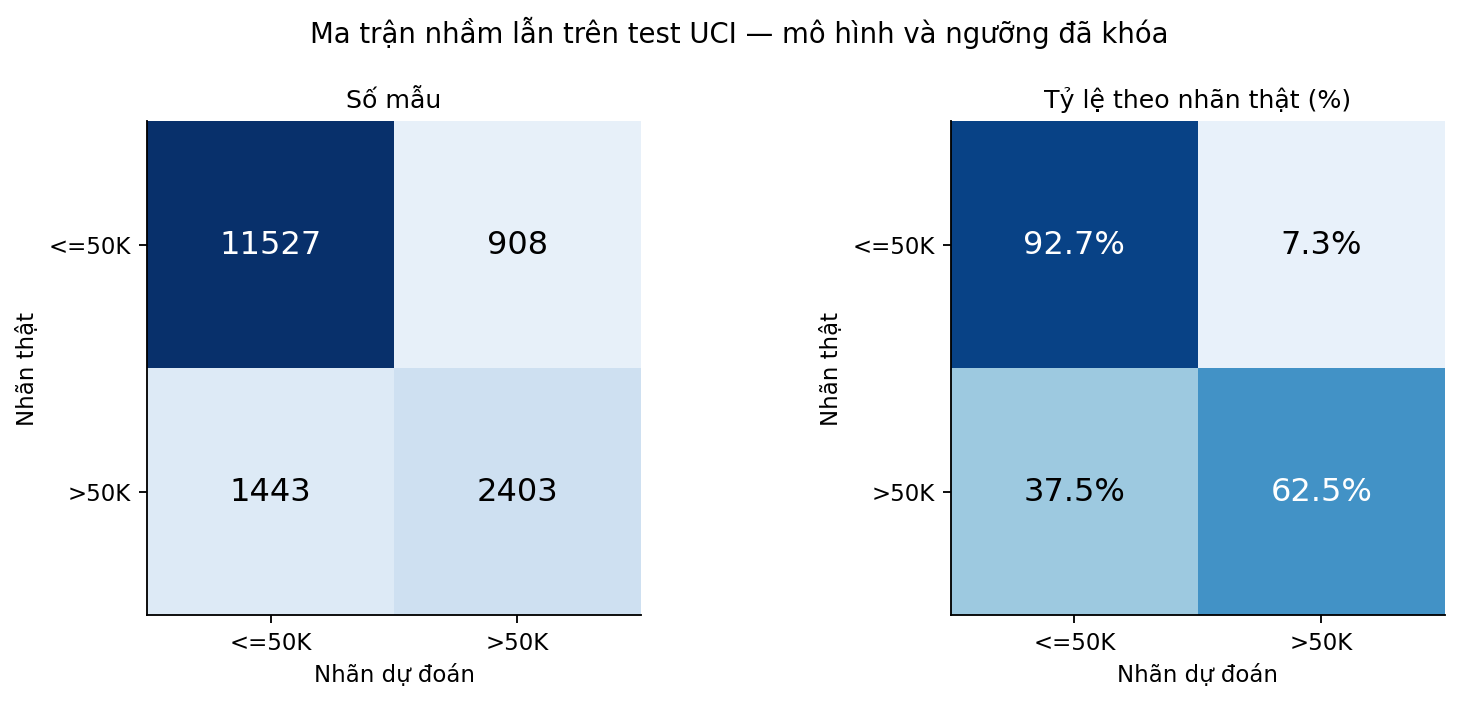

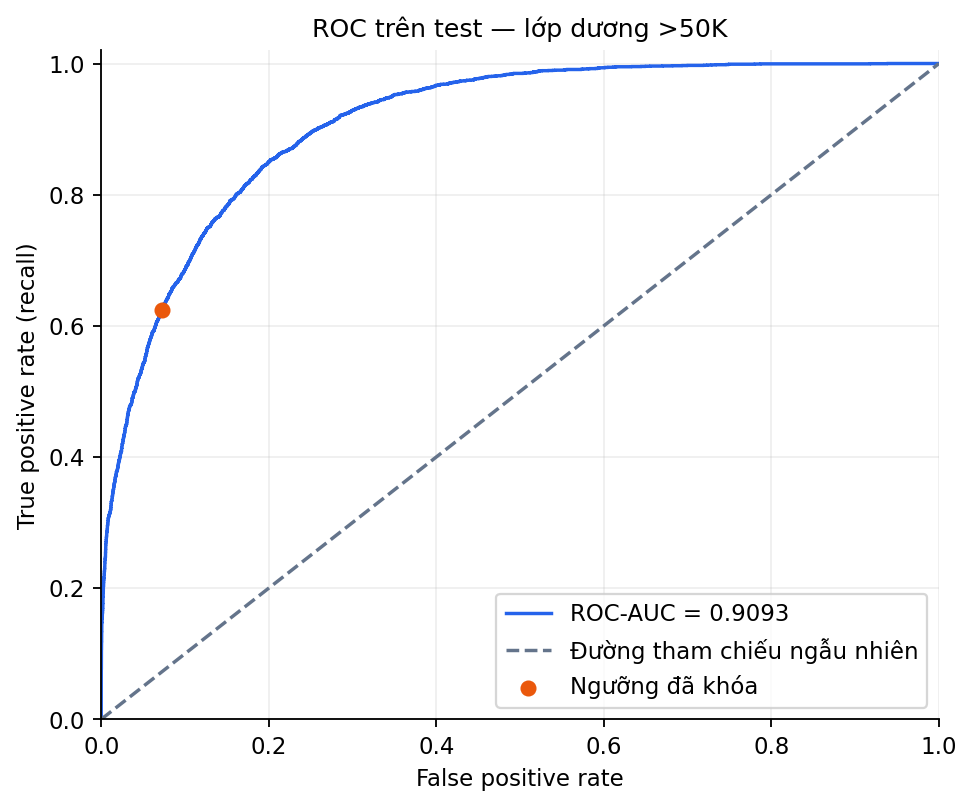

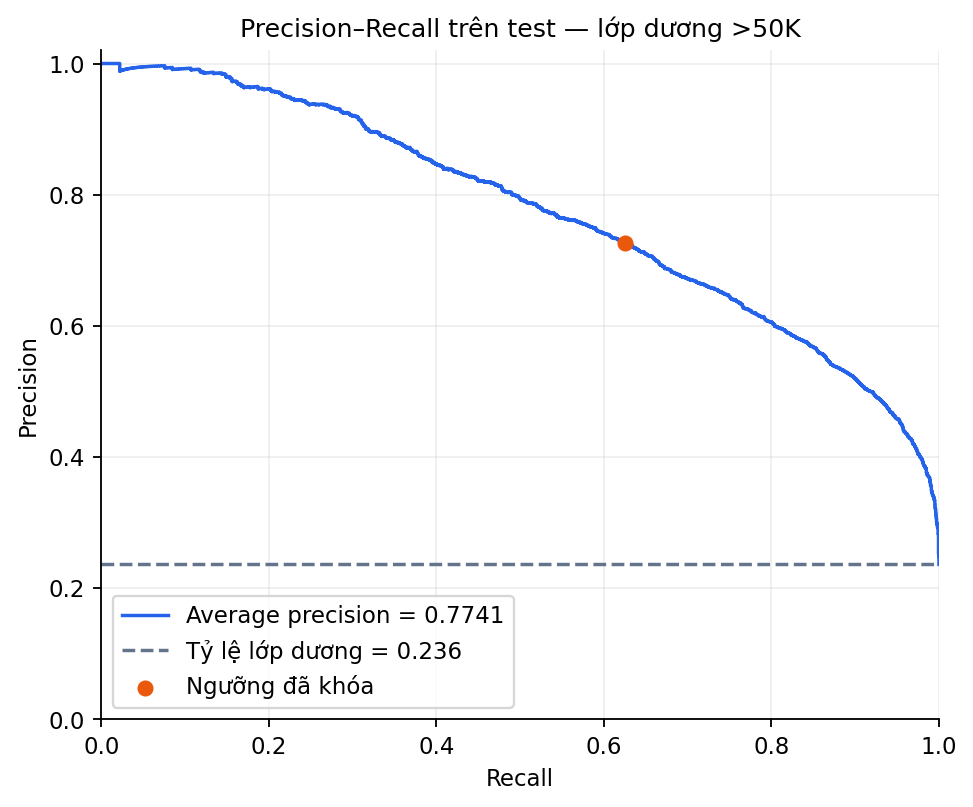

In [45]:
# 45. Ma trận nhầm lẫn, ROC và Precision–Recall trên test.
for stem in evaluation.plot_evaluation(STEP06_DIR):
    display(Image(filename=str(STEP06_DIR / f"{stem}.png")))
print("Chấm màu cam là ngưỡng đã khóa, không phải ngưỡng tối ưu từ test.")


### Xem lỗi và chẩn đoán hồ sơ trùng
Lưu tất cả FP/FN. Chọn tối đa 5 FP có score lớn nhất và 5 FN có score nhỏ nhất làm ví dụ; các ví dụ này được chọn có chủ đích. Score MLP chưa được kiểm định hiệu chỉnh xác suất.

Sau khi đã khóa và đánh giá, đối chiếu trùng 14 thuộc tính giữa test và dữ liệu phát triển để nêu rõ giới hạn của phân chia UCI. Không dùng nhãn để tạo khóa hồ sơ, không xóa dòng test và không chọn lại mô hình từ kết quả chẩn đoán này.


In [46]:
# 46. Phân tích lỗi và kiểm tra trùng hồ sơ sau đánh giá.
test_error_examples, test_error_profiles = evaluation.analyze_errors(
    df_test, split_metadata["test"], project_dir=PROJECT_ROOT
)
display(test_error_examples[["source_id", "source_row", "outcome", "y_true", "y_pred", "score",
                             "age", "education-num", "hours-per-week"]])
display(test_error_profiles)
test_overlap = evaluation.audit_test_profile_overlap(
    df_train, df_validation, df_test, project_dir=PROJECT_ROOT
)
display(pd.DataFrame([test_overlap]).drop(columns=["input_columns", "interpretation"]))
print("Đã lưu toàn bộ lỗi trong test_errors.csv. Giữ nguyên tập test UCI, không đổi cấu hình.")


Đã lưu toàn bộ lỗi trong test_errors.csv. Giữ nguyên tập test UCI, không đổi cấu hình.


,source_id,source_row,outcome,y_true,y_pred,score,age,education-num,hours-per-week
0,adult.test:3605,3605,FP,0,1,0.999581,36,9,90
1,adult.test:1418,1418,FP,0,1,0.982233,55,16,60
2,adult.test:518,518,FP,0,1,0.976433,41,16,60
3,adult.test:13977,13977,FP,0,1,0.962789,57,14,70
4,adult.test:12053,12053,FP,0,1,0.958186,50,13,48
5,adult.test:5953,5953,FN,1,0,0.000512,20,8,35
6,adult.test:10408,10408,FN,1,0,0.000753,22,10,15
7,adult.test:6035,6035,FN,1,0,0.003584,30,9,40
8,adult.test:11821,11821,FN,1,0,0.003838,24,7,40
9,adult.test:3059,3059,FN,1,0,0.004946,22,10,25


,rows,age_median,education-num_median,hours-per-week_median,capital-gain_median,capital-loss_median
outcome,,,,,,
FN,1443,41.0,10.0,40.0,0.0,0.0
FP,908,44.0,13.0,43.0,0.0,0.0
TN,11527,33.0,9.0,40.0,0.0,0.0
TP,2403,44.0,13.0,45.0,0.0,0.0


,label_in_group_key,test_rows,unique_test_profiles,test_rows_matching_train_profile,test_profiles_matching_train,test_rows_matching_validation_profile,test_profiles_matching_validation,rows_removed,used_for_model_or_threshold_selection
0,False,16281,16275,22,22,4,4,0,False


In [47]:
# 47. Cập nhật báo cáo bằng số liệu test và phân tích lỗi đã có.
test_report.update_test_report(STEP06_DIR, REPORT_ROOT)
print("Đã bổ sung chương 6.5–6.7, chỉ số đánh giá và phụ lục hướng dẫn.")
print("Kết luận chương 7 và hoàn thiện các phần còn lại ở bước 7.")


Đã bổ sung chương 6.5–6.7, chỉ số đánh giá và phụ lục hướng dẫn.
Kết luận chương 7 và hoàn thiện các phần còn lại ở bước 7.


In [48]:
# 48. Tạo ZIP LaTeX hiện hành và kiểm tra các tệp đầu ra chính.
LATEX_ZIP = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_6.zip"
with ZipFile(LATEX_ZIP, "w", compression=ZIP_DEFLATED) as archive:
    for path in sorted(REPORT_ROOT.rglob("*")):
        if path.is_file():
            archive.write(path, path.relative_to(REPORT_ROOT).as_posix())
previous_zip = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_5.zip"
if previous_zip.is_file():
    previous_zip.unlink()
for filename in ["test_metrics.json", "test_predictions.csv", "test_errors.csv", "evaluation_complete.json"]:
    assert (STEP06_DIR / filename).is_file()
assert (PROJECT_ROOT / test_lock["pipeline_path"]).is_file()
assert test_evaluation["counts"]["rows"] == len(df_test) == 16281
print("LaTeX:", LATEX_ZIP)
print("Hoàn thành bước 6/7. Giữ nguyên lựa chọn sau test; bước 7 hoàn thiện báo cáo/gói nộp.")


LaTeX: C:\Users\Acer\Documents\Codex\2026-11-21\new-chat\BTL_ML_Final\reports\BTL_ML_LaTeX_Buoc_6.zip
Hoàn thành bước 6/7. Giữ nguyên lựa chọn sau test; bước 7 hoàn thiện báo cáo/gói nộp.


# Bước 7 — Xuất báo cáo

Tổng hợp các bảng, biểu đồ và kết quả thí nghiệm vào báo cáo. Phần này tạo PDF và nguồn LaTeX; mô hình và ngưỡng dự đoán được giữ nguyên.


In [49]:
#@title 49. Chuẩn bị bộ hoàn thiện báo cáo và thư viện dàn PDF
FINAL_REPORT_SOURCES = {'finalization.py': '"""Hoàn thiện báo cáo từ kết quả đã khóa, không huấn luyện/đánh giá lại mô hình."""\nfrom pathlib import Path\nimport json,re\nimport pandas as pd\n\nTEAM_CONFIG={\'members\': [{\'name\': \'Hồng Chấn Phước\', \'student_id\': \'2352963\', \'allocation_percent\': 33, \'tasks\': \'Chuẩn bị và kiểm tra dữ liệu UCI; khảo sát nhãn, giá trị thiếu, bản ghi trùng và EDA; rà soát chương 1 và chương 3.\', \'email\': \'phuoc.hongchan@hcmut.edu.vn\', \'completion_percent\': 100}, {\'name\': \'Đinh Nguy Nguyệt Hà\', \'student_id\': \'2352286\', \'allocation_percent\': 33, \'tasks\': \'Rà soát tiền xử lý, encoding, scaling và PCA; đối chiếu các cấu hình CV, bảng kết quả và cảnh báo hội tụ; phụ trách chương 2, chương 4 và thiết kế thí nghiệm.\', \'email\': \'ha.dinhnguy2005@hcmut.edu.vn\', \'completion_percent\': 100}, {\'name\': \'Trần Bá Minh Quân\', \'student_id\': \'2353015\', \'allocation_percent\': 34, \'tasks\': \'Tích hợp notebook và module; kiểm tra snapshot, đánh giá test và phân tích lỗi; tổng hợp chương 5–7, định dạng báo cáo và đóng gói sản phẩm.\', \'email\': \'quan.tranbaminh12@hcmut.edu.vn\', \'completion_percent\': 100}]}\n\ndef _add_review_analysis(root, report):\n    """Explain existing comparisons quantitatively; no estimator or test selection."""\n    cv = pd.read_csv(root/\'results/step_05/cv_summary.csv\').set_index(\'candidate_id\')\n    validation = pd.read_csv(root/\'results/step_05/validation_summary.csv\').set_index(\'candidate_id\')\n    shapes = pd.read_csv(root/\'results/step_04/feature_shapes.csv\')\n    dims = shapes.loc[shapes[\'split\']==\'train\'].set_index(\'configuration\')[\'features\']\n    base, rf, mlp = cv.loc[\'lr_c1\'], cv.loc[\'rf_full_leaf3\'], cv.loc[\'mlp_32_reg\']\n    def number(x, digits=2):\n        return f\'{float(x):.{digits}f}\'.replace(\'.\', \',\')\n    def delta(candidate, reference, metric=\'f1_mean\'):\n        return number(100*(cv.loc[candidate, metric]-cv.loc[reference, metric]))\n    def append(prefix, text):\n        path = next((report/\'chapters/chapter_6\').glob(prefix+\'*.tex\'))\n        source = path.read_text(encoding=\'utf-8\')\n        source = re.sub(r\'\\n% BEGIN REVIEW ANALYSIS.*?% END REVIEW ANALYSIS\\n?\', \'\', source, flags=re.S)\n        path.write_text(source.rstrip()+\'\\n\\n% BEGIN REVIEW ANALYSIS\\n\'+text+\'\\n% END REVIEW ANALYSIS\\n\', encoding=\'utf-8\')\n    append(\'6_1_\',\n        r\'Trong nhóm mô hình truyền thống, Random Forest có F1 CV cao nhất là \'+number(rf.f1_mean,4)+\n        r\', hơn Logistic Regression cơ sở \'+delta(\'rf_full_leaf3\',\'lr_c1\')+\n        r\' điểm phần trăm và hơn LinearSVC \'+delta(\'rf_full_leaf3\',\'svm_c1\')+\n        r\' điểm phần trăm. Đây là đối chứng truyền thống chính của bài làm; pipeline đã được ghép tiền xử lý, huấn luyện và đánh giá bằng CV cùng validation. Số cấu hình tìm kiếm giữa các họ không bằng nhau nên bảng so sánh phản ánh thiết kế cụ thể đã chạy.\')\n    append(\'6_2_\',\n        r\'So với mốc one-hot, mode và StandardScaler, nhóm thiếu riêng làm F1 tăng \'+delta(\'lr_missing_constant\',\'lr_c1\')+\n        r\' điểm phần trăm; ordinal làm F1 thay đổi \'+delta(\'lr_ordinal\',\'lr_c1\')+\n        r\' điểm phần trăm. Hai khoảng MinMax [0,1] và [-1,1] thay đổi lần lượt \'+delta(\'lr_minmax01\',\'lr_c1\')+\n        r\' và \'+delta(\'lr_minmax11\',\'lr_c1\')+\n        r\' điểm phần trăm. Các hiệu số là chênh lệch F1 trung bình nhân 100, không phải mức tăng tương đối. Mức tăng nhỏ của cách biểu diễn thiếu riêng chưa đủ để kết luận có khác biệt chắc chắn trên các lần lấy mẫu khác.\')\n    append(\'6_3_\',\n        r\'Ở bộ đặc trưng fit trên toàn bộ train, số chiều giảm từ \'+str(int(dims[\'baseline\']))+r\' xuống \'+str(int(dims[\'pca_90\']))+\n        r\' với PCA 90\\% và \'+str(int(dims[\'pca_95\']))+r\' với PCA 95\\%, tương ứng giảm \'+number(100*(1-dims[\'pca_90\']/dims[\'baseline\']))+\n        r\'\\% và \'+number(100*(1-dims[\'pca_95\']/dims[\'baseline\']))+\n        r\'\\%. Đây là kích thước của các tệp NumPy xuất từ toàn bộ train; từng fold CV vẫn tự fit encoder/PCA và có thể có số chiều khác. F1 CV thay đổi \'+delta(\'lr_pca90\',\'lr_c1\')+\n        r\' và \'+delta(\'lr_pca95\',\'lr_c1\')+\n        r\' điểm phần trăm so với không PCA. Như vậy, trong thí nghiệm này, tiết kiệm chiều đi kèm giảm F1; không chọn PCA chỉ vì giữ được một tỷ lệ phương sai cao.\')\n    append(\'6_4_\',\n        r\'MLP 32 nút hơn Random Forest \'+delta(\'mlp_32_reg\',\'rf_full_leaf3\')+\n        r\' điểm phần trăm F1 CV; recall cao hơn \'+delta(\'mlp_32_reg\',\'rf_full_leaf3\',\'recall_mean\')+\n        r\' điểm phần trăm, nhưng precision thấp hơn \'+number(100*(rf.precision_mean-mlp.precision_mean))+\n        r\' điểm phần trăm. Random Forest có accuracy \'+number(rf.accuracy_mean,4)+r\' và ROC-AUC \'+number(rf.roc_auc_mean,4)+\n        r\', đều cao hơn MLP; lựa chọn cuối vẫn theo F1 lớp dương đã định trước. Vì thế không có một mô hình đứng đầu trên mọi chỉ số.\'+\'\\n\\n\'+\n        r\'SD F1 của MLP là \'+number(mlp.f1_std,4)+r\', so với \'+number(rf.f1_std,4)+\n        r\' của Random Forest. SD qua ba fold không phải khoảng tin cậy; các fold dùng chung dữ liệu phát triển và kết quả chưa có kiểm định nhiều seed. Trên validation, F1 của hai mô hình chỉ lệch \'+number(100*abs(validation.loc[\'rf_full_leaf3\',\'f1\']-validation.loc[\'mlp_32_reg\',\'f1\']),3)+\n        r\' điểm phần trăm. Các số liệu này ủng hộ cách diễn đạt MLP đạt F1 CV trung bình cao nhất trong phạm vi khảo sát, chưa chứng minh MLP tốt hơn một cách ổn định.\'+\'\\n\\n\'+\n        r\'Thời gian fit trung bình mỗi fold, tính cả pipeline tiền xử lý, là \'+number(mlp.fit_seconds_mean)+r\' giây cho MLP, \'+number(rf.fit_seconds_mean)+\n        r\' giây cho Random Forest và \'+number(cv.loc[\'lr_missing_constant\',\'fit_seconds_mean\'])+\n        r\' giây cho Logistic Regression dùng nhóm thiếu riêng. Đây là số đo trên môi trường thực nghiệm được lưu, không phải benchmark độc lập hoặc bảo đảm tốc độ trên Colab. Kích thước dữ liệu, thư viện và phần cứng đều có thể làm thời gian thay đổi.\')\n\n\ndef finalize_report(project_dir=\'.\',team_config=None):\n    root=Path(project_dir);report=root/\'reports/latex\';out=root/\'results/step_07\';out.mkdir(parents=True,exist_ok=True)\n    team=TEAM_CONFIG if team_config is None else team_config\n    if sum(m[\'allocation_percent\'] for m in team[\'members\'])!=100:raise ValueError(\'Tổng tỷ lệ phân công phải bằng 100%.\')\n    (root/\'configs/team.json\').write_text(json.dumps(team,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    data=json.loads((root/\'results/step_06/test_metrics.json\').read_text(encoding=\'utf-8\'))\n    metrics=data[\'metrics\'];counts=data[\'counts\']\n    cv=pd.read_csv(root/\'results/step_05/cv_summary.csv\');winner=cv.set_index(\'candidate_id\').loc[data[\'winner_id\']]\n    val=pd.read_csv(root/\'results/step_05/validation_summary.csv\').set_index(\'candidate_id\').loc[data[\'winner_id\']]\n    def n(x):return f\'{int(x):,}\'.replace(\',\',\'.\')\n    def dec(x):return f\'{float(x):.4f}\'.replace(\'.\',\',\')\n    def pct(x):return f\'{float(x)*100:.2f}\'.replace(\'.\',\',\')\n    def esc(x):return str(x).replace(\'_\',r\'\\_\').replace(\'%\',r\'\\%\')\n    def write(rel,text):\n        path=report/rel;path.parent.mkdir(parents=True,exist_ok=True);path.write_text(text,encoding=\'utf-8\')\n    def edit(rel,replacements):\n        path=report/rel;text=path.read_text(encoding=\'utf-8\')\n        for before,after in replacements:\n            if before not in text:\n                if after in text:continue\n                raise ValueError(\'Không tìm thấy đoạn cần cập nhật: \'+rel+\' / \'+before[:60])\n            text=text.replace(before,after)\n        path.write_text(text,encoding=\'utf-8\')\n    write(\'frontmatter/abstract.tex\',r\'\'\'\\chapter*{Tóm tắt}\n\\phantomsection\n\\addcontentsline{toc}{chapter}{Tóm tắt}\nBáo cáo xây dựng một pipeline học máy có thể cấu hình cho bài toán dự đoán thu nhập năm trên 50.000 USD từ dữ liệu bảng UCI Adult. Hai tệp gốc gồm 32.561 mẫu phát triển và 16.281 mẫu test, với 14 thuộc tính đầu vào. Tập phát triển được chia theo nhóm hồ sơ thành 26.049 mẫu train và 6.512 mẫu validation. Pipeline kết hợp điền thiếu, mã hóa biến phân loại, chuẩn hóa biến số, PCA tùy chọn và bộ phân loại; mọi phép biến đổi học tham số được fit đúng phần train tương ứng.\n\nVòng so sánh cuối khảo sát 20 cấu hình bằng cross-validation ba fold theo nhóm, gồm Logistic Regression, SVM tuyến tính, Random Forest, MLP và mốc dự đoán đa số. Hai cấu hình MLP được bổ sung sau pilot do cảnh báo tối ưu; toàn bộ dấu vết pilot và kết quả sau mở rộng được giữ lại. Tiêu chí lựa chọn là F1 của lớp \\texttt{>50K}, trước khi đối chiếu validation. Cấu hình được khóa là MLP một lớp ẩn 32 nút, không PCA và ngưỡng xác suất 0,5.\n\nMô hình đạt F1 CV trung bình \'\'\'+dec(winner.f1_mean)+r\'\'\', F1 validation \'\'\'+dec(val.f1)+r\'\'\' và F1 test \'\'\'+dec(metrics[\'f1\'])+r\'\'\'. Trên test, accuracy đạt \'\'\'+pct(metrics[\'accuracy\'])+r\'\'\'\\%, precision \'\'\'+pct(metrics[\'precision\'])+r\'\'\'\\%, recall \'\'\'+pct(metrics[\'recall\'])+r\'\'\'\\% và ROC-AUC \'\'\'+dec(metrics[\'roc_auc\'])+r\'\'\'. Kết quả cho thấy cần đọc accuracy cùng khả năng phát hiện lớp thu nhập cao. Giới hạn gồm lưới tham số nhỏ, một seed, ba fold, dữ liệu lịch sử và một số hồ sơ đầu vào trùng giữa test với dữ liệu phát triển. Báo cáo đi kèm notebook, module, đặc trưng NumPy, mô hình cố định và các bảng kiểm tra để đối chiếu số liệu.\n\n\\noindent\\textbf{Từ khóa:} UCI Adult, phân loại nhị phân, tiền xử lý, cross-validation theo nhóm, PCA, MLP.\n\'\'\')\n    write(\'frontmatter/acknowledgements.tex\',r\'\'\'\\chapter*{Lời cảm ơn}\n\\phantomsection\n\\addcontentsline{toc}{chapter}{Lời cảm ơn}\nNhóm xin cảm ơn thầy Trương Vĩnh Lân và học phần Học máy đã cung cấp nội dung lý thuyết, yêu cầu thực hành và định hướng để tổ chức bài tập lớn theo một quy trình có thể kiểm tra. Việc thực hiện đề tài tạo cơ hội liên hệ các khái niệm tiền xử lý, lựa chọn mô hình và đánh giá với một tập dữ liệu bảng cụ thể.\n\nNhóm cũng cảm ơn những người công bố dữ liệu Adult trên UCI Machine Learning Repository và cộng đồng phát triển các thư viện khoa học Python. Dữ liệu công khai và tài liệu chính thức là cơ sở để xây dựng thí nghiệm, tra cứu cách sử dụng và đối chiếu kết quả.\n\'\'\')\n    abbreviations=[(\'AP\',\'Average Precision: độ chính xác trung bình theo đường Precision–Recall\'),\n        (\'CV\',\'Cross-validation: đánh giá chéo\'),(\'EDA\',\'Exploratory Data Analysis: phân tích khám phá dữ liệu\'),\n        (\'FN / FP\',\'False Negative / False Positive: bỏ sót lớp dương / báo dương sai\'),\n        (\'FNR / FPR\',\'Tỷ lệ bỏ sót lớp dương / tỷ lệ báo dương sai\'),(\'MLP\',\'Multilayer Perceptron: mạng nơ-ron kết nối đầy đủ nhiều lớp\'),\n        (\'PCA\',\'Principal Component Analysis: phân tích thành phần chính\'),(\'PR\',\'Precision–Recall\'),\n        (\'ROC-AUC\',\'Diện tích dưới đường Receiver Operating Characteristic\'),(\'SD\',\'Standard Deviation: độ lệch chuẩn\'),\n        (\'SVM\',\'Support Vector Machine: máy véc-tơ hỗ trợ\'),(\'TN / TP\',\'True Negative / True Positive: nhận diện đúng lớp âm / lớp dương\'),\n        (\'UCI\',\'University of California, Irvine; đơn vị vận hành kho dữ liệu sử dụng\')]\n    ab=[r\'\\chapter*{Danh mục từ viết tắt}\',r\'\\phantomsection\',r\'\\addcontentsline{toc}{chapter}{Danh mục từ viết tắt}\',\n        r\'\\begin{longtable}{p{.18\\textwidth}p{.75\\textwidth}}\',r\'\\toprule\',r\'Từ viết tắt & Diễn giải \\\\\',r\'\\midrule\']\n    ab += [a+\' & \'+b+r\' \\\\\' for a,b in abbreviations]\n    write(\'frontmatter/abbreviations.tex\',\'\\n\'.join(ab+[r\'\\bottomrule\',r\'\\end{longtable}\'])+\'\\n\')\n    write(\'chapters/chapter_7/7_1_ket_qua_dat_duoc.tex\',r\'\'\'\\section{Kết quả đạt được}\n\\label{sec:7_1}\nĐề tài đã triển khai quy trình học máy truyền thống cho UCI Adult và bổ sung MLP để đối chiếu. Quy trình đi từ tải dữ liệu công khai, kiểm tra chất lượng và EDA đến phân chia theo nhóm, tiền xử lý có thể cấu hình, khảo sát mô hình và đánh giá test với lựa chọn đã khóa. Không loại dòng trong hai tệp UCI gốc; toàn bộ 14 thuộc tính, gồm cả \\texttt{fnlwgt}, được giữ làm đầu vào. \\texttt{fnlwgt} không được dùng làm trọng số mẫu.\n\nCác sản phẩm gồm notebook tự chuẩn bị dữ liệu, module Python, nguồn LaTeX tách theo từng mục, các bảng/hình thực nghiệm, snapshot mô hình và 15 tệp NumPy. Ba bộ X fit từ toàn bộ train gồm bản cơ sở 105 chiều, PCA 90\\% còn 22 chiều và PCA 95\\% còn 31 chiều. Khi CV, pipeline được fit lại trên raw train của mỗi fold, không sử dụng trực tiếp các ma trận đã fit từ toàn bộ train.\n\nTrong phạm vi 20 cấu hình cuối, MLP 32 nút được chọn theo F1 CV trung bình \'\'\'+dec(winner.f1_mean)+r\'\'\' với SD \'\'\'+dec(winner.f1_std)+r\'\'\'. F1 validation là \'\'\'+dec(val.f1)+r\'\'\' và F1 test là \'\'\'+dec(metrics[\'f1\'])+r\'\'\'. Trên 16.281 mẫu test, mô hình đạt accuracy \'\'\'+pct(metrics[\'accuracy\'])+r\'\'\'\\%, ROC-AUC \'\'\'+dec(metrics[\'roc_auc\'])+r\'\'\' và AP \'\'\'+dec(metrics[\'average_precision\'])+r\'\'\'. Ngưỡng 0,5 và snapshot được giữ nguyên sau khi xem test.\n\nCác đối chứng Logistic Regression chỉ thay một thành phần cho thấy kết quả phụ thuộc cách biểu diễn và thang đo. Trong các cấu hình đã chạy, ordinal và hai mức PCA có F1 thấp hơn mốc one-hot không PCA; lựa chọn điền biến phân loại bằng một nhóm thiếu có mức tăng nhỏ. Đây là kết quả trong thiết kế đã khảo sát, không phải kết luận về ưu thế phổ quát của một bộ mã hóa hay mô hình.\n\nViệc đối chiếu số liệu từ dự đoán từng mẫu giúp giải thích chất lượng theo số đếm: \'\'\'+n(counts[\'tp\'])+r\'\'\' TP, \'\'\'+n(counts[\'fp\'])+r\'\'\' FP, \'\'\'+n(counts[\'fn\'])+r\'\'\' FN và \'\'\'+n(counts[\'tn\'])+r\'\'\' TN. Các tệp kết quả, mã SHA-256 và cấu hình cho phép truy lại nguồn của các bảng trong báo cáo.\n\'\'\')\n    write(\'chapters/chapter_7/7_2_han_che_cua_nghien_cuu.tex\',r\'\'\'\\section{Hạn chế của nghiên cứu}\n\\label{sec:7_2}\n\\begin{itemize}\n\\item \\textbf{Phạm vi tìm kiếm:} sử dụng ba fold, một seed và lưới siêu tham số nhỏ, không đồng đều giữa các họ. Hai cấu hình MLP được thêm sau khi xem cảnh báo hội tụ của pilot; quá trình này được công khai và chưa sử dụng validation/test. F1 CV thắng cuộc vẫn là số liệu phục vụ lựa chọn, không phải ước lượng hiệu quả cuối không thiên lệch.\n\\item \\textbf{Phân chia và trùng hồ sơ:} train/validation không chung nhóm 14 thuộc tính; tuy nhiên, giữ nguyên test UCI dẫn đến 22 dòng test trùng hồ sơ train và 4 dòng trùng hồ sơ validation. Vì vậy không khẳng định phân chia test tách biệt tuyệt đối về hồ sơ. Không loại các dòng này sau khi nhìn kết quả.\n\\item \\textbf{Vai trò EDA/validation:} EDA được thực hiện trên toàn bộ \\texttt{adult.data} trước khi tách train/validation. Validation chỉ là đối chiếu mô tả trong dữ liệu phát triển, không được trình bày như một tập hoàn toàn chưa từng được khảo sát. Các thống kê imputer/scaler/PCA vẫn chỉ fit từ phần train tương ứng.\n\\item \\textbf{Khả năng phát hiện lớp dương:} recall test bằng \'\'\'+pct(metrics[\'recall\'])+r\'\'\'\\%, còn \'\'\'+pct(metrics[\'false_negative_rate\'])+r\'\'\'\\% mẫu dương bị bỏ sót tại ngưỡng đã khóa. Accuracy cao hơn không đồng nghĩa bài toán lớp thiểu số đã được giải quyết đầy đủ. Chưa khảo sát chi phí lỗi, class weighting hoặc resampling.\n\\item \\textbf{Phạm vi suy rộng:} Adult phản ánh một tập dữ liệu điều tra dân số Hoa Kỳ lịch sử. Kết quả chung không chứng minh khả năng áp dụng cho thời kỳ, quốc gia hoặc quần thể khác; chưa có đánh giá theo nhóm nhân khẩu hay kiểm tra hiệu chỉnh xác suất.\n\\item \\textbf{Tái lập:} kết quả có thể thay đổi khi phiên bản thư viện, phần cứng hoặc thuật toán thay đổi. Môi trường thực nghiệm, seed và snapshot mô hình được lưu kèm để đối chiếu khi thực hiện lại.\n\\end{itemize}\nTập test đã được sử dụng để đánh giá cuối. Báo cáo không tiếp tục dùng kết quả test này để điều chỉnh rồi gọi lần đo tiếp theo là đánh giá trên dữ liệu chưa thấy.\n\'\'\')\n    write(\'chapters/chapter_7/7_3_huong_phat_trien.tex\',r\'\'\'\\section{Hướng phát triển}\n\\label{sec:7_3}\nCác hướng mở rộng sau chỉ là đề xuất, chưa phải các thí nghiệm đã thực hiện:\n\\begin{itemize}\n\\item Mở rộng lưới tham số, thử nhiều seed và thiết kế CV theo nhóm lồng nhau để đánh giá độ ổn định và ảnh hưởng của quá trình lựa chọn.\n\\item Khảo sát trọng số lớp, hiệu chỉnh xác suất và tối ưu ngưỡng bằng dữ liệu train/validation theo nhóm, căn cứ vào chi phí FP/FN được xác định trước. Một lần đánh giá cuối mới cần có dữ liệu giữ lại mới, không tận dụng test đã xem để tinh chỉnh.\n\\item Đối chiếu vai trò của \\texttt{fnlwgt}, hai trường học vấn và các thuộc tính vốn; tách rõ sử dụng trọng số khảo sát với sử dụng chúng làm đặc trưng. Đánh giá lựa chọn trên dữ liệu phát triển và kiểm tra trên một holdout mới có kiểm soát trùng hồ sơ.\n\\item Đánh giá độ tin cậy, hiệu chỉnh score, kết quả theo nhóm và mức dịch chuyển dữ liệu trước khi cân nhắc một ứng dụng thực tế. Các phân tích giải thích cần phân biệt mối liên hệ quan sát với tác động nhân quả.\n\\item Đóng gói môi trường thực nghiệm, cố định phiên bản thư viện và tự động hóa các bước kiểm tra để tăng khả năng tái lập.\n\\end{itemize}\nCác cải tiến cần được tổ chức như một nghiên cứu tiếp theo với giao thức đánh giá mới. Trong báo cáo hiện tại, mô hình và kết quả test ở chương 6 được giữ cố định.\n\'\'\')\n    write(\'backmatter/appendix_a/A_1_chay_toan_bo_notebook_tren_google_colab.tex\',\'\\\\section{Chạy notebook trên Google Colab}\\n\\\\label{sec:A_1}\\nMở \\\\texttt{notebooks/Adult\\\\_BTL.ipynb} trên Google Colab và chọn Runtime $\\\\rightarrow$ Run all. Notebook tự cài các thư viện cần thiết, tải dữ liệu từ UCI, tạo module và thực hiện toàn bộ quy trình thí nghiệm.\\n\\nCác kết quả được lưu trong \\\\texttt{results/}; đặc trưng NumPy nằm trong \\\\texttt{features/}; pipeline đã huấn luyện nằm trong \\\\texttt{artifacts/}. Báo cáo PDF và ZIP LaTeX được xuất vào \\\\texttt{reports/}.\\n\\nĐể biên dịch nguồn LaTeX trên Overleaf, nhập \\\\texttt{BTL\\\\_ML\\\\_LaTeX\\\\_Final.zip}, chọn \\\\texttt{main.tex} làm tài liệu chính và XeLaTeX làm trình biên dịch. Notebook tạo lại nguồn báo cáo khi thực thi phần xuất báo cáo.\\n\')\n    write(\'backmatter/appendix_a/A_2_cau_truc_thu_muc_nop_bai.tex\',r\'\'\'\\section{Cấu trúc thư mục nộp bài}\n\\label{sec:A_2}\nGói tổng được tổ chức theo các thư mục sau:\n\\begin{itemize}\n\\item \\texttt{notebooks/}: notebook chính \\texttt{Adult\\_BTL.ipynb} để mở trong Colab.\n\\item \\texttt{modules/}: tải dữ liệu, EDA, chia tập, tiền xử lý, CV, đánh giá, cập nhật và dàn trang báo cáo.\n\\item \\texttt{reports/}: PDF, nguồn \\texttt{latex/} và ZIP LaTeX. Trong nguồn có \\texttt{frontmatter/}, \\texttt{chapters/}, \\texttt{config/}, \\texttt{backmatter/} và \\texttt{Images/}; mỗi mục và tiểu mục có tệp riêng, thư mục hình phản ánh cùng cấu trúc.\n\\item \\texttt{features/}: X cơ sở/PCA, y, chỉ số dòng nguồn, tên đặc trưng và manifest.\n\\item \\texttt{data/}: ZIP UCI, các tệp nguồn, bảng đã đọc và train/validation/test cùng metadata.\n\\item \\texttt{configs/}: cấu hình tiền xử lý, thí nghiệm và phân công nhóm; \\texttt{artifacts/}: các pipeline và snapshot cuối.\n\\item \\texttt{results/}: kết quả theo bước, bảng CSV, hình PDF/PNG và hồ sơ kiểm tra.\n\\end{itemize}\nTệp README ở thư mục gốc mô tả cách chạy và các giới hạn kiểm tra. Không cần mount Drive hoặc tải các module thủ công khi chạy notebook độc lập.\n\'\'\')\n    write(\'backmatter/appendix_a/A_4_lien_ket_ma_nguon_notebook_va_du_lieu.tex\',\'\\\\section{Dữ liệu và mã nguồn}\\n\\\\label{sec:A_4}\\n\\\\begin{itemize}\\n\\\\item Trang dữ liệu: \\\\url{https://archive.ics.uci.edu/dataset/2/adult}.\\n\\\\item Tệp ZIP: \\\\url{https://archive.ics.uci.edu/static/public/2/adult.zip}.\\n\\\\item DOI: \\\\url{https://doi.org/10.24432/C5XW20}.\\n\\\\item Repository: \\\\url{https://github.com/Quan-129/BTL-ML-UCI-Adult}.\\n\\\\item Mở notebook trên Colab: \\\\url{https://colab.research.google.com/github/Quan-129/BTL-ML-UCI-Adult/blob/main/notebooks/Adult_BTL.ipynb}.\\n\\\\item Notebook: \\\\texttt{notebooks/Adult\\\\_BTL.ipynb}.\\n\\\\item Module Python và cấu hình: \\\\texttt{modules/}, \\\\texttt{configs/}.\\n\\\\item Báo cáo: \\\\texttt{reports/BTL\\\\_ML\\\\_Bao\\\\_Cao.pdf}; nguồn LaTeX: \\\\texttt{reports/latex/main.tex}.\\n\\\\end{itemize}\\n\')\n    rows=[r\'\\section{Bảng phân công công việc}\',r\'\\label{sec:B_1}\',\n        r\'\\begin{longtable}{p{.28\\textwidth}p{.16\\textwidth}p{.48\\textwidth}}\',\n        r\'\\caption{Thông tin thành viên}\\label{tab:team-members}\\\\\',r\'\\toprule\',\n        r\'Thành viên & MSSV & Email \\\\\',r\'\\midrule\']\n    for member in team[\'members\']:\n        rows.append(member[\'name\']+\' & \'+member[\'student_id\']+\' & \'+r\'\\texttt{\'+member[\'email\']+r\'} \\\\\')\n    rows += [r\'\\bottomrule\',r\'\\end{longtable}\',\n        \'Tỷ lệ phân công thể hiện phần khối lượng công việc của từng thành viên. Mức hoàn thành được trình bày riêng cho từng phần việc.\',\n        r\'\\begin{longtable}{p{.19\\textwidth}p{.47\\textwidth}rr}\',\n        r\'\\caption{Phân công và mức hoàn thành công việc}\\label{tab:team-tasks}\\\\\',\n        r\'\\toprule\',r\'Thành viên & Nhiệm vụ & Phân công & Hoàn thành \\\\\',r\'\\midrule\']\n    for member in team[\'members\']:\n        rows.append(member[\'name\']+\' & \'+member[\'tasks\']+\' & \'+str(member[\'allocation_percent\'])+r\'\\% & \'+str(member[\'completion_percent\'])+r\'\\% \\\\\')\n    rows += [r\'\\bottomrule\',r\'\\end{longtable}\']\n    write(\'backmatter/appendix_b/B_1_bang_phan_cong_va_ty_le_dong_gop.tex\',\'\\n\'.join(rows)+\'\\n\')\n    write(\'backmatter/appendix_b/B_2_tien_do_thuc_hien_cua_nhom.tex\',\'\\\\section{Quy trình thực hiện}\\n\\\\label{sec:B_2}\\nCông việc được triển khai theo bảy giai đoạn: thu thập dữ liệu; khảo sát EDA; chia tập; tiền xử lý và xuất đặc trưng; so sánh mô hình bằng CV; đánh giá test và phân tích lỗi; tổng hợp báo cáo.\\n\\nCác bảng thống kê, cấu hình và kết quả từng giai đoạn được lưu trong \\\\texttt{results/}. Notebook tích hợp các module để thực hiện lại quy trình từ dữ liệu gốc đến các sản phẩm cuối.\\n\')\n    write(\'backmatter/appendix_b/appendix_b.tex\',r\'\\chapter{Phân công công việc}\'+\'\\n\'+r\'\\label{chap:B}\'+\'\\n\'+\n        r\'\\input{backmatter/appendix_b/B_1_bang_phan_cong_va_ty_le_dong_gop}\'+\'\\n\'+\n        r\'\\input{backmatter/appendix_b/B_2_tien_do_thuc_hien_cua_nhom}\'+\'\\n\')\n    for relative in [\'frontmatter/declaration.tex\',\'backmatter/appendix_b/B_3_minh_chung_hoat_dong_nhom.tex\',\'TIEN_DO.md\']:\n        obsolete=report/relative\n        if obsolete.is_file():obsolete.unlink()\n    write(\'backmatter/appendix_c/appendix_c.tex\',r\'\'\'\\chapter{Bảng kết quả đối chiếu}\n\\label{chap:C}\n\\input{backmatter/appendix_c/C_1_bang_ket_qua_cv_day_du}\n\'\'\')\n    lines=[r\'\\section{Kết quả CV của toàn bộ cấu hình}\',r\'\\label{sec:C_1}\',\n        \'Bảng liệt kê đủ 20 cấu hình ở vòng cuối. Chỉ số precision, recall và F1 tính cho lớp >50K; SD là độ lệch chuẩn mẫu qua ba fold. Cột CB ghi số fold có cảnh báo hội tụ. Những cấu hình có CB lớn hơn 0 vẫn được báo cáo nhưng không đủ điều kiện khóa lựa chọn.\',\n        r\'\\begin{longtable}{lrrrrrr}\',r\'\\caption{Toàn bộ kết quả CV ở vòng so sánh cuối}\\label{tab:cv-all}\\\\\',\n        r\'\\toprule\',r\'Cấu hình & F1 & SD & Precision & Recall & Accuracy & CB \\\\\',r\'\\midrule\']\n    for _,r in cv.iterrows():\n        lines.append(esc(r.candidate_id)+\' & \'+\' & \'.join(dec(r[k]) for k in [\'f1_mean\',\'f1_std\',\'precision_mean\',\'recall_mean\',\'accuracy_mean\'])+\' & \'+str(int(r.convergence_warning_count))+r\' \\\\\')\n    lines += [r\'\\bottomrule\',r\'\\end{longtable}\',\n        r\'Các kết quả từng fold, thời gian, cấu hình đầy đủ và cảnh báo gốc nằm trong \\texttt{results/step\\_05/}. Lịch sử pilot 18 cấu hình được giữ ở \\texttt{pilot\\_18/}.\']\n    write(\'backmatter/appendix_c/C_1_bang_ket_qua_cv_day_du.tex\',\'\\n\'.join(lines)+\'\\n\')\n    (report/\'Images/backmatter/appendix_c/C_1\').mkdir(parents=True,exist_ok=True)\n    edit(\'chapters/chapter_1/1_3_pham_vi_nghien_cuu.tex\',[\n        (\'Các quyết định sử dụng hoặc biến đổi thuộc tính sẽ được trình bày cùng lý do trong các phần khảo sát dữ liệu và xây dựng pipeline.\',\n         \'Cả 14 thuộc tính được giữ làm đầu vào; các phép biến đổi và cấu hình được trình bày trong phần khảo sát dữ liệu và xây dựng pipeline.\')])\n    edit(\'chapters/chapter_4/4_1_so_do_tong_the_cua_pipeline.tex\',[\n        (\'Bước 4 chỉ chuẩn bị đặc trưng và chưa huấn luyện bộ phân loại. Ở bước thực nghiệm tiếp theo, bộ tiền xử lý chưa fit sẽ được ghép với từng mô hình trong một pipeline hoàn chỉnh, để fit đúng phạm vi dữ liệu của mỗi fold.\',\n         \'Phần chuẩn bị đặc trưng có thể được xuất độc lập thành các ma trận NumPy. Khi thực nghiệm mô hình, bộ tiền xử lý chưa fit được ghép với bộ phân loại trong một pipeline hoàn chỉnh để fit đúng phạm vi dữ liệu của từng fold. Sau lựa chọn bằng CV, pipeline được fit trên toàn bộ train và giữ cố định để đánh giá cuối.\')])\n    edit(\'chapters/chapter_4/4_7_cau_hinh_cac_buoc_cua_pipeline.tex\',[\n        (\'Các lựa chọn khác được hỗ trợ để dùng trong thí nghiệm, chưa có kết luận về hiệu quả dự đoán.\',\n         \'Các đối chứng tiền xử lý và PCA đã thực hiện được mô tả ở chương 5 và chương 6; các lựa chọn chỉ được hỗ trợ nhưng chưa chạy không được gán một kết quả thực nghiệm.\')])\n    edit(\'chapters/chapter_4/4_8_luu_dac_trung_va_thong_tin_di_kem.tex\',[\n        (\'$26.049\',r\'$26\\,049\'),(\'$6.512\',r\'$6\\,512\'),(\'$16.281\',r\'$16\\,281\'),\n        (\'không dùng để fit đặc trưng, chọn cấu hình hoặc tính chỉ số mô hình.\',\n         \'không dùng để fit đặc trưng hoặc chọn cấu hình. Chỉ số test được tính riêng sau khi đã khóa mô hình, như trình bày ở mục 6.5.\')])\n    edit(\'chapters/chapter_5/5_8_nguyen_tac_chon_mo_hinh_va_danh_gia_cuoi_cung.tex\',[\n        (\'Bước 6 sẽ dùng đúng mô hình và ngưỡng đã khóa để đánh giá một lần trên test.\',\n         \'Phép đánh giá cuối dùng đúng mô hình và ngưỡng đã khóa; kết quả nằm ở mục 6.5 và không được dùng để chọn lại cấu hình.\')])\n    edit(\'chapters/chapter_6/6_7_nhan_xet_tong_hop_ve_cac_ket_qua.tex\',[\n        (\'Bước 6 hoàn tất phần đánh giá mô hình đã khóa. Chương kết luận, tóm tắt, kiểm tra trình bày và các thông tin phân công/minh chứng thực tế của nhóm được hoàn thiện ở bước 7.\',\n         \'Chương 7 tổng hợp các kết quả, hạn chế và hướng phát triển. Các phụ lục trình bày cấu trúc sản phẩm, cách thực thi và bảng phân công công việc.\')])\n    # Avoid an inline matrix for clearer text extraction in the PDF companion.\n    edit(\'chapters/chapter_6/6_5_2_ma_tran_nham_lan_va_duong_cong_danh_gia.tex\',[\n        (r\'ma trận có dạng $\\left[\\begin{smallmatrix}TN&FP\\\\FN&TP\\end{smallmatrix}\\right]$\',\n         \'hàng thứ nhất lần lượt là TN, FP; hàng thứ hai lần lượt là FN, TP\')])\n    write(\'main.tex\',r\'\'\'% !TeX program = xelatex\n\\documentclass[12pt,a4paper,oneside,openany]{report}\n\\input{config/fonts}\n\\input{config/packages}\n\\input{config/metadata}\n\\input{config/layout}\n\\input{config/headers_footers}\n\\begin{document}\n\\input{frontmatter/cover}\n\\pagenumbering{roman}\n\\input{frontmatter/acknowledgements}\n\\input{frontmatter/abstract}\n\\input{frontmatter/contents}\n\\input{frontmatter/abbreviations}\n\\input{frontmatter/list_of_figures}\n\\input{frontmatter/list_of_tables}\n\\clearpage\n\\pagenumbering{arabic}\n\\input{chapters/chapter_1/chapter_1}\n\\input{chapters/chapter_2/chapter_2}\n\\input{chapters/chapter_3/chapter_3}\n\\input{chapters/chapter_4/chapter_4}\n\\input{chapters/chapter_5/chapter_5}\n\\input{chapters/chapter_6/chapter_6}\n\\input{chapters/chapter_7/chapter_7}\n\\input{backmatter/references}\n\\appendix\n\\input{backmatter/appendix_a/appendix_a}\n\\input{backmatter/appendix_b/appendix_b}\n\\input{backmatter/appendix_c/appendix_c}\n\\end{document}\n\'\'\')\n    layout=report/\'config/layout.tex\';text=layout.read_text(encoding=\'utf-8\')\n    text=text.replace(\'Khung báo cáo UCI Adult\',\'Dự đoán thu nhập với UCI Adult\').replace(\'Khung tựa mục báo cáo\',\'Báo cáo thực nghiệm học máy\')\n    layout.write_text(text,encoding=\'utf-8\')\n    write(\'README.md\',\'# Nguồn LaTeX báo cáo UCI Adult\\n\\nMở main.tex bằng XeLaTeX trên Overleaf. Các chương, mục và tiểu mục được lưu trong từng file riêng; Images/ có cấu trúc tương ứng.\\n\\nThông tin đề tài và thành viên nằm trong config/metadata.tex; bố cục và đầu/chân trang nằm trong config/layout.tex và config/headers_footers.tex.\\n\\nPDF do notebook xuất được dàn bằng ReportLab. Khi biên dịch nguồn bằng XeLaTeX, cách ngắt dòng và số trang có thể khác.\\n\')\n    edit(\'chapters/chapter_1/1_5_bo_cuc_bao_cao.tex\', [(\'phân công công việc và minh chứng hoạt động nhóm.\', \'phân công công việc.\')])\n    _add_review_analysis(root, report)\n    index=[\'# Vị trí từng mục trong báo cáo\',\'\', \'| Tựa mục | File LaTeX |\', \'|---|---|\']\n    for p in sorted(report.rglob(\'*.tex\')):\n        if p.name==\'main.tex\' or p.parent.name==\'config\':continue\n        match=re.search(r\'\\\\(?:chapter|section|subsection)\\*?\\{([^}]+)\\}\',p.read_text(encoding=\'utf-8\'))\n        if match:index.append(\'| \'+match.group(1)+\' | `\'+p.relative_to(report).as_posix()+\'` |\')\n    write(\'DE_CUONG.md\',\'\\n\'.join(index)+\'\\n\')\n    status={\'technical_report_content_completed\':True,\'team_allocation\':team,\n        \'test_metrics_unchanged\':True,\'model_retrained_in_step_7\':False,\'test_reevaluated_for_tuning\':False,\n        \'pdf_engine\':\'ReportLab, rendered from accompanying LaTeX source\',\n        \'latex_compilation_verified\':False,\'colab_service_run_verified\':True,\n        \'notebook_protocol\':\'52 code cells completed on hosted Google Colab; numerical report uses the recorded local experiment.\'}\n    (out/\'completion_status.json\').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    return status\n', 'pdf_renderer.py': '"""Dàn PDF từ cùng nguồn LaTeX bằng ReportLab; không mô phỏng kết quả biên dịch TeX."""\nfrom pathlib import Path\nimport hashlib,html,json,re\nfrom xml.sax.saxutils import escape\nimport numpy as np\nfrom PIL import Image as PILImage\nfrom reportlab.lib import colors\nfrom reportlab.lib.enums import TA_CENTER,TA_JUSTIFY,TA_LEFT\nfrom reportlab.lib.pagesizes import A4\nfrom reportlab.lib.styles import ParagraphStyle\nfrom reportlab.pdfbase import pdfmetrics\nfrom reportlab.pdfbase.ttfonts import TTFont\nfrom reportlab.platypus import (BaseDocTemplate,PageTemplate,Frame,Paragraph,Spacer,PageBreak,\n    NextPageTemplate,Image,Table,TableStyle,KeepTogether,Flowable)\nfrom reportlab.platypus.tableofcontents import TableOfContents\n\nPAGE_W,PAGE_H=A4\nLEFT=25*72/25.4;RIGHT=22*72/25.4;WIDTH=PAGE_W-LEFT-RIGHT\n\ndef _group(text,pos):\n    while pos<len(text) and text[pos].isspace():pos+=1\n    if pos>=len(text) or text[pos]!=\'{\':raise ValueError(\'Expected braced group at \'+text[pos:pos+80])\n    start=pos+1;depth=1;pos+=1\n    while pos<len(text):\n        if text[pos]==\'\\\\\':pos+=2;continue\n        if text[pos]==\'{\':depth+=1\n        elif text[pos]==\'}\':\n            depth-=1\n            if depth==0:return text[start:pos],pos+1\n        pos+=1\n    raise ValueError(\'Unclosed group\')\n\ndef _remove_commands(text,names):\n    for name,nargs in names.items():\n        pattern=re.compile(r\'\\\\\'+name+r\'\\b\')\n        while True:\n            m=pattern.search(text)\n            if not m:break\n            end=m.end()\n            for _ in range(nargs):_,end=_group(text,end)\n            text=text[:m.start()]+text[end:]\n    return text\n\ndef _env(text,pos):\n    begin=re.match(r\'\\\\begin\\{([^}]+)\\}\',text[pos:]);name=begin.group(1);start=pos+begin.end()\n    pattern=re.compile(r\'\\\\(begin|end)\\{\'+re.escape(name)+r\'\\}\')\n    depth=1\n    for m in pattern.finditer(text,start):\n        depth+=1 if m.group(1)==\'begin\' else -1\n        if depth==0:return name,text[start:m.start()],m.end()\n    raise ValueError(\'Unclosed environment \'+name)\n\nclass TaggedParagraph(Paragraph):\n    def __init__(self,text,style,kind=None,key=None,level=0,plain=None):\n        super().__init__(text,style);self.kind=kind;self.key=key;self.level=level;self.plain=plain or text\n\nclass Marker(Flowable):\n    def __init__(self,kind):super().__init__();self.kind=kind\n    def wrap(self,a,b):return 0,0\n    def draw(self):pass\n\nclass FilteredTOC(TableOfContents):\n    def __init__(self,kind,styles):\n        super().__init__();self.kind=kind;self.levelStyles=styles;self.dotsMinLevel=0\n        self.formatter=lambda n:_roman(-n) if n<0 else str(n)\n    def notify(self,kind,stuff):\n        if kind==self.kind:super().notify(\'TOCEntry\',stuff)\n\ndef _roman(n):\n    value=\'\'\n    for number,letter in [(1000,\'m\'),(900,\'cm\'),(500,\'d\'),(400,\'cd\'),(100,\'c\'),(90,\'xc\'),(50,\'l\'),(40,\'xl\'),(10,\'x\'),(9,\'ix\'),(5,\'v\'),(4,\'iv\'),(1,\'i\')]:\n        while n>=number:value+=letter;n-=number\n    return value\n\nclass ReportDoc(BaseDocTemplate):\n    def __init__(self,path,styles,logo):\n        super().__init__(str(path),pagesize=A4,leftMargin=LEFT,rightMargin=RIGHT,topMargin=88,bottomMargin=71,\n            title=\'Bài tập lớn Học máy - Dự đoán thu nhập với UCI Adult\',author=\'Nhóm A01\',\n            subject=\'Báo cáo thực nghiệm; PDF dàn trang từ nguồn LaTeX kèm theo\')\n        self.styles=styles;self.logo=logo;self.body_start=None;self.heading_pages=[]\n        frame=Frame(LEFT,71,WIDTH,PAGE_H-88-71,id=\'body\',leftPadding=0,rightPadding=0,topPadding=0,bottomPadding=0)\n        self.addPageTemplates([PageTemplate(id=\'cover\',frames=[frame]),\n            PageTemplate(id=\'body\',frames=[frame],onPageEnd=self.header_footer)])\n    def beforeDocument(self):self.body_start=None;self.heading_pages=[]\n    def header_footer(self,canvas,doc):\n        canvas.saveState();blue=colors.HexColor(\'#092D82\')\n        if self.logo.is_file():canvas.drawImage(str(self.logo),LEFT,PAGE_H-63,width=26,height=26,mask=\'auto\')\n        canvas.setFillColor(colors.HexColor(\'#333333\'));canvas.setFont(\'ReportSans\',9)\n        canvas.drawString(LEFT+34,PAGE_H-43,\'Trường Đại học Bách khoa, ĐHQG-HCM\')\n        canvas.drawString(LEFT+34,PAGE_H-55,\'Khoa Khoa học và Kỹ thuật Máy tính\')\n        canvas.setLineWidth(.4);canvas.setStrokeColor(blue);canvas.line(LEFT,PAGE_H-70,PAGE_W-RIGHT,PAGE_H-70)\n        canvas.line(LEFT,49,PAGE_W-RIGHT,49);canvas.setFillColor(colors.HexColor(\'#333333\'));canvas.setFont(\'ReportSans\',8)\n        canvas.drawString(LEFT,36,\'Bài tập lớn Học máy - Năm học 2026–2027\')\n        page=str(doc.page-self.body_start+1) if self.body_start is not None else _roman(max(1,doc.page-1))\n        canvas.drawRightString(PAGE_W-RIGHT,36,\'Trang \'+page);canvas.restoreState()\n    def afterFlowable(self,f):\n        if isinstance(f,Marker) and f.kind==\'arabic\':self.body_start=self.page\n        if isinstance(f,TaggedParagraph) and f.kind:\n            page=str(self.page-self.body_start+1) if self.body_start is not None else _roman(max(1,self.page-1))\n            self.canv.bookmarkPage(f.key)\n            numeric_page=self.page-self.body_start+1 if self.body_start is not None else -(max(1,self.page-1))\n            self.notify(f.kind,(f.level,f.plain,numeric_page,f.key))\n            if f.kind==\'TOCEntry\':\n                self.heading_pages.append({\'title\':f.plain,\'pdf_page\':self.page,\'display_page\':page})\n\nclass Renderer:\n    def __init__(self,root,work):\n        self.root=Path(root);self.work=Path(work);self.work.mkdir(parents=True,exist_ok=True)\n        self.blocks=[];self.labels={};self.chapter=0;self.section=0;self.subsection=0;self.figure=0;self.table=0;self.equation=0\n        self.appendix=False;self.last_number=\'\';self.bib={};self.math_failures=[];self.math_images={};self.parsed_files=[]\n        self.styles=self.make_styles()\n    def make_styles(self):\n        import matplotlib.font_manager as fm\n        def font(name,win,family,weight=\'normal\',style=\'normal\'):\n            path=Path(\'C:/Windows/Fonts\')/win\n            if not path.is_file():path=Path(fm.findfont(fm.FontProperties(family=family,weight=weight,style=style)))\n            pdfmetrics.registerFont(TTFont(name,str(path)))\n        font(\'Report\',\'times.ttf\',\'DejaVu Serif\');font(\'ReportBold\',\'timesbd.ttf\',\'DejaVu Serif\',\'bold\')\n        font(\'ReportItalic\',\'timesi.ttf\',\'DejaVu Serif\',style=\'italic\');font(\'ReportBoldItalic\',\'timesbi.ttf\',\'DejaVu Serif\',\'bold\',\'italic\')\n        font(\'ReportSans\',\'arial.ttf\',\'DejaVu Sans\');font(\'ReportMono\',\'consola.ttf\',\'DejaVu Sans Mono\')\n        pdfmetrics.registerFontFamily(\'Report\',normal=\'Report\',bold=\'ReportBold\',italic=\'ReportItalic\',boldItalic=\'ReportBoldItalic\')\n        return {\n            \'body\':ParagraphStyle(\'body\',fontName=\'Report\',fontSize=12,leading=16.5,alignment=TA_JUSTIFY,spaceAfter=6,firstLineIndent=13),\n            \'small\':ParagraphStyle(\'small\',fontName=\'Report\',fontSize=10,leading=13,spaceAfter=5),\n            \'chapter\':ParagraphStyle(\'chapter\',fontName=\'ReportBold\',fontSize=18,leading=23,spaceAfter=17,keepWithNext=True),\n            \'section\':ParagraphStyle(\'section\',fontName=\'ReportBold\',fontSize=14,leading=18,spaceBefore=12,spaceAfter=6,keepWithNext=True),\n            \'subsection\':ParagraphStyle(\'subsection\',fontName=\'ReportBold\',fontSize=12,leading=16,spaceBefore=9,spaceAfter=5,keepWithNext=True),\n            \'caption\':ParagraphStyle(\'caption\',fontName=\'Report\',fontSize=10,leading=13,alignment=TA_CENTER,spaceBefore=5,spaceAfter=8,keepWithNext=False),\n            \'cell\':ParagraphStyle(\'cell\',fontName=\'Report\',fontSize=9.5,leading=12,spaceAfter=0,wordWrap=\'LTR\',splitLongWords=True),\n            \'cover\':ParagraphStyle(\'cover\',fontName=\'Report\',fontSize=12,leading=18,alignment=TA_CENTER,spaceAfter=5),\n            \'cover_title\':ParagraphStyle(\'cover_title\',fontName=\'ReportBold\',fontSize=18,leading=25,alignment=TA_CENTER,spaceAfter=9),\n        }\n    def expand(self,path):\n        path=Path(path);self.parsed_files.append(path.relative_to(self.root).as_posix())\n        text=re.sub(r\'(?<!\\\\)%[^\\n]*\',\'\',path.read_text(encoding=\'utf-8\'))\n        return re.sub(r\'\\\\input\\{([^}]+)\\}\',lambda m:self.expand(self.root/(m.group(1)+\'.tex\')),text)\n    def number(self):return chr(64+self.chapter) if self.appendix else str(self.chapter)\n    def math(self,expr,inline=True):\n        import matplotlib\n        matplotlib.use(\'Agg\')\n        from matplotlib.mathtext import math_to_image\n        from matplotlib.font_manager import FontProperties\n        expr=\' \'.join(expr.strip().split())\n        if expr not in self.math_images:\n            path=self.work/(\'math_\'+hashlib.sha256(expr.encode()).hexdigest()[:15]+\'.png\')\n            try:\n                with matplotlib.rc_context({\'mathtext.fontset\':\'stix\'}):math_to_image(\'$\'+expr+\'$\',str(path),prop=FontProperties(size=12),dpi=220,format=\'png\',color=\'black\')\n                with PILImage.open(path) as im:w,h=im.size\n                self.math_images[expr]=(path,w*72/220,h*72/220)\n            except Exception as e:\n                self.math_failures.append({\'expression\':expr,\'error\':str(e)})\n                self.math_images[expr]=None\n        info=self.math_images[expr]\n        if info is None:return escape(expr)\n        path,w,h=info\n        if inline:\n            scale=min(1,(WIDTH*.92)/max(w,1));w*=scale;h*=scale\n            return f\'<img src="{path.as_posix()}" width="{w:.2f}" height="{h:.2f}" valign="-3"/>\'\n        scale=min(1,(WIDTH*.95)/max(w,1))\n        return Image(str(path),width=w*scale,height=h*scale)\n    def inline(self,text):\n        text=text.replace(\'~\',\' \');parts=[];i=0\n        while i<len(text):\n            ch=text[i]\n            if ch==\'$\':\n                end=text.find(\'$\',i+1)\n                if end!=-1:parts.append(self.math(text[i+1:end]));i=end+1;continue\n            if ch==\'\\\\\':\n                if i+1<len(text) and text[i+1] in \'%_&#{}$\':parts.append(escape(text[i+1]));i+=2;continue\n                if i+1<len(text) and text[i+1]==\'\\\\\':parts.append(\'<br/>\');i+=2;continue\n                m=re.match(r\'\\\\([A-Za-z]+)\\*?\',text[i:])\n                if m:\n                    name=m.group(1);i+=m.end()\n                    if name in [\'textbf\',\'textit\',\'emph\',\'texttt\',\'textrm\',\'textsf\',\'mathrm\',\'mbox\',\'MakeUppercase\']:\n                        arg,i=_group(text,i);value=self.inline(arg)\n                        if name==\'textbf\':value=\'<b>\'+value+\'</b>\'\n                        elif name in [\'textit\',\'emph\']:value=\'<i>\'+value+\'</i>\'\n                        elif name==\'texttt\':value=\'<font name="ReportMono" size="9">\'+value+\'</font>\'\n                        parts.append(value);continue\n                    if name in [\'url\',\'href\']:\n                        arg,i=_group(text,i)\n                        if name==\'href\':label,i=_group(text,i)\n                        else:label=arg\n                        parts.append(\'<link href="\'+escape(arg,{\'"\':\'&quot;\'})+\'" color="#092D82">\'+escape(label)+\'</link>\');continue\n                    if name==\'cite\':\n                        arg,i=_group(text,i);parts.append(\'[\'+\', \'.join(str(self.bib.get(k.strip(),\'?\')) for k in arg.split(\',\'))+\']\');continue\n                    if name==\'ref\':\n                        arg,i=_group(text,i);parts.append(escape(self.labels.get(arg,\'?\')));continue\n                    if name in [\'label\',\'addcontentsline\']:\n                        for _ in range(3 if name==\'addcontentsline\' else 1):_,i=_group(text,i)\n                        continue\n                    if name in [\'noindent\',\'centering\',\'small\',\'scriptsize\',\'normalsize\',\'footnotesize\',\'raggedright\',\'bfseries\',\'itshape\',\'phantomsection\',\'hfill\',\'vfill\',\'toprule\',\'midrule\',\'bottomrule\',\'endhead\',\'endfirsthead\',\'endfoot\',\'endlastfoot\']:continue\n                    if name in [\'textwidth\',\'linewidth\']:continue\n                    if name in [\'vspace\',\'hspace\']:\n                        _,i=_group(text,i);parts.append(\' \');continue\n                    if name in [\'NamHoc\',\'TenNhom\',\'MaMonHoc\',\'GiangVien\']:\n                        parts.append({\'NamHoc\':\'2026–2027\',\'TenNhom\':\'A01\',\'MaMonHoc\':\'CO3117\',\'GiangVien\':\'Trương Vĩnh Lân\'}[name]);continue\n                    parts.append(escape(name));continue\n                i+=1;continue\n            if ch in \'{}\':i+=1;continue\n            parts.append(escape(ch));i+=1\n        return \'\'.join(parts).replace(\'---\',\'—\').replace(\'--\',\'–\')\n    def p(self,text,style=\'body\'):return Paragraph(self.inline(\' \'.join(text.strip().split())),self.styles[style])\n    def heading(self,title,level,number=\'\'):\n        key=f\'heading-{len(self.blocks)}\';prefix=(number+\' \') if number else \'\'\n        if level==0:\n            self.blocks.append((\'pagebreak\',None))\n        self.blocks.append((\'heading\',{\'text\':prefix+title,\'level\':level,\'key\':key}))\n        self.last_number=number or title\n    def parse(self,text):\n        special=re.compile(r\'\\\\(?:chapter\\*?|section\\*?|subsection\\*?|paragraph\\*?|begin\\{[^}]+\\}|label|appendix\\b|pagenumbering|tableofcontents\\b|listoffigures\\b|listoftables\\b|clearpage\\b|newpage\\b|phantomsection\\b|addcontentsline|\\[)\')\n        i=0\n        while i<len(text):\n            m=special.search(text,i)\n            if not m:\n                self.text_blocks(text[i:]);break\n            self.text_blocks(text[i:m.start()]);pos=m.start();command=m.group(0);end=m.end()\n            if re.match(r\'\\\\(chapter|section|subsection|paragraph)\',command):\n                title,end=_group(text,end);kind=command[1:].rstrip(\'*\');star=command.endswith(\'*\')\n                if kind==\'chapter\':\n                    if not star:self.chapter+=1;self.section=self.subsection=self.figure=self.table=self.equation=0\n                    number=(\'Phụ lục \' if self.appendix else \'Chương \')+self.number()+\'.\' if not star else \'\'\n                    self.heading(title,0,number)\n                elif kind==\'section\':\n                    if not star:self.section+=1;self.subsection=0\n                    self.heading(title,1,f\'{self.number()}.{self.section}\' if not star else \'\')\n                elif kind==\'subsection\':\n                    if not star:self.subsection+=1\n                    self.heading(title,2,f\'{self.number()}.{self.section}.{self.subsection}\' if not star else \'\')\n                else:self.blocks.append((\'paragraph\',r\'\\textbf{\'+title+\'}\'))\n            elif command.startswith(\'\\\\begin\'):\n                name,body,end=_env(text,pos)\n                if name==\'titlepage\':self.blocks.append((\'cover\',None))\n                elif name in [\'itemize\',\'enumerate\']:\n                    for number,item in enumerate(re.split(r\'\\\\item(?:\\[[^]]*\\])?\',body)[1:],1):\n                        self.blocks.append((\'bullet\',{\'text\':item,\'bullet\':f\'{number}.\' if name==\'enumerate\' else \'•\'}))\n                elif name in [\'table\',\'longtable\']:self.parse_table(name,body)\n                elif name==\'figure\':self.parse_figure(body)\n                elif name==\'equation\':\n                    self.equation+=1;self.blocks.append((\'equation\',{\'text\':body,\'number\':f\'{self.number()}.{self.equation}\'}))\n                elif name==\'thebibliography\':\n                    _,body_start=_group(body,0);body=body[body_start:]\n                    self.heading(\'Tài liệu tham khảo\',0)\n                    for bm in re.finditer(r\'\\\\bibitem\\{([^}]+)\\}(.*?)(?=\\\\bibitem|\\Z)\',body,re.S):\n                        self.blocks.append((\'bib\',f\'[{self.bib[bm.group(1)]}] \'+bm.group(2).strip()))\n                else:self.text_blocks(body)\n            elif command==\'\\\\[\':\n                close=text.find(r\'\\]\',end)\n                self.blocks.append((\'equation\',{\'text\':text[end:close],\'number\':None}));end=close+2\n            elif command==\'\\\\label\':\n                label,end=_group(text,end);self.labels[label]=self.last_number\n            elif command==\'\\\\appendix\':self.appendix=True;self.chapter=0\n            elif command==\'\\\\pagenumbering\':\n                arg,end=_group(text,end)\n                if arg==\'arabic\':self.blocks.append((\'arabic\',None))\n            elif command in [\'\\\\tableofcontents\',\'\\\\listoffigures\',\'\\\\listoftables\']:\n                kind,title={\'\\\\tableofcontents\':(\'TOCEntry\',\'Mục lục\'),\'\\\\listoffigures\':(\'LOFEntry\',\'Danh mục hình\'),\'\\\\listoftables\':(\'LOTEntry\',\'Danh mục bảng\')}[command]\n                self.heading(title,0);self.blocks.append((\'toc\',kind))\n            elif command in [\'\\\\clearpage\',\'\\\\newpage\']:self.blocks.append((\'pagebreak\',None))\n            elif command==\'\\\\addcontentsline\':\n                for _ in range(3):_,end=_group(text,end)\n            i=end\n    def text_blocks(self,text):\n        for part in re.split(r\'\\n\\s*\\n\',text):\n            part=part.strip()\n            if part and part!=\'}\':self.blocks.append((\'paragraph\',part))\n    def caption(self,body,kind):\n        m=re.search(r\'\\\\caption\',body);caption=\'\'\n        if m:\n            caption,end=_group(body,m.end());body=body[:m.start()]+body[end:]\n        number=f\'{self.number()}.{self.figure if kind=="figure" else self.table}\'\n        for key in re.findall(r\'\\\\label\\{([^}]+)\\}\',body):self.labels[key]=number\n        body=_remove_commands(body,{\'label\':1})\n        self.last_number=number\n        return caption,number,body\n    def parse_figure(self,body):\n        self.figure+=1;caption,number,body=self.caption(body,\'figure\')\n        paths=re.findall(r\'\\\\includegraphics(?:\\[[^]]*\\])?\\{([^}]+)\\}\',body)\n        self.blocks.append((\'figure\',{\'caption\':caption,\'number\':number,\'paths\':paths,\'key\':f\'fig-{self.number()}-{self.figure}\'}))\n    def parse_table(self,name,body):\n        if name==\'table\':\n            self.table+=1;caption,number,body=self.caption(body,\'table\')\n            m=re.search(r\'\\\\begin\\{(?:tabular|longtable)\\}\',body)\n            if not m:raise ValueError(\'No tabular in table\')\n            _,body,_=_env(body,m.start())\n        else:\n            self.table+=1;caption,number,body=self.caption(body,\'table\')\n        spec,start=_group(body,0);body=body[start:]\n        body=re.sub(r\'\\\\(?:toprule|midrule|bottomrule|hline|endhead|endfirsthead|endfoot|endlastfoot)\\b\',\'\',body)\n        rows=[];row=[];cell=\'\';depth=0;math=False;i=0\n        while i<len(body):\n            c=body[i]\n            if c==\'$\':math=not math\n            if c==\'\\\\\' and i+1<len(body):\n                if body[i+1]==\'\\\\\' and depth==0 and not math:\n                    row.append(cell.strip());cell=\'\'\n                    if any(row):rows.append(row)\n                    row=[];i+=2;continue\n                if body[i+1] in \'&%_{}\':cell+=body[i:i+2];i+=2;continue\n            if c==\'{\':depth+=1\n            elif c==\'}\':depth-=1\n            if c==\'&\' and depth==0 and not math:row.append(cell.strip());cell=\'\'\n            else:cell+=c\n            i+=1\n        if cell.strip():row.append(cell.strip())\n        if row and any(row):rows.append(row)\n        rows=[r for r in rows if any(x.strip() for x in r)]\n        if not rows:return\n        count=max(map(len,rows));rows=[r+[\'\']*(count-len(r)) for r in rows]\n        self.blocks.append((\'table\',{\'caption\':caption,\'number\':number,\'rows\':rows,\'spec\':spec,\'key\':f\'tab-{self.number()}-{self.table}\'}))\n    def cover(self):\n        s=[]\n        for text in [\'ĐẠI HỌC QUỐC GIA THÀNH PHỐ HỒ CHÍ MINH\',\'<b>TRƯỜNG ĐẠI HỌC BÁCH KHOA</b>\',\'<b>KHOA KHOA HỌC VÀ KỸ THUẬT MÁY TÍNH</b>\']:\n            s.append(Paragraph(text,self.styles[\'cover\']))\n        s += [Spacer(1,20),Image(str(self.root/\'Images/frontmatter/logo_hcmut.png\'),width=87,height=87),Spacer(1,25),\n            Paragraph(\'Bài tập lớn Học máy (CO3117)\',self.styles[\'cover_title\']),Spacer(1,12),\n            Paragraph(\'Dự đoán thu nhập năm trên 50.000 USD<br/>với dữ liệu UCI Adult\',self.styles[\'cover_title\']),\n            Spacer(1,8),Paragraph(\'Học kỳ 261 · Nhóm A01\',self.styles[\'cover\']),Spacer(1,22),\n            Paragraph(\'<b>Giảng viên học phần:</b> Trương Vĩnh Lân\',self.styles[\'cover\']),Spacer(1,16),\n            Paragraph(\'<b>Sinh viên thực hiện</b>\',self.styles[\'cover\'])]\n        for name,id in [(\'Hồng Chấn Phước\',\'2352963\'),(\'Trần Bá Minh Quân\',\'2353015\'),(\'Đinh Nguy Nguyệt Hà\',\'2352286\')]:\n            s.append(Paragraph(name+\' — \'+id,self.styles[\'cover\']))\n        s += [Spacer(1,56),Paragraph(\'THÀNH PHỐ HỒ CHÍ MINH, THÁNG 11 NĂM 2026\',self.styles[\'cover\']),NextPageTemplate(\'body\')]\n        return s\n    def caption_p(self,text,number,kind,key):\n        prefix=\'Hình\' if kind==\'LOFEntry\' else \'Bảng\'\n        return TaggedParagraph(prefix+\' \'+number+\'. \'+self.inline(text),self.styles[\'caption\'],kind=kind,key=key,plain=prefix+\' \'+number+\'. \'+html.unescape(re.sub(\'<[^>]+>\',\'\',self.inline(text))))\n    def table_flowable(self,b):\n        rows=[[self.p(x,\'cell\') for x in r] for r in b[\'rows\']];count=len(rows[0]);widths=None\n        specs=re.findall(r\'p\\{([^}]+)\\}|([lrcX])\',b[\'spec\'])\n        if len(specs)==count and any(a for a,_ in specs):\n            widths=[]\n            for value,align in specs:\n                m=re.search(r\'([.\\d]+)\\\\textwidth\',value)\n                widths.append(float(m.group(1))*WIDTH if m else None)\n            remaining=WIDTH-sum(w for w in widths if w is not None)\n            if any(w is None for w in widths):widths=[remaining/sum(x is None for x in widths) if w is None else w for w in widths]\n        if widths is None:\n            weights=[]\n            for j in range(count):\n                length=max(len(re.sub(r\'\\\\[a-zA-Z]+|[{}$]\',\'\',r[j])) for r in b[\'rows\'])\n                weights.append(min(48,max(7,length))* (1.4 if j==0 else 1))\n            widths=[WIDTH*w/sum(weights) for w in weights]\n        if sum(widths)>WIDTH:widths=[w*WIDTH/sum(widths) for w in widths]\n        t=Table(rows,colWidths=widths,repeatRows=1,hAlign=\'LEFT\')\n        t.setStyle(TableStyle([(\'VALIGN\',(0,0),(-1,-1),\'TOP\'),(\'LEFTPADDING\',(0,0),(-1,-1),4),(\'RIGHTPADDING\',(0,0),(-1,-1),4),\n            (\'TOPPADDING\',(0,0),(-1,-1),4),(\'BOTTOMPADDING\',(0,0),(-1,-1),4),(\'BACKGROUND\',(0,0),(-1,0),colors.HexColor(\'#EDF2F9\')),\n            (\'LINEABOVE\',(0,0),(-1,0),.7,colors.HexColor(\'#092D82\')),(\'LINEBELOW\',(0,0),(-1,0),.5,colors.HexColor(\'#75849A\')),\n            (\'LINEBELOW\',(0,-1),(-1,-1),.7,colors.HexColor(\'#092D82\'))]))\n        return t\n    def build(self,path):\n        main=(self.root/\'main.tex\').read_text(encoding=\'utf-8\');body=main.split(r\'\\begin{document}\',1)[1].split(r\'\\end{document}\',1)[0]\n        text=re.sub(r\'\\\\input\\{([^}]+)\\}\',lambda m:self.expand(self.root/(m.group(1)+\'.tex\')),body)\n        self.bib={k:i+1 for i,k in enumerate(re.findall(r\'\\\\bibitem\\{([^}]+)\\}\',text))}\n        self.parse(text);story=[]\n        def pagebreak():\n            if story and not isinstance(story[-1],(PageBreak,Marker)):story.append(PageBreak())\n        for kind,b in self.blocks:\n            if kind==\'cover\':story+=self.cover()\n            elif kind==\'pagebreak\':pagebreak()\n            elif kind==\'arabic\':\n                pagebreak();story.append(Marker(\'arabic\'))\n            elif kind==\'heading\':\n                style=[\'chapter\',\'section\',\'subsection\'][b[\'level\']]\n                story.append(TaggedParagraph(self.inline(b[\'text\']),self.styles[style],kind=\'TOCEntry\',key=b[\'key\'],level=b[\'level\'],plain=b[\'text\']))\n            elif kind in [\'paragraph\',\'bib\']:\n                p=self.p(b,\'small\' if kind==\'bib\' else \'body\')\n                if p.getPlainText().strip():story.append(p)\n            elif kind==\'bullet\':\n                style=ParagraphStyle(\'bullet\',parent=self.styles[\'body\'],leftIndent=14,firstLineIndent=0,bulletIndent=0)\n                story.append(Paragraph(self.inline(\' \'.join(b[\'text\'].split())),style,bulletText=b[\'bullet\']))\n            elif kind==\'toc\':\n                styles=[ParagraphStyle(f\'{kind}-{i}\',fontName=\'ReportBold\' if i==0 else \'Report\',fontSize=11 if i<2 else 10,\n                    leading=14,spaceBefore=5 if i==0 else 1,leftIndent=12*i,firstLineIndent=0,rightIndent=24) for i in range(3)]\n                story.append(FilteredTOC(b,styles))\n            elif kind==\'equation\':\n                image=self.math(b[\'text\'],False)\n                if isinstance(image,str):story.append(self.p(image))\n                elif b[\'number\']:\n                    max_width=WIDTH-45\n                    if image.drawWidth>max_width:\n                        scale=max_width/image.drawWidth;image.drawWidth*=scale;image.drawHeight*=scale\n                    story.append(Table([[image,Paragraph(\'(\'+b[\'number\']+\')\',self.styles[\'small\'])]],colWidths=[WIDTH-40,40],style=[(\'VALIGN\',(0,0),(-1,-1),\'MIDDLE\')]))\n                else:story.append(image)\n                story.append(Spacer(1,8))\n            elif kind==\'figure\':\n                images=[];cell_width=WIDTH/(len(b[\'paths\']) or 1)-8\n                for rel in b[\'paths\']:\n                    p=self.root/rel\n                    if p.suffix.lower()==\'.pdf\':p=p.with_suffix(\'.png\')\n                    if not p.is_file():raise FileNotFoundError(p)\n                    with PILImage.open(p) as im:w,h=im.size\n                    scale=min(cell_width/w,390/h);images.append(Image(str(p),width=w*scale,height=h*scale))\n                group=[Table([images],colWidths=[cell_width+8]*len(images))] if len(images)>1 else images\n                group.append(self.caption_p(b[\'caption\'],b[\'number\'],\'LOFEntry\',b[\'key\']))\n                story.append(KeepTogether(group));story.append(Spacer(1,5))\n            elif kind==\'table\':\n                if b[\'caption\']:\n                    cap=self.caption_p(b[\'caption\'],b[\'number\'],\'LOTEntry\',b[\'key\']);cap.keepWithNext=True;story.append(cap)\n                story.append(self.table_flowable(b));story.append(Spacer(1,9))\n        doc=ReportDoc(path,self.styles,self.root/\'Images/frontmatter/logo_hcmut.png\')\n        doc.multiBuild(story,maxPasses=8)\n        return {\'engine\':\'ReportLab from LaTeX source\',\'latex_compiled\':False,\'pages\':doc.page,\n            \'source_files\':sorted(set(self.parsed_files)),\'math_image_count\':len(self.math_images),\n            \'math_failures\':self.math_failures,\'headings\':doc.heading_pages,\n            \'block_counts\':{kind:sum(k==kind for k,_ in self.blocks) for kind in sorted({k for k,_ in self.blocks})}}\n\ndef render_report(project_dir=\'.\'):\n    root=Path(project_dir);out=root/\'results/step_07\';out.mkdir(parents=True,exist_ok=True)\n    path=root/\'reports/BTL_ML_Bao_Cao.pdf\'\n    renderer=Renderer(root/\'reports/latex\',out/\'render_assets\')\n    result=renderer.build(path)\n    result[\'pdf_path\']=path.relative_to(root).as_posix()\n    result[\'pdf_sha256\']=hashlib.sha256(path.read_bytes()).hexdigest()\n    (out/\'pdf_render_manifest.json\').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding=\'utf-8\')\n    if result[\'math_failures\']:raise RuntimeError(\'Một số công thức chưa dàn trang đúng; xem pdf_render_manifest.json.\')\n    return result\n'}
if importlib.util.find_spec("reportlab") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "reportlab>=4.4,<6"])
for filename, source in FINAL_REPORT_SOURCES.items():
    (PROJECT_ROOT / "modules" / filename).write_text(source, encoding="utf-8", newline="")
importlib.invalidate_caches()
import modules.finalization as finalization
import modules.pdf_renderer as pdf_renderer
finalization = importlib.reload(finalization)
pdf_renderer = importlib.reload(pdf_renderer)
STEP07_DIR = PROJECT_ROOT / "results" / "step_07"
print("Đã chuẩn bị module hoàn thiện nội dung và xuất PDF.")


Đã chuẩn bị module hoàn thiện nội dung và xuất PDF.


In [50]:
# 50. Hoàn thiện nguồn LaTeX từ các tệp kết quả đã có.
TEAM_ALLOCATION = finalization.TEAM_CONFIG
completion_status = finalization.finalize_report(PROJECT_ROOT, team_config=TEAM_ALLOCATION)
display(pd.DataFrame(TEAM_ALLOCATION["members"])[["name", "student_id", "email", "allocation_percent", "completion_percent", "tasks"]])
print("Đã hoàn thiện bảy chương, tóm tắt, danh mục, phụ lục và bảng CV đầy đủ.")


Đã hoàn thiện bảy chương, tóm tắt, danh mục, phụ lục và bảng CV đầy đủ.


,name,student_id,email,allocation_percent,completion_percent,tasks
0,Hồng Chấn Phước,2352963,phuoc.hongchan@hcmut.edu.vn,33,100,Chuẩn bị và kiểm tra dữ liệu UCI; khảo sát nhã...
1,Đinh Nguy Nguyệt Hà,2352286,ha.dinhnguy2005@hcmut.edu.vn,33,100,"Rà soát tiền xử lý, encoding, scaling và PCA; ..."
2,Trần Bá Minh Quân,2353015,quan.tranbaminh12@hcmut.edu.vn,34,100,Tích hợp notebook và module; kiểm tra snapshot...


### Tạo PDF

PDF được tạo từ nội dung báo cáo, các bảng và biểu đồ đã xuất. Nguồn LaTeX được lưu riêng để biên tập trên Overleaf.


In [51]:
# 51. Dàn PDF cục bộ và kiểm tra công thức.
pdf_manifest = pdf_renderer.render_report(PROJECT_ROOT)
assert not pdf_manifest["math_failures"]
print("PDF:", PROJECT_ROOT / pdf_manifest["pdf_path"])
print("Số trang:", pdf_manifest["pages"])


PDF: C:\Users\Acer\Documents\Codex\2026-11-21\new-chat\BTL_ML_Ra_Soat\reports\BTL_ML_Bao_Cao.pdf
Số trang: 53


In [52]:
# 52. Tạo ZIP LaTeX cuối và kiểm tra các đầu ra.
LATEX_ZIP = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Final.zip"
with ZipFile(LATEX_ZIP, "w", compression=ZIP_DEFLATED) as archive:
    for path in sorted(REPORT_ROOT.rglob("*")):
        if path.is_file():
            archive.write(path, path.relative_to(REPORT_ROOT).as_posix())
previous_zip = PROJECT_ROOT / "reports" / "BTL_ML_LaTeX_Buoc_6.zip"
if previous_zip.is_file():
    previous_zip.unlink()
for relative in ["reports/BTL_ML_Bao_Cao.pdf", "reports/BTL_ML_LaTeX_Final.zip",
                 "artifacts/final/selected_pipeline.joblib", "features/manifest.json",
                 "results/step_06/test_metrics.json", "configs/team.json"]:
    assert (PROJECT_ROOT / relative).is_file()
print("Hoàn thiện 7/7 bước. PDF và ZIP LaTeX nằm trong reports/.")
print("Mô hình và ngưỡng test đã khóa; không chỉnh tiếp theo điểm test.")


Hoàn thiện 7/7 bước. PDF và ZIP LaTeX nằm trong reports/.
Mô hình và ngưỡng test đã khóa; không chỉnh tiếp theo điểm test.


## Sản phẩm

- **Báo cáo:** `reports/BTL_ML_Bao_Cao.pdf`.
- **Nguồn LaTeX:** `reports/BTL_ML_LaTeX_Final.zip`.
- **Đặc trưng:** các tệp NumPy trong `features/`.
- **Mô hình:** pipeline trong `artifacts/final/`.
- **Kết quả thực nghiệm:** các bảng CSV, biểu đồ và dự đoán trong `results/`.
